<h1> Power Rule </h1>

Epoch:     0 | Total: 1.544180e+01 | Physics: 1.544059e+01 | Boundary: 1.041567e-03 | Algebra: 1.076693e-03 | Neighbor Powers: 3.813600e-04
Epoch:   500 | Total: 5.101295e-02 | Physics: 4.802866e-02 | Boundary: 1.987117e-03 | Algebra: 6.474808e-03 | Neighbor Powers: 2.683225e-03
Epoch:  1000 | Total: 2.169800e-02 | Physics: 2.053286e-02 | Boundary: 7.855854e-04 | Algebra: 2.363375e-03 | Neighbor Powers: 1.201888e-03
Epoch:  1500 | Total: 1.968978e-02 | Physics: 1.893529e-02 | Boundary: 4.309536e-04 | Algebra: 2.173287e-03 | Neighbor Powers: 7.410485e-04
Epoch:  2000 | Total: 1.141164e-02 | Physics: 1.088552e-02 | Boundary: 3.438769e-04 | Algebra: 1.249636e-03 | Neighbor Powers: 3.720197e-04
Epoch:  2500 | Total: 7.726876e-03 | Physics: 7.401637e-03 | Boundary: 2.024626e-04 | Algebra: 8.848079e-04 | Neighbor Powers: 1.739347e-04
Epoch:  3000 | Total: 5.211858e-03 | Physics: 5.050308e-03 | Boundary: 1.264566e-04 | Algebra: 2.344579e-04 | Neighbor Powers: 8.266715e-05
Epoch:  3500 | Total

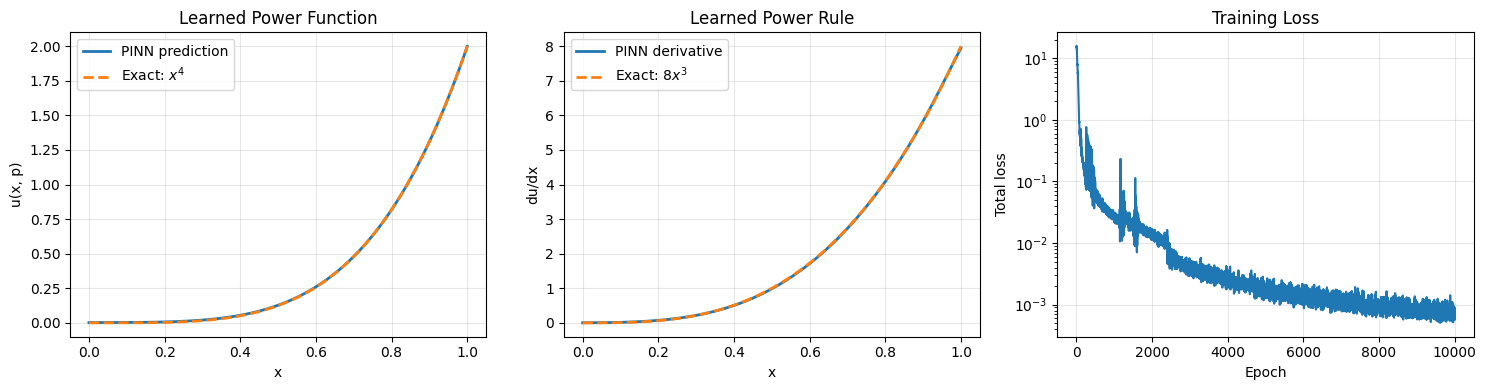


Test function:                   2x^4
Test coefficient:                2
Test power:                      4

Results at x = 1
Predicted function value:        1.9979286986e+00
True function value:             2.0000000000e+00
Predicted derivative:            7.9469999181e+00
True derivative:                 8.0000000000e+00

Function mean absolute error:    2.339193e-03
Derivative mean absolute error:  9.444366e-03


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_ORDER = 1.0
MAX_ORDER = 5.1

MIN_COEFFICIENT = -5.10
MAX_COEFFICIENT = 5.10

X_MIN = 0.0
X_MAX = 1.0

BATCH_SIZE = 10000
EPOCHS = 10000

X_SCALE = 100.0
POWER_SCALE = 10.0

# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, power]
#
# Output:
#   u(x, power)
# ------------------------------------------------------------

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            128,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            96,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            32,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])


model = build_model()

# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    power,
    coefficient,
    training=True
):
    """
    Predict u(x, power, coefficient) using the neural network.

    The network is intended to learn:

        u(x, power, coefficient)
            = coefficient * x**power
    """

    x = tf.cast(x, DTYPE)
    power = tf.cast(power, DTYPE)
    coefficient = tf.cast(
        coefficient,
        DTYPE
    )

    model_input = tf.concat(
        [
            x,
            power,
            coefficient
        ],
        axis=1
    )

    u = model(
        model_input,
        training=training
    )

    return u

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------

def generate_training_batch(batch_size):
    # Random x values
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    # Random continuous powers
    power = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_ORDER,
        maxval=MAX_ORDER,
        dtype=DTYPE
    )

    # Random scales
    coefficient = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_COEFFICIENT,
        maxval=MAX_COEFFICIENT,
        dtype=DTYPE
    )


    return x, power, coefficient


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, power, coefficient, training=True):
    x = tf.cast(x, DTYPE)
    power = tf.cast(power, DTYPE)
    coefficient = tf.cast(coefficient, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        model_input = tf.concat(
            [x, power, coefficient],
            axis=1
        )

        u = model(
            model_input,
            training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, power_physics, coefficient_physics = generate_training_batch(
        BATCH_SIZE
    )

    _, du_dx = calculate_du_dx(
        x_physics,
        power_physics,
        coefficient_physics,
        training=True
    )

    # Power rule:
    #
    # d/dx(ax^p) = p*ax^(p-1)
    exact_derivative = (
        coefficient_physics * power_physics
        * tf.pow(
            x_physics,
            power_physics - 1.0
        )
    )

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # x^p = 0 at x = 0 for p > 0
    # --------------------------------------------------------

    boundary_power = tf.random.uniform(
        shape=(BATCH_SIZE, 1),
        minval=MIN_ORDER,
        maxval=MAX_ORDER,
        dtype=DTYPE
    )

    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )

    x_boundary = tf.zeros(
        shape=(BATCH_SIZE, 1),
        dtype=DTYPE
    )

    boundary_input = tf.concat(
        [x_boundary, boundary_power, boundary_coefficient],
        axis=1
    )

    u_pred_boundary = model(
        boundary_input,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    # --------------------------------------
    #  Algebruh loss
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      power_physics,
      coefficient_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        power_physics,
        -coefficient_physics,
        training=True
    )

    # enfore the condition a + (-a) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # --------------------------------------------------------
    #  Enforce neighbor powers
    #
    # Power functions satisfy:
    #
    # u(x, q + 1, a) = x*u(x, q, a)
    #
    # For p <= MAX_ORDER - 1:
    #     q = p
    #     test p -> p + 1
    #
    # For p > MAX_ORDER - 1:
    #     q = p - 1
    #     test p - 1 -> p
    #
    # This keeps both powers inside the training range.
    # --------------------------------------------------------

    max_order_tensor = tf.cast(
        MAX_ORDER,
        DTYPE
    )

    one = tf.constant(
        1.0,
        dtype=DTYPE
    )

    lower_power = tf.where(
        power_physics <= (max_order_tensor - one),

        # Example: p = 3.2
        # Test 3.2 -> 4.2
        power_physics,

        # Example: p = 4.7
        # Test 3.7 -> 4.7
        power_physics - one
    )

    upper_power = lower_power + one

    u_lower_power = predict_u(
        x_physics,
        lower_power,
        coefficient_physics,
        training=True
    )

    u_upper_power = predict_u(
        x_physics,
        upper_power,
        coefficient_physics,
        training=True
    )

    expected_upper_power = (
        x_physics * u_lower_power
    )

    neighbor_power_residual = (
        u_upper_power - expected_upper_power
    )

    neighbor_power_loss = tf.reduce_mean(
        tf.square(neighbor_power_residual)
    )


    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.07 * neighbor_power_loss)

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(EPOCHS + 1):
    total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Algebra: {algebraic_loss.numpy():.6e} | "
            f"Neighbor Powers: {neighbor_power_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary power
# ------------------------------------------------------------

test_power = 4
test_a = 2

x_test = tf.linspace(
    tf.constant(0.0, dtype=DTYPE),
    tf.constant(1.0, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

power_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_power, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    power_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact power-rule results
u_exact = (
    test_a
    * x_numpy ** test_power
)

du_dx_exact = (
    test_a
    * test_power
    * x_numpy ** (test_power - 1.0)
)

du_dx_exact = (
    test_a* test_power
    * x_numpy ** (test_power - 1.0)
)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: $x^{{{test_power}}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, p)")
plt.title("Learned Power Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_power}"
      fr"x^{{{test_power - 1}}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Power Rule")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a}x^{test_power}")
print(f"Test coefficient:                {test_a}")
print(f"Test power:                      {test_power}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)


In [ ]:
import numpy as np
import tensorflow as tf


def test_random_inference(n_points=10_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, power, coefficient) triples uniformly over
    the configured training ranges. Returns (metrics, samples).
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    power = rng.uniform(MIN_ORDER, MAX_ORDER, (n_points, 1)).astype(dtype)
    coefficient = rng.uniform(
        MIN_COEFFICIENT, MAX_COEFFICIENT, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], power[start:stop], coefficient[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    u_exact = coefficient * np.power(x, power)
    du_dx_exact = coefficient * power * np.power(x, power - 1.0)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "power": power.ravel(),
        "coefficient": coefficient.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_inference()


Random inference points: 10,000 | Seed: 12345

Average function MAE           2.8309815898e-03
Average derivative MAE         1.0367296130e-02

Median function MAE            2.0779297485e-03
Median derivative MAE          6.3919357938e-03

Maximum function MAE           3.3162700988e-02
Maximum derivative MAE         9.7496644577e-01


In [ ]:
import numpy as np
import tensorflow as tf


def test_random_inference(n_points=100_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, power, coefficient) triples uniformly over
    the configured training ranges. Returns (metrics, samples).
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    power = rng.uniform(MIN_ORDER, MAX_ORDER, (n_points, 1)).astype(dtype)
    coefficient = rng.uniform(
        MIN_COEFFICIENT, MAX_COEFFICIENT, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], power[start:stop], coefficient[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    u_exact = coefficient * np.power(x, power)
    du_dx_exact = coefficient * power * np.power(x, power - 1.0)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "power": power.ravel(),
        "coefficient": coefficient.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_inference()


Random inference points: 100,000 | Seed: 12345

Average function MAE           3.2107263687e-03
Average derivative MAE         1.3322019283e-02

Median function MAE            2.4842337076e-03
Median derivative MAE          8.1429701178e-03

Maximum function MAE           3.8844182939e-02
Maximum derivative MAE         1.1613966270e+00


<h1> Valley Power Rule </h1>

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_256 (Valley)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_128 (Valley)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_96 (Valley)              │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_32 (Valley)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch:     0 | Total: 1.812317e+02 | Physics: 5.392593e+01 | Boundary: 9.429200e+01 | Algebra: 2.483193e+02 | Neighbor Powers: 2.819728e+01
Epoch:   500 | Total: 5.853554e-01 | Physics: 5.518267e-01 | Boundary: 1.138714e-02 | Algebra: 1.685846e-01 | Neighbor Powers: 1.526414e-02
Epoch:  1000 | Total: 7.453874e-01 | Physics: 7.293596e-01 | Boundary: 1.036747e-03 | Algebra: 1.175442e-01 | Neighbor Powers: 4.256702e-03
Epoch:  1500 | Total: 2.163679e-01 | Physics: 2.006778e-01 | Boundary: 1.052419e-02 | Algebra: 3.484599e-02 | Neighbor Powers: 1.157437e-02
Epoch:  2000 | Total: 8.251340e-02 | Physics: 8.215808e-02 | Boundary: 1.736579e-04 | Algebra: 1.077253e-03 | Neighbor Powers: 6.714692e-04
Epoch:  2500 | Total: 8.553341e-02 | Physics: 8.229454e-02 | Boundary: 1.261417e-03 | Algebra: 1.529589e-02 | Neighbor Powers: 9.353117e-04
Epoch:  3000 | Total: 2.839185e-02 | Physics: 2.756377e-02 | Boundary: 4.767345e-04 | Algebra: 2.651184e-03 | Neighbor Powers: 2.850139e-04
Epoch:  3500 | Total

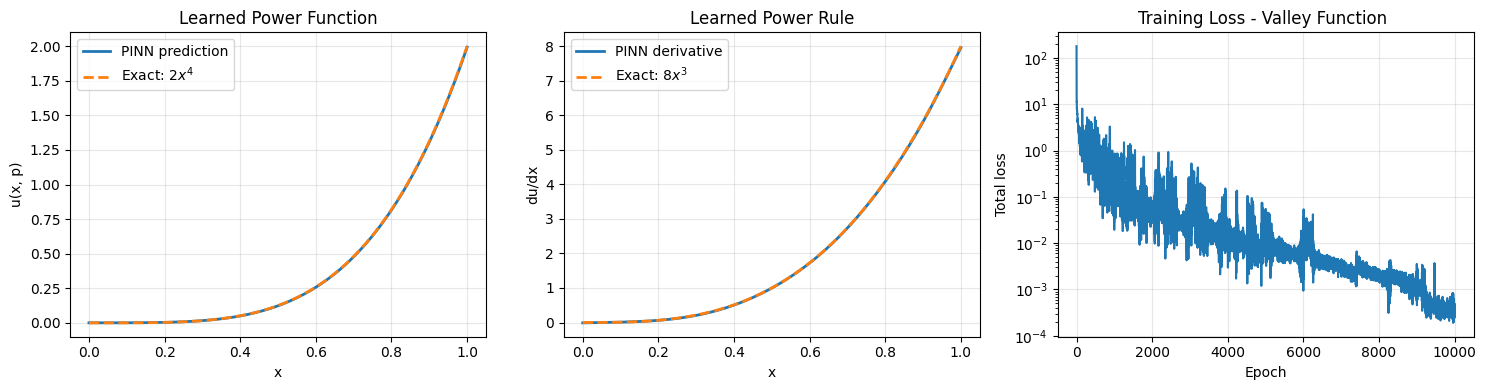


Test function:                   2x^4
Test coefficient:                2
Test power:                      4

Results at x = 1
Predicted function value:        1.9929375049e+00
True function value:             2.0000000000e+00
Predicted derivative:            7.9584510092e+00
True derivative:                 8.0000000000e+00

Function mean absolute error:    1.963946e-03
Derivative mean absolute error:  8.278582e-03


In [39]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_ORDER = 1.0
MAX_ORDER = 5.1

MIN_COEFFICIENT = -5.10
MAX_COEFFICIENT = 5.10

X_MIN = 0.0
X_MAX = 1.0

BATCH_SIZE = 10000
EPOCHS = 10000

X_SCALE = 100.0
POWER_SCALE = 10.0

# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, power, coefficient]
#
# Output:
#   u(x, power, coefficient)
# ------------------------------------------------------------

@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """Smooth, fixed activation: x**3 * tanh(x) * sech(x).

    The supplied ExpN call() does not use any of its declared parameters,
    so this layer intentionally has no trainable activation weights.
    Dense weights and biases remain trainable. Uses a stable sech identity
    to avoid cosh overflow and retain smooth higher-order autodiff.
    """

    def call(self, inputs):

        x = tf.convert_to_tensor(inputs)

        return 5 * (x**3 * tf.tanh(x) * tf.math.reciprocal(tf.math.cosh(x)))


    def get_config(self):
        return super().get_config()


def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE, name="valley_256"),

        tf.keras.layers.Dense(
            128,
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE, name="valley_128"),

        tf.keras.layers.Dense(
            96,
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE, name="valley_96"),

        tf.keras.layers.Dense(
            32,
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE, name="valley_32"),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])


model = build_model()
model.summary()

# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    power,
    coefficient,
    training=True
):
    """
    Predict u(x, power, coefficient) using the neural network.

    The network is intended to learn:

        u(x, power, coefficient)
            = coefficient * x**power
    """

    x = tf.cast(x, DTYPE)
    power = tf.cast(power, DTYPE)
    coefficient = tf.cast(
        coefficient,
        DTYPE
    )

    model_input = tf.concat(
        [
            x,
            power,
            coefficient
        ],
        axis=1
    )

    u = model(
        model_input,
        training=training
    )

    return u

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------

def generate_training_batch(batch_size):
    # Random x values
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    # Random continuous powers
    power = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_ORDER,
        maxval=MAX_ORDER,
        dtype=DTYPE
    )

    # Random scales
    coefficient = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_COEFFICIENT,
        maxval=MAX_COEFFICIENT,
        dtype=DTYPE
    )


    return x, power, coefficient


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, power, coefficient, training=True):
    x = tf.cast(x, DTYPE)
    power = tf.cast(power, DTYPE)
    coefficient = tf.cast(coefficient, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        model_input = tf.concat(
            [x, power, coefficient],
            axis=1
        )

        u = model(
            model_input,
            training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, power_physics, coefficient_physics = generate_training_batch(
        BATCH_SIZE
    )

    _, du_dx = calculate_du_dx(
        x_physics,
        power_physics,
        coefficient_physics,
        training=True
    )

    # Power rule:
    #
    # d/dx(ax^p) = p*ax^(p-1)
    exact_derivative = (
        coefficient_physics * power_physics
        * tf.pow(
            x_physics,
            power_physics - 1.0
        )
    )

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # x^p = 0 at x = 0 for p > 0
    # --------------------------------------------------------

    boundary_power = tf.random.uniform(
        shape=(BATCH_SIZE, 1),
        minval=MIN_ORDER,
        maxval=MAX_ORDER,
        dtype=DTYPE
    )

    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )

    x_boundary = tf.zeros(
        shape=(BATCH_SIZE, 1),
        dtype=DTYPE
    )

    boundary_input = tf.concat(
        [x_boundary, boundary_power, boundary_coefficient],
        axis=1
    )

    u_pred_boundary = model(
        boundary_input,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    # --------------------------------------
    #  Algebruh loss
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      power_physics,
      coefficient_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        power_physics,
        -coefficient_physics,
        training=True
    )

    # enfore the condition a + (-a) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # --------------------------------------------------------
    #  Enforce neighbor powers
    #
    # Power functions satisfy:
    #
    # u(x, q + 1, a) = x*u(x, q, a)
    #
    # For p <= MAX_ORDER - 1:
    #     q = p
    #     test p -> p + 1
    #
    # For p > MAX_ORDER - 1:
    #     q = p - 1
    #     test p - 1 -> p
    #
    # This keeps both powers inside the training range.
    # --------------------------------------------------------

    max_order_tensor = tf.cast(
        MAX_ORDER,
        DTYPE
    )

    one = tf.constant(
        1.0,
        dtype=DTYPE
    )

    lower_power = tf.where(
        power_physics <= (max_order_tensor - one),

        # Example: p = 3.2
        # Test 3.2 -> 4.2
        power_physics,

        # Example: p = 4.7
        # Test 3.7 -> 4.7
        power_physics - one
    )

    upper_power = lower_power + one

    u_lower_power = predict_u(
        x_physics,
        lower_power,
        coefficient_physics,
        training=True
    )

    u_upper_power = predict_u(
        x_physics,
        upper_power,
        coefficient_physics,
        training=True
    )

    expected_upper_power = (
        x_physics * u_lower_power
    )

    neighbor_power_residual = (
        u_upper_power - expected_upper_power
    )

    neighbor_power_loss = tf.reduce_mean(
        tf.square(neighbor_power_residual)
    )


    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.07 * neighbor_power_loss)

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(EPOCHS + 1):
    total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_power_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Algebra: {algebraic_loss.numpy():.6e} | "
            f"Neighbor Powers: {neighbor_power_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary power
# ------------------------------------------------------------

test_power = 4
test_a = 2

x_test = tf.linspace(
    tf.constant(0.0, dtype=DTYPE),
    tf.constant(1.0, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

power_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_power, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    power_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact power-rule results
u_exact = (
    test_a
    * x_numpy ** test_power
)

du_dx_exact = (
    test_a
    * test_power
    * x_numpy ** (test_power - 1.0)
)



# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: ${test_a}x^{{{test_power}}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, p)")
plt.title("Learned Power Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_power}"
      fr"x^{{{test_power - 1}}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Power Rule")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss - Valley Function ")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a}x^{test_power}")
print(f"Test coefficient:                {test_a}")
print(f"Test power:                      {test_power}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)

model.save("power_rule_valley_pinn.keras")

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


In [40]:
import numpy as np
import tensorflow as tf


def test_random_inference(n_points=100_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, power, coefficient) triples uniformly over
    the configured training ranges. Returns (metrics, samples).
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    power = rng.uniform(MIN_ORDER, MAX_ORDER, (n_points, 1)).astype(dtype)
    coefficient = rng.uniform(
        MIN_COEFFICIENT, MAX_COEFFICIENT, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], power[start:stop], coefficient[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    u_exact = coefficient * np.power(x, power)
    du_dx_exact = coefficient * power * np.power(x, power - 1.0)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "power": power.ravel(),
        "coefficient": coefficient.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_inference()


Random inference points: 100,000 | Seed: 12345

Average function MAE           2.6633195503e-03
Average derivative MAE         1.0940785731e-02

Median function MAE            1.9271827694e-03
Median derivative MAE          7.0532367992e-03

Maximum function MAE           5.0065739276e-02
Maximum derivative MAE         8.8207178285e-01


<h1> Power Rule Inference</h1>

<h1> Base Sine </h1>

Epoch:     0 | Total: 1.998377e+01 | Physics: 1.620452e+01 | Boundary: 2.973734e+00
Epoch:   500 | Total: 4.165708e-01 | Physics: 3.545287e-01 | Boundary: 1.042560e-02
Epoch:  1000 | Total: 1.974284e-01 | Physics: 1.746737e-01 | Boundary: 7.998674e-03
Epoch:  1500 | Total: 1.496216e-01 | Physics: 1.258493e-01 | Boundary: 2.260584e-03
Epoch:  2000 | Total: 9.485490e-02 | Physics: 7.538922e-02 | Boundary: 3.012583e-03
Epoch:  2500 | Total: 1.392756e-01 | Physics: 8.781487e-02 | Boundary: 2.323083e-02
Epoch:  3000 | Total: 4.558046e-02 | Physics: 3.696139e-02 | Boundary: 5.010880e-04
Epoch:  3500 | Total: 3.618036e-02 | Physics: 2.393805e-02 | Boundary: 6.418632e-03
Epoch:  4000 | Total: 3.476986e-02 | Physics: 2.679761e-02 | Boundary: 3.293227e-04
Epoch:  4500 | Total: 2.000002e-02 | Physics: 1.254498e-02 | Boundary: 4.524743e-03
Epoch:  5000 | Total: 1.172732e-02 | Physics: 9.782372e-03 | Boundary: 3.051592e-04
Epoch:  5500 | Total: 1.050412e-02 | Physics: 8.403095e-03 | Boundary: 7.256

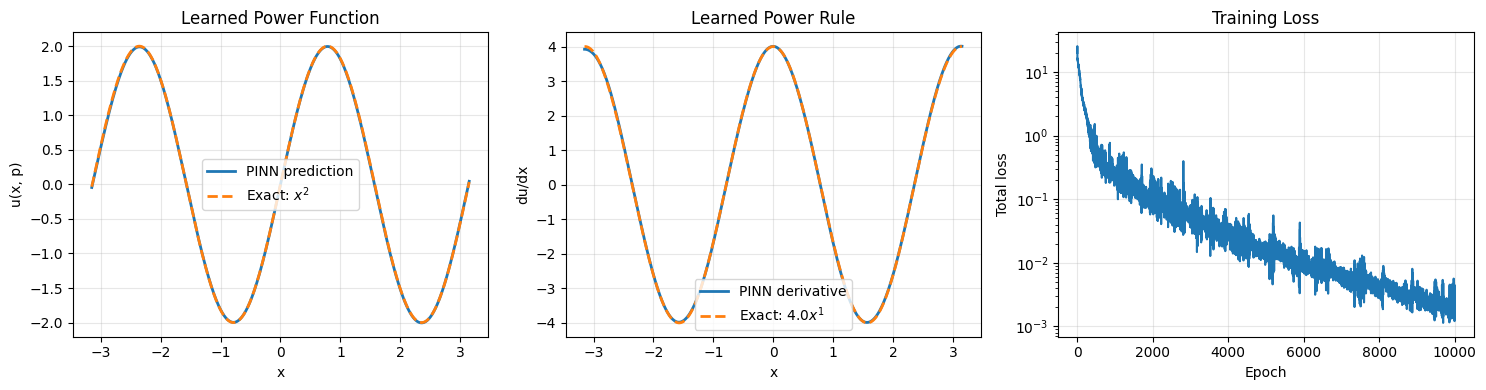


Test function:                   2.0x^2
Test amplitude:                2.0
Test frequency:                      2

Results at x = 1
Predicted function value:        4.4310236862e-02
True function value:             3.3627800969e-02
Predicted derivative:            4.0092331633e+00
True derivative:                 3.9994345455e+00

Function mean absolute error:    7.272832e-03
Derivative mean absolute error:  1.556961e-02


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 64)             │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,665 (419.26 KB)

 Trainable params: 53,665 (419.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_ORDER = 1.0
MAX_ORDER = 5.1

MIN_AMPLITUDE = -5.10
MAX_AMPLITUDE = 5.10

MIN_FREQUENCY = 0.5
MAX_FREQUENCY = 3.0

X_MIN = -3.16
X_MAX = 3.16

BATCH_SIZE = 10000
EPOCHS = 10000

X_SCALE = 100.0
POWER_SCALE = 10.0

# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, power]
#
# Output:
#   u(x, power)
# ------------------------------------------------------------

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            128,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            96,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            64,
            activation="swish",
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])


model = build_model()

# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    amplitude,
    frequency,
    training=True
):
    model_input = tf.concat(
        [
            tf.cast(x, DTYPE),
            tf.cast(amplitude, DTYPE),
            tf.cast(frequency, DTYPE)
        ],
        axis=1
    )

    return model(
        model_input,
        training=training
    )

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------


def generate_training_batch(batch_size):
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    amplitude = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_AMPLITUDE,
        maxval=MAX_AMPLITUDE,
        dtype=DTYPE
    )

    frequency = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_FREQUENCY,
        maxval=MAX_FREQUENCY,
        dtype=DTYPE
    )

    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    amplitude = tf.cast(amplitude, DTYPE)
    frequency = tf.cast(frequency, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        u = predict_u(
            x, amplitude, frequency, training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, amplitude_physics, frequency_physics = (
      generate_training_batch(BATCH_SIZE)
    )


    u_pred, du_dx = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    # Sine derivative:
    #
    # d/dx sin(x) = tan(x)
    exact_derivative = amplitude_physics * frequency_physics * tf.cos(frequency_physics * x_physics)

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # u(0) = 0
    # --------------------------------------------------------
    '''
    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )
    '''
    x_boundary = tf.zeros_like(x_physics)

    u_pred_boundary = predict_u(
        x_boundary,
        amplitude_physics,
        frequency_physics,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    # --------------------------------------
    #  Algebruh loss
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        -amplitude_physics,
        frequency_physics,
        training=True
    )

    # enfore the condition a + (-a) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # ----------------------------------------
    #   Even function test
    #   cos(-x) = cos(x)
    # ----------------------------------------

    _, du_dx_positive = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    _, du_dx_negative = calculate_du_dx(
      -x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    cosine_even_residual = (
        du_dx_positive - du_dx_negative
    )

    cosine_even_loss = tf.reduce_mean(
        tf.square(cosine_even_residual)
    )

    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.10 * cosine_even_loss)

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(EPOCHS + 1):
    total_loss, physics_loss, boundary_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary power
# ------------------------------------------------------------

test_power = 2
test_a = 2

x_test = tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

power_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_power, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    power_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact power-rule results
# Exact scaled-sine results:
#
# u(x)  = A*sin(b*x)
# u'(x) = A*b*cos(b*x)

test_a = 2.0  # Amplitude
test_b = 2.0  # Frequency

u_exact = (
    test_a
    * np.sin(test_b * x_numpy)
)

du_dx_exact = (
    test_a
    * test_b
    * np.cos(test_b * x_numpy)
)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: $x^{{{test_power}}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, p)")
plt.title("Learned Power Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_power}"
      fr"x^{{{test_power - 1}}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Power Rule")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a}x^{test_power}")
print(f"Test amplitude:                {test_a}")
print(f"Test frequency:                      {test_power}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)
model.summary()
model.save("best_1000_sine.keras")

import numpy as np
import tensorflow as tf


In [ ]:
import numpy as np
import tensorflow as tf


def test_random_sine_inference(n_points=100_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, amplitude, frequency) triples uniformly over
    the configured sine training ranges. Returns (metrics, samples).
    Uses the existing calculate_du_dx(x, amplitude, frequency) helper.
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    amplitude = rng.uniform(
        MIN_AMPLITUDE, MAX_AMPLITUDE, (n_points, 1)
    ).astype(dtype)
    frequency = rng.uniform(
        MIN_FREQUENCY, MAX_FREQUENCY, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], amplitude[start:stop], frequency[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # u(x, A, b) = A*sin(b*x); du/dx = A*b*cos(b*x).
    u_exact = amplitude * np.sin(frequency * x)
    du_dx_exact = amplitude * frequency * np.cos(frequency * x)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_sine_inference()


Random inference points: 100,000 | Seed: 12345

Average function MAE           1.7189871874e-02
Average derivative MAE         2.7710486025e-02

Median function MAE            1.1707503865e-02
Median derivative MAE          1.8332687480e-02

Maximum function MAE           2.4792068689e-01
Maximum derivative MAE         1.7923213691e+00


In [ ]:

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.set_floatx("float64")
DTYPE = tf.float64

MODEL_PATH = "/content/best_1000_sine.keras"

TRAINING_X_MIN = -3.16
TRAINING_X_MAX = 3.16

TRAINING_AMPLITUDE_MIN = -5.10
TRAINING_AMPLITUDE_MAX = 5.10

TRAINING_FREQUENCY_MIN = 0.50
TRAINING_FREQUENCY_MAX = 3.00


# ------------------------------------------------------------
# 2. Load trained model
# ------------------------------------------------------------

sine_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)


# ------------------------------------------------------------
# 3. Input preparation
# ------------------------------------------------------------

def prepare_inputs(x, amplitude, frequency):
    """
    Converts scalar or array inputs into matching column tensors.

    Scalars are automatically broadcast to match array inputs.
    """

    x = np.asarray(x, dtype=np.float64)
    amplitude = np.asarray(amplitude, dtype=np.float64)
    frequency = np.asarray(frequency, dtype=np.float64)

    # Make all three inputs have the same shape
    x, amplitude, frequency = np.broadcast_arrays(
        x,
        amplitude,
        frequency
    )

    original_shape = x.shape

    x_tensor = tf.convert_to_tensor(
        x.reshape(-1, 1),
        dtype=DTYPE
    )

    amplitude_tensor = tf.convert_to_tensor(
        amplitude.reshape(-1, 1),
        dtype=DTYPE
    )

    frequency_tensor = tf.convert_to_tensor(
        frequency.reshape(-1, 1),
        dtype=DTYPE
    )

    return (
        x_tensor,
        amplitude_tensor,
        frequency_tensor,
        original_shape
    )


# ------------------------------------------------------------
# 4. Prediction engine
# ------------------------------------------------------------

def predict_sine(
    x,
    amplitude,
    frequency,
    compare_exact=True,
    warn_outside_training=True
):
    """
    Predicts:

        u(x)    = A*sin(b*x)
        du/dx   = A*b*cos(b*x)

    Parameters
    ----------
    x:
        Scalar, list, or NumPy array of x-values.

    amplitude:
        Scalar, list, or NumPy array of amplitudes.

    frequency:
        Scalar, list, or NumPy array of frequencies.

    compare_exact:
        If True, calculate the analytical values and errors.

    warn_outside_training:
        If True, display warnings for extrapolation.

    Returns
    -------
    Dictionary containing predicted function and derivative values.
    """

    (
        x_tensor,
        amplitude_tensor,
        frequency_tensor,
        original_shape
    ) = prepare_inputs(
        x,
        amplitude,
        frequency
    )

    # Warn when asking the model to extrapolate
    if warn_outside_training:
        if (
            np.any(x_tensor.numpy() < TRAINING_X_MIN)
            or np.any(x_tensor.numpy() > TRAINING_X_MAX)
        ):
            print(
                "Warning: One or more x-values are outside "
                "the model's training range."
            )

        if (
            np.any(
                amplitude_tensor.numpy()
                < TRAINING_AMPLITUDE_MIN
            )
            or np.any(
                amplitude_tensor.numpy()
                > TRAINING_AMPLITUDE_MAX
            )
        ):
            print(
                "Warning: One or more amplitudes are outside "
                "the model's training range."
            )

        if (
            np.any(
                frequency_tensor.numpy()
                < TRAINING_FREQUENCY_MIN
            )
            or np.any(
                frequency_tensor.numpy()
                > TRAINING_FREQUENCY_MAX
            )
        ):
            print(
                "Warning: One or more frequencies are outside "
                "the model's training range."
            )

    # Automatic differentiation with respect to x
    with tf.GradientTape() as tape:
        tape.watch(x_tensor)

        model_input = tf.concat(
            [
                x_tensor,
                amplitude_tensor,
                frequency_tensor
            ],
            axis=1
        )

        u_pred = sine_model(
            model_input,
            training=False
        )

    du_dx_pred = tape.gradient(
        u_pred,
        x_tensor
    )

    # Restore the original input shape
    x_numpy = x_tensor.numpy().reshape(original_shape)
    amplitude_numpy = (
        amplitude_tensor.numpy().reshape(original_shape)
    )
    frequency_numpy = (
        frequency_tensor.numpy().reshape(original_shape)
    )

    u_pred_numpy = (
        u_pred.numpy().reshape(original_shape)
    )

    du_dx_pred_numpy = (
        du_dx_pred.numpy().reshape(original_shape)
    )

    results = {
        "x": x_numpy,
        "amplitude": amplitude_numpy,
        "frequency": frequency_numpy,
        "predicted_u": u_pred_numpy,
        "predicted_du_dx": du_dx_pred_numpy
    }

    if compare_exact:
        exact_u = (
            amplitude_numpy
            * np.sin(frequency_numpy * x_numpy)
        )

        exact_du_dx = (
            amplitude_numpy
            * frequency_numpy
            * np.cos(frequency_numpy * x_numpy)
        )

        results.update({
            "exact_u": exact_u,
            "exact_du_dx": exact_du_dx,
            "u_absolute_error": np.abs(
                u_pred_numpy - exact_u
            ),
            "du_dx_absolute_error": np.abs(
                du_dx_pred_numpy - exact_du_dx
            )
        })

    return results


# ------------------------------------------------------------
# 5. Convenient single-point inference
# ------------------------------------------------------------

def predict_sine_point(
    x,
    amplitude,
    frequency,
    print_results=True
):
    """
    Runs inference for one specific sine function and x-value.
    """

    results = predict_sine(
        x=x,
        amplitude=amplitude,
        frequency=frequency,
        compare_exact=True
    )

    output = {
        key: float(np.asarray(value))
        for key, value in results.items()
    }

    if print_results:
        print()
        print(
            f"Function: {amplitude} * sin({frequency}x)"
        )
        print(f"x:                         {x:.8f}")
        print()
        print(
            f"Predicted u(x):             "
            f"{output['predicted_u']:.10e}"
        )
        print(
            f"Exact u(x):                 "
            f"{output['exact_u']:.10e}"
        )
        print(
            f"Function absolute error:    "
            f"{output['u_absolute_error']:.10e}"
        )
        print()
        print(
            f"Predicted du/dx:            "
            f"{output['predicted_du_dx']:.10e}"
        )
        print(
            f"Exact du/dx:                "
            f"{output['exact_du_dx']:.10e}"
        )
        print(
            f"Derivative absolute error:  "
            f"{output['du_dx_absolute_error']:.10e}"
        )

    return output

import numpy as np

# ------------------------------------------------------------
# Evaluate 100 amplitude-frequency combinations
# ------------------------------------------------------------

x_values = np.linspace(
    -3.15,
    3.15,
    10000
)

# 10 amplitudes × 10 frequencies = 100 combinations
test_amplitudes = np.linspace(
    TRAINING_AMPLITUDE_MIN,
    TRAINING_AMPLITUDE_MAX,
    100
)

test_frequencies = np.linspace(
    TRAINING_FREQUENCY_MIN,
    TRAINING_FREQUENCY_MAX,
    100
)

function_mae_values = []
derivative_mae_values = []
combination_results = []

for amplitude in test_amplitudes:
    for frequency in test_frequencies:
        results = predict_sine(
            x=x_values,
            amplitude=amplitude,
            frequency=frequency,
            compare_exact=True,
            warn_outside_training=False
        )

        function_mae = np.mean(
            results["u_absolute_error"]
        )

        derivative_mae = np.mean(
            results["du_dx_absolute_error"]
        )

        function_mae_values.append(function_mae)
        derivative_mae_values.append(derivative_mae)

        combination_results.append({
            "amplitude": amplitude,
            "frequency": frequency,
            "function_mae": function_mae,
            "derivative_mae": derivative_mae
        })


# ------------------------------------------------------------
# Aggregate results
# ------------------------------------------------------------

average_function_mae = np.mean(
    function_mae_values
)

average_derivative_mae = np.mean(
    derivative_mae_values
)

median_function_mae = np.median(
    function_mae_values
)

median_derivative_mae = np.median(
    derivative_mae_values
)

maximum_function_mae = np.max(
    function_mae_values
)

maximum_derivative_mae = np.max(
    derivative_mae_values
)


print("Results across 100 parameter combinations")
print("-----------------------------------------")
print(
    f"Average function MAE:     "
    f"{average_function_mae:.10e}"
)
print(
    f"Average derivative MAE:   "
    f"{average_derivative_mae:.10e}"
)
print()
print(
    f"Median function MAE:      "
    f"{median_function_mae:.10e}"
)
print(
    f"Median derivative MAE:    "
    f"{median_derivative_mae:.10e}"
)
print()
print(
    f"Maximum function MAE:     "
    f"{maximum_function_mae:.10e}"
)
print(
    f"Maximum derivative MAE:   "
    f"{maximum_derivative_mae:.10e}"
)
#Median function MAE            4.8003480763e-03
#Median derivative MAE          9.0655951417e-03

Results across 100 parameter combinations
-----------------------------------------
Average function MAE:     1.3293832147e-02
Average derivative MAE:   1.7942900241e-02

Median function MAE:      1.0244125239e-02
Median derivative MAE:    1.5830169986e-02

Maximum function MAE:     1.3071640622e-01
Maximum derivative MAE:   1.9182327007e-01


<h1> Valley Sine </h1>

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch:     0 | Total: 1.693819e+01 | Physics: 1.565591e+01 | Boundary: 1.007838e+00
Epoch:   500 | Total: 9.841935e-02 | Physics: 7.425732e-02 | Boundary: 7.209403e-03
Epoch:  1000 | Total: 1.160890e-01 | Physics: 6.248727e-02 | Boundary: 3.085017e-02
Epoch:  1500 | Total: 4.947194e-02 | Physics: 3.125866e-02 | Boundary: 7.160102e-03
Epoch:  2000 | Total: 3.002949e-02 | Physics: 2.082269e-02 | Boundary: 4.277087e-03
Epoch:  2500 | Total: 2.634225e-02 | Physics: 1.973890e-02 | Boundary: 2.208213e-04
Epoch:  3000 | Total: 1.572234e-02 | Physics: 1.354054e-02 | Boundary: 4.040378e-04
Epoch:  3500 | Total: 1.061945e-02 | Physics: 7.846968e-03 | Boundary: 1.933824e-04
Epoch:  4000 | Total: 1.089616e-02 | Physics: 8.817696e-03 | Boundary: 4.110870e-04
Epoch:  4500 | Total: 6.925295e-03 | Physics: 5.622167e-03 | Boundary: 1.080379e-04
Epoch:  5000 | Total: 6.464270e-03 | Physics: 4.462931e-03 | Boundary: 7.098045e-04
Epoch:  5500 | Total: 6.080108e-03 | Physics: 3.918242e-03 | Boundary: 8.572

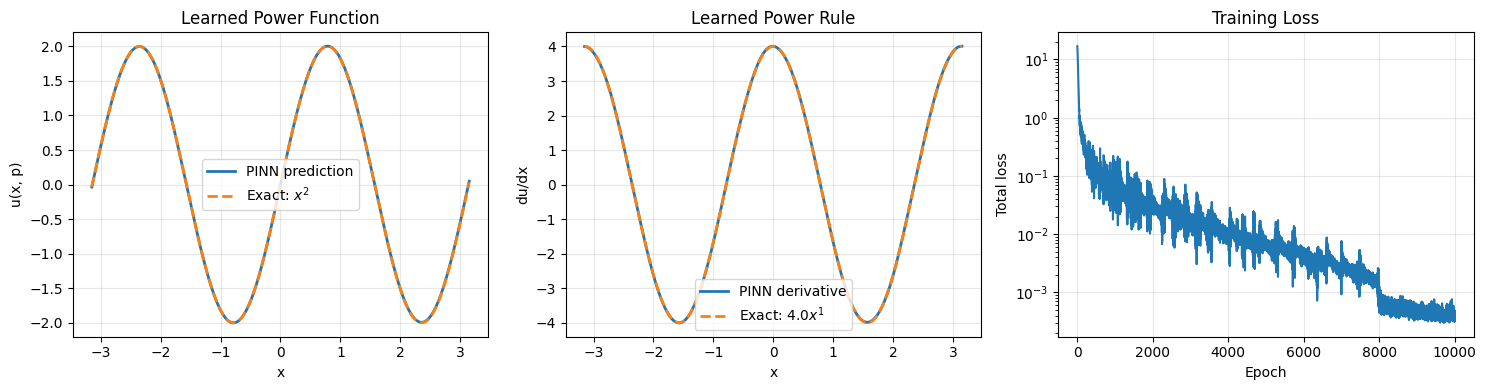


Test function:                   2.0x^2
Test amplitude:                2.0
Test frequency:                      2

Results at x = 1
Predicted function value:        4.8158084524e-02
True function value:             3.3627800969e-02
Predicted derivative:            4.0081747295e+00
True derivative:                 3.9994345455e+00

Function mean absolute error:    3.630491e-03
Derivative mean absolute error:  8.864900e-03


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_ORDER = 1.0
MAX_ORDER = 5.1

MIN_AMPLITUDE = -5.10
MAX_AMPLITUDE = 5.10

MIN_FREQUENCY = 0.5
MAX_FREQUENCY = 3.0

X_MIN = -3.16
X_MAX = 3.16

BATCH_SIZE = 10000
EPOCHS = 10000

X_SCALE = 100.0
POWER_SCALE = 10.0
'''

@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """Smooth, fixed activation: x**3 * tanh(x) * sech(x).

    The supplied ExpN call() does not use any of its declared parameters,
    so this layer intentionally has no trainable activation weights.
    Dense weights and biases remain trainable. Uses a stable sech identity
    to avoid cosh overflow and retain smooth higher-order autodiff.
    """

    def call(self, inputs):

        x = tf.convert_to_tensor(inputs)

        return (x**3 * tf.tanh(x) * tf.math.reciprocal(tf.math.cosh(x+0.001)))


    def get_config(self):
        return super().get_config()


def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_256"),

        tf.keras.layers.Dense(
            128,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_128"),

        tf.keras.layers.Dense(
            96,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_96"),

        tf.keras.layers.Dense(
            32,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_32"),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])
'''
@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return x**3 * tf.tanh(x) * sech_x

    def get_config(self):
        return super().get_config()


def build_model():
    dtype = tf.float64
    layers = [tf.keras.layers.Input(shape=(3,), dtype=dtype)]

    for index, units in enumerate((256, 128, 96, 32), start=1):
        layers.extend([
            tf.keras.layers.Dense(
                units,
                kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
                ),
                dtype=dtype,
                name=f"dense_{index}",
            ),
            # Normalize over hidden features separately for each sample.
            # Unlike batch normalization, this does not couple samples.
            tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=dtype,
                name=f"layer_norm_{index}",
            ),
            Valley(dtype=dtype, name=f"valley_{index}"),
        ])

    layers.append(tf.keras.layers.Dense(1, dtype=dtype, name="output"))
    return tf.keras.Sequential(layers)


model = build_model()
model.summary()
# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, power]
#
# Output:
#   u(x, power)
# ------------------------------------------------------------


# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    amplitude,
    frequency,
    training=True
):
    model_input = tf.concat(
        [
            tf.cast(x, DTYPE),
            tf.cast(amplitude, DTYPE),
            tf.cast(frequency, DTYPE)
        ],
        axis=1
    )

    return model(
        model_input,
        training=training
    )

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------


def generate_training_batch(batch_size):
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    amplitude = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_AMPLITUDE,
        maxval=MAX_AMPLITUDE,
        dtype=DTYPE
    )

    frequency = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_FREQUENCY,
        maxval=MAX_FREQUENCY,
        dtype=DTYPE
    )

    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    amplitude = tf.cast(amplitude, DTYPE)
    frequency = tf.cast(frequency, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        u = predict_u(
            x, amplitude, frequency, training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, amplitude_physics, frequency_physics = (
      generate_training_batch(BATCH_SIZE)
    )


    u_pred, du_dx = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    # Sine derivative:
    #
    # d/dx sin(x) = tan(x)
    exact_derivative = amplitude_physics * frequency_physics * tf.cos(frequency_physics * x_physics)

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # u(0) = 0
    # --------------------------------------------------------
    '''
    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )
    '''
    x_boundary = tf.zeros_like(x_physics)

    u_pred_boundary = predict_u(
        x_boundary,
        amplitude_physics,
        frequency_physics,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    # --------------------------------------
    #  Algebruh loss
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        -amplitude_physics,
        frequency_physics,
        training=True
    )

    # enfore the condition a + (-a) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # ----------------------------------------
    #   Even function test
    #   cos(-x) = cos(x)
    # ----------------------------------------

    _, du_dx_positive = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    _, du_dx_negative = calculate_du_dx(
      -x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    cosine_even_residual = (
        du_dx_positive - du_dx_negative
    )

    cosine_even_loss = tf.reduce_mean(
        tf.square(cosine_even_residual)
    )

    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.10 * cosine_even_loss)

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(EPOCHS + 1):
    total_loss, physics_loss, boundary_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary power
# ------------------------------------------------------------

test_power = 2
test_a = 2

x_test = tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

power_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_power, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    power_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact power-rule results
# Exact scaled-sine results:
#
# u(x)  = A*sin(b*x)
# u'(x) = A*b*cos(b*x)

test_a = 2.0  # Amplitude
test_b = 2.0  # Frequency

u_exact = (
    test_a
    * np.sin(test_b * x_numpy)
)

du_dx_exact = (
    test_a
    * test_b
    * np.cos(test_b * x_numpy)
)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: $x^{{{test_power}}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, p)")
plt.title("Learned Power Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_power}"
      fr"x^{{{test_power - 1}}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Power Rule")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a}x^{test_power}")
print(f"Test amplitude:                {test_a}")
print(f"Test frequency:                      {test_power}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)
model.summary()
model.save("best_1000_sine.keras")

import numpy as np
import tensorflow as tf
#

In [ ]:
import numpy as np
import tensorflow as tf


def test_random_sine_inference(n_points=100_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, amplitude, frequency) triples uniformly over
    the configured sine training ranges. Returns (metrics, samples).
    Uses the existing calculate_du_dx(x, amplitude, frequency) helper.
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    amplitude = rng.uniform(
        MIN_AMPLITUDE, MAX_AMPLITUDE, (n_points, 1)
    ).astype(dtype)
    frequency = rng.uniform(
        MIN_FREQUENCY, MAX_FREQUENCY, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], amplitude[start:stop], frequency[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # u(x, A, b) = A*sin(b*x); du/dx = A*b*cos(b*x).
    u_exact = amplitude * np.sin(frequency * x)
    du_dx_exact = amplitude * frequency * np.cos(frequency * x)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_sine_inference()


Random inference points: 100,000 | Seed: 12345

Average function MAE           7.1839311002e-03
Average derivative MAE         1.1678203284e-02

Median function MAE            4.9088773838e-03
Median derivative MAE          8.9808475488e-03

Maximum function MAE           1.3845853615e-01
Maximum derivative MAE         1.2025930443e+00


<h1> Higher Power Sine </h1>

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch:     0 | Total: 2.135807e+01 | Physics: 1.753511e+01 | Boundary: 2.344372e+00
Epoch:   500 | Total: 5.767098e-02 | Physics: 4.285966e-02 | Boundary: 7.073752e-03
Epoch:  1000 | Total: 6.444899e-02 | Physics: 4.973774e-02 | Boundary: 5.288614e-03
Epoch:  1500 | Total: 3.781705e-02 | Physics: 3.042086e-02 | Boundary: 4.204482e-03
Epoch:  2000 | Total: 4.257465e-02 | Physics: 2.373387e-02 | Boundary: 8.417911e-03
Epoch:  2500 | Total: 2.313766e-02 | Physics: 2.064004e-02 | Boundary: 1.019514e-04
Epoch:  3000 | Total: 2.344999e-02 | Physics: 1.528281e-02 | Boundary: 2.120100e-03
Epoch:  3500 | Total: 1.317319e-02 | Physics: 1.044474e-02 | Boundary: 1.673474e-03
Epoch:  4000 | Total: 8.518100e-03 | Physics: 7.088739e-03 | Boundary: 1.286223e-04
Epoch:  4500 | Total: 6.926342e-03 | Physics: 4.247175e-03 | Boundary: 1.061313e-03
Epoch:  5000 | Total: 6.919119e-03 | Physics: 3.810139e-03 | Boundary: 2.127220e-03
Epoch:  5500 | Total: 5.330667e-03 | Physics: 3.992403e-03 | Boundary: 1.500

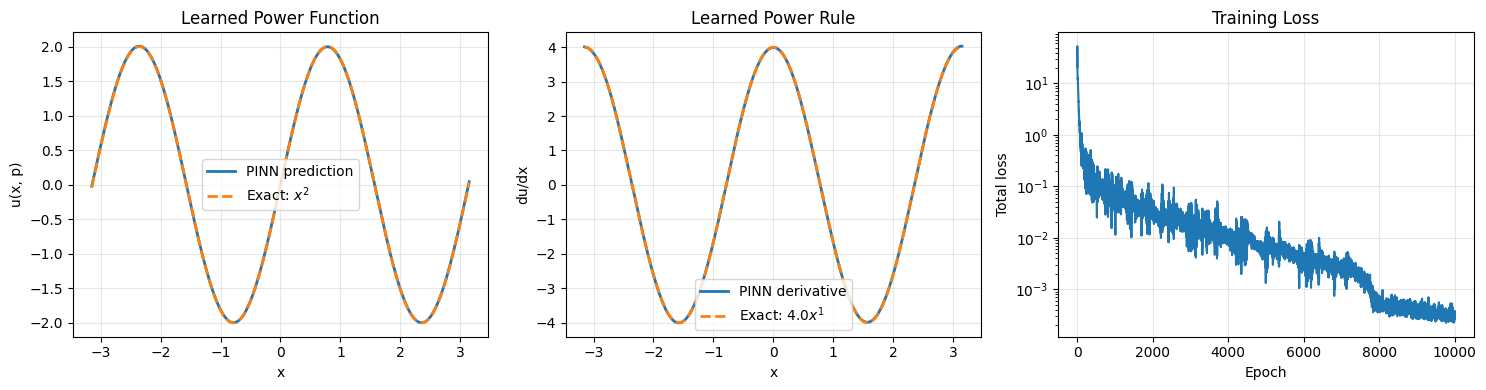


Test function:                   2.0x^2
Test amplitude:                2.0
Test frequency:                      2

Results at x = 1
Predicted function value:        4.4257872133e-02
True function value:             3.3627800969e-02
Predicted derivative:            4.0295602426e+00
True derivative:                 3.9994345455e+00

Function mean absolute error:    4.447435e-03
Derivative mean absolute error:  7.483516e-03


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_ORDER = 1.0
MAX_ORDER = 5.1

MIN_AMPLITUDE = -5.10
MAX_AMPLITUDE = 5.10

MIN_FREQUENCY = 0.5
MAX_FREQUENCY = 3.0

X_MIN = -3.16
X_MAX = 3.16

BATCH_SIZE = 10000
EPOCHS = 10000

X_SCALE = 100.0
POWER_SCALE = 10.0
'''

@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """Smooth, fixed activation: x**3 * tanh(x) * sech(x).

    The supplied ExpN call() does not use any of its declared parameters,
    so this layer intentionally has no trainable activation weights.
    Dense weights and biases remain trainable. Uses a stable sech identity
    to avoid cosh overflow and retain smooth higher-order autodiff.
    """

    def call(self, inputs):

        x = tf.convert_to_tensor(inputs)

        return (x**3 * tf.tanh(x) * tf.math.reciprocal(tf.math.cosh(x+0.001)))


    def get_config(self):
        return super().get_config()


def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_256"),

        tf.keras.layers.Dense(
            128,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_128"),

        tf.keras.layers.Dense(
            96,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_96"),

        tf.keras.layers.Dense(
            32,
            dtype=DTYPE
        ),
        Valley(dtype=DTYPE, name="valley_32"),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])
'''
@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return 5 * (x**3 * tf.tanh(x) * sech_x)

    def get_config(self):
        return super().get_config()


def build_model():
    dtype = tf.float64
    layers = [tf.keras.layers.Input(shape=(3,), dtype=dtype)]

    for index, units in enumerate((256, 128, 96, 32), start=1):
        layers.extend([
            tf.keras.layers.Dense(
                units,
                kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
                ),
                dtype=dtype,
                name=f"dense_{index}",
            ),
            # Normalize over hidden features separately for each sample.
            # Unlike batch normalization, this does not couple samples.
            tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=dtype,
                name=f"layer_norm_{index}",
            ),
            Valley(dtype=dtype, name=f"valley_{index}"),
        ])

    layers.append(tf.keras.layers.Dense(1, dtype=dtype, name="output"))
    return tf.keras.Sequential(layers)


model = build_model()
model.summary()
# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, power]
#
# Output:
#   u(x, power)
# ------------------------------------------------------------


# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    amplitude,
    frequency,
    training=True
):
    model_input = tf.concat(
        [
            tf.cast(x, DTYPE),
            tf.cast(amplitude, DTYPE),
            tf.cast(frequency, DTYPE)
        ],
        axis=1
    )

    return model(
        model_input,
        training=training
    )

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------


def generate_training_batch(batch_size):
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    amplitude = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_AMPLITUDE,
        maxval=MAX_AMPLITUDE,
        dtype=DTYPE
    )

    frequency = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_FREQUENCY,
        maxval=MAX_FREQUENCY,
        dtype=DTYPE
    )

    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    amplitude = tf.cast(amplitude, DTYPE)
    frequency = tf.cast(frequency, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        u = predict_u(
            x, amplitude, frequency, training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, amplitude_physics, frequency_physics = (
      generate_training_batch(BATCH_SIZE)
    )


    u_pred, du_dx = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    # Sine derivative:
    #
    # d/dx sin(x) = tan(x)
    exact_derivative = amplitude_physics * frequency_physics * tf.cos(frequency_physics * x_physics)

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # u(0) = 0
    # --------------------------------------------------------
    '''
    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )
    '''
    x_boundary = tf.zeros_like(x_physics)

    u_pred_boundary = predict_u(
        x_boundary,
        amplitude_physics,
        frequency_physics,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary)
    )

    # --------------------------------------
    #  Algebruh loss
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        -amplitude_physics,
        frequency_physics,
        training=True
    )

    # enfore the condition a + (-a) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # ----------------------------------------
    #   Even function test
    #   cos(-x) = cos(x)
    # ----------------------------------------

    _, du_dx_positive = calculate_du_dx(
      x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    _, du_dx_negative = calculate_du_dx(
      -x_physics,
      amplitude_physics,
      frequency_physics,
      training=True
    )

    cosine_even_residual = (
        du_dx_positive - du_dx_negative
    )

    cosine_even_loss = tf.reduce_mean(
        tf.square(cosine_even_residual)
    )

    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.10 * cosine_even_loss)

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(EPOCHS + 1):
    total_loss, physics_loss, boundary_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary power
# ------------------------------------------------------------

test_power = 2
test_a = 2

x_test = tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

power_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_power, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    power_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact power-rule results
# Exact scaled-sine results:
#
# u(x)  = A*sin(b*x)
# u'(x) = A*b*cos(b*x)

test_a = 2.0  # Amplitude
test_b = 2.0  # Frequency

u_exact = (
    test_a
    * np.sin(test_b * x_numpy)
)

du_dx_exact = (
    test_a
    * test_b
    * np.cos(test_b * x_numpy)
)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: $x^{{{test_power}}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, p)")
plt.title("Learned Power Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_power}"
      fr"x^{{{test_power - 1}}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Power Rule")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a}x^{test_power}")
print(f"Test amplitude:                {test_a}")
print(f"Test frequency:                      {test_power}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)
model.summary()
model.save("sine_valley_pinn.keras")

import numpy as np
import tensorflow as tf
#

In [5]:
import numpy as np
import tensorflow as tf


def test_random_sine_inference(n_points=100_000, batch_size=1_000, seed=12345):
    """Run after training, alongside the supplied PINN code.

    Samples independent (x, amplitude, frequency) triples uniformly over
    the configured sine training ranges. Returns (metrics, samples).
    Uses the existing calculate_du_dx(x, amplitude, frequency) helper.
    Median/maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype
    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    amplitude = rng.uniform(
        MIN_AMPLITUDE, MAX_AMPLITUDE, (n_points, 1)
    ).astype(dtype)
    frequency = rng.uniform(
        MIN_FREQUENCY, MAX_FREQUENCY, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # Small batches limit memory used by automatic differentiation.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)
        u_batch, du_batch = calculate_du_dx(
            x[start:stop], amplitude[start:stop], frequency[start:stop],
            training=False,
        )
        if du_batch is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # u(x, A, b) = A*sin(b*x); du/dx = A*b*cos(b*x).
    u_exact = amplitude * np.sin(frequency * x)
    du_dx_exact = amplitude * frequency * np.cos(frequency * x)
    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (np.isfinite(function_error).all()
            and np.isfinite(derivative_error).all()):
        raise FloatingPointError("Nonfinite predictions or errors encountered.")

    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(f"Random inference points: {n_points:,} | Seed: {seed}")
    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # Each array has one entry per sampled point, in matching order.
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }
    return metrics, samples


# Run this cell after your model has finished training.
metrics, samples = test_random_sine_inference()


Random inference points: 100,000 | Seed: 12345

Average function MAE           6.0887044585e-03
Average derivative MAE         1.0077843812e-02

Median function MAE            4.4406821621e-03
Median derivative MAE          7.7817875589e-03

Maximum function MAE           1.2793539945e-01
Maximum derivative MAE         4.4267750168e-01


<h1> Valley Cosine </h1>

Epoch:     1 | Total: 2.620190e+01 | Physics: 1.559638e+01 | Boundary: 9.686076e+00 | Amplitude: 6.713058e+00 | Even: 8.031196e-01
Epoch:   500 | Total: 9.636764e-02 | Physics: 8.906796e-02 | Boundary: 7.245000e-04 | Amplitude: 3.135618e-02 | Even: 2.655662e-02
Epoch:  1000 | Total: 5.638123e-02 | Physics: 4.929129e-02 | Boundary: 9.012623e-04 | Amplitude: 2.271708e-02 | Even: 3.349047e-02
Epoch:  1500 | Total: 4.737049e-02 | Physics: 4.300643e-02 | Boundary: 2.778384e-04 | Amplitude: 7.474638e-03 | Even: 3.151892e-02
Epoch:  2000 | Total: 2.670800e-02 | Physics: 2.400018e-02 | Boundary: 4.706542e-04 | Amplitude: 1.481818e-02 | Even: 3.848909e-03
Epoch:  2500 | Total: 2.870417e-02 | Physics: 2.550493e-02 | Boundary: 1.396615e-04 | Amplitude: 8.624066e-03 | Even: 1.981570e-02
Epoch:  3000 | Total: 1.819551e-02 | Physics: 1.702088e-02 | Boundary: 1.000074e-04 | Amplitude: 4.118897e-03 | Even: 5.597625e-03
Epoch:  3500 | Total: 1.179275e-02 | Physics: 1.009261e-02 | Boundary: 3.690216e-04

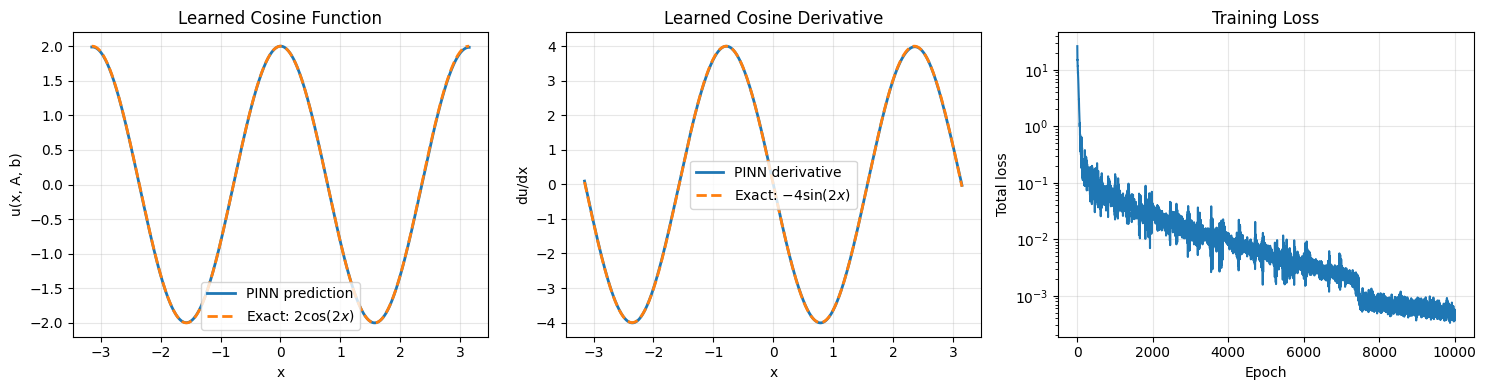


Test function: 2 * cos(2 * x)
Test amplitude: 2
Test frequency: 2

Results at x = 1
Predicted function value: -8.2962574847e-01
True function value:      -8.3229367309e-01
Predicted derivative:     -3.6427935481e+00
True derivative:          -3.6371897073e+00

Function mean absolute error:   5.075127e-03
Derivative mean absolute error: 1.046774e-02


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)


Saved model to: cosine_valley_normalized.keras


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# Target: u(x, A, b) = A*cos(b*x)
# ------------------------------------------------------------
tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")
DTYPE = tf.float64
tf.random.set_seed(42)
np.random.seed(42)

MIN_AMPLITUDE, MAX_AMPLITUDE = -5.10, 5.10
MIN_FREQUENCY, MAX_FREQUENCY = 0.5, 3.0
X_MIN, X_MAX = -3.16, 3.16
BATCH_SIZE = 10000
EPOCHS = 10000
MODEL_PATH = "cosine_valley_normalized.keras"

# ------------------------------------------------------------
# 2. Valley activation and normalized network
# Inputs: [x, amplitude, frequency]
# ------------------------------------------------------------
@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return x**3 * tf.tanh(x) * sech_x

    def get_config(self):
        return super().get_config()


def build_model():
    dtype = tf.float64
    layers = [tf.keras.layers.Input(shape=(3,), dtype=dtype)]

    for index, units in enumerate((256, 128, 96, 32), start=1):
        layers.extend([
            tf.keras.layers.Dense(
                units,
                kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
                ),
                dtype=dtype,
                name=f"dense_{index}",
            ),
            # Normalize over hidden features separately for each sample.
            # Unlike batch normalization, this does not couple samples.
            tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=dtype,
                name=f"layer_norm_{index}",
            ),
            Valley(dtype=dtype, name=f"valley_{index}"),
        ])

    layers.append(tf.keras.layers.Dense(1, dtype=dtype, name="output"))
    return tf.keras.Sequential(layers)


model = build_model()


def predict_u(x, amplitude, frequency, training=True):
    model_input = tf.concat([
        tf.cast(x, DTYPE),
        tf.cast(amplitude, DTYPE),
        tf.cast(frequency, DTYPE),
    ], axis=1)
    return model(model_input, training=training)


# ------------------------------------------------------------
# 3. Randomized training points
# ------------------------------------------------------------
def generate_training_batch(batch_size):
    shape = (batch_size, 1)
    x = tf.random.uniform(shape, X_MIN, X_MAX, dtype=DTYPE)
    amplitude = tf.random.uniform(
        shape, MIN_AMPLITUDE, MAX_AMPLITUDE, dtype=DTYPE
    )
    frequency = tf.random.uniform(
        shape, MIN_FREQUENCY, MAX_FREQUENCY, dtype=DTYPE
    )
    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Function and partial derivative with A and b held fixed
# ------------------------------------------------------------
def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    with tf.GradientTape() as tape:
        tape.watch(x)
        u = predict_u(x, amplitude, frequency, training=training)
    du_dx = tape.gradient(u, x)
    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------
def calculate_loss():
    x, amplitude, frequency = generate_training_batch(BATCH_SIZE)
    u_pred, du_dx = calculate_du_dx(x, amplitude, frequency)

    # d/dx [A*cos(b*x)] = -A*b*sin(b*x)
    exact_derivative = (
        -amplitude * frequency * tf.sin(frequency * x)
    )
    physics_loss = tf.reduce_mean(tf.square(du_dx - exact_derivative))

    # Boundary condition: u(0, A, b) = A
    u_boundary = predict_u(tf.zeros_like(x), amplitude, frequency)
    boundary_loss = tf.reduce_mean(tf.square(u_boundary - amplitude))

    # Amplitude consistency: u(x, A, b) + u(x, -A, b) = 0
    u_negative_a = predict_u(x, -amplitude, frequency)
    algebraic_loss = tf.reduce_mean(tf.square(u_pred + u_negative_a))

    # Cosine is even in x: u(x, A, b) = u(-x, A, b)
    u_negative_x = predict_u(-x, amplitude, frequency)
    cosine_even_loss = tf.reduce_mean(tf.square(u_pred - u_negative_x))

    total_loss = (
        physics_loss
        + boundary_loss
        + 0.125 * algebraic_loss
        + 0.10 * cosine_even_loss
    )
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------
learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS,
    decay_rate=0.1,
    staircase=False,
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm=1.0,
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        (total_loss, physics_loss, boundary_loss,
         algebraic_loss, cosine_even_loss) = calculate_loss()
    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------
loss_history = []
for epoch in range(1, EPOCHS + 1):
    (total_loss, physics_loss, boundary_loss,
     algebraic_loss, cosine_even_loss) = train_step()
    loss_history.append(float(total_loss.numpy()))

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Amplitude: {algebraic_loss.numpy():.6e} | "
            f"Even: {cosine_even_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Evaluate a selected amplitude and frequency
# ------------------------------------------------------------
test_a = 2.0
test_b = 2.0
x_test = tf.reshape(tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000,
), (-1, 1))
a_test = tf.fill(tf.shape(x_test), tf.cast(test_a, DTYPE))
b_test = tf.fill(tf.shape(x_test), tf.cast(test_b, DTYPE))

u_pred, du_dx_pred = calculate_du_dx(
    x_test, a_test, b_test, training=False
)
x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

u_exact = test_a * np.cos(test_b * x_numpy)
du_dx_exact = -test_a * test_b * np.sin(test_b * x_numpy)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(x_numpy, u_numpy, linewidth=2, label="PINN prediction")
axes[0].plot(
    x_numpy, u_exact, "--", linewidth=2,
    label=fr"Exact: ${test_a:g}\cos({test_b:g}x)$",
)
axes[0].set(xlabel="x", ylabel="u(x, A, b)", title="Learned Cosine Function")
axes[0].legend()

axes[1].plot(x_numpy, du_dx_numpy, linewidth=2, label="PINN derivative")
axes[1].plot(
    x_numpy, du_dx_exact, "--", linewidth=2,
    label=fr"Exact: ${-test_a * test_b:g}\sin({test_b:g}x)$",
)
axes[1].set(xlabel="x", ylabel="du/dx", title="Learned Cosine Derivative")
axes[1].legend()

axes[2].semilogy(np.arange(1, len(loss_history) + 1), loss_history)
axes[2].set(xlabel="Epoch", ylabel="Total loss", title="Training Loss")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy and explicit evaluation at x = 1
# ------------------------------------------------------------
function_mae = np.mean(np.abs(u_numpy - u_exact))
derivative_mae = np.mean(np.abs(du_dx_numpy - du_dx_exact))

x_one = tf.constant([[1.0]], dtype=DTYPE)
u_one, du_one = calculate_du_dx(
    x_one,
    tf.fill(tf.shape(x_one), tf.cast(test_a, DTYPE)),
    tf.fill(tf.shape(x_one), tf.cast(test_b, DTYPE)),
    training=False,
)
true_u_one = test_a * np.cos(test_b)
true_du_one = -test_a * test_b * np.sin(test_b)

print(f"\nTest function: {test_a:g} * cos({test_b:g} * x)")
print(f"Test amplitude: {test_a:g}")
print(f"Test frequency: {test_b:g}")
print("\nResults at x = 1")
print(f"Predicted function value: {u_one.numpy().item():.10e}")
print(f"True function value:      {true_u_one:.10e}")
print(f"Predicted derivative:     {du_one.numpy().item():.10e}")
print(f"True derivative:          {true_du_one:.10e}")
print(f"\nFunction mean absolute error:   {function_mae:.6e}")
print(f"Derivative mean absolute error: {derivative_mae:.6e}")
model.summary()
model.save(MODEL_PATH)
print(f"\nSaved model to: {MODEL_PATH}")


In [7]:
import numpy as np
import tensorflow as tf


def test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
):
    """Evaluate the trained cosine PINN on random input triples.

    Requires the training cell's:
        DTYPE, X_MIN, X_MAX,
        MIN_AMPLITUDE, MAX_AMPLITUDE,
        MIN_FREQUENCY, MAX_FREQUENCY,
        calculate_du_dx

    Returns:
        metrics: Average, median, and maximum absolute errors.
        samples: Inputs, predictions, exact values, and errors.

    Median and maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")

    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    # --------------------------------------------------------
    # 1. Generate random (x, amplitude, frequency) triples
    # --------------------------------------------------------
    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype

    x = rng.uniform(
        X_MIN,
        X_MAX,
        (n_points, 1),
    ).astype(dtype)

    amplitude = rng.uniform(
        MIN_AMPLITUDE,
        MAX_AMPLITUDE,
        (n_points, 1),
    ).astype(dtype)

    frequency = rng.uniform(
        MIN_FREQUENCY,
        MAX_FREQUENCY,
        (n_points, 1),
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # --------------------------------------------------------
    # 2. Evaluate predictions and automatic derivatives
    # --------------------------------------------------------
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)

        u_batch, du_batch = calculate_du_dx(
            x[start:stop],
            amplitude[start:stop],
            frequency[start:stop],
            training=False,
        )

        if du_batch is None:
            raise RuntimeError(
                "The model derivative with respect to x is unavailable."
            )

        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # --------------------------------------------------------
    # 3. Exact cosine function and derivative
    #
    # u(x, A, b) = A*cos(b*x)
    # du/dx      = -A*b*sin(b*x)
    # --------------------------------------------------------
    u_exact = amplitude * np.cos(frequency * x)

    du_dx_exact = (
        -amplitude
        * frequency
        * np.sin(frequency * x)
    )

    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (
        np.isfinite(function_error).all()
        and np.isfinite(derivative_error).all()
    ):
        raise FloatingPointError(
            "Nonfinite predictions or errors encountered."
        )

    # --------------------------------------------------------
    # 4. Error metrics
    # Original labels retained; median and maximum summarize
    # pointwise absolute errors rather than mean errors.
    # --------------------------------------------------------
    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(
        f"Random cosine inference points: {n_points:,} | "
        f"Seed: {seed}"
    )

    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()

        print(f"{name:<30} {value:.10e}")

    # --------------------------------------------------------
    # 5. Return all sampled inputs and results
    # Each array has one entry per sampled point.
    # --------------------------------------------------------
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }

    return metrics, samples


# Run after your cosine model has finished training.
metrics, samples = test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
)

Random cosine inference points: 100,000 | Seed: 12345

Average function MAE           6.1676972119e-03
Average derivative MAE         1.1668041255e-02

Median function MAE            4.5448472455e-03
Median derivative MAE          8.2838366971e-03

Maximum function MAE           9.9883475908e-02
Maximum derivative MAE         8.5125738260e-01


<h1> Higher Power Valley Cosine </h1>

Epoch:     1 | Total: 3.425717e+01 | Physics: 1.824954e+01 | Boundary: 1.058096e+01 | Amplitude: 2.725438e+01 | Even: 2.019864e+01
Epoch:   500 | Total: 8.964641e-02 | Physics: 7.899876e-02 | Boundary: 4.609061e-03 | Amplitude: 2.752368e-02 | Even: 2.598129e-02
Epoch:  1000 | Total: 1.078764e-01 | Physics: 9.350632e-02 | Boundary: 1.404563e-03 | Amplitude: 7.745950e-02 | Even: 3.283074e-02
Epoch:  1500 | Total: 3.769969e-02 | Physics: 3.182115e-02 | Boundary: 2.705399e-03 | Amplitude: 1.729629e-02 | Even: 1.011105e-02
Epoch:  2000 | Total: 2.503588e-02 | Physics: 2.066572e-02 | Boundary: 1.524916e-03 | Amplitude: 1.697134e-02 | Even: 7.238219e-03
Epoch:  2500 | Total: 3.218452e-02 | Physics: 2.861577e-02 | Boundary: 4.439401e-04 | Amplitude: 1.452733e-02 | Even: 1.308895e-02
Epoch:  3000 | Total: 1.621521e-02 | Physics: 1.429015e-02 | Boundary: 4.212199e-04 | Amplitude: 1.121395e-02 | Even: 1.021005e-03
Epoch:  3500 | Total: 1.261124e-02 | Physics: 1.034715e-02 | Boundary: 7.786190e-04

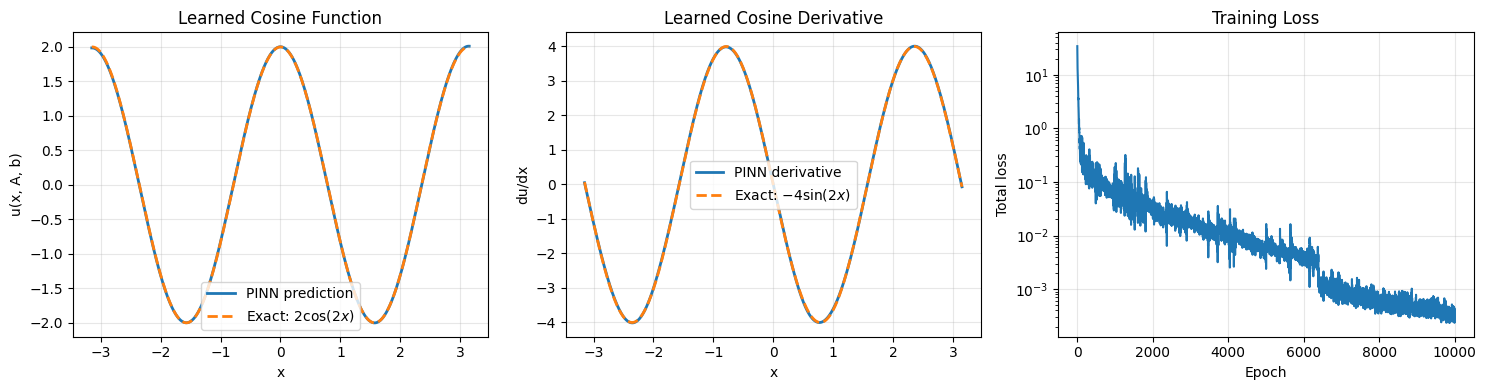


Test function: 2 * cos(2 * x)
Test amplitude: 2
Test frequency: 2

Results at x = 1
Predicted function value: -8.3426109692e-01
True function value:      -8.3229367309e-01
Predicted derivative:     -3.6078136583e+00
True derivative:          -3.6371897073e+00

Function mean absolute error:   4.735973e-03
Derivative mean absolute error: 1.222393e-02


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_4 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)


Saved model to: cosine_valley_normalized.keras


In [14]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# Target: u(x, A, b) = A*cos(b*x)
# ------------------------------------------------------------
tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")
DTYPE = tf.float64
tf.random.set_seed(42)
np.random.seed(42)

MIN_AMPLITUDE, MAX_AMPLITUDE = -5.10, 5.10
MIN_FREQUENCY, MAX_FREQUENCY = 0.5, 3.0
X_MIN, X_MAX = -3.16, 3.16
BATCH_SIZE = 10000
EPOCHS = 10000
MODEL_PATH = "cosine_valley_normalized.keras"

# ------------------------------------------------------------
# 2. Valley activation and normalized network
# Inputs: [x, amplitude, frequency]
# ------------------------------------------------------------
@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return 5 * (x**3 * tf.tanh(x) * sech_x)

    def get_config(self):
        return super().get_config()


def build_model():
    dtype = tf.float64
    layers = [tf.keras.layers.Input(shape=(3,), dtype=dtype)]

    for index, units in enumerate((256, 128, 96, 32), start=1):
        layers.extend([
            tf.keras.layers.Dense(
                units,
                kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
                ),
                dtype=dtype,
                name=f"dense_{index}",
            ),
            # Normalize over hidden features separately for each sample.
            # Unlike batch normalization, this does not couple samples.
            tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=dtype,
                name=f"layer_norm_{index}",
            ),
            Valley(dtype=dtype, name=f"valley_{index}"),
        ])

    layers.append(tf.keras.layers.Dense(1, dtype=dtype, name="output"))
    return tf.keras.Sequential(layers)


model = build_model()


def predict_u(x, amplitude, frequency, training=True):
    model_input = tf.concat([
        tf.cast(x, DTYPE),
        tf.cast(amplitude, DTYPE),
        tf.cast(frequency, DTYPE),
    ], axis=1)
    return model(model_input, training=training)


# ------------------------------------------------------------
# 3. Randomized training points
# ------------------------------------------------------------
def generate_training_batch(batch_size):
    shape = (batch_size, 1)
    x = tf.random.uniform(shape, X_MIN, X_MAX, dtype=DTYPE)
    amplitude = tf.random.uniform(
        shape, MIN_AMPLITUDE, MAX_AMPLITUDE, dtype=DTYPE
    )
    frequency = tf.random.uniform(
        shape, MIN_FREQUENCY, MAX_FREQUENCY, dtype=DTYPE
    )
    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Function and partial derivative with A and b held fixed
# ------------------------------------------------------------
def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    with tf.GradientTape() as tape:
        tape.watch(x)
        u = predict_u(x, amplitude, frequency, training=training)
    du_dx = tape.gradient(u, x)
    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------
def calculate_loss():
    x, amplitude, frequency = generate_training_batch(BATCH_SIZE)
    u_pred, du_dx = calculate_du_dx(x, amplitude, frequency)

    # d/dx [A*cos(b*x)] = -A*b*sin(b*x)
    exact_derivative = (
        -amplitude * frequency * tf.sin(frequency * x)
    )
    physics_loss = tf.reduce_mean(tf.square(du_dx - exact_derivative))

    # Boundary condition: u(0, A, b) = A
    u_boundary = predict_u(tf.zeros_like(x), amplitude, frequency)
    boundary_loss = tf.reduce_mean(tf.square(u_boundary - amplitude))

    # Amplitude consistency: u(x, A, b) + u(x, -A, b) = 0
    u_negative_a = predict_u(x, -amplitude, frequency)
    algebraic_loss = tf.reduce_mean(tf.square(u_pred + u_negative_a))

    # Cosine is even in x: u(x, A, b) = u(-x, A, b)
    u_negative_x = predict_u(-x, amplitude, frequency)
    cosine_even_loss = tf.reduce_mean(tf.square(u_pred - u_negative_x))

    total_loss = (
        physics_loss
        + boundary_loss
        + 0.125 * algebraic_loss
        + 0.10 * cosine_even_loss
    )
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------
learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS,
    decay_rate=0.1,
    staircase=False,
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm=1.0,
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        (total_loss, physics_loss, boundary_loss,
         algebraic_loss, cosine_even_loss) = calculate_loss()
    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------
loss_history = []
for epoch in range(1, EPOCHS + 1):
    (total_loss, physics_loss, boundary_loss,
     algebraic_loss, cosine_even_loss) = train_step()
    loss_history.append(float(total_loss.numpy()))

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Amplitude: {algebraic_loss.numpy():.6e} | "
            f"Even: {cosine_even_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Evaluate a selected amplitude and frequency
# ------------------------------------------------------------
test_a = 2.0
test_b = 2.0
x_test = tf.reshape(tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000,
), (-1, 1))
a_test = tf.fill(tf.shape(x_test), tf.cast(test_a, DTYPE))
b_test = tf.fill(tf.shape(x_test), tf.cast(test_b, DTYPE))

u_pred, du_dx_pred = calculate_du_dx(
    x_test, a_test, b_test, training=False
)
x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

u_exact = test_a * np.cos(test_b * x_numpy)
du_dx_exact = -test_a * test_b * np.sin(test_b * x_numpy)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(x_numpy, u_numpy, linewidth=2, label="PINN prediction")
axes[0].plot(
    x_numpy, u_exact, "--", linewidth=2,
    label=fr"Exact: ${test_a:g}\cos({test_b:g}x)$",
)
axes[0].set(xlabel="x", ylabel="u(x, A, b)", title="Learned Cosine Function")
axes[0].legend()

axes[1].plot(x_numpy, du_dx_numpy, linewidth=2, label="PINN derivative")
axes[1].plot(
    x_numpy, du_dx_exact, "--", linewidth=2,
    label=fr"Exact: ${-test_a * test_b:g}\sin({test_b:g}x)$",
)
axes[1].set(xlabel="x", ylabel="du/dx", title="Learned Cosine Derivative")
axes[1].legend()

axes[2].semilogy(np.arange(1, len(loss_history) + 1), loss_history)
axes[2].set(xlabel="Epoch", ylabel="Total loss", title="Training Loss")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy and explicit evaluation at x = 1
# ------------------------------------------------------------
function_mae = np.mean(np.abs(u_numpy - u_exact))
derivative_mae = np.mean(np.abs(du_dx_numpy - du_dx_exact))

x_one = tf.constant([[1.0]], dtype=DTYPE)
u_one, du_one = calculate_du_dx(
    x_one,
    tf.fill(tf.shape(x_one), tf.cast(test_a, DTYPE)),
    tf.fill(tf.shape(x_one), tf.cast(test_b, DTYPE)),
    training=False,
)
true_u_one = test_a * np.cos(test_b)
true_du_one = -test_a * test_b * np.sin(test_b)

print(f"\nTest function: {test_a:g} * cos({test_b:g} * x)")
print(f"Test amplitude: {test_a:g}")
print(f"Test frequency: {test_b:g}")
print("\nResults at x = 1")
print(f"Predicted function value: {u_one.numpy().item():.10e}")
print(f"True function value:      {true_u_one:.10e}")
print(f"Predicted derivative:     {du_one.numpy().item():.10e}")
print(f"True derivative:          {true_du_one:.10e}")
print(f"\nFunction mean absolute error:   {function_mae:.6e}")
print(f"Derivative mean absolute error: {derivative_mae:.6e}")
model.summary()
model.save(MODEL_PATH)
print(f"\nSaved model to: {MODEL_PATH}")


Base quantity: log10(loss), floored at 1e-16.
Display centering/scaling is specified in each plot caption.


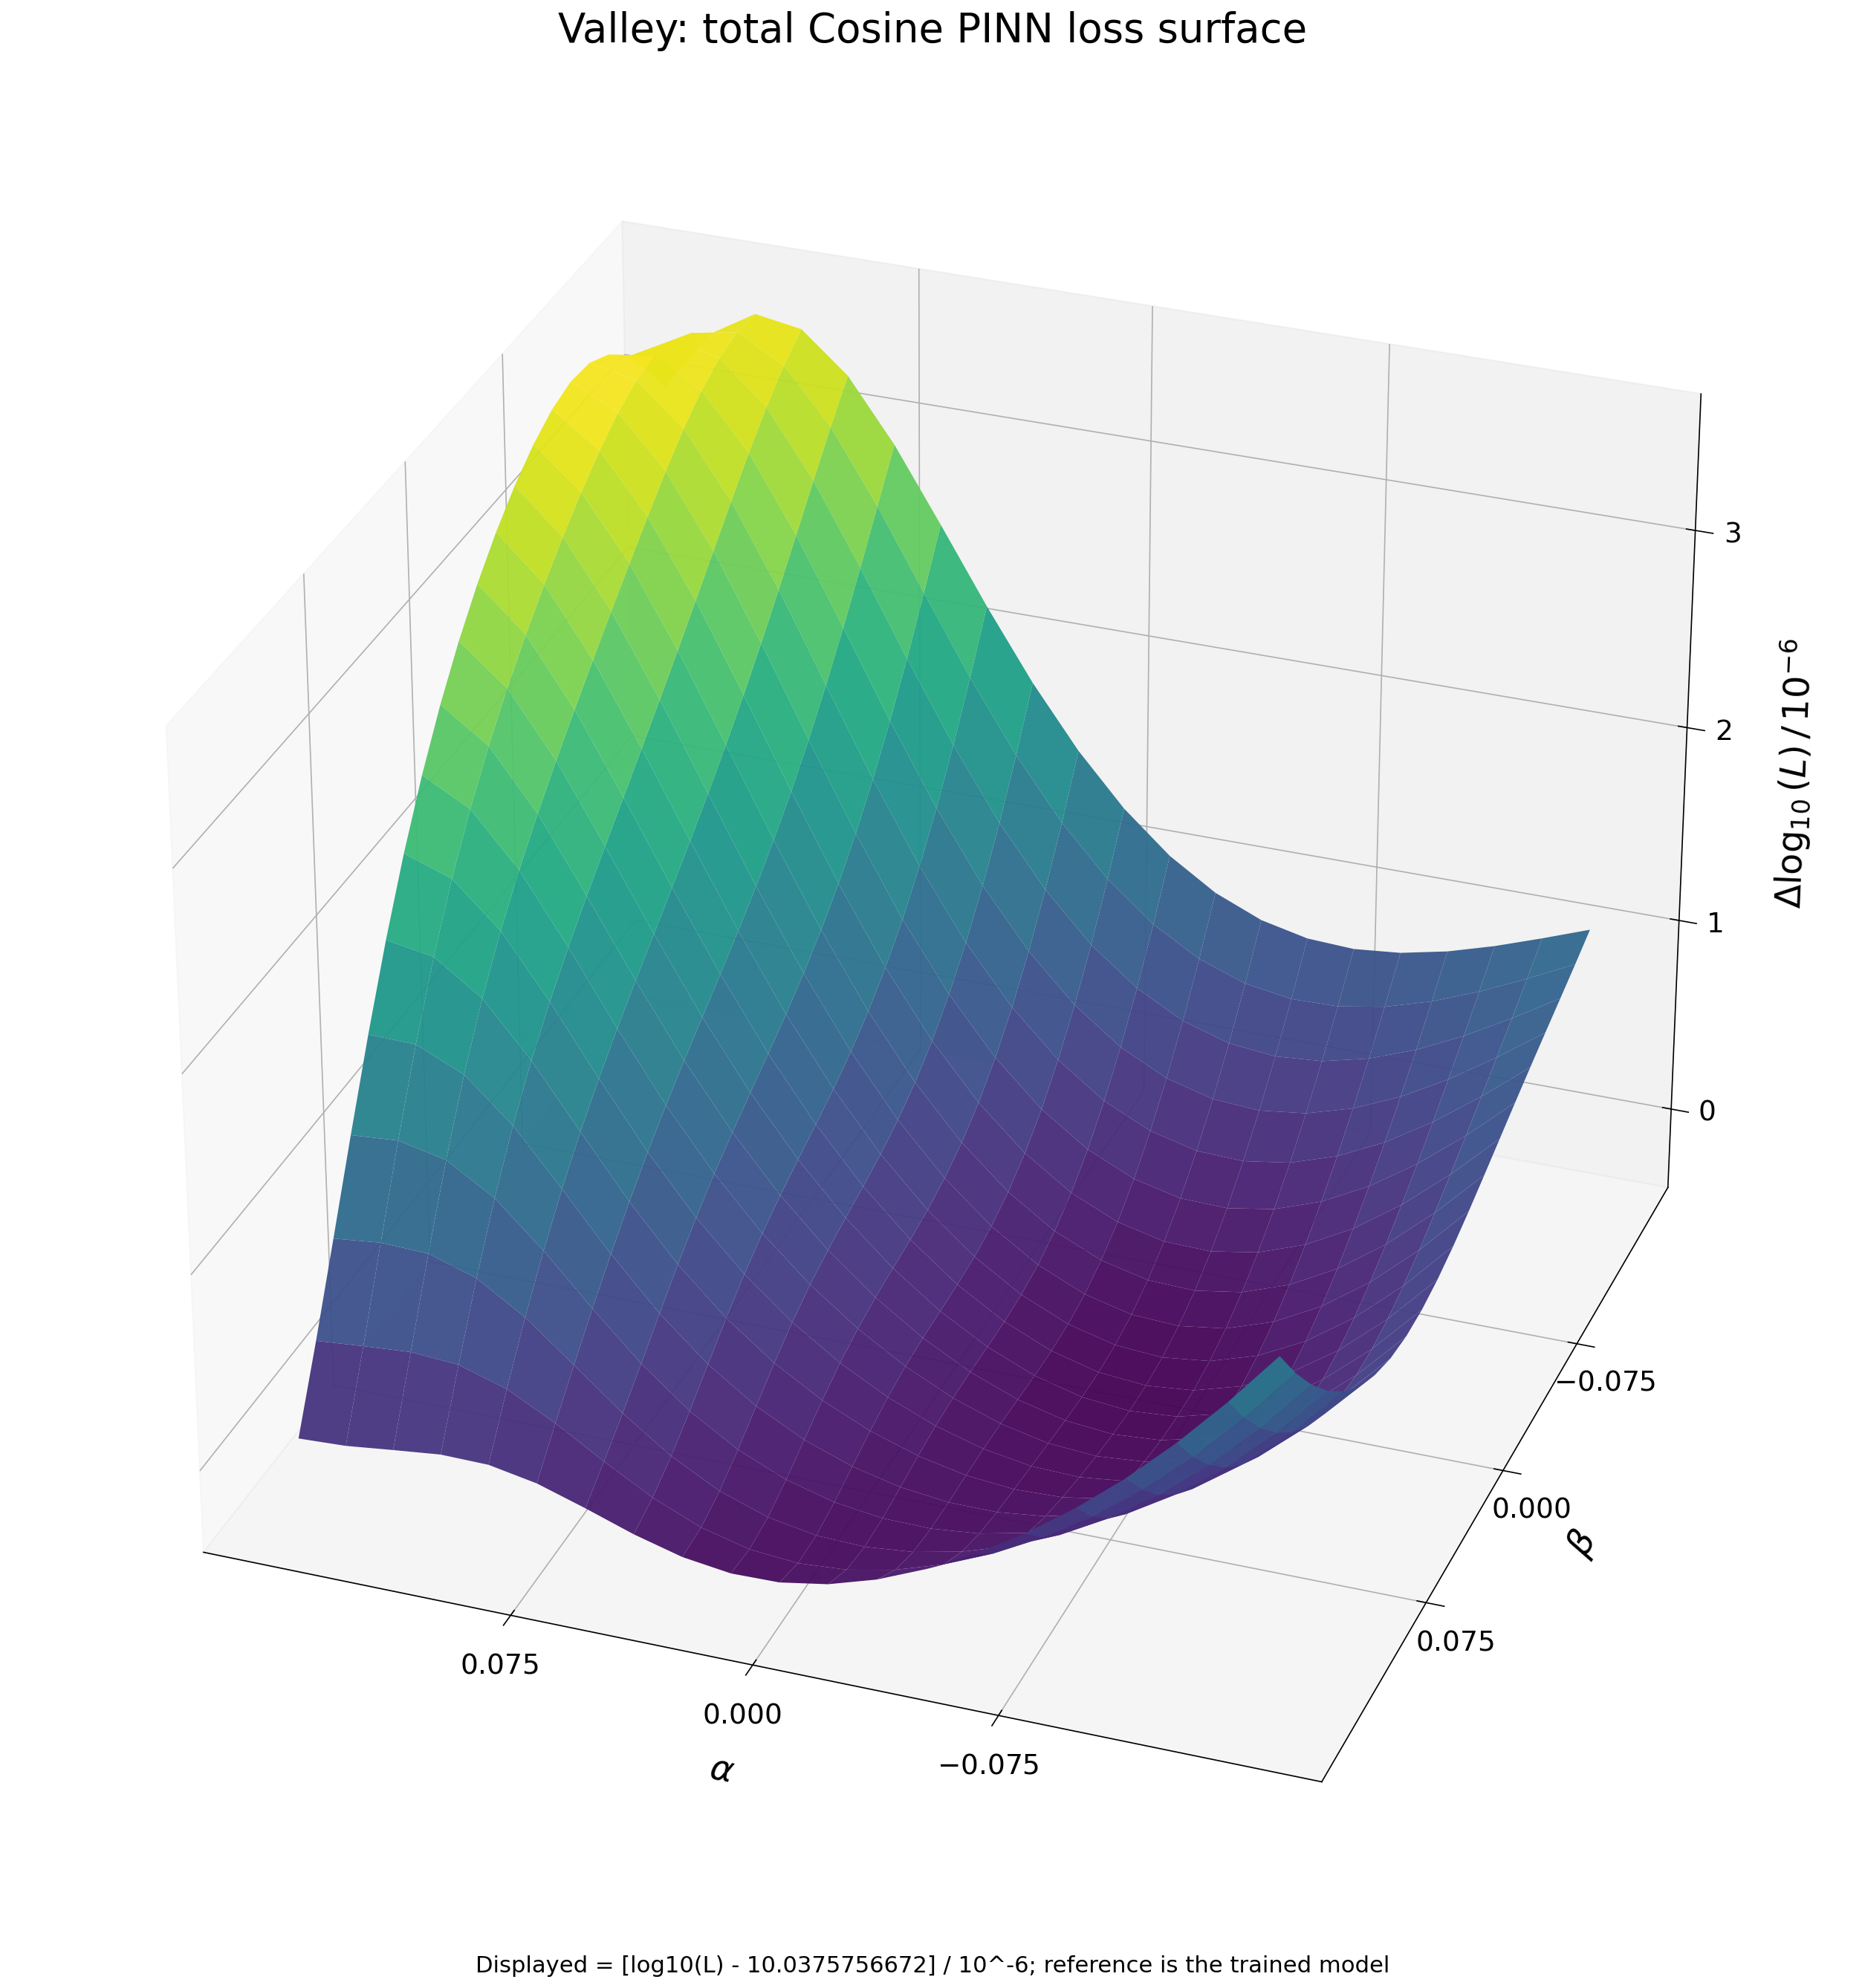

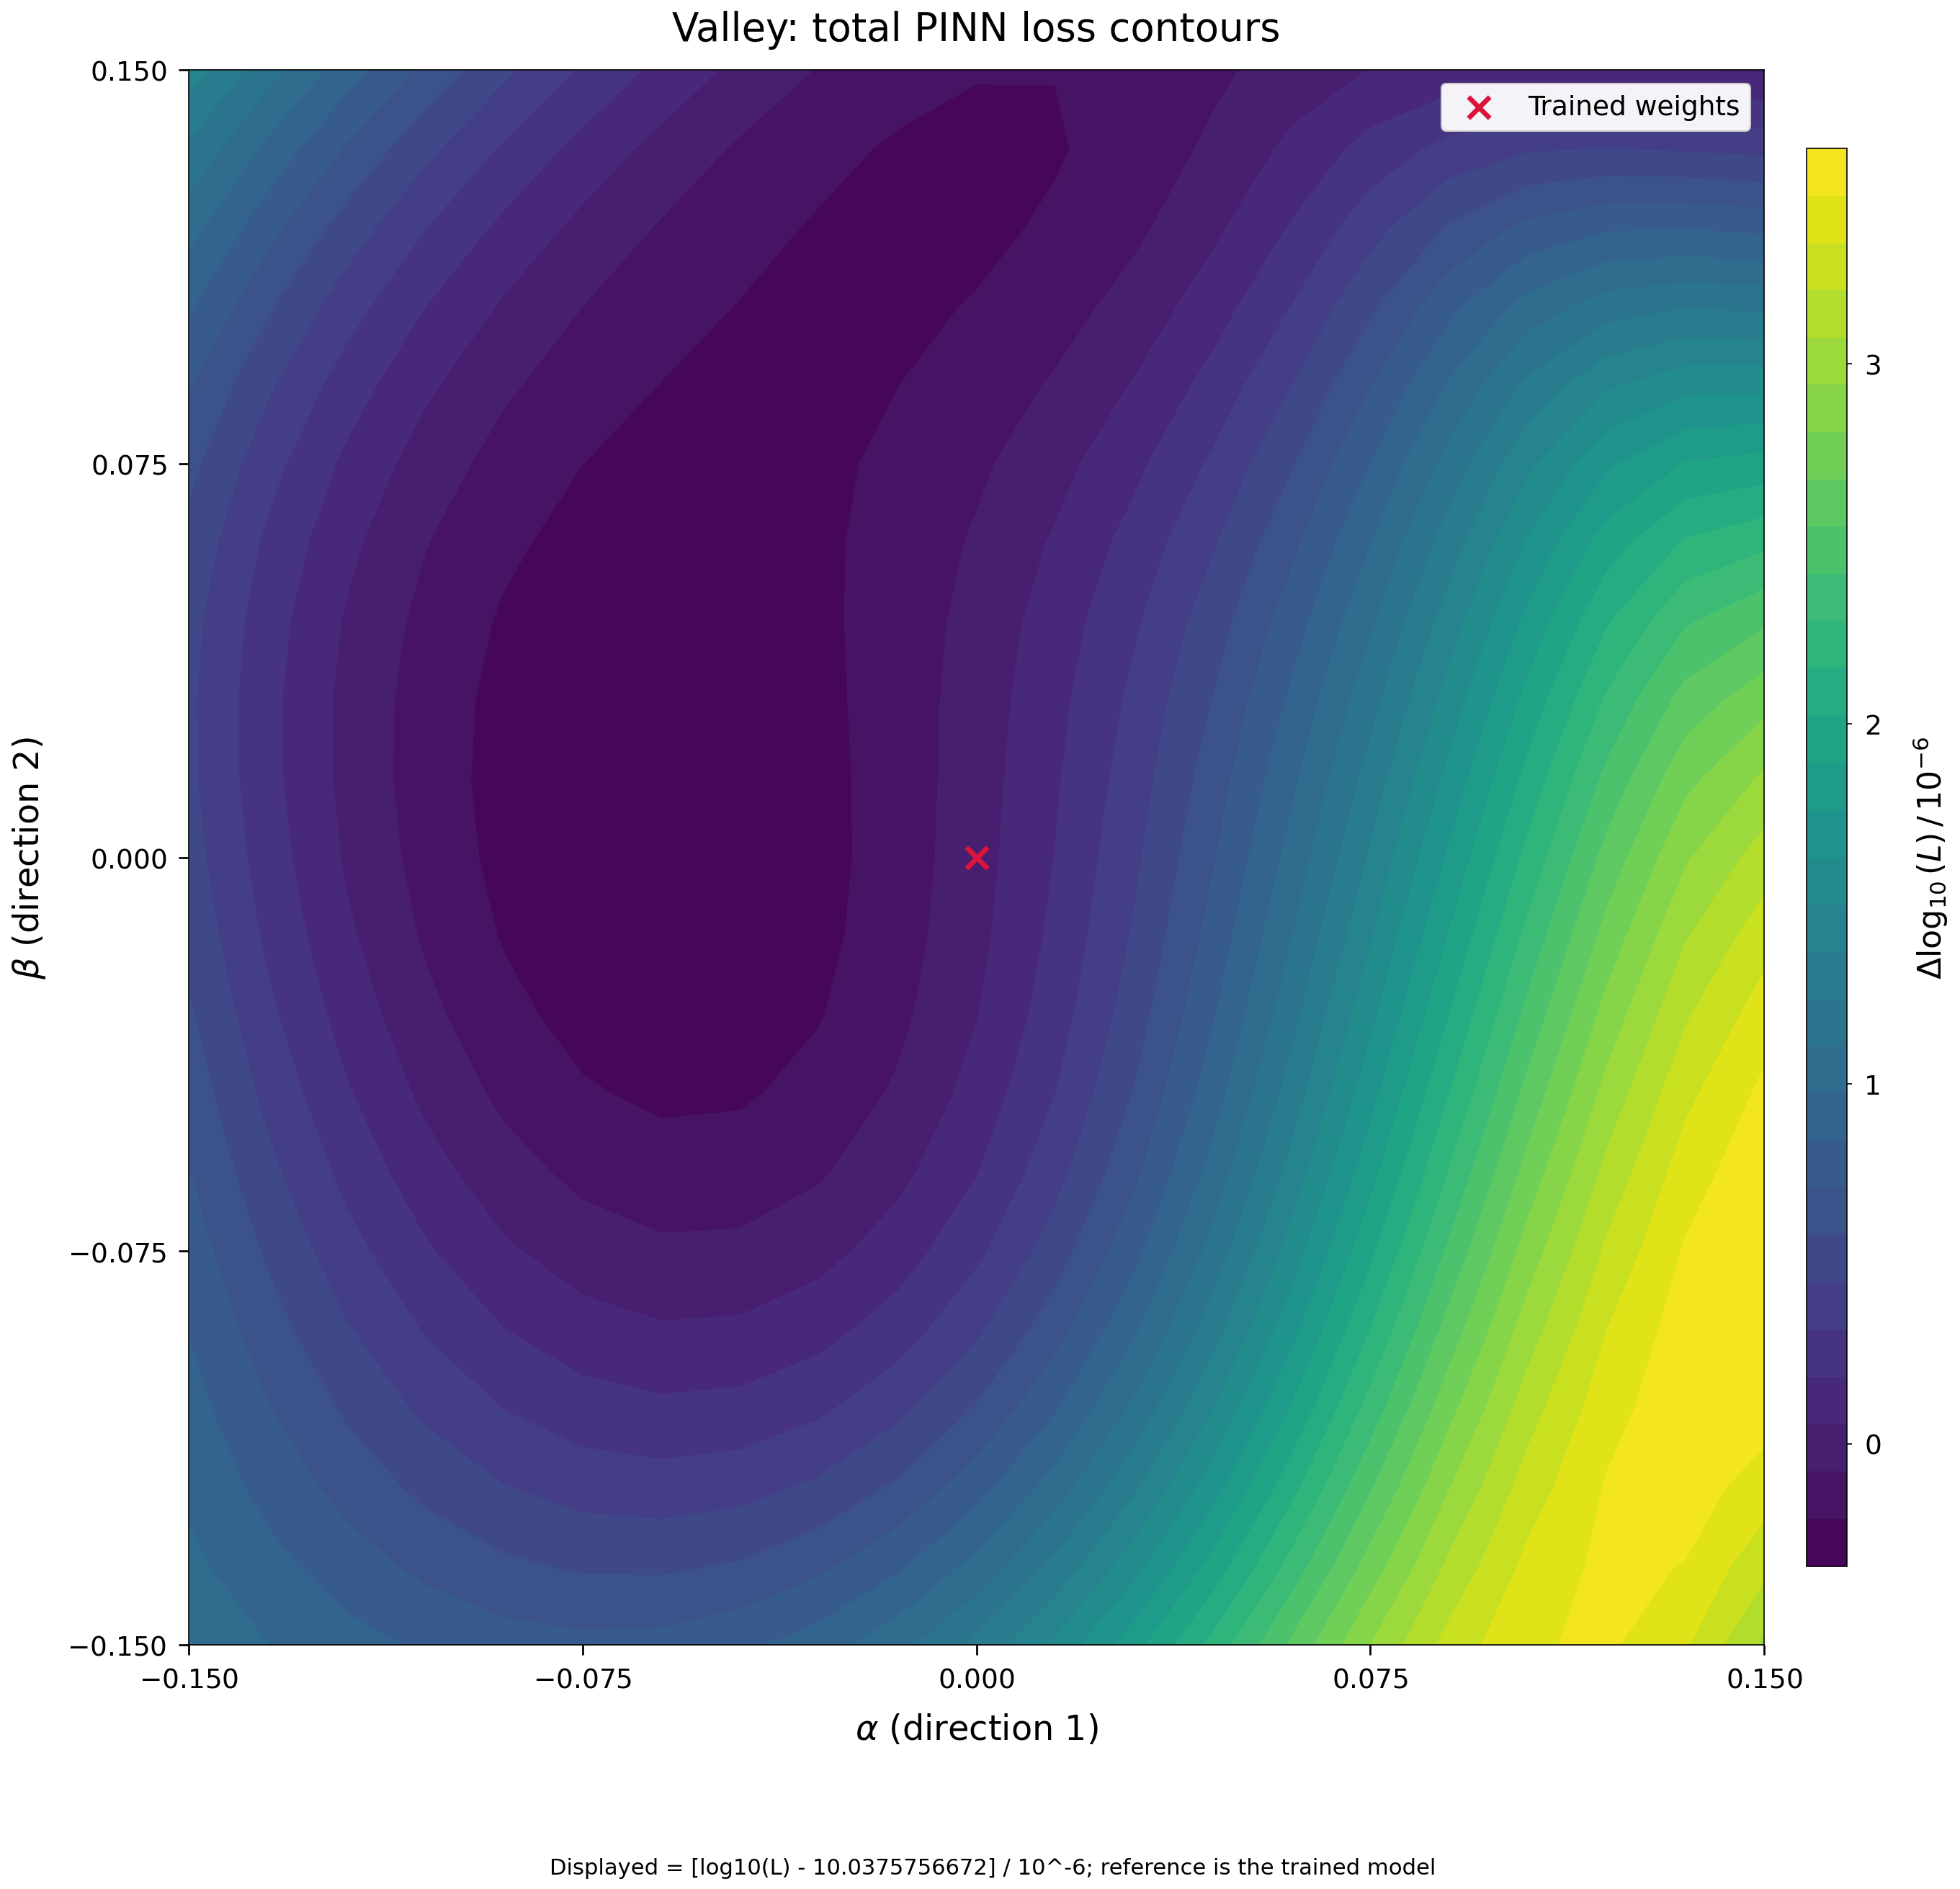

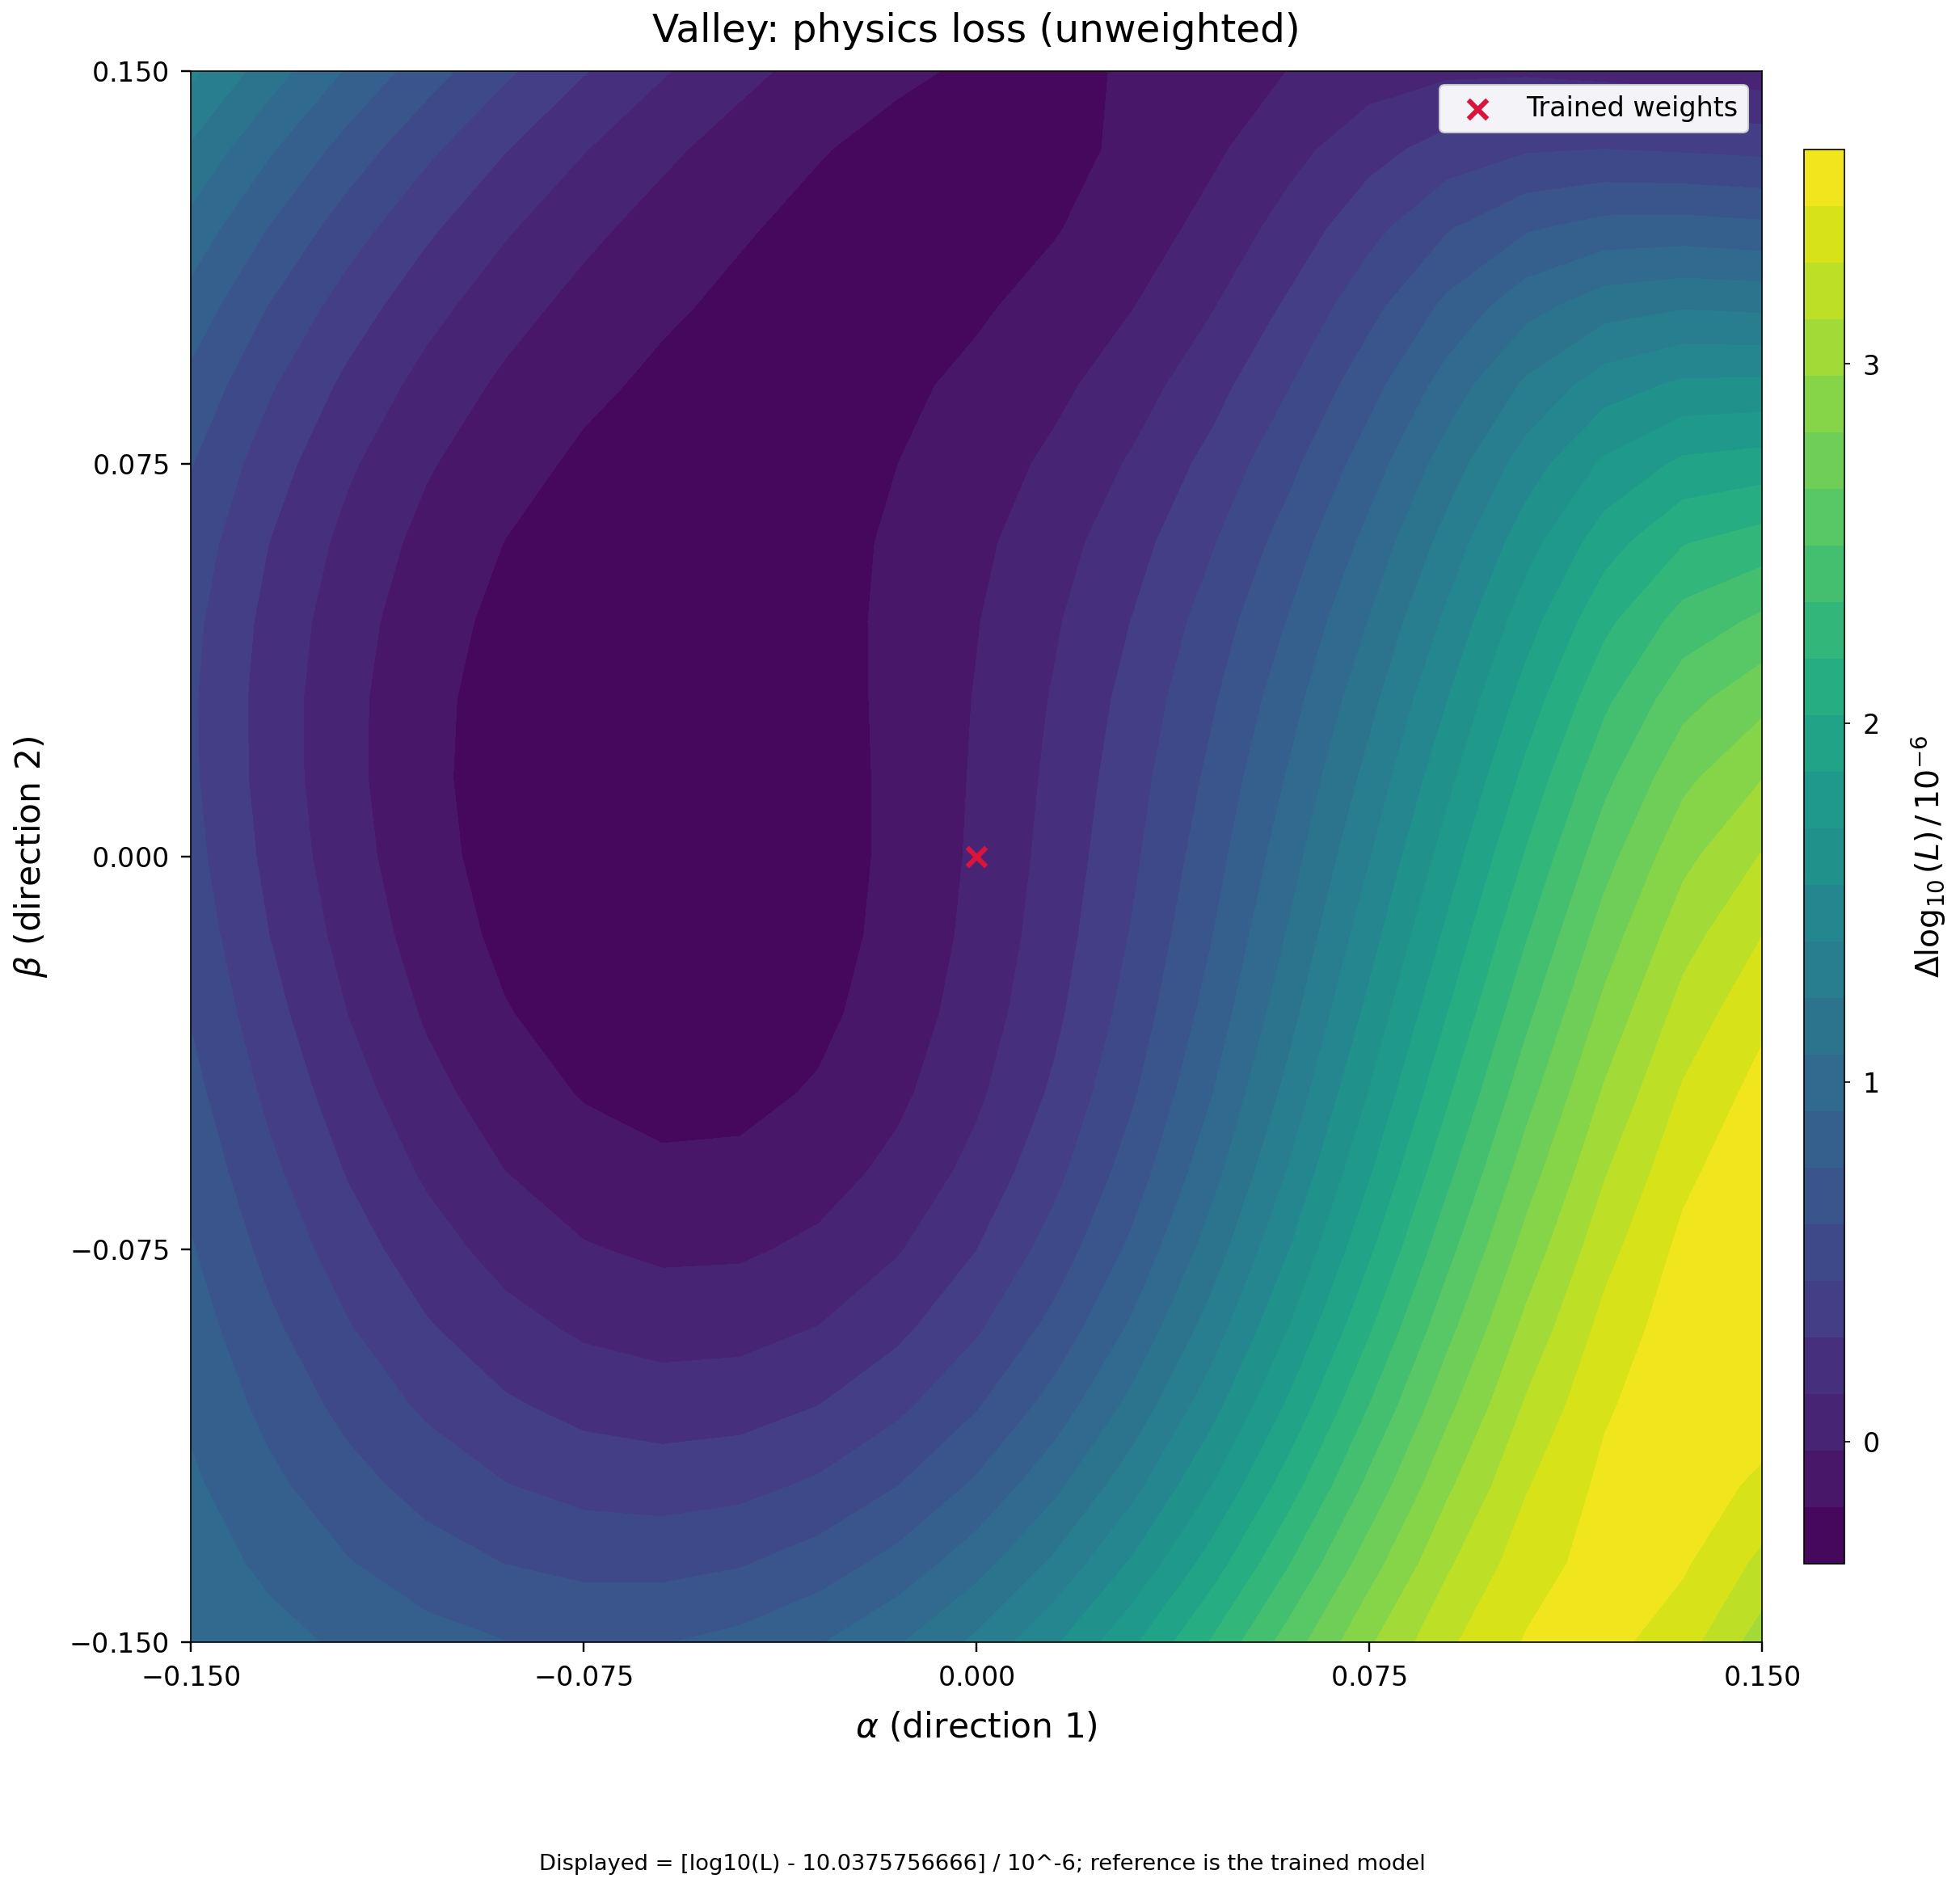

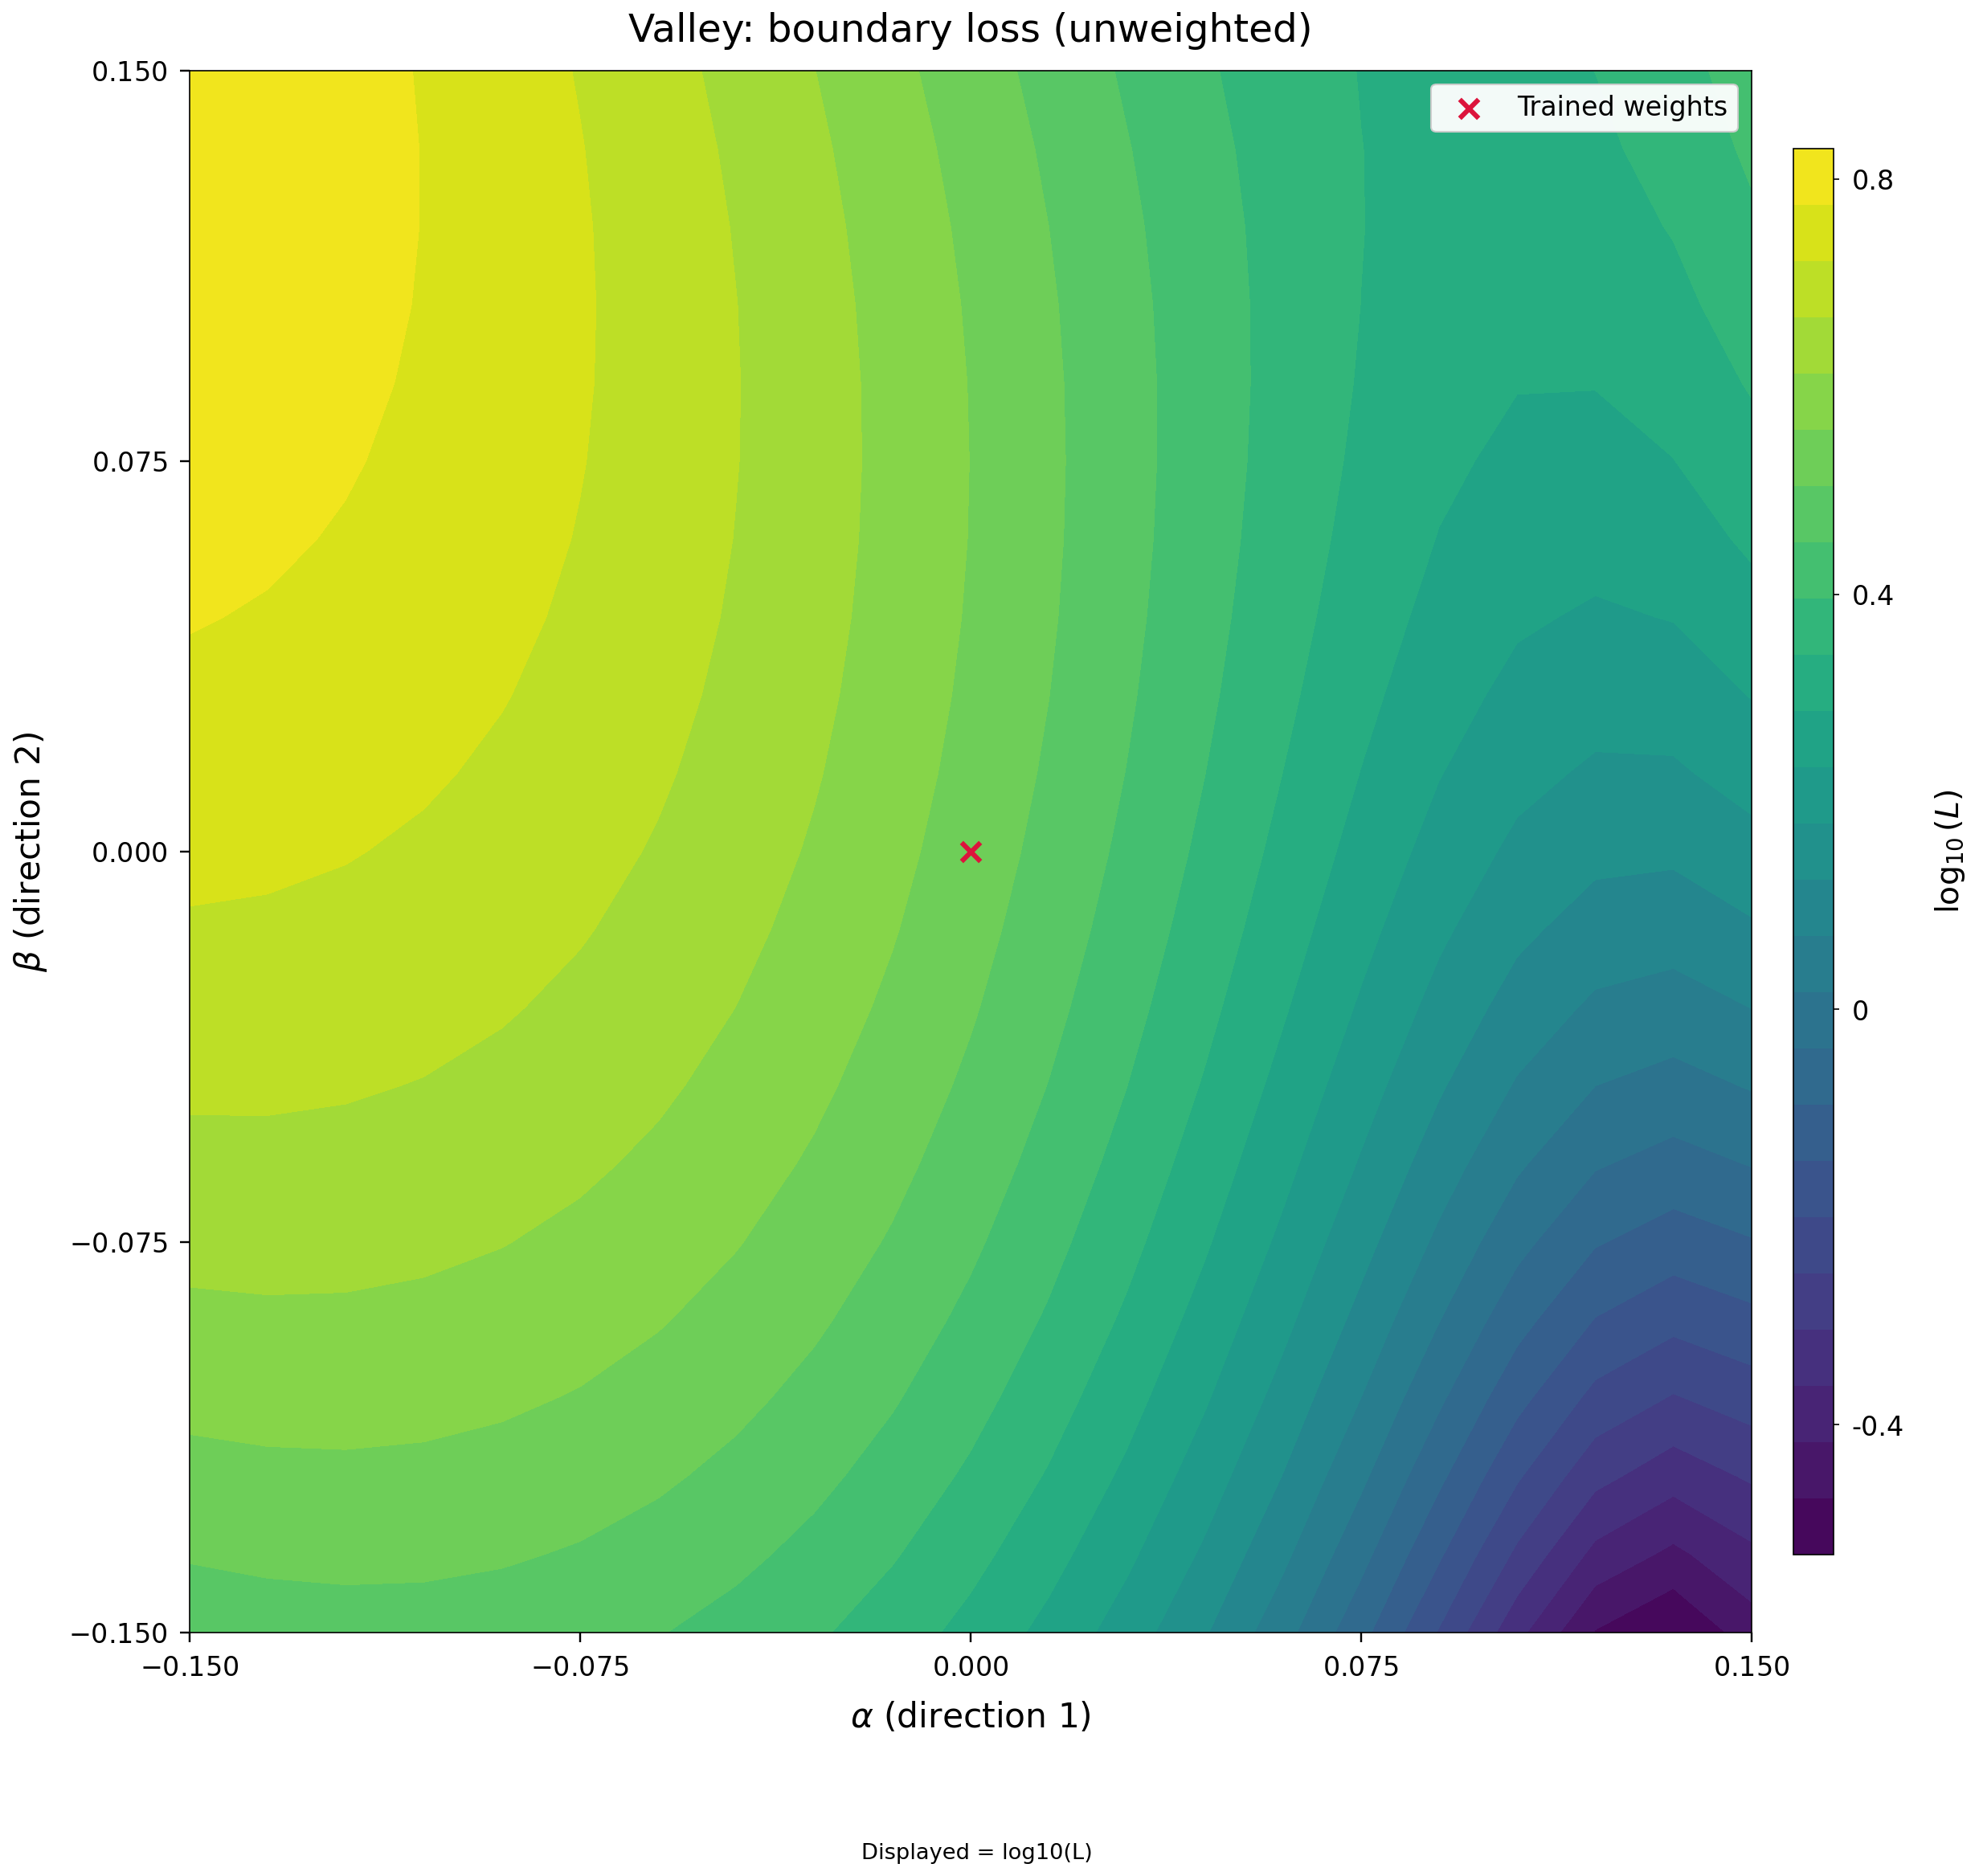

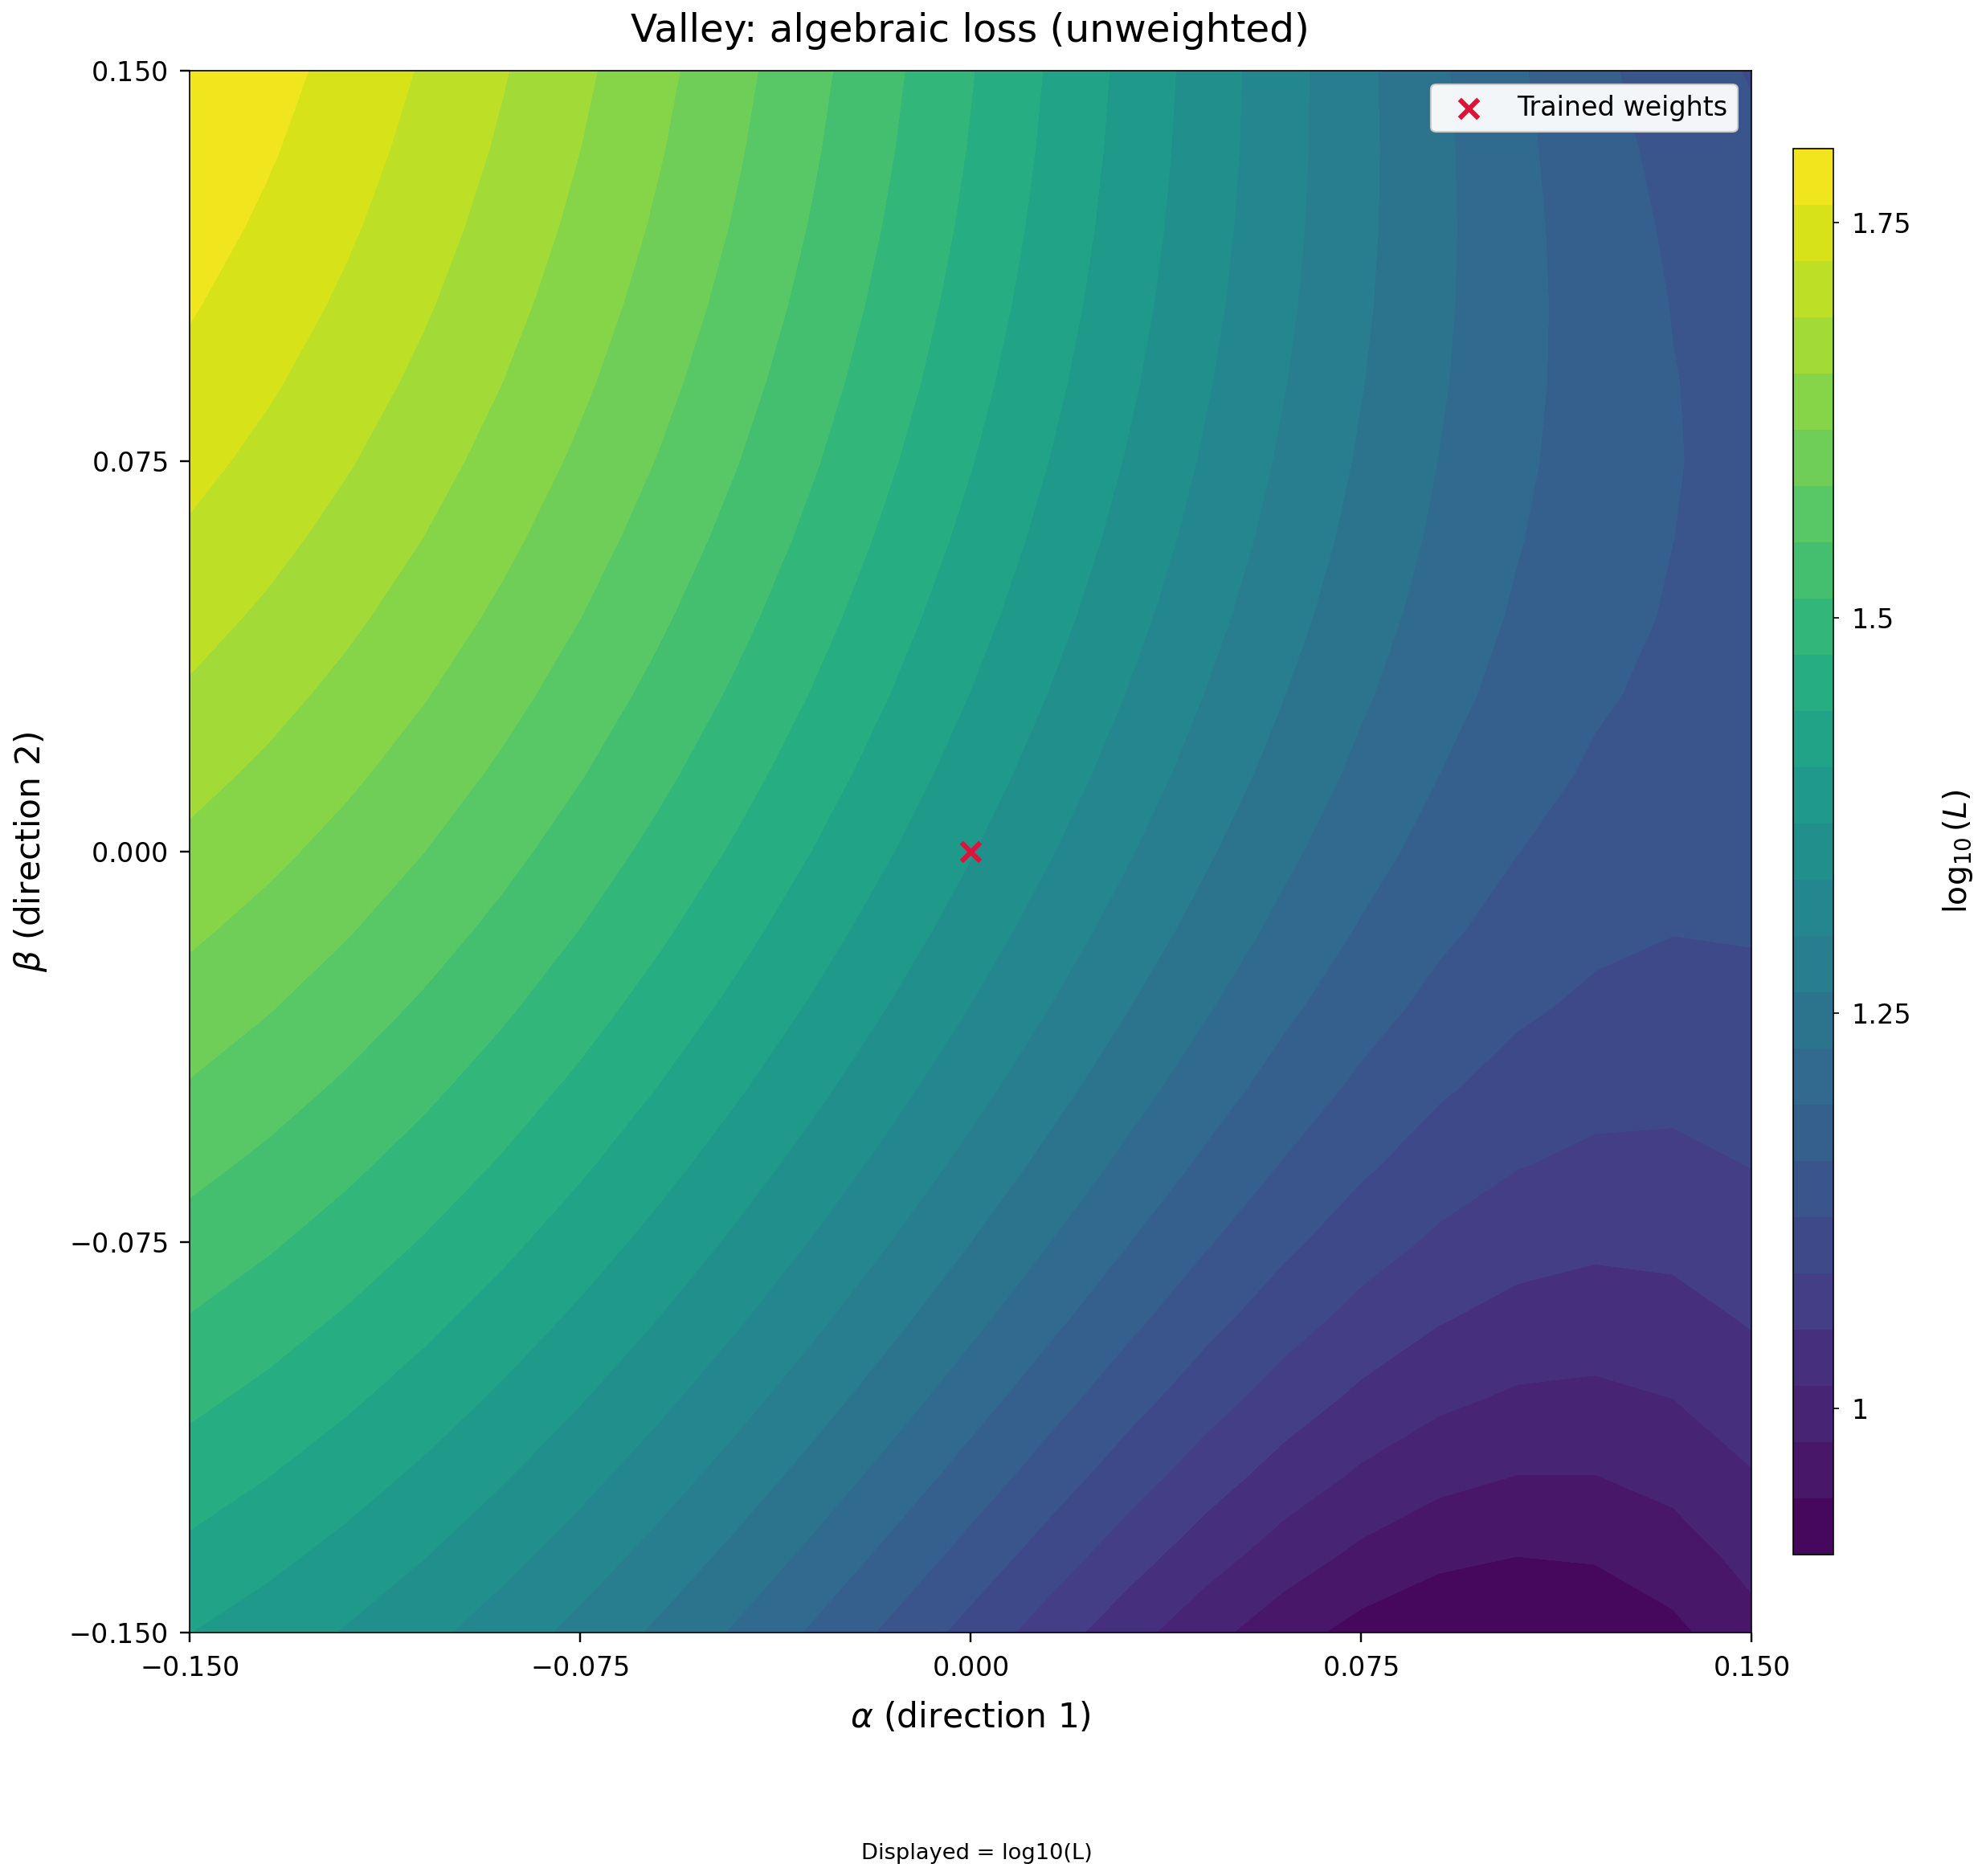

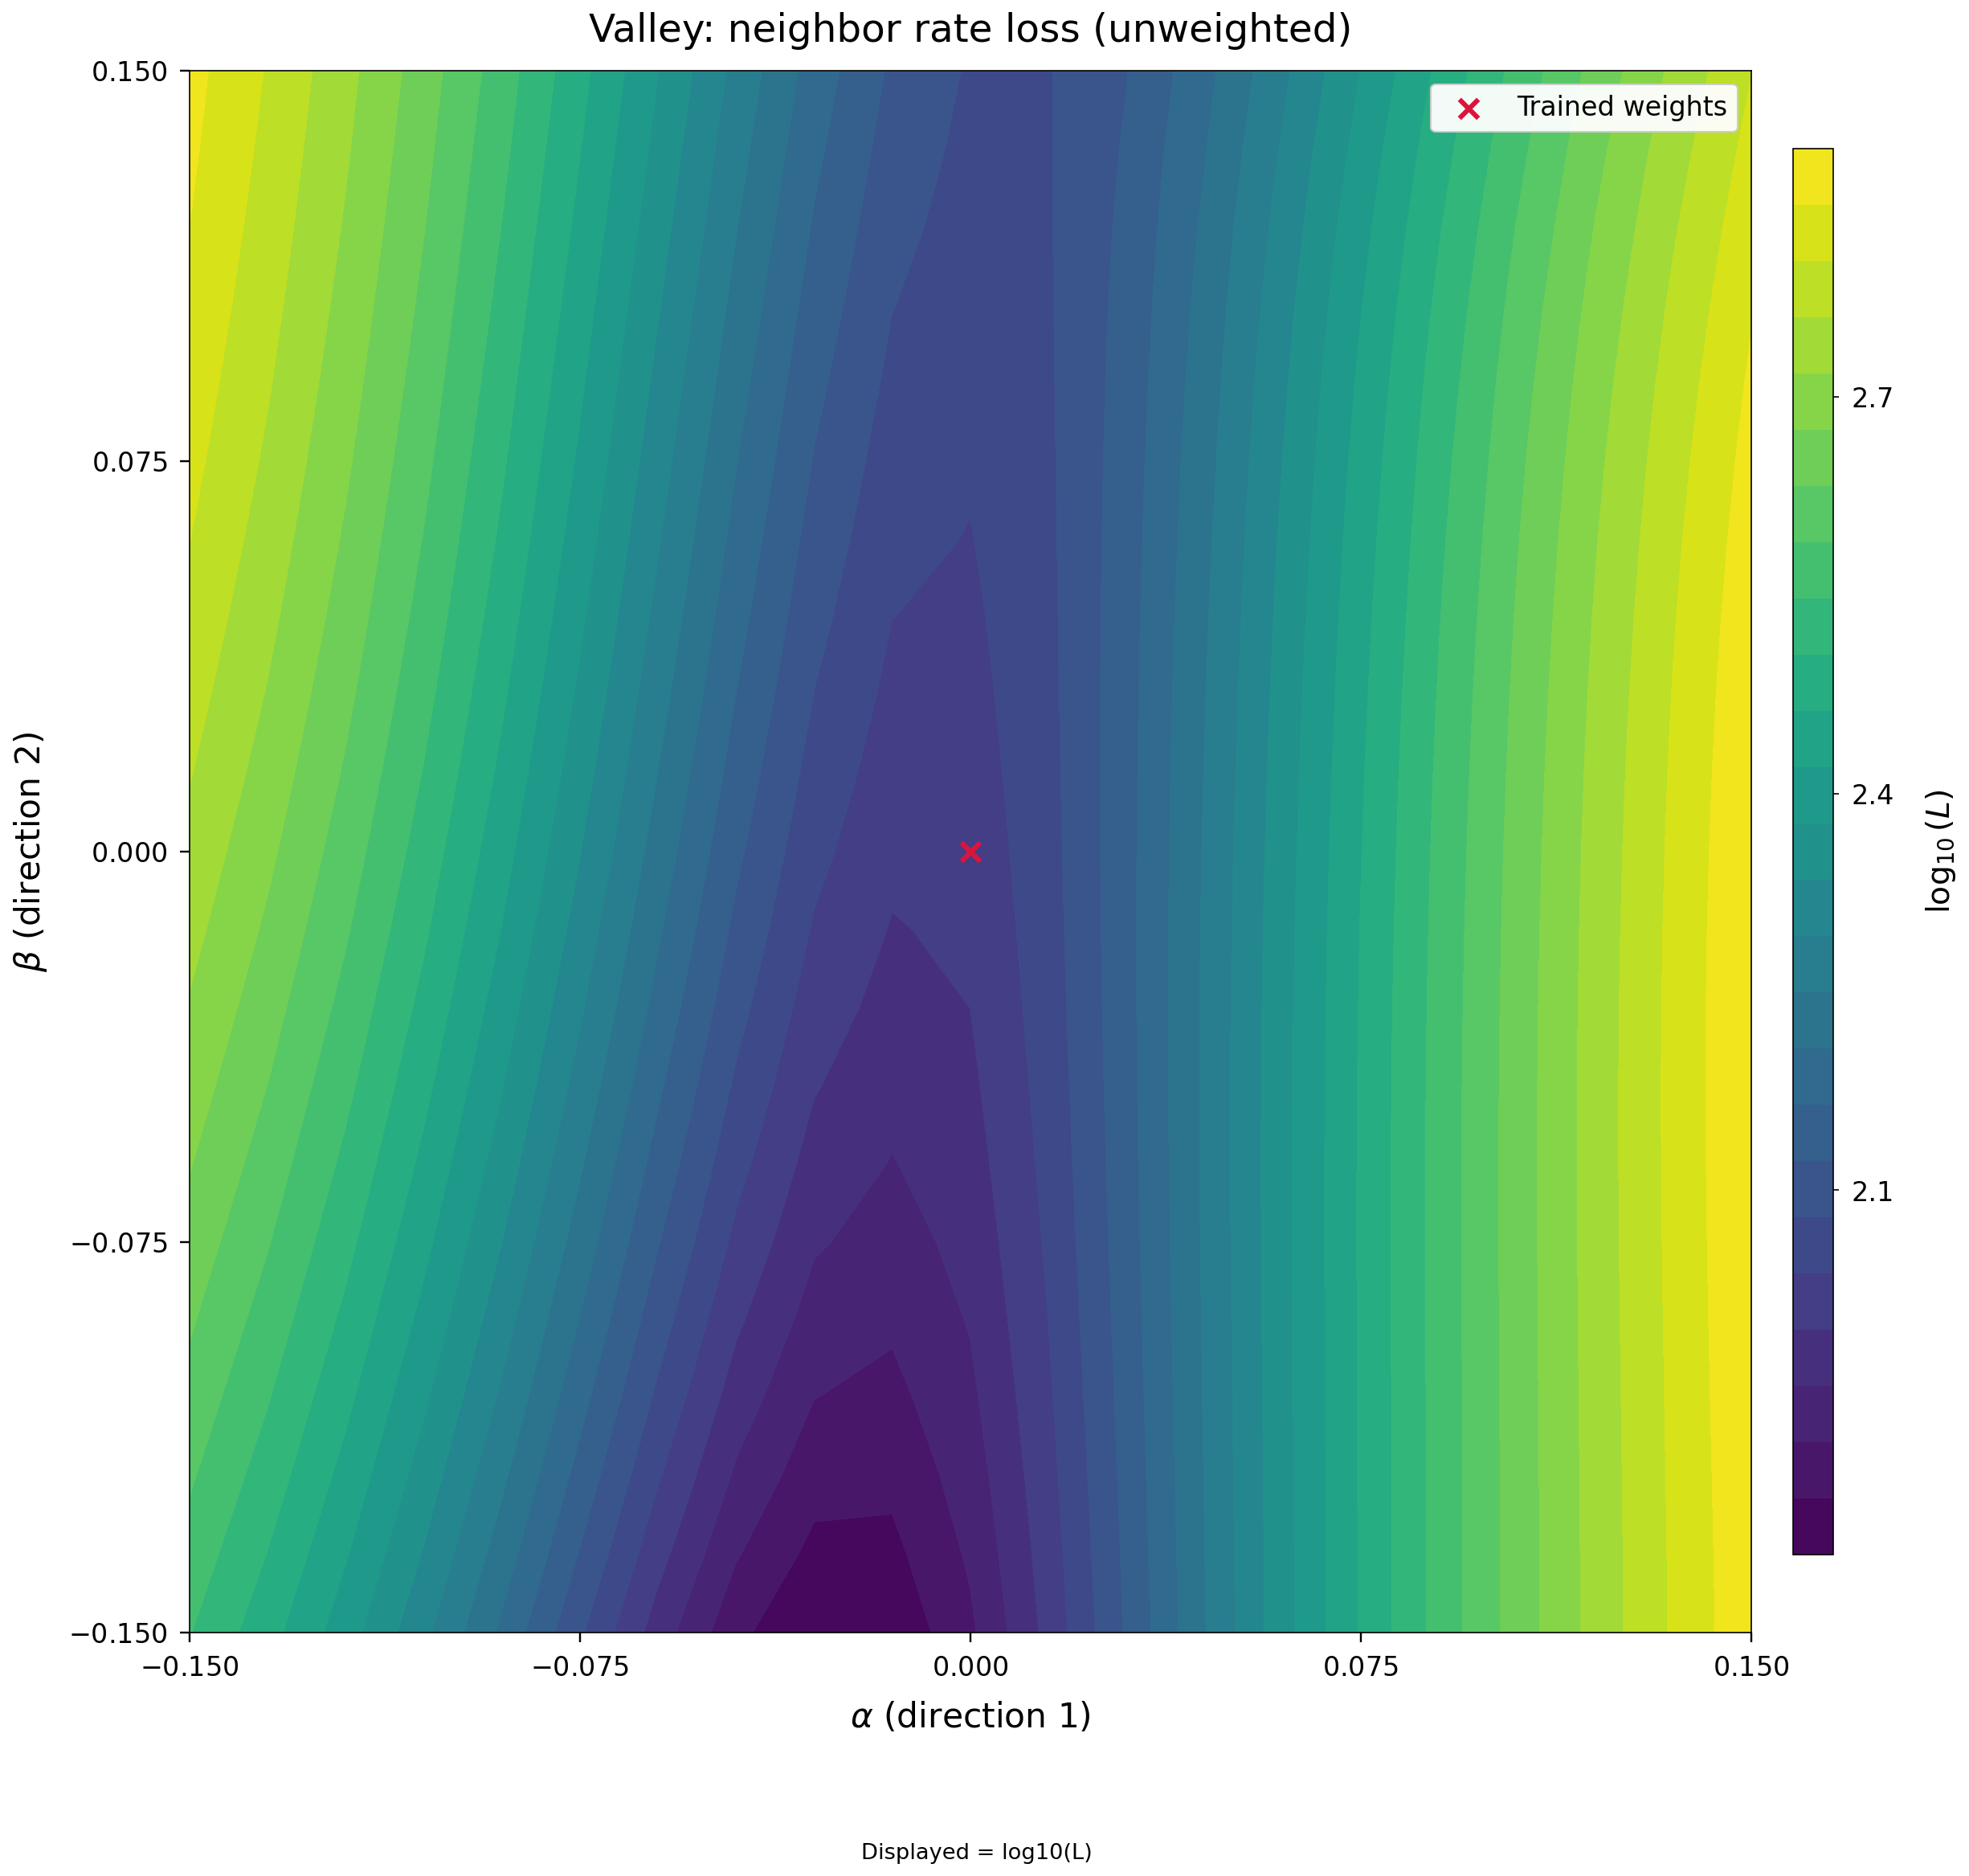

In [23]:
"""Run after the attached Valley exponential PINN training cell.

Plots a two-dimensional slice of the network's loss in weight space,
centered on the current trained weights. This is not an activation surface
or the full high-dimensional loss landscape.

Requires model, Valley, X_MIN, X_MAX, MIN_RATE, MAX_RATE,
MIN_COEFFICIENT, and MAX_COEFFICIENT from the training cell.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def _valley_kernel_directions(weights, rng):
    """Independent directions, scaled to each Dense output filter's norm.

    Only 2-D kernel matrices move. Biases and LayerNormalization parameters
    remain at their trained values. Each kernel column is an output filter.
    """
    directions = []
    for weight in weights:
        if weight.ndim == 2:
            noise = rng.standard_normal(weight.shape)
            column_norm = np.linalg.norm(weight, axis=0, keepdims=True)
            noise_norm = np.linalg.norm(noise, axis=0, keepdims=True)
            noise *= column_norm / np.maximum(noise_norm, 1e-30)
            directions.append(noise.astype(weight.dtype))
        else:
            directions.append(np.zeros_like(weight))
    return directions


def plot_valley_loss_surface(
    trained_model,
    grid_size=21,
    radius=0.15,
    n_samples=256,
    seed=12345,
    log_scale=True,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
):
    """Plot the supplied PINN objective around the trained model.

    At (alpha, beta), kernels are W0 + alpha*D1 + beta*D2.
    The center (0, 0) is the trained network. Directions are normalized
    per output filter; radius is a relative kernel perturbation scale.
    Every point uses the same fixed physics and boundary samples.

    The loss exactly follows the supplied objective:
      physics + boundary + 0.125*algebraic + 0.07*neighbor_rate.
    Its sampled values can differ from the final stochastic training loss.

    Returns coordinates, raw loss arrays, center losses, and figure handles.
    """
    if (not isinstance(grid_size, (int, np.integer))
            or grid_size < 3 or grid_size % 2 == 0):
        raise ValueError("grid_size must be an odd integer of at least 3.")
    if not np.isscalar(radius) or not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("n_samples must be a positive integer.")
    if MAX_RATE - MIN_RATE < 2:
        raise ValueError(
            "This reproduces the attached neighbor-rate rule, which requires "
            "a rate interval of width at least 2 to keep all rate pairs in bounds."
        )

    # Work on a separate model: the trained model and optimizer are untouched.
    probe_model = tf.keras.models.clone_model(trained_model)
    base_weights = trained_model.get_weights()
    probe_model.set_weights(base_weights)
    dtype = tf.as_dtype(probe_model.compute_dtype)
    numpy_dtype = dtype.as_numpy_dtype
    rng = np.random.default_rng(seed)

    # Fixed evaluation inputs eliminate resampling noise between grid points.
    def uniform(low, high):
        values = rng.uniform(low, high, (n_samples, 1)).astype(numpy_dtype)
        return tf.convert_to_tensor(values, dtype=dtype)

    x = uniform(X_MIN, X_MAX)
    rate = uniform(MIN_RATE, MAX_RATE)
    coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    boundary_rate = uniform(MIN_RATE, MAX_RATE)
    boundary_coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    x_boundary = tf.zeros_like(x)
    exact_derivative = coefficient * rate * tf.exp(rate * x)

    # Reproduce the supplied training code, including negative-A evaluations.
    one = tf.constant(1.0, dtype=dtype)
    max_rate = tf.constant(MAX_RATE, dtype=dtype)
    lower_rate = tf.where(rate <= max_rate - one, rate, rate - one)
    upper_rate = lower_rate + one

    @tf.function
    def evaluate_fixed_loss():
        def predict(x_value, rate_value, a_value):
            return probe_model(
                tf.concat([x_value, rate_value, a_value], axis=1),
                training=False,
            )

        with tf.GradientTape(watch_accessed_variables=False) as tape:
            tape.watch(x)
            u = predict(x, rate, coefficient)
        du_dx = tape.gradient(u, x)
        if du_dx is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        physics = tf.reduce_mean(tf.square(du_dx - exact_derivative))

        u_boundary = predict(x_boundary, boundary_rate, boundary_coefficient)
        boundary = tf.reduce_mean(tf.square(u_boundary - boundary_coefficient))

        u_negative = predict(x, rate, -coefficient)
        algebraic = tf.reduce_mean(tf.square(u + u_negative))

        u_lower = predict(x, lower_rate, coefficient)
        u_upper = predict(x, upper_rate, coefficient)
        neighbor = tf.reduce_mean(tf.square(u_upper - tf.exp(x) * u_lower))

        total = physics + boundary + 0.125 * algebraic + 0.07 * neighbor
        return tf.stack([total, physics, boundary, algebraic, neighbor])

    direction_1 = _valley_kernel_directions(base_weights, rng)
    direction_2 = _valley_kernel_directions(base_weights, rng)
    center_losses = evaluate_fixed_loss().numpy()
    if not np.all(np.isfinite(center_losses)):
        raise FloatingPointError("The trained model has nonfinite loss on the fixed batch.")

    coordinates = np.linspace(-radius, radius, grid_size)
    # Ensure the center is represented exactly.
    coordinates[grid_size // 2] = 0.0
    alpha_grid, beta_grid = np.meshgrid(coordinates, coordinates)
    loss_values = np.empty((5, grid_size, grid_size), dtype=np.float64)

    print(f"Evaluating {grid_size**2:,} weight settings on "
          f"{n_samples:,} fixed samples each...", flush=True)
    try:
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                if row == grid_size // 2 and column == grid_size // 2:
                    values = center_losses
                else:
                    probe_model.set_weights([
                        weight + alpha * d1 + beta * d2
                        for weight, d1, d2 in zip(
                            base_weights, direction_1, direction_2
                        )
                    ])
                    values = evaluate_fixed_loss().numpy()
                loss_values[:, row, column] = values
            print(f"Completed row {row + 1}/{grid_size}", flush=True)
    finally:
        probe_model.set_weights(base_weights)

    invalid = ~np.isfinite(loss_values)
    if np.any(invalid):
        print("Some perturbed settings had nonfinite losses; "
              "they will appear as gaps in the plots.")
    loss_values[invalid] = np.nan
    names = ["total", "physics", "boundary", "algebraic", "neighbor_rate"]
    print("\nLoss at trained weights on the fixed batch:")
    for name, value in zip(names, center_losses):
        print(f"  {name:<15} {value:.8e}")

    results = {
        "alpha": alpha_grid,
        "beta": beta_grid,
        "losses": {name: loss_values[i] for i, name in enumerate(names)},
        "center_losses": dict(zip(names, center_losses)),
        "seed": seed,
        "n_samples": n_samples,
    }
    return replot_valley_loss_surface(
        results, total_figsize=total_figsize, component_figsize=component_figsize,
        font_scale=font_scale, dpi=dpi, log_scale=log_scale,
    )


def replot_valley_loss_surface(
    results,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
    log_scale=True,
):
    """Redraw cached loss values without evaluating the model again.

    Each landscape gets its own full-size figure: one surface, one total
    contour, and four individual component contours. Figure sizes apply
    to EACH plot, rather than to a multi-panel canvas.
    font_scale optionally overrides the automatic scale (e.g. 2.5).
    Figures and colorbars use at most five major ticks per axis.
    This helper only needs NumPy and Matplotlib; no trained model is needed.
    Nearly constant losses are centered and scaled for readable ticks.
    The reference and scale are stated explicitly; raw data is unchanged.
    """
    from matplotlib.colors import Normalize
    from matplotlib.ticker import MaxNLocator, ScalarFormatter, FuncFormatter

    for size in (total_figsize, component_figsize):
        if len(size) != 2 or not np.all(np.isfinite(size)) or min(size) <= 0:
            raise ValueError("Figure sizes must contain two positive finite numbers.")
    if font_scale is not None and (not np.isfinite(font_scale) or font_scale <= 0):
        raise ValueError("font_scale must be a positive finite number.")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("dpi must be a positive finite number.")

    alpha_grid = np.asarray(results["alpha"])
    beta_grid = np.asarray(results["beta"])
    floor = 1e-16

    def display_values(values):
        values = np.asarray(values, dtype=float)
        values = np.where(np.isfinite(values), values, np.nan)
        return np.log10(np.maximum(values, floor)) if log_scale else values

    def scale_for(figsize, rows):
        if font_scale is not None:
            return float(font_scale)
        # Keep text moderate so the landscape, rather than labels, fills
        # the single-panel figure. Larger canvases mostly enlarge the data.
        return max(0.8, min(2.0, min(figsize) / 11.0))

    def format_loss_tick(value, position):
        # Explicit formatting prevents Matplotlib from generating offset text.
        if abs(value) < 1e-12:
            value = 0.0
        return f"{value:.5g}"

    def prepare_display(raw_values, raw_reference):
        values = display_values(raw_values)
        reference = float(display_values(raw_reference))
        finite_values = values[np.isfinite(values)]
        if finite_values.size == 0 or not np.isfinite(reference):
            raise FloatingPointError("No finite loss values/reference are available.")
        span = float(np.ptp(finite_values))
        quantity = r"\log_{10}(L)" if log_scale else "L"
        quantity_text = "log10(L)" if log_scale else "L"
        # Center only when loss variations are tiny compared with the reference.
        # This changes displayed units, preserving all sampled heights and order.
        centered = span < 1e-3 * max(abs(reference), 1e-16)
        offset = reference if centered else 0.0
        spread = span if centered else float(np.max(np.abs(finite_values)))
        if spread > 0 and (centered or spread >= 1e4 or spread < 1e-3):
            exponent = int(np.clip(np.floor(np.log10(spread)), -300, 300))
        else:
            exponent = 0
        unit = 10.0 ** exponent
        plotted = (values - offset) / unit
        plotted_reference = (reference - offset) / unit
        label = (r"\Delta " if centered else "") + quantity
        if exponent:
            label += rf"\,/\,10^{{{exponent}}}"
        label = "$" + label + "$"
        if centered:
            note = (f"Displayed = [{quantity_text} - {reference:.12g}]"
                    + (f" / 10^{exponent}" if exponent else "")
                    + "; reference is the trained model")
        else:
            note = (f"Displayed = {quantity_text}"
                    + (f" / 10^{exponent}" if exponent else ""))
        metadata = {"offset": offset, "scale": unit,
                    "quantity": quantity_text, "centered": centered}
        return plotted, plotted_reference, label, note, metadata

    def style_axis(ax, scale, is_3d=False):
        ax.tick_params(axis="both", labelsize=11 * scale,
                       pad=5 * scale, length=4 * scale, width=0.8 * scale)
        for axis, values in ((ax.xaxis, alpha_grid), (ax.yaxis, beta_grid)):
            ticks = np.linspace(np.nanmin(values), np.nanmax(values), 5)
            # Interior 3-D ticks avoid collisions at the front cube corner.
            axis.set_ticks(ticks[1:-1] if is_3d else ticks)
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-3, 4))
            formatter.set_useOffset(False)
            axis.set_major_formatter(formatter)
            axis.label.set_fontsize(14 * scale)
            axis.labelpad = (15 if is_3d else 8) * scale
            axis.get_offset_text().set_fontsize(10 * scale)
        if is_3d:
            ax.tick_params(axis="z", labelsize=11 * scale, pad=5 * scale)
            ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.zaxis.set_major_formatter(FuncFormatter(format_loss_tick))
            ax.zaxis.get_offset_text().set_visible(False)
            ax.zaxis.label.set_fontsize(14 * scale)
            ax.zaxis.labelpad = 17 * scale
            ax.zaxis.get_offset_text().set_fontsize(10 * scale)
            ax.set_box_aspect((1, 1, 0.8))
        ax.title.set_fontsize(16 * scale)

    def style_colorbar(fig, artist, ax, scale, label):
        colorbar = fig.colorbar(
            artist, ax=ax, shrink=0.90, fraction=0.03,
            pad=0.025, aspect=35,
        )
        colorbar.locator = MaxNLocator(nbins=4)
        colorbar.formatter = FuncFormatter(format_loss_tick)
        colorbar.update_ticks()
        colorbar.ax.yaxis.get_offset_text().set_visible(False)
        colorbar.ax.tick_params(labelsize=11 * scale, pad=5 * scale)
        colorbar.set_label(label, fontsize=13 * scale, labelpad=12 * scale)
        colorbar.ax.yaxis.get_offset_text().set_fontsize(10 * scale)
        return colorbar

    total, center, color_label, total_note, total_metadata = prepare_display(
        results["losses"]["total"], results["center_losses"]["total"]
    )
    finite = total[np.isfinite(total)]
    if finite.size == 0:
        raise FloatingPointError("No finite total loss values are available to plot.")
    vmin, vmax = float(finite.min()), float(finite.max())
    if vmin == vmax:
        margin = max(abs(vmin) * 0.01, 1e-6)
        vmin, vmax = vmin - margin, vmax + margin
    # A shared normalization makes the surface and contour colors comparable.
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 31)
    scale = scale_for(total_figsize, rows=1)

    # Each main view gets the entire canvas, rather than half a wide figure.
    fig_surface = plt.figure(figsize=total_figsize, dpi=dpi, layout="constrained")
    fig_surface.get_layout_engine().set(w_pad=0.45, h_pad=0.18)
    ax_surface = fig_surface.add_subplot(111, projection="3d", computed_zorder=False)
    surface = ax_surface.plot_surface(
        alpha_grid, beta_grid, total, cmap="viridis", norm=norm,
        edgecolor="none", alpha=0.95, antialiased=True, zorder=1,
        rcount=alpha_grid.shape[0], ccount=alpha_grid.shape[1],
    )
    ax_surface.set(xlabel=r"$\alpha$", ylabel=r"$\beta$", zlabel=color_label)
    ax_surface.set_title("Valley: total Cosine PINN loss surface", pad=12 * scale)
    ax_surface.view_init(elev=30, azim=110)
    style_axis(ax_surface, scale, is_3d=True)
    fig_surface.supxlabel(total_note, fontsize=9 * scale)

    fig_contour, ax_contour = plt.subplots(
        figsize=total_figsize, dpi=dpi, layout="constrained"
    )
    # Explicit margins avoid colorbar/aspect layout clipping of the y label.
    fig_contour.set_layout_engine(None)
    fig_contour.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
    contour = ax_contour.contourf(
        alpha_grid, beta_grid, np.ma.masked_invalid(total),
        levels=levels, cmap="viridis", norm=norm,
    )
    ax_contour.scatter(0, 0, color="crimson", marker="x", s=75 * scale**2,
                       linewidths=2 * scale, label="Trained weights")
    ax_contour.set(xlabel=r"$\alpha$ (direction 1)",
                   ylabel=r"$\beta$ (direction 2)", aspect="equal")
    ax_contour.set_title("Valley: total PINN loss contours", pad=12 * scale)
    style_axis(ax_contour, scale)
    ax_contour.legend(fontsize=11 * scale, framealpha=0.95)
    style_colorbar(fig_contour, contour, ax_contour, scale, color_label)
    fig_contour.supxlabel(total_note, fontsize=9 * scale)

    component_keys = ["physics", "boundary", "algebraic", "neighbor_rate"]
    component_names = ["Physics", "Boundary", "Algebraic", "Neighbor rate"]
    component_scale = scale_for(component_figsize, rows=1)
    component_figures = {}
    display_metadata = {"total": total_metadata}
    for key, name in zip(component_keys, component_names):
        plotted, _, component_label, component_note, metadata = prepare_display(
            results["losses"][key], results["center_losses"][key]
        )
        display_metadata[key] = metadata
        finite_component = plotted[np.isfinite(plotted)]
        low, high = float(finite_component.min()), float(finite_component.max())
        if low == high:
            margin = max(abs(low) * 0.01, 1e-6)
            low, high = low - margin, high + margin
        fig_component, ax = plt.subplots(
            figsize=component_figsize, dpi=dpi, layout="constrained"
        )
        fig_component.set_layout_engine(None)
        fig_component.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
        contour = ax.contourf(
            alpha_grid, beta_grid, np.ma.masked_invalid(plotted),
            levels=np.linspace(low, high, 26), cmap="viridis",
        )
        ax.scatter(0, 0, color="crimson", marker="x",
                   s=60 * component_scale**2, linewidths=2 * component_scale,
                   label="Trained weights")
        ax.set(xlabel=r"$\alpha$ (direction 1)",
               ylabel=r"$\beta$ (direction 2)", aspect="equal")
        ax.set_title(f"Valley: {name.lower()} loss (unweighted)",
                     pad=12 * component_scale)
        style_axis(ax, component_scale)
        ax.legend(fontsize=11 * component_scale, framealpha=0.95)
        style_colorbar(fig_component, contour, ax, component_scale, component_label)
        fig_component.supxlabel(component_note, fontsize=9 * component_scale)
        component_figures[key] = fig_component

    print("Base quantity: log10(loss), floored at 1e-16."
          if log_scale else "Base quantity: raw loss.")
    print("Display centering/scaling is specified in each plot caption.")
    # New figure handles replace the old handles; raw sampled data is unchanged.
    # figure_total remains an alias for compatibility; the views are separate.
    results["figure_total"] = fig_surface
    results["figure_surface"] = fig_surface
    results["figure_contour"] = fig_contour
    results["figure_components"] = component_figures
    results["figures"] = [fig_surface, fig_contour, *component_figures.values()]
    results["plot_display"] = display_metadata
    plt.show()
    return results


# Reuse cached data when available; otherwise compute the surface once.
# Run AFTER the Valley exponential PINN training cell.

if "loss_surface_results" in globals():
    loss_surface_results = replot_valley_loss_surface(
        loss_surface_results,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        font_scale=None,  # Moderate text; most of each figure is the landscape.
        dpi=150,
        log_scale=True,
    )
else:
    loss_surface_results = plot_valley_loss_surface(
        model,
        grid_size=21,
        radius=0.15,
        n_samples=256,
        seed=12345,
        log_scale=True,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        dpi=150,
    )


In [8]:
import numpy as np
import tensorflow as tf


def test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
):
    """Evaluate the trained cosine PINN on random input triples.

    Requires the training cell's:
        DTYPE, X_MIN, X_MAX,
        MIN_AMPLITUDE, MAX_AMPLITUDE,
        MIN_FREQUENCY, MAX_FREQUENCY,
        calculate_du_dx

    Returns:
        metrics: Average, median, and maximum absolute errors.
        samples: Inputs, predictions, exact values, and errors.

    Median and maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")

    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    # --------------------------------------------------------
    # 1. Generate random (x, amplitude, frequency) triples
    # --------------------------------------------------------
    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype

    x = rng.uniform(
        X_MIN,
        X_MAX,
        (n_points, 1),
    ).astype(dtype)

    amplitude = rng.uniform(
        MIN_AMPLITUDE,
        MAX_AMPLITUDE,
        (n_points, 1),
    ).astype(dtype)

    frequency = rng.uniform(
        MIN_FREQUENCY,
        MAX_FREQUENCY,
        (n_points, 1),
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # --------------------------------------------------------
    # 2. Evaluate predictions and automatic derivatives
    # --------------------------------------------------------
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)

        u_batch, du_batch = calculate_du_dx(
            x[start:stop],
            amplitude[start:stop],
            frequency[start:stop],
            training=False,
        )

        if du_batch is None:
            raise RuntimeError(
                "The model derivative with respect to x is unavailable."
            )

        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # --------------------------------------------------------
    # 3. Exact cosine function and derivative
    #
    # u(x, A, b) = A*cos(b*x)
    # du/dx      = -A*b*sin(b*x)
    # --------------------------------------------------------
    u_exact = amplitude * np.cos(frequency * x)

    du_dx_exact = (
        -amplitude
        * frequency
        * np.sin(frequency * x)
    )

    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (
        np.isfinite(function_error).all()
        and np.isfinite(derivative_error).all()
    ):
        raise FloatingPointError(
            "Nonfinite predictions or errors encountered."
        )

    # --------------------------------------------------------
    # 4. Error metrics
    # Original labels retained; median and maximum summarize
    # pointwise absolute errors rather than mean errors.
    # --------------------------------------------------------
    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(
        f"Random cosine inference points: {n_points:,} | "
        f"Seed: {seed}"
    )

    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()

        print(f"{name:<30} {value:.10e}")

    # --------------------------------------------------------
    # 5. Return all sampled inputs and results
    # Each array has one entry per sampled point.
    # --------------------------------------------------------
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }

    return metrics, samples


# Run after your cosine model has finished training.
metrics, samples = test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
)

Random cosine inference points: 100,000 | Seed: 12345

Average function MAE           6.1676972119e-03
Average derivative MAE         1.1668041255e-02

Median function MAE            4.5448472455e-03
Median derivative MAE          8.2838366971e-03

Maximum function MAE           9.9883475908e-02
Maximum derivative MAE         8.5125738260e-01


<h1> Regular Cosine </h1>

Epoch:     1 | Total: 2.827285e+01 | Physics: 1.565381e+01 | Boundary: 1.182845e+01 | Amplitude: 4.241362e+00 | Even: 2.604158e+00
Epoch:   500 | Total: 9.563706e-02 | Physics: 8.211974e-02 | Boundary: 4.957278e-03 | Amplitude: 2.998486e-02 | Even: 4.811925e-02
Epoch:  1000 | Total: 6.870335e-02 | Physics: 5.399666e-02 | Boundary: 6.608480e-03 | Amplitude: 5.161283e-02 | Even: 1.646598e-02
Epoch:  1500 | Total: 3.747264e-02 | Physics: 3.402149e-02 | Boundary: 1.950654e-03 | Amplitude: 8.200136e-03 | Even: 4.754737e-03
Epoch:  2000 | Total: 1.480124e-02 | Physics: 1.258530e-02 | Boundary: 2.319414e-04 | Amplitude: 8.607618e-03 | Even: 9.080407e-03
Epoch:  2500 | Total: 2.090101e-02 | Physics: 1.828140e-02 | Boundary: 3.216539e-04 | Amplitude: 1.115940e-02 | Even: 9.030292e-03
Epoch:  3000 | Total: 1.173364e-02 | Physics: 9.986791e-03 | Boundary: 8.820251e-04 | Amplitude: 5.311070e-03 | Even: 2.009441e-03
Epoch:  3500 | Total: 1.224038e-02 | Physics: 8.466697e-03 | Boundary: 2.010813e-03

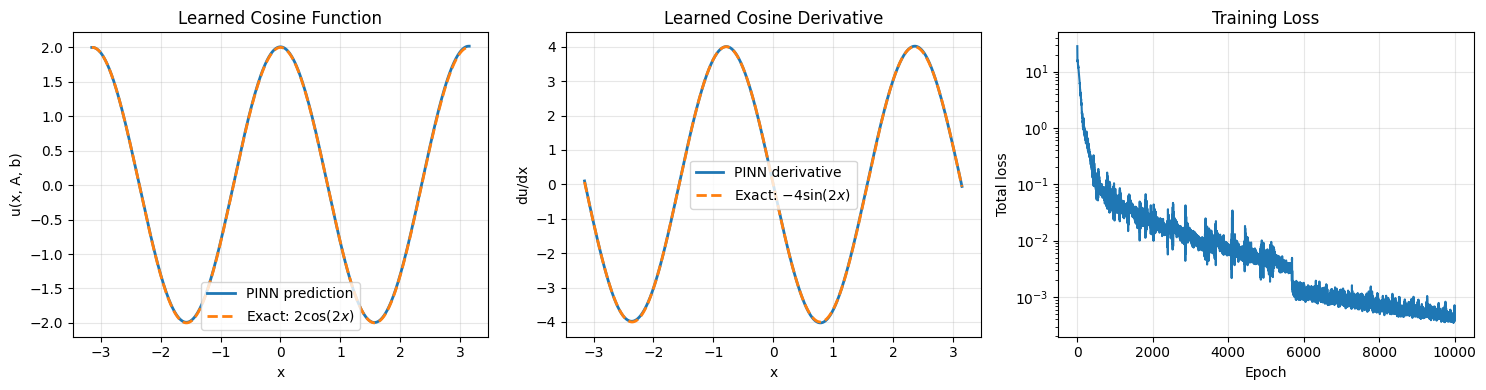


Test function: 2 * cos(2 * x)
Test amplitude: 2
Test frequency: 2

Results at x = 1
Predicted function value: -8.3389712489e-01
True function value:      -8.3229367309e-01
Predicted derivative:     -3.6514785991e+00
True derivative:          -3.6371897073e+00

Function mean absolute error:   7.815346e-03
Derivative mean absolute error: 8.965634e-03


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_1                    │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_2                    │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_3                    │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_norm_4                    │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)


Saved model to: cosine_valley_normalized.keras


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# Target: u(x, A, b) = A*cos(b*x)
# ------------------------------------------------------------
tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")
DTYPE = tf.float64
tf.random.set_seed(42)
np.random.seed(42)

MIN_AMPLITUDE, MAX_AMPLITUDE = -5.10, 5.10
MIN_FREQUENCY, MAX_FREQUENCY = 0.5, 3.0
X_MIN, X_MAX = -3.16, 3.16
BATCH_SIZE = 10000
EPOCHS = 10000
MODEL_PATH = "cosine_valley_normalized.keras"

# ------------------------------------------------------------
# 2. Valley activation and normalized network
# Inputs: [x, amplitude, frequency]
# ------------------------------------------------------------
@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return x**3 * tf.tanh(x) * sech_x

    def get_config(self):
        return super().get_config()


def build_model():
    dtype = tf.float64
    layers = [tf.keras.layers.Input(shape=(3,), dtype=dtype)]

    for index, units in enumerate((256, 128, 96, 32), start=1):
        layers.extend([
            tf.keras.layers.Dense(
                units,
                activation = "swish",
                kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
                ),
                dtype=dtype,
                name=f"dense_{index}",
            ),
            # Normalize over hidden features separately for each sample.
            # Unlike batch normalization, this does not couple samples.
            tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=dtype,
                name=f"layer_norm_{index}",
            )
        ])

    layers.append(tf.keras.layers.Dense(1, dtype=dtype, name="output"))
    return tf.keras.Sequential(layers)


model = build_model()


def predict_u(x, amplitude, frequency, training=True):
    model_input = tf.concat([
        tf.cast(x, DTYPE),
        tf.cast(amplitude, DTYPE),
        tf.cast(frequency, DTYPE),
    ], axis=1)
    return model(model_input, training=training)


# ------------------------------------------------------------
# 3. Randomized training points
# ------------------------------------------------------------
def generate_training_batch(batch_size):
    shape = (batch_size, 1)
    x = tf.random.uniform(shape, X_MIN, X_MAX, dtype=DTYPE)
    amplitude = tf.random.uniform(
        shape, MIN_AMPLITUDE, MAX_AMPLITUDE, dtype=DTYPE
    )
    frequency = tf.random.uniform(
        shape, MIN_FREQUENCY, MAX_FREQUENCY, dtype=DTYPE
    )
    return x, amplitude, frequency


# ------------------------------------------------------------
# 4. Function and partial derivative with A and b held fixed
# ------------------------------------------------------------
def calculate_du_dx(x, amplitude, frequency, training=True):
    x = tf.cast(x, DTYPE)
    with tf.GradientTape() as tape:
        tape.watch(x)
        u = predict_u(x, amplitude, frequency, training=training)
    du_dx = tape.gradient(u, x)
    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------
def calculate_loss():
    x, amplitude, frequency = generate_training_batch(BATCH_SIZE)
    u_pred, du_dx = calculate_du_dx(x, amplitude, frequency)

    # d/dx [A*cos(b*x)] = -A*b*sin(b*x)
    exact_derivative = (
        -amplitude * frequency * tf.sin(frequency * x)
    )
    physics_loss = tf.reduce_mean(tf.square(du_dx - exact_derivative))

    # Boundary condition: u(0, A, b) = A
    u_boundary = predict_u(tf.zeros_like(x), amplitude, frequency)
    boundary_loss = tf.reduce_mean(tf.square(u_boundary - amplitude))

    # Amplitude consistency: u(x, A, b) + u(x, -A, b) = 0
    u_negative_a = predict_u(x, -amplitude, frequency)
    algebraic_loss = tf.reduce_mean(tf.square(u_pred + u_negative_a))

    # Cosine is even in x: u(x, A, b) = u(-x, A, b)
    u_negative_x = predict_u(-x, amplitude, frequency)
    cosine_even_loss = tf.reduce_mean(tf.square(u_pred - u_negative_x))

    total_loss = (
        physics_loss
        + boundary_loss
        + 0.125 * algebraic_loss
        + 0.10 * cosine_even_loss
    )
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------
learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS,
    decay_rate=0.1,
    staircase=False,
)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm=1.0,
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        (total_loss, physics_loss, boundary_loss,
         algebraic_loss, cosine_even_loss) = calculate_loss()
    gradients = tape.gradient(total_loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return total_loss, physics_loss, boundary_loss, algebraic_loss, cosine_even_loss


# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------
loss_history = []
for epoch in range(1, EPOCHS + 1):
    (total_loss, physics_loss, boundary_loss,
     algebraic_loss, cosine_even_loss) = train_step()
    loss_history.append(float(total_loss.numpy()))

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Amplitude: {algebraic_loss.numpy():.6e} | "
            f"Even: {cosine_even_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Evaluate a selected amplitude and frequency
# ------------------------------------------------------------
test_a = 2.0
test_b = 2.0
x_test = tf.reshape(tf.linspace(
    tf.constant(-3.15, dtype=DTYPE),
    tf.constant(3.15, dtype=DTYPE),
    1000,
), (-1, 1))
a_test = tf.fill(tf.shape(x_test), tf.cast(test_a, DTYPE))
b_test = tf.fill(tf.shape(x_test), tf.cast(test_b, DTYPE))

u_pred, du_dx_pred = calculate_du_dx(
    x_test, a_test, b_test, training=False
)
x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

u_exact = test_a * np.cos(test_b * x_numpy)
du_dx_exact = -test_a * test_b * np.sin(test_b * x_numpy)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(x_numpy, u_numpy, linewidth=2, label="PINN prediction")
axes[0].plot(
    x_numpy, u_exact, "--", linewidth=2,
    label=fr"Exact: ${test_a:g}\cos({test_b:g}x)$",
)
axes[0].set(xlabel="x", ylabel="u(x, A, b)", title="Learned Cosine Function")
axes[0].legend()

axes[1].plot(x_numpy, du_dx_numpy, linewidth=2, label="PINN derivative")
axes[1].plot(
    x_numpy, du_dx_exact, "--", linewidth=2,
    label=fr"Exact: ${-test_a * test_b:g}\sin({test_b:g}x)$",
)
axes[1].set(xlabel="x", ylabel="du/dx", title="Learned Cosine Derivative")
axes[1].legend()

axes[2].semilogy(np.arange(1, len(loss_history) + 1), loss_history)
axes[2].set(xlabel="Epoch", ylabel="Total loss", title="Training Loss")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy and explicit evaluation at x = 1
# ------------------------------------------------------------
function_mae = np.mean(np.abs(u_numpy - u_exact))
derivative_mae = np.mean(np.abs(du_dx_numpy - du_dx_exact))

x_one = tf.constant([[1.0]], dtype=DTYPE)
u_one, du_one = calculate_du_dx(
    x_one,
    tf.fill(tf.shape(x_one), tf.cast(test_a, DTYPE)),
    tf.fill(tf.shape(x_one), tf.cast(test_b, DTYPE)),
    training=False,
)
true_u_one = test_a * np.cos(test_b)
true_du_one = -test_a * test_b * np.sin(test_b)

print(f"\nTest function: {test_a:g} * cos({test_b:g} * x)")
print(f"Test amplitude: {test_a:g}")
print(f"Test frequency: {test_b:g}")
print("\nResults at x = 1")
print(f"Predicted function value: {u_one.numpy().item():.10e}")
print(f"True function value:      {true_u_one:.10e}")
print(f"Predicted derivative:     {du_one.numpy().item():.10e}")
print(f"True derivative:          {true_du_one:.10e}")
print(f"\nFunction mean absolute error:   {function_mae:.6e}")
print(f"Derivative mean absolute error: {derivative_mae:.6e}")
model.summary()
model.save(MODEL_PATH)
print(f"\nSaved model to: {MODEL_PATH}")


In [ ]:
import numpy as np
import tensorflow as tf


def test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
):
    """Evaluate the trained cosine PINN on random input triples.

    Requires the training cell's:
        DTYPE, X_MIN, X_MAX,
        MIN_AMPLITUDE, MAX_AMPLITUDE,
        MIN_FREQUENCY, MAX_FREQUENCY,
        calculate_du_dx

    Returns:
        metrics: Average, median, and maximum absolute errors.
        samples: Inputs, predictions, exact values, and errors.

    Median and maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")

    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    # --------------------------------------------------------
    # 1. Generate random (x, amplitude, frequency) triples
    # --------------------------------------------------------
    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype

    x = rng.uniform(
        X_MIN,
        X_MAX,
        (n_points, 1),
    ).astype(dtype)

    amplitude = rng.uniform(
        MIN_AMPLITUDE,
        MAX_AMPLITUDE,
        (n_points, 1),
    ).astype(dtype)

    frequency = rng.uniform(
        MIN_FREQUENCY,
        MAX_FREQUENCY,
        (n_points, 1),
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # --------------------------------------------------------
    # 2. Evaluate predictions and automatic derivatives
    # --------------------------------------------------------
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)

        u_batch, du_batch = calculate_du_dx(
            x[start:stop],
            amplitude[start:stop],
            frequency[start:stop],
            training=False,
        )

        if du_batch is None:
            raise RuntimeError(
                "The model derivative with respect to x is unavailable."
            )

        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # --------------------------------------------------------
    # 3. Exact cosine function and derivative
    #
    # u(x, A, b) = A*cos(b*x)
    # du/dx      = -A*b*sin(b*x)
    # --------------------------------------------------------
    u_exact = amplitude * np.cos(frequency * x)

    du_dx_exact = (
        -amplitude
        * frequency
        * np.sin(frequency * x)
    )

    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (
        np.isfinite(function_error).all()
        and np.isfinite(derivative_error).all()
    ):
        raise FloatingPointError(
            "Nonfinite predictions or errors encountered."
        )

    # --------------------------------------------------------
    # 4. Error metrics
    # Original labels retained; median and maximum summarize
    # pointwise absolute errors rather than mean errors.
    # --------------------------------------------------------
    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(
        f"Random cosine inference points: {n_points:,} | "
        f"Seed: {seed}"
    )

    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()

        print(f"{name:<30} {value:.10e}")

    # --------------------------------------------------------
    # 5. Return all sampled inputs and results
    # Each array has one entry per sampled point.
    # --------------------------------------------------------
    samples = {
        "x": x.ravel(),
        "amplitude": amplitude.ravel(),
        "frequency": frequency.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }

    return metrics, samples


# Run after your cosine model has finished training.
metrics, samples = test_random_cosine_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
)

Random cosine inference points: 100,000 | Seed: 12345

Average function MAE           8.6440040894e-03
Average derivative MAE         1.3419561032e-02

Median function MAE            6.6399906054e-03
Median derivative MAE          9.5436342654e-03

Maximum function MAE           1.8384452492e-01
Maximum derivative MAE         6.4124647381e-01


<h1> Expo model </h1>

Epoch:     1 | Total: 1.489294e+03 | Physics: 1.487750e+03 | Boundary: 1.441717e+00 | Algebra: 7.921770e-01 | Neighbor Rates: 5.690257e-02
Epoch:   500 | Total: 2.590432e+02 | Physics: 2.200513e+02 | Boundary: 2.887030e+01 | Algebra: 2.780345e+01 | Neighbor Rates: 9.494504e+01
Epoch:  1000 | Total: 5.273564e+01 | Physics: 3.844818e+01 | Boundary: 8.522404e+00 | Algebra: 2.598903e+01 | Neighbor Rates: 3.594894e+01
Epoch:  1500 | Total: 1.471267e+01 | Physics: 1.016110e+01 | Boundary: 1.897064e+00 | Algebra: 1.784870e+01 | Neighbor Rates: 6.048880e+00
Epoch:  2000 | Total: 2.772261e+01 | Physics: 2.431685e+01 | Boundary: 1.127434e+00 | Algebra: 1.611293e+01 | Neighbor Rates: 3.774340e+00
Epoch:  2500 | Total: 1.398066e+01 | Physics: 1.069270e+01 | Boundary: 8.843781e-01 | Algebra: 1.752692e+01 | Neighbor Rates: 3.038894e+00
Epoch:  3000 | Total: 6.074866e+00 | Physics: 4.727831e+00 | Boundary: 2.242989e-01 | Algebra: 8.386474e+00 | Neighbor Rates: 1.063231e+00
Epoch:  3500 | Total: 3.350

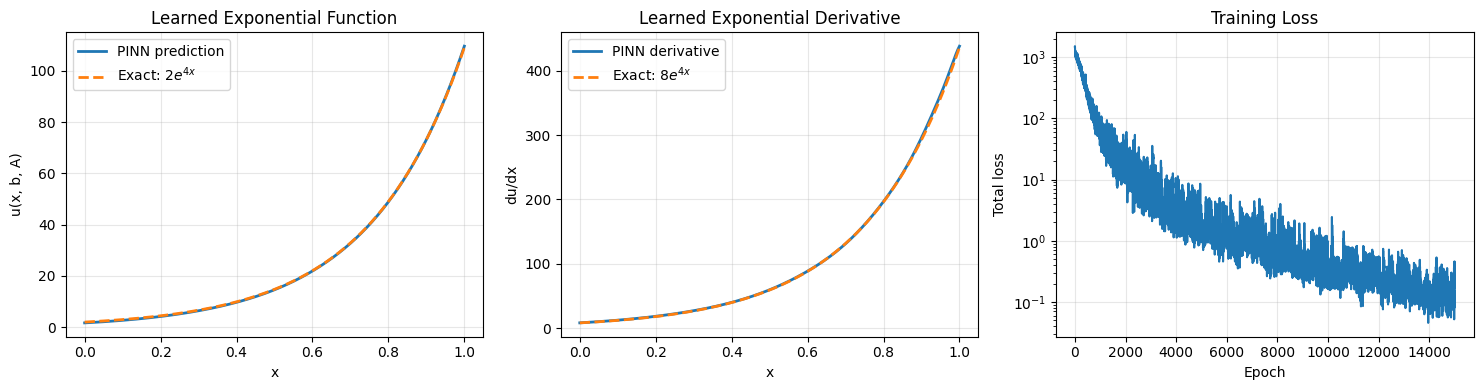


Test function:                   2 * exp(4 * x)
Test coefficient:                2
Test exponential rate:                      4

Results at x = 1
Predicted function value:        1.0968421994e+02
True function value:             1.0919630007e+02
Predicted derivative:            4.3848747650e+02
True derivative:                 4.3678520027e+02

Function mean absolute error:    1.915235e-01
Derivative mean absolute error:  8.572310e-01


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

Saved model to exponential_pinn.keras


In [26]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_RATE = 1.0
MAX_RATE = 4.1

MIN_COEFFICIENT = 0.01
MAX_COEFFICIENT = 2.10

X_MIN = 0.0
X_MAX = 1.0

BATCH_SIZE = 10000
EPOCHS = 15000


# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, rate, coefficient]
#
# Output:
#   u(x, rate, coefficient) = coefficient * exp(rate*x)
# ------------------------------------------------------------

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            activation="swish",
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE,
        ),

        tf.keras.layers.Dense(
            128,
            activation="swish",
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE,
        ),

        tf.keras.layers.Dense(
            96,
            activation="swish",
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            32,
            activation="swish",
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-0.5, maxval=0.5
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])


model = build_model()

# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    rate,
    coefficient,
    training=True
):
    """
    Predict u(x, rate, coefficient) using the neural network.

    The network is intended to learn:

        u(x, rate, coefficient)
            = coefficient * exp(rate*x)
    """

    x = tf.cast(x, DTYPE)
    rate = tf.cast(rate, DTYPE)
    coefficient = tf.cast(
        coefficient,
        DTYPE
    )

    model_input = tf.concat(
        [
            x,
            rate,
            coefficient
        ],
        axis=1
    )

    u = model(
        model_input,
        training=training
    )

    return u

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------

def generate_training_batch(batch_size):
    # Random x values
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    # Random continuous exponential rates
    rate = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_RATE,
        maxval=MAX_RATE,
        dtype=DTYPE
    )

    # Random scales
    coefficient = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_COEFFICIENT,
        maxval=MAX_COEFFICIENT,
        dtype=DTYPE
    )


    return x, rate, coefficient


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, rate, coefficient, training=True):
    x = tf.cast(x, DTYPE)
    rate = tf.cast(rate, DTYPE)
    coefficient = tf.cast(coefficient, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        model_input = tf.concat(
            [x, rate, coefficient],
            axis=1
        )

        u = model(
            model_input,
            training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, rate_physics, coefficient_physics = generate_training_batch(
        BATCH_SIZE
    )

    _, du_dx = calculate_du_dx(
        x_physics,
        rate_physics,
        coefficient_physics,
        training=True
    )

    # d/dx [A*exp(b*x)] = A*b*exp(b*x)
    exact_derivative = (
        coefficient_physics
        * rate_physics
        * tf.exp(rate_physics * x_physics)
    )

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # u(0, b, A) = A because exp(0) = 1
    # --------------------------------------------------------

    boundary_rate = tf.random.uniform(
        shape=(BATCH_SIZE, 1),
        minval=MIN_RATE,
        maxval=MAX_RATE,
        dtype=DTYPE
    )

    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )

    x_boundary = tf.zeros(
        shape=(BATCH_SIZE, 1),
        dtype=DTYPE
    )

    boundary_input = tf.concat(
        [x_boundary, boundary_rate, boundary_coefficient],
        axis=1
    )

    u_pred_boundary = model(
        boundary_input,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary - boundary_coefficient)
    )

    # --------------------------------------
    #  Coefficient sign consistency
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      rate_physics,
      coefficient_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        rate_physics,
        -coefficient_physics,
        training=True
    )

    # Enforce u(x, b, A) + u(x, b, -A) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # --------------------------------------------------------
    # Neighbor-rate consistency:
    # u(x, b + 1, A) = exp(x) * u(x, b, A)
    # Keep both queried rates inside [MIN_RATE, MAX_RATE].
    # The configured interval has width >= 2, so this selection
    # covers the full interval without leaving its bounds.
    # --------------------------------------------------------

    max_rate_tensor = tf.cast(
        MAX_RATE,
        DTYPE
    )

    one = tf.constant(
        1.0,
        dtype=DTYPE
    )

    lower_rate = tf.where(
        rate_physics <= (max_rate_tensor - one),

        # Test b -> b + 1
        rate_physics,

        # Test b - 1 -> b
        rate_physics - one
    )

    upper_rate = lower_rate + one

    u_lower_rate = predict_u(
        x_physics,
        lower_rate,
        coefficient_physics,
        training=True
    )

    u_upper_rate = predict_u(
        x_physics,
        upper_rate,
        coefficient_physics,
        training=True
    )

    expected_upper_rate = (
        tf.exp(x_physics) * u_lower_rate
    )

    neighbor_rate_residual = (
        u_upper_rate - expected_upper_rate
    )

    neighbor_rate_loss = tf.reduce_mean(
        tf.square(neighbor_rate_residual)
    )


    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.07 * neighbor_rate_loss)

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(1, EPOCHS + 1):
    total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Algebra: {algebraic_loss.numpy():.6e} | "
            f"Neighbor Rates: {neighbor_rate_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary rate
# ------------------------------------------------------------

test_rate = 4
test_a = 2

x_test = tf.linspace(
    tf.constant(0.0, dtype=DTYPE),
    tf.constant(1.0, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

rate_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_rate, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    rate_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact exponential results
u_exact = test_a * np.exp(test_rate * x_numpy)
du_dx_exact = test_a * test_rate * np.exp(test_rate * x_numpy)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: ${test_a:g}e^{{{test_rate:g}x}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, b, A)")
plt.title("Learned Exponential Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_rate}"
      fr"e^{{{test_rate:g}x}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Exponential Derivative")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(np.arange(1, len(loss_history) + 1), loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a} * exp({test_rate} * x)")
print(f"Test coefficient:                {test_a}")
print(f"Test exponential rate:                      {test_rate}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)

model.summary()
model.save("exponential_pinn.keras")
print("Saved model to exponential_pinn.keras")


Evaluating 441 weight settings on 256 fixed samples each...
Completed row 1/21
Completed row 2/21
Completed row 3/21
Completed row 4/21
Completed row 5/21
Completed row 6/21
Completed row 7/21
Completed row 8/21
Completed row 9/21
Completed row 10/21
Completed row 11/21
Completed row 12/21
Completed row 13/21
Completed row 14/21
Completed row 15/21
Completed row 16/21
Completed row 17/21
Completed row 18/21
Completed row 19/21
Completed row 20/21
Completed row 21/21

Loss at trained weights on the fixed batch:
  total           6.12274256e-01
  physics         3.13706077e-01
  boundary        1.01030716e-02
  algebraic       2.30376715e+00
  neighbor_rate   7.06018522e-03
Base quantity: log10(loss), floored at 1e-16.
Display centering/scaling is specified in each plot caption.


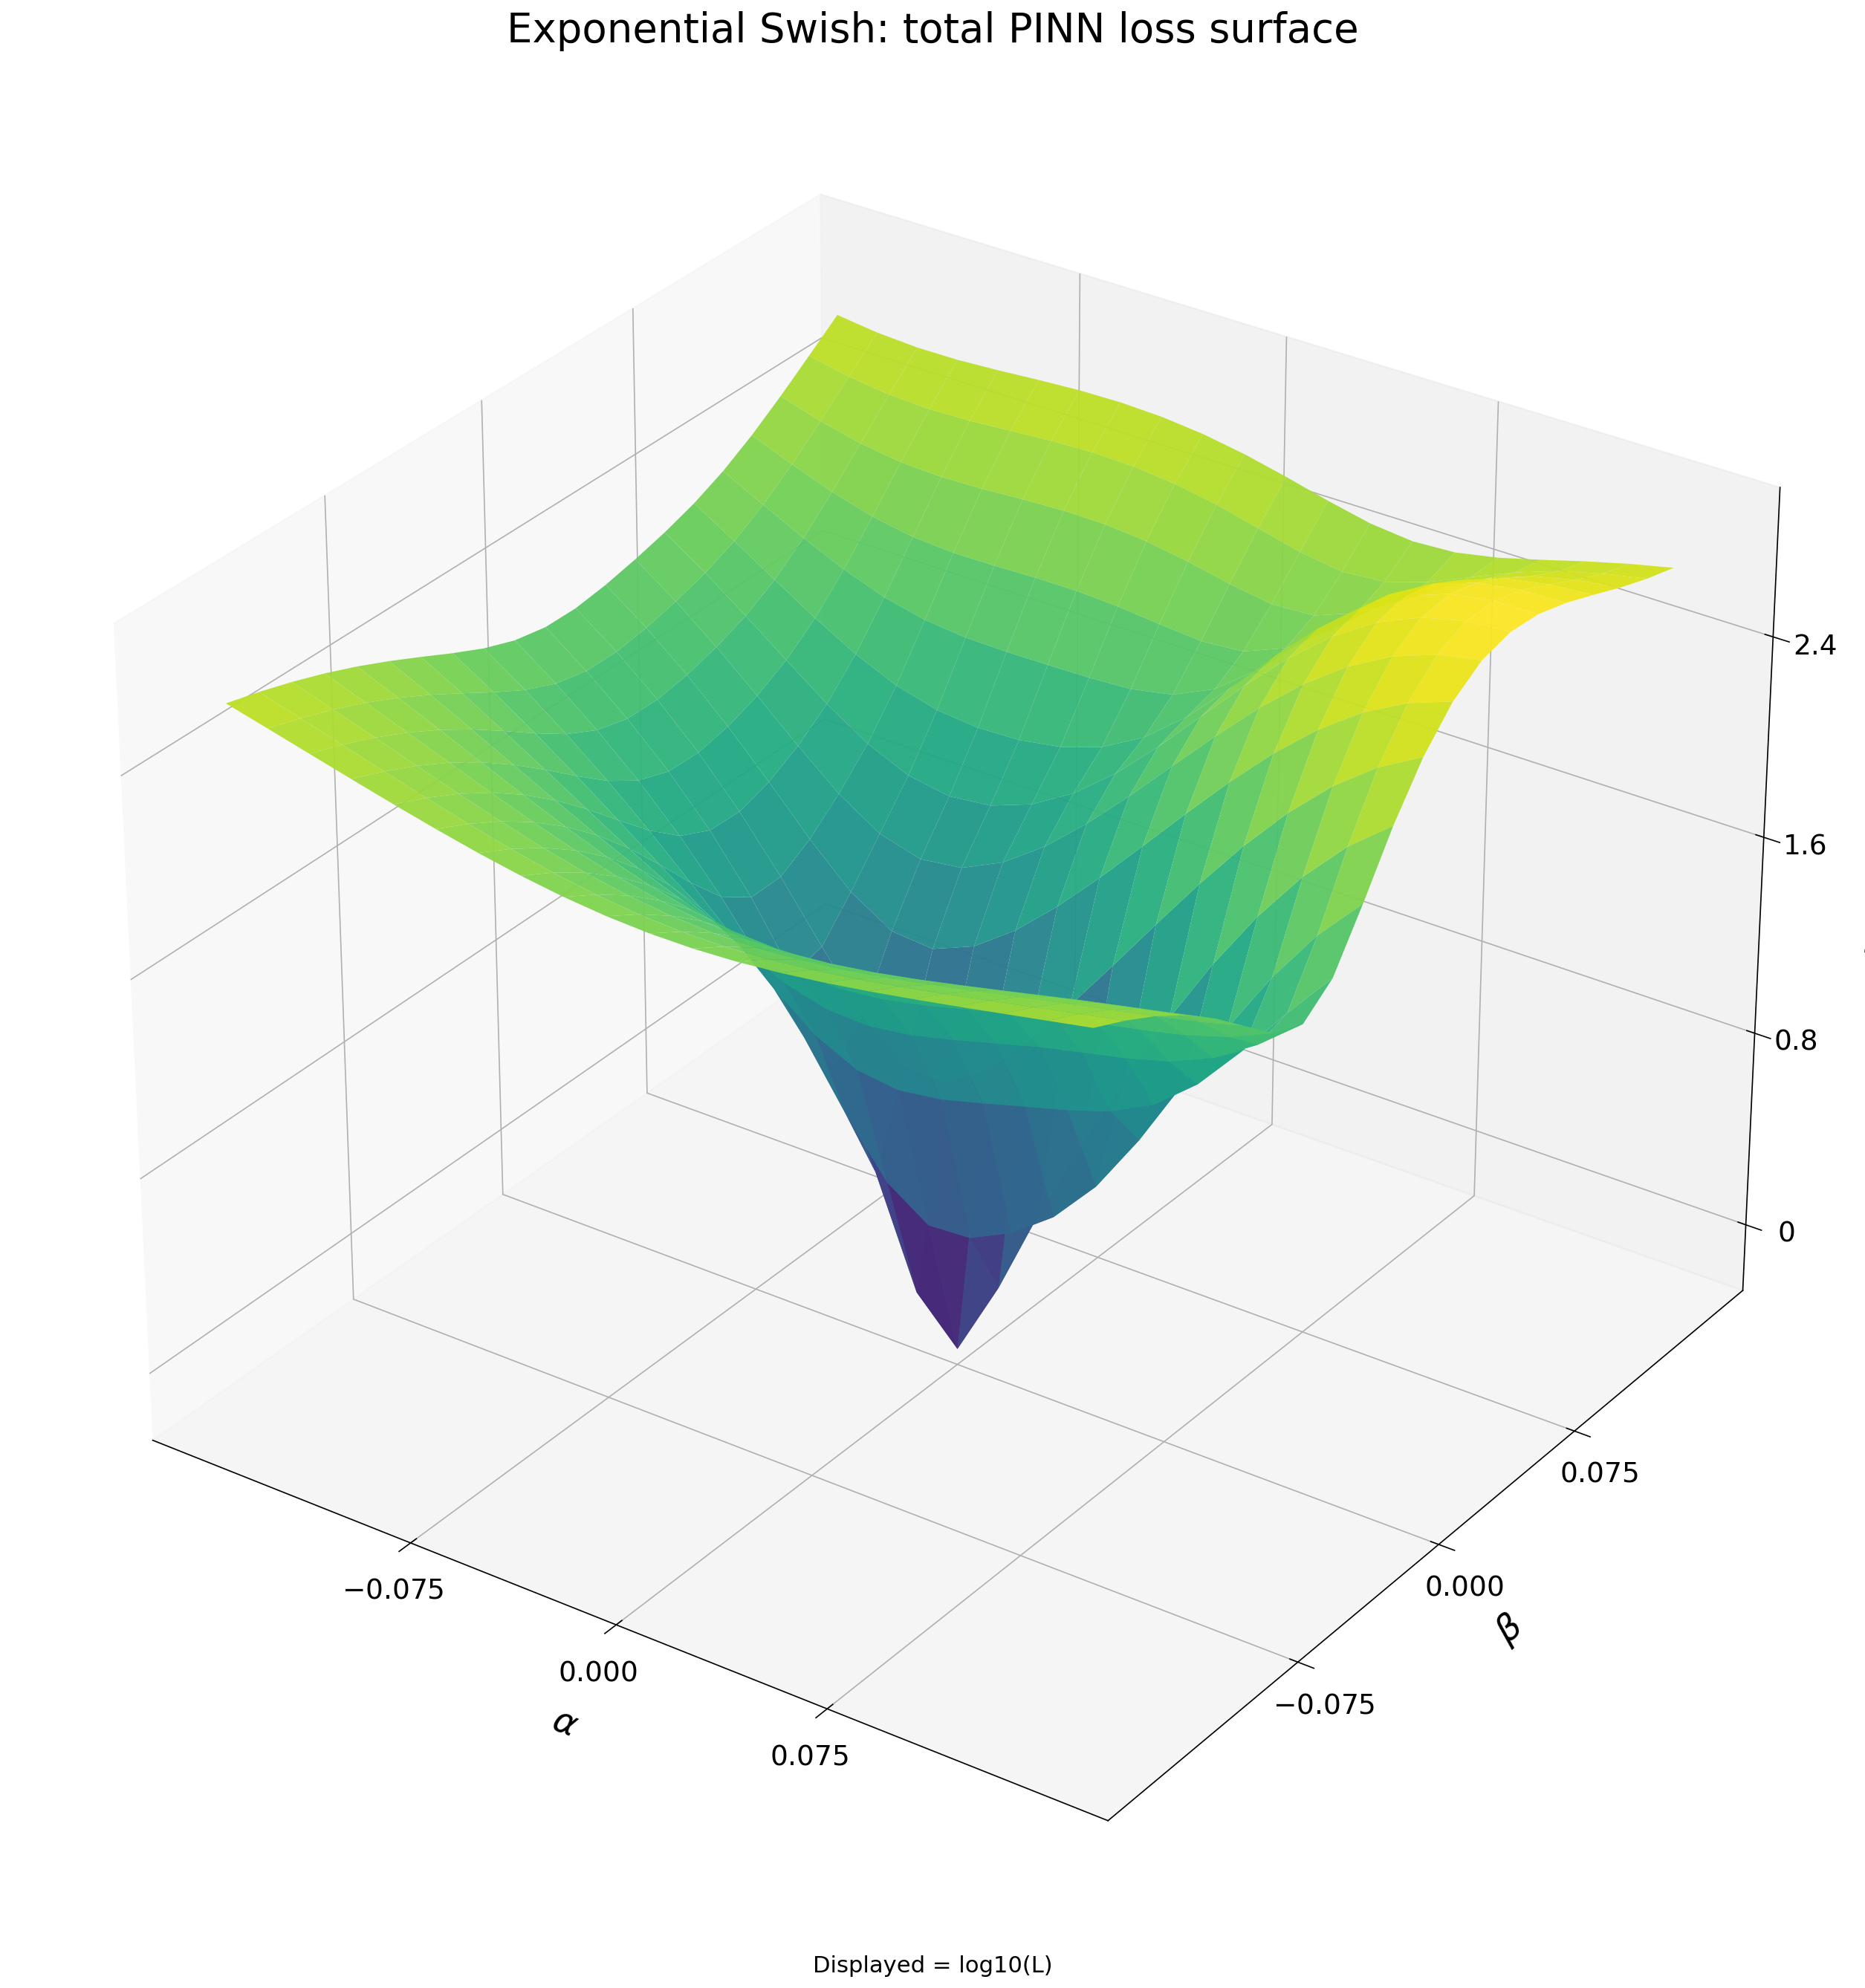

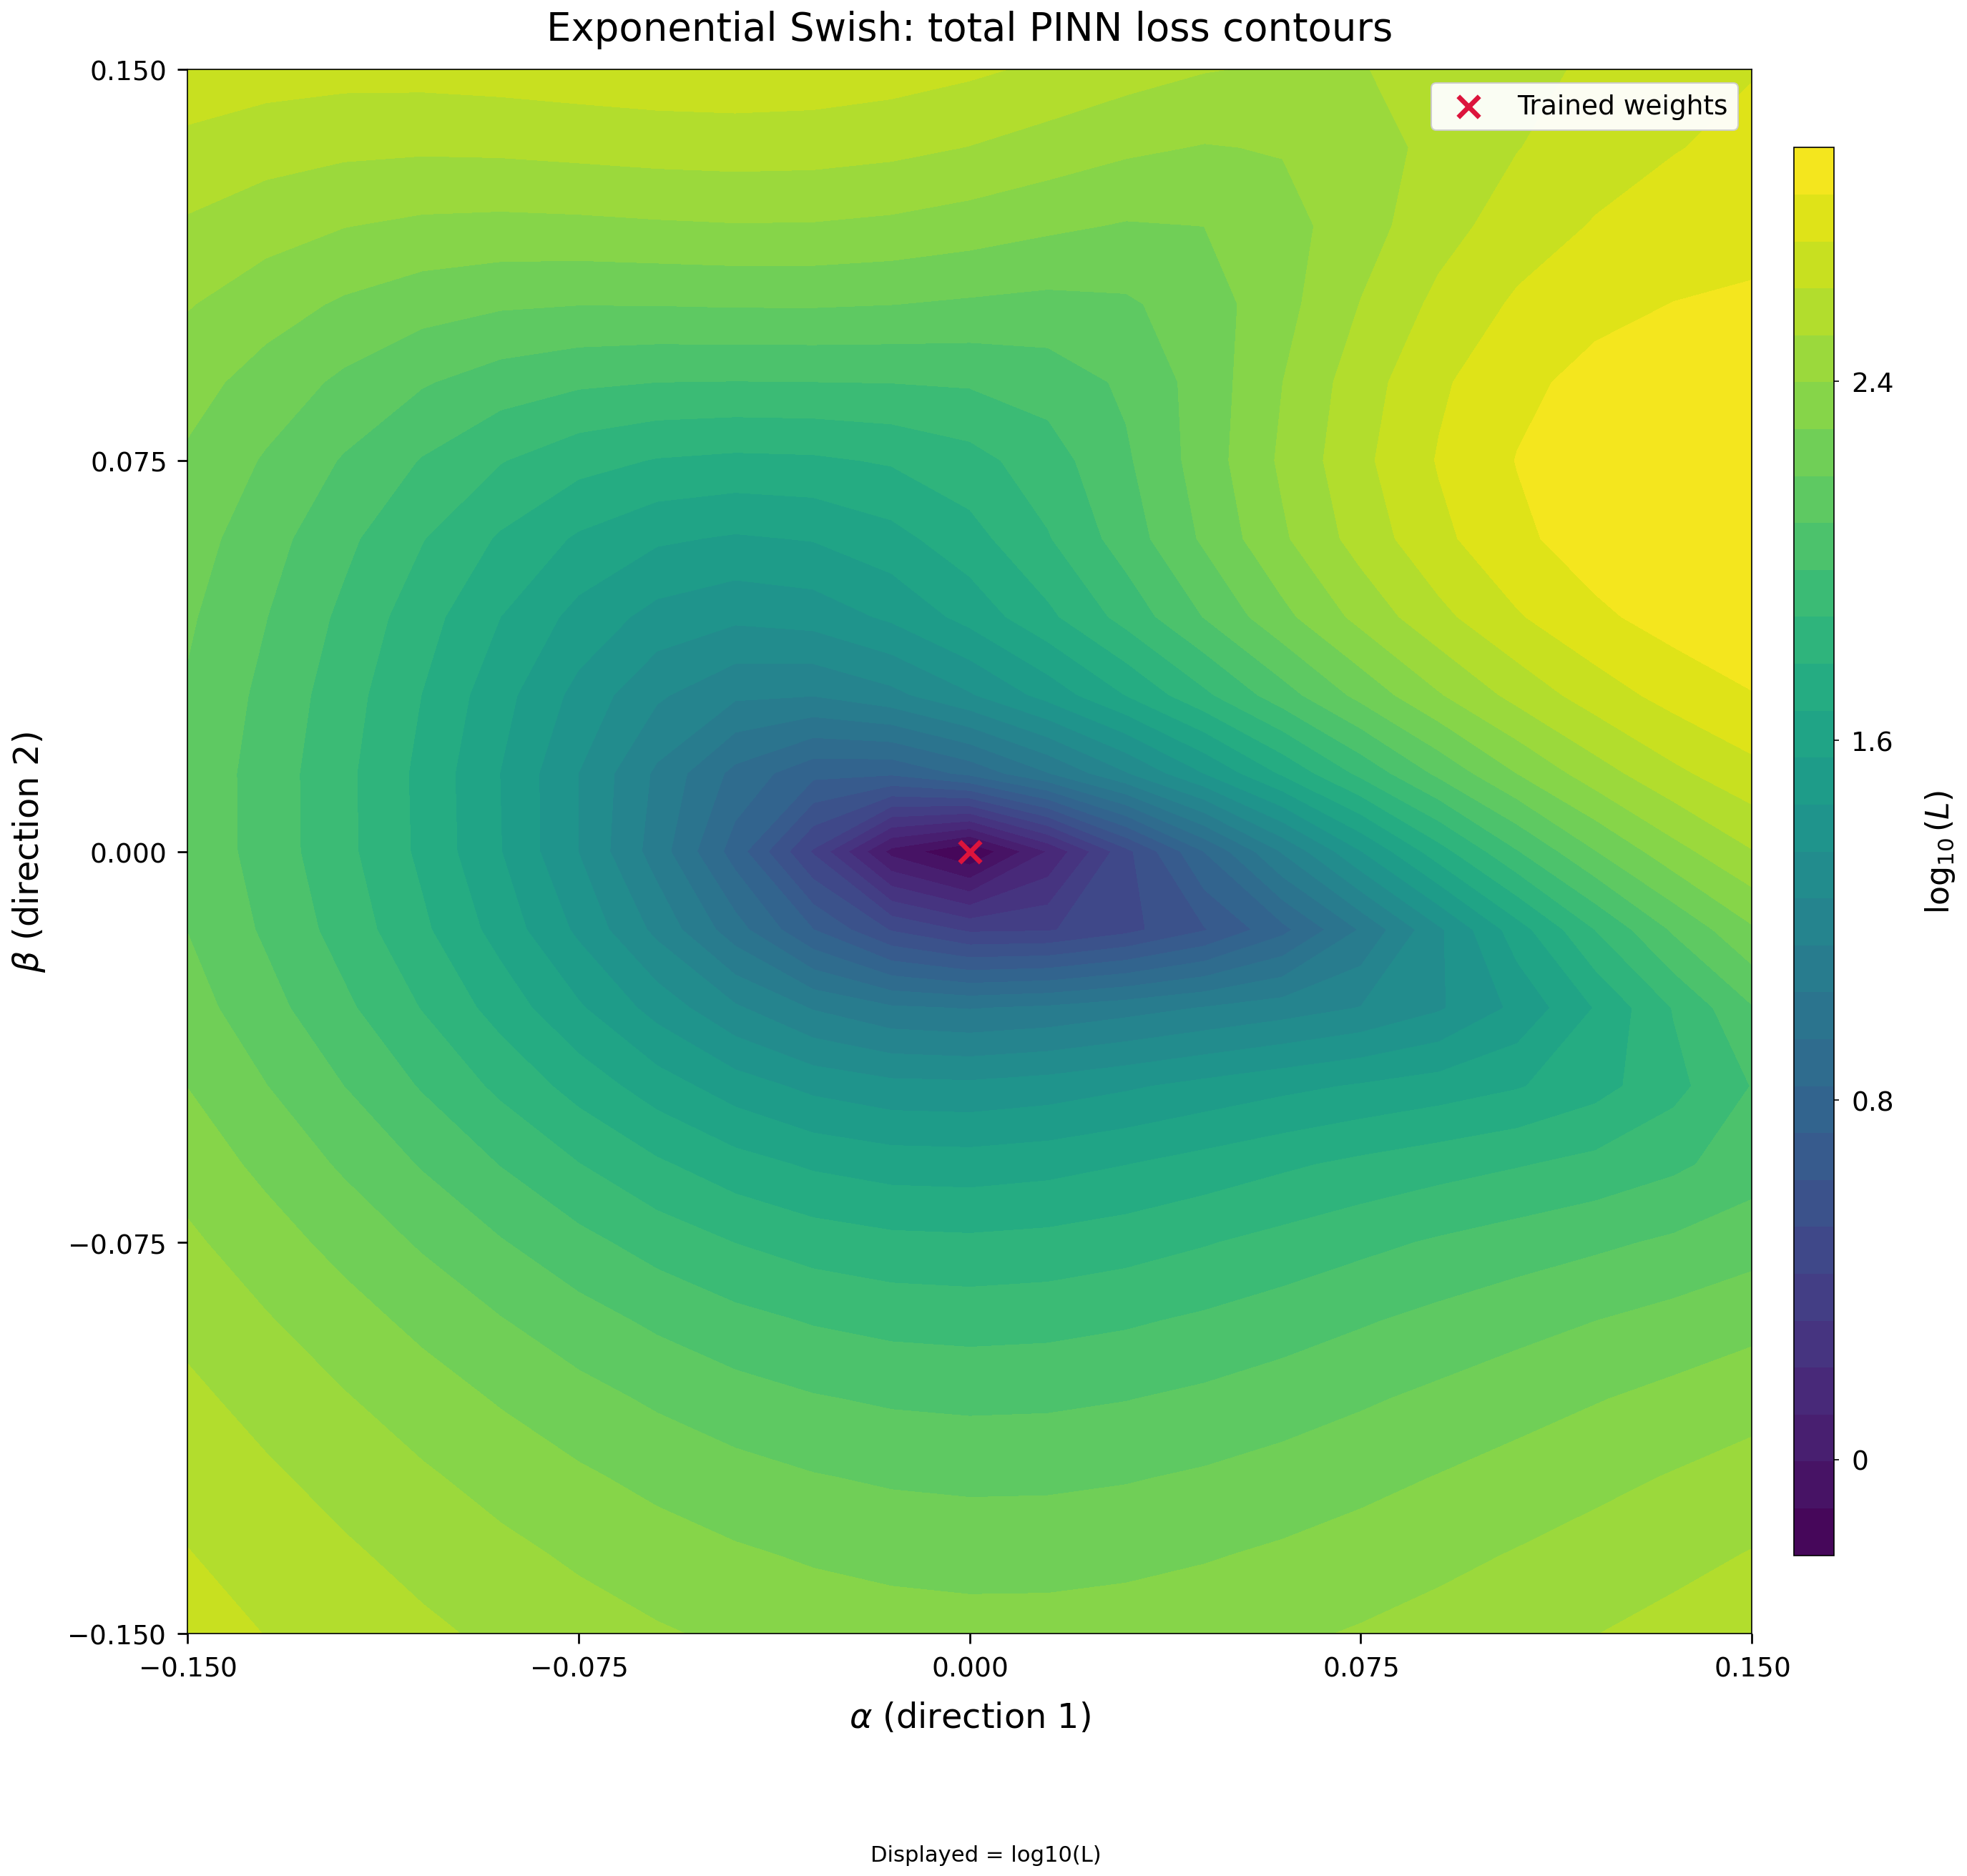

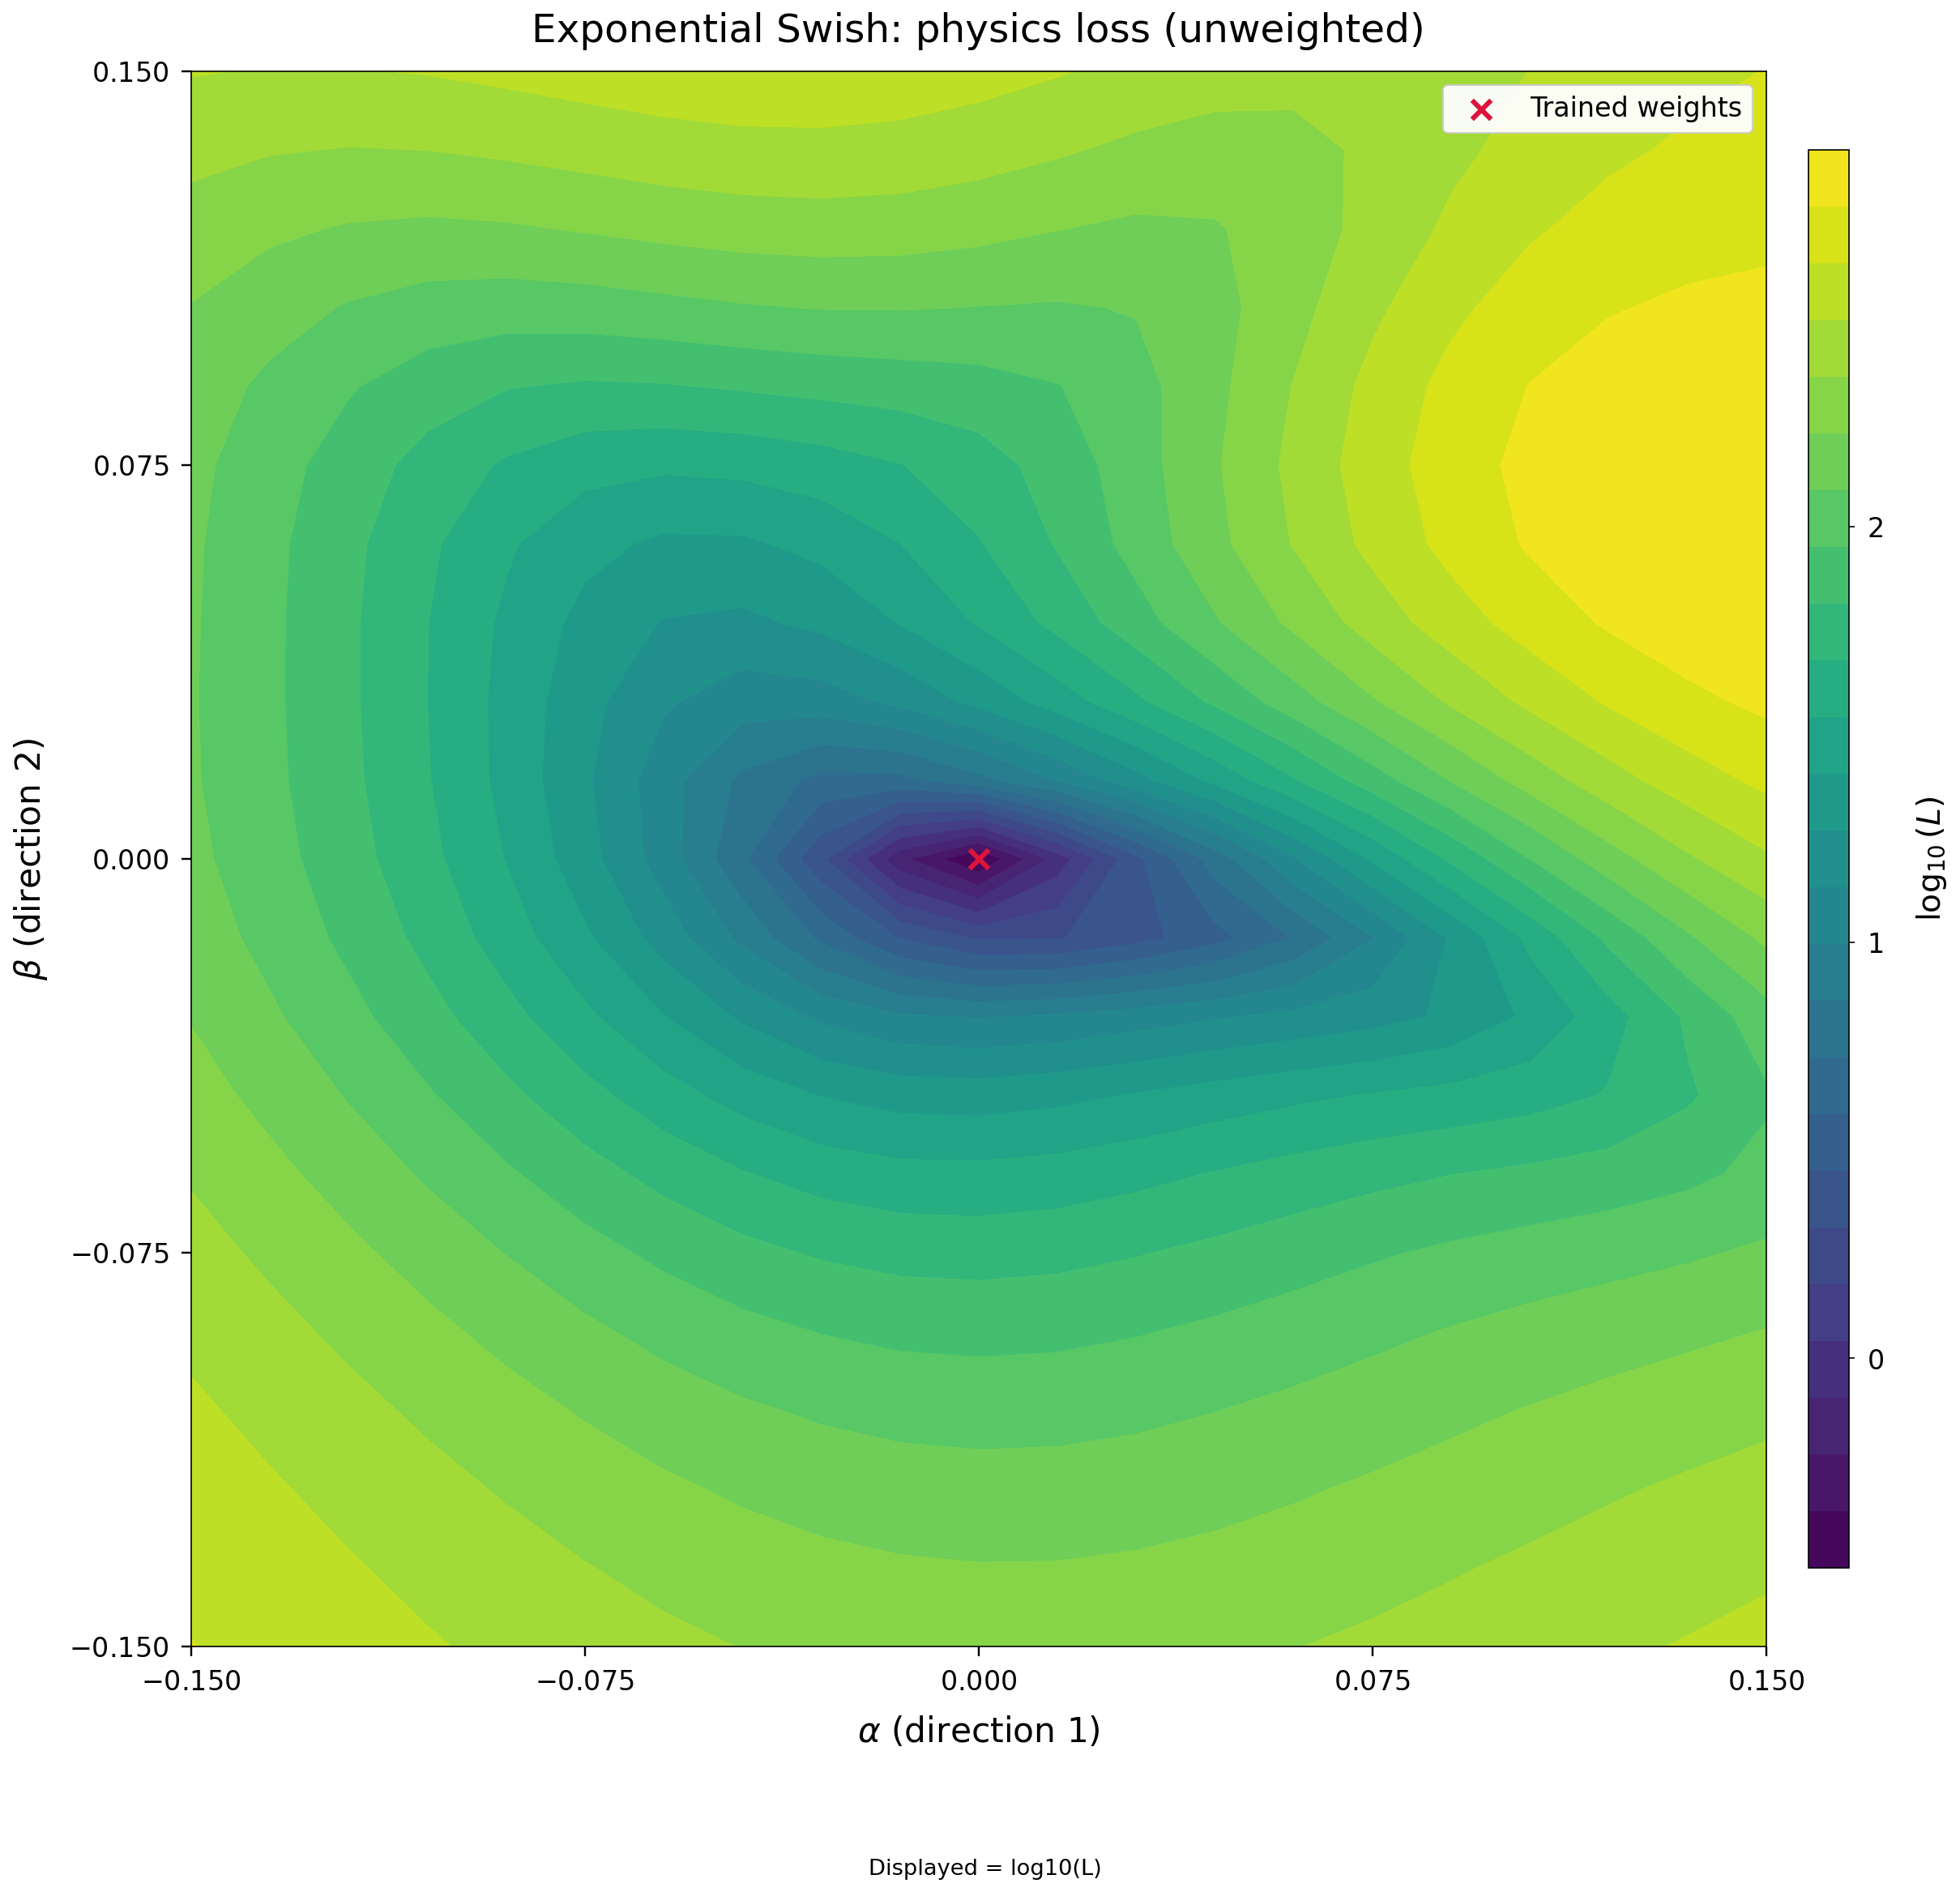

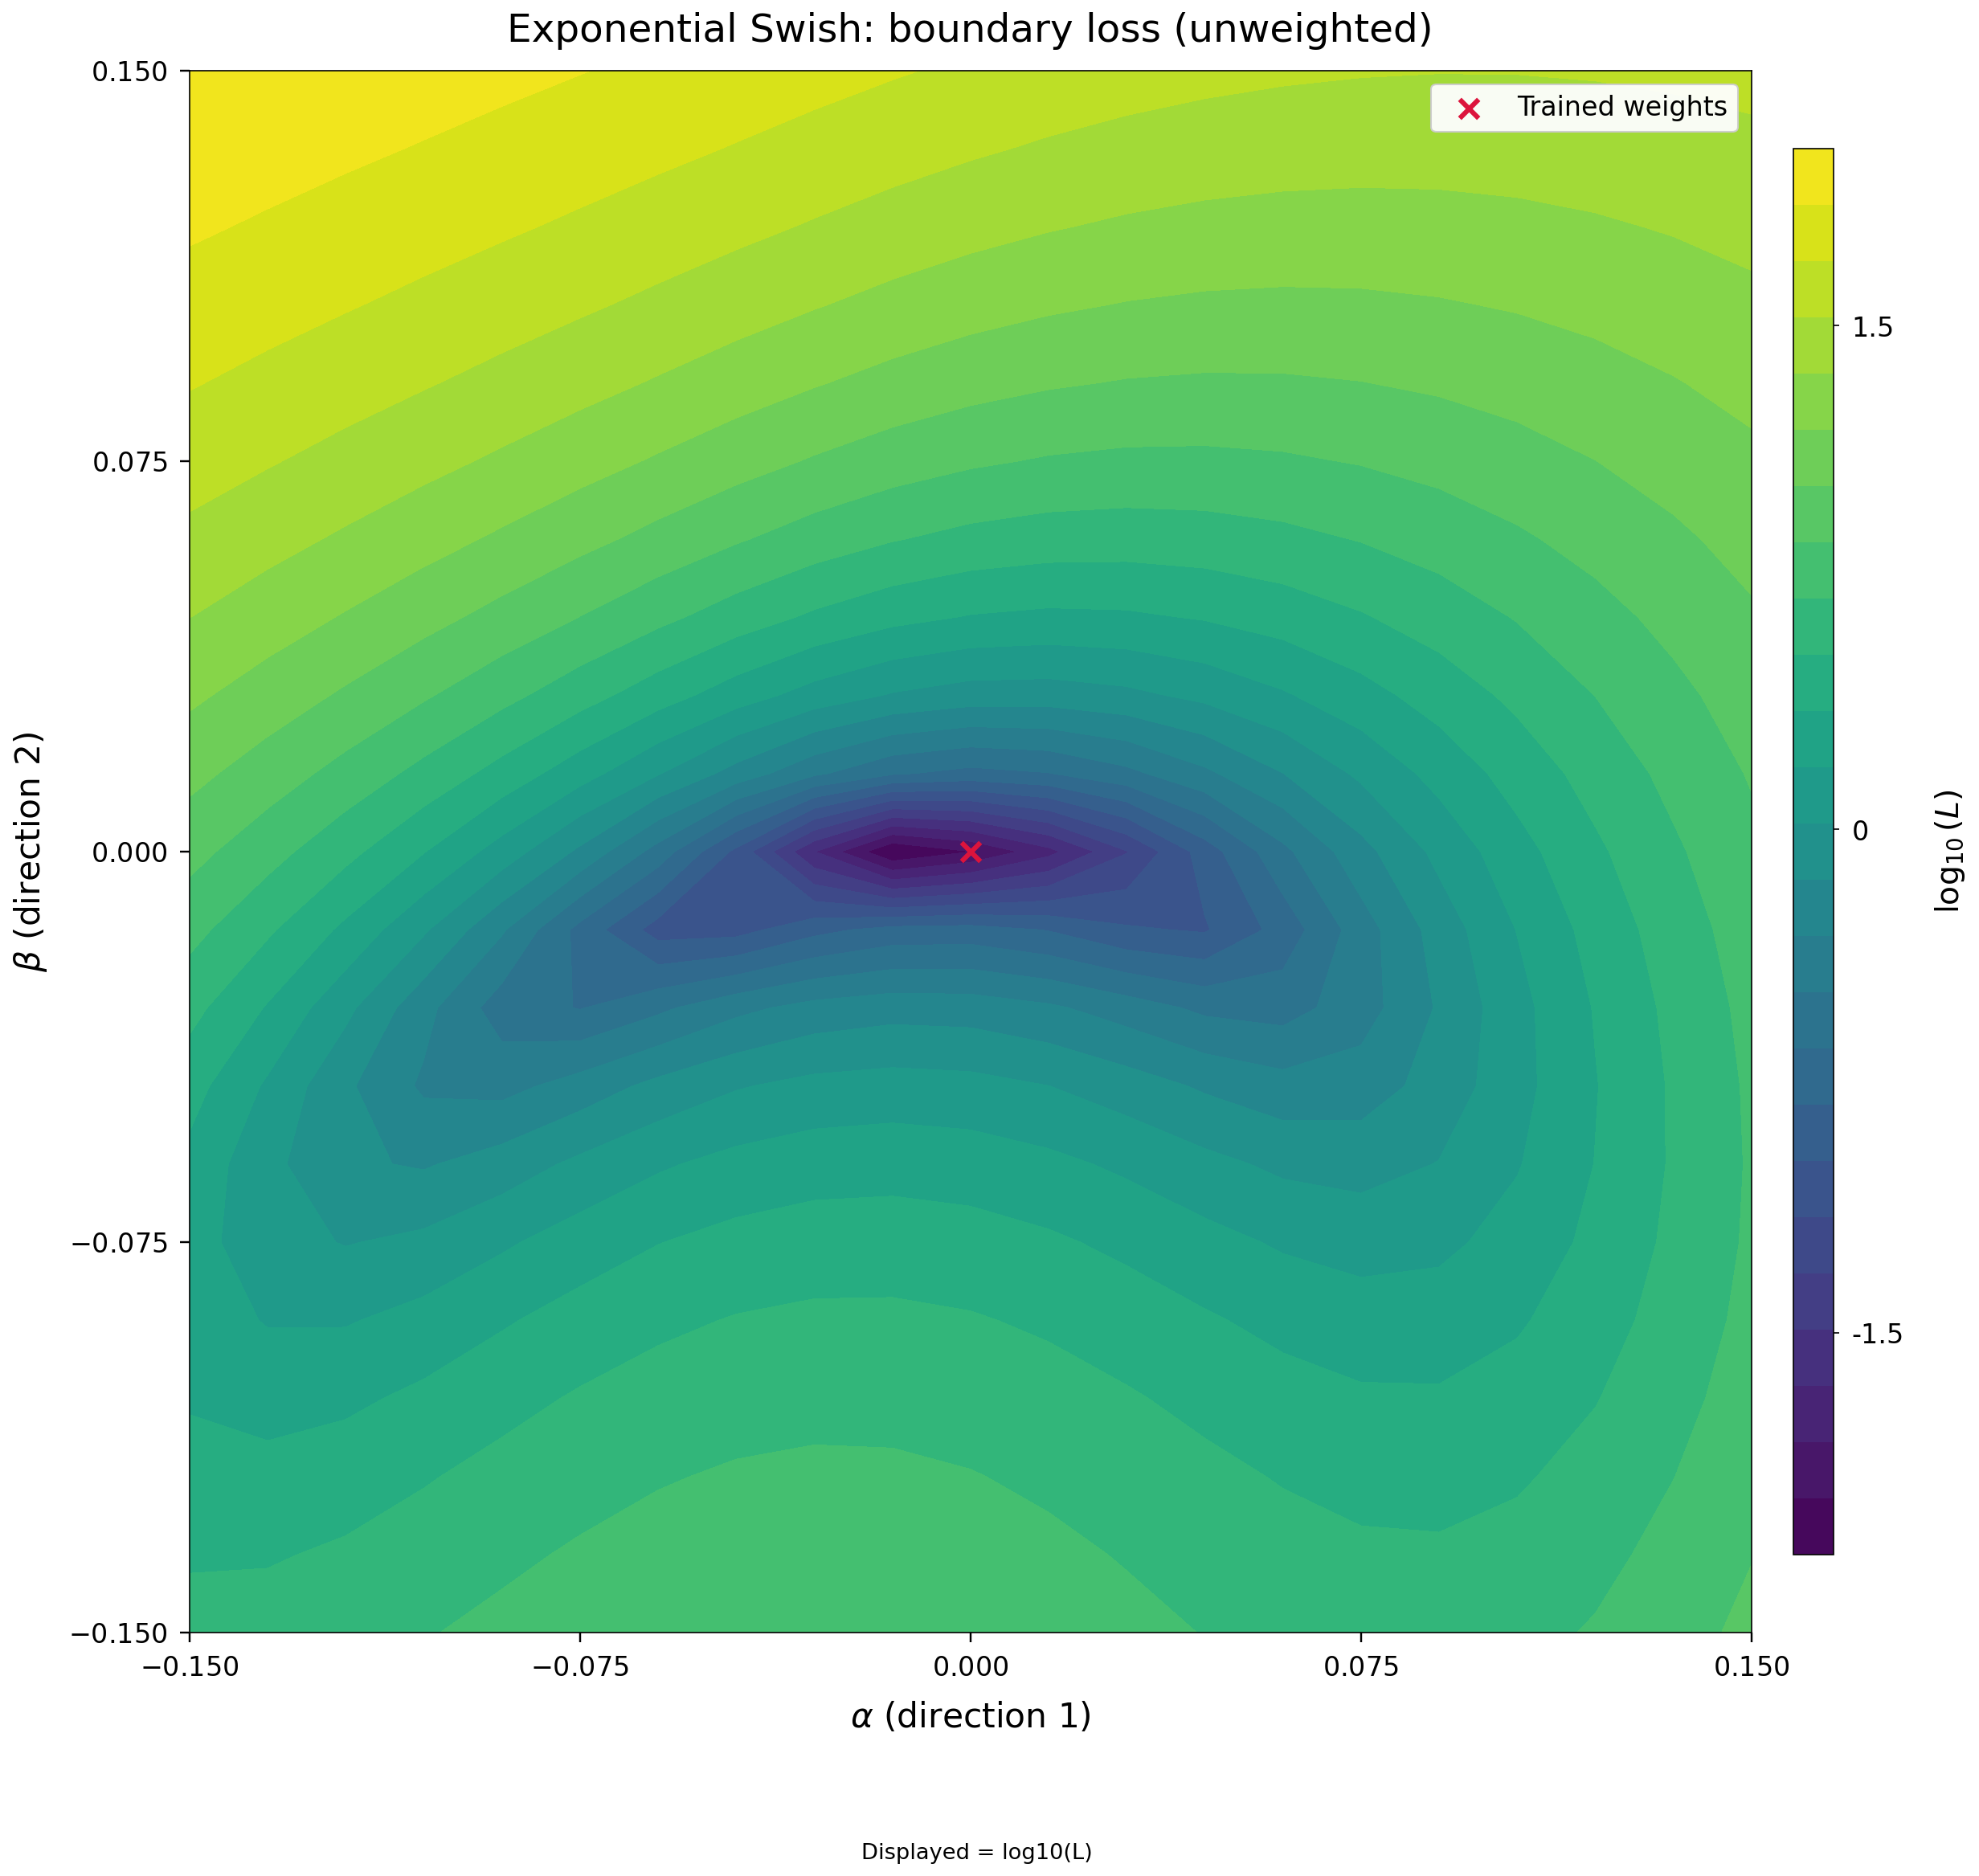

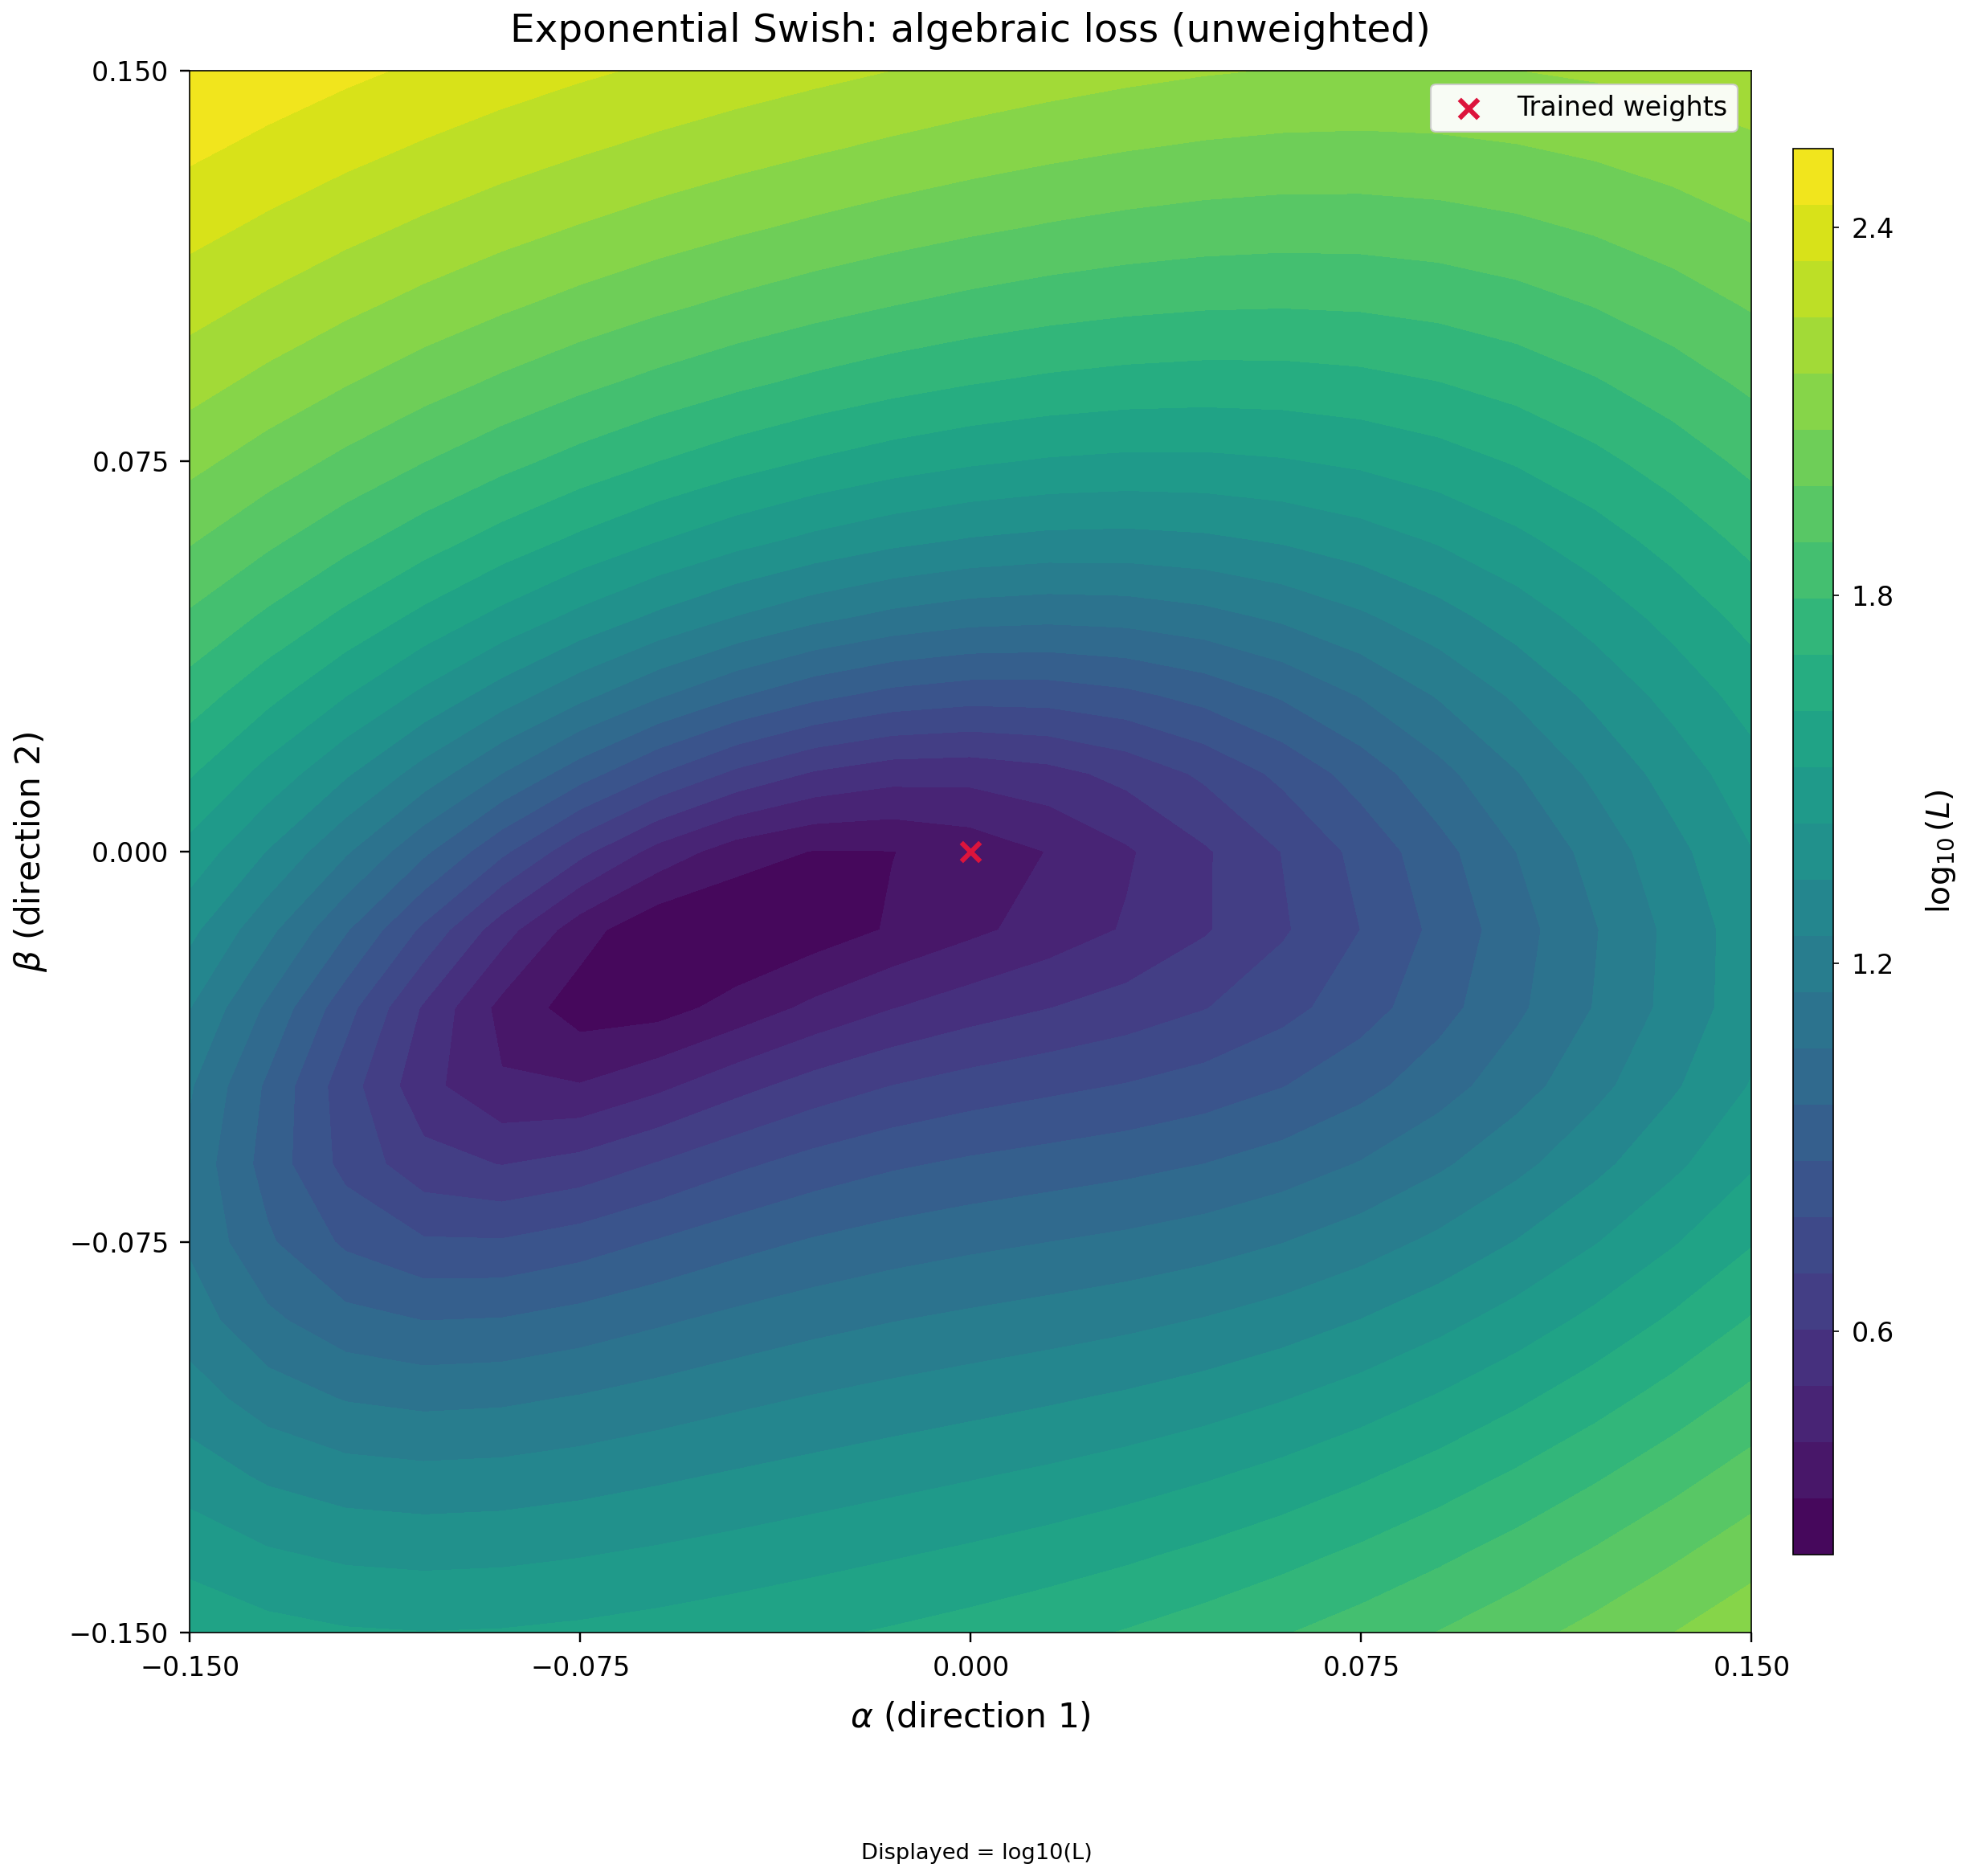

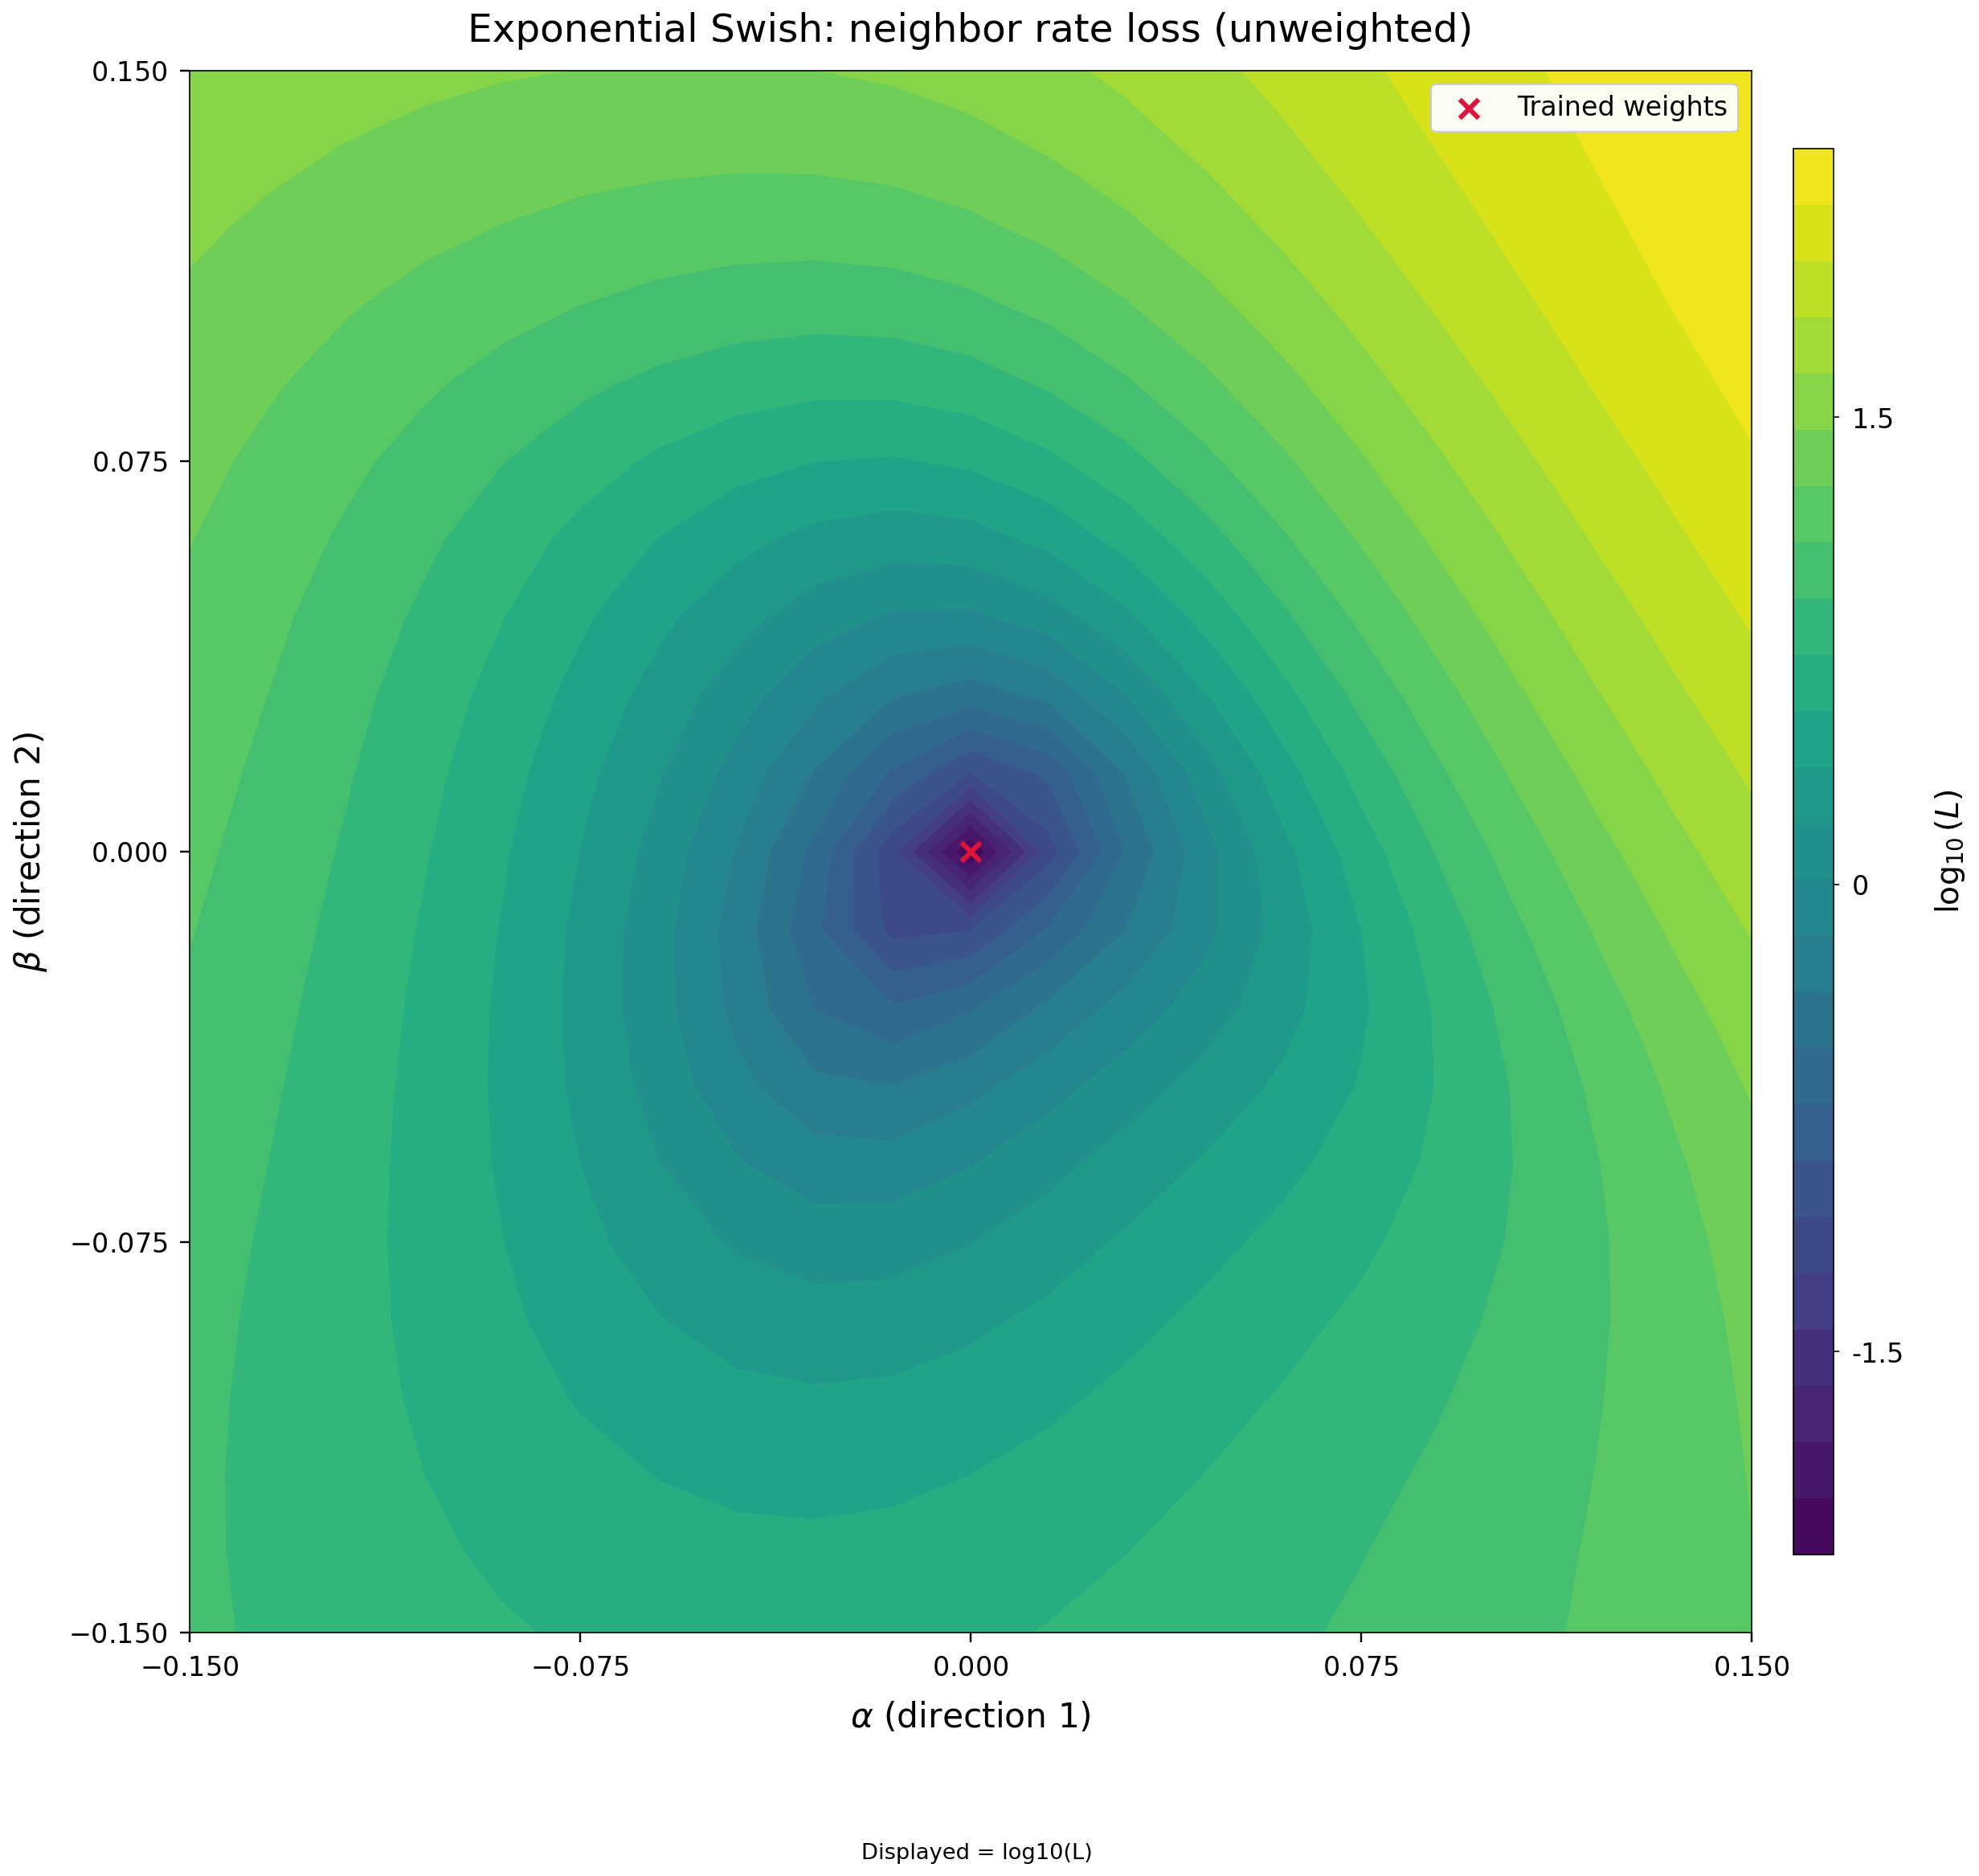

In [27]:
"""Run after training your Swish exponential PINN: u(x, b, A) = A*exp(b*x).

Plots a two-dimensional slice of the network's loss in weight space,
centered on the current trained weights. This is not an activation surface
or the full high-dimensional loss landscape.

Requires model, X_MIN, X_MAX, MIN_RATE, MAX_RATE, MIN_COEFFICIENT,
and MAX_COEFFICIENT from the attached Swish exponential training cell.
The trained model is cloned with its existing Swish layers and normalization
order intact; no activation replacement or retraining is performed.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def _swish_kernel_directions(weights, rng):
    """Independent directions, scaled to each Dense output filter's norm.

    Only 2-D kernel matrices move. Biases and LayerNormalization parameters
    remain at their trained values. Each kernel column is an output filter.
    """
    directions = []
    for weight in weights:
        if weight.ndim == 2:
            noise = rng.standard_normal(weight.shape)
            column_norm = np.linalg.norm(weight, axis=0, keepdims=True)
            noise_norm = np.linalg.norm(noise, axis=0, keepdims=True)
            noise *= column_norm / np.maximum(noise_norm, 1e-30)
            directions.append(noise.astype(weight.dtype))
        else:
            directions.append(np.zeros_like(weight))
    return directions


def plot_exponential_swish_loss_surface(
    trained_model,
    grid_size=21,
    radius=0.15,
    n_samples=256,
    seed=12345,
    log_scale=True,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
):
    """Plot the supplied PINN objective around the trained model.

    At (alpha, beta), kernels are W0 + alpha*D1 + beta*D2.
    The center (0, 0) is the trained network. Directions are normalized
    per output filter; radius is a relative kernel perturbation scale.
    Every point uses the same fixed physics and boundary samples.

    The loss exactly follows the supplied objective:
      physics + boundary + 0.125*algebraic + 0.07*neighbor_rate.
    Its sampled values can differ from the final stochastic training loss.

    Returns coordinates, raw loss arrays, center losses, and figure handles.
    """
    if (not isinstance(grid_size, (int, np.integer))
            or grid_size < 3 or grid_size % 2 == 0):
        raise ValueError("grid_size must be an odd integer of at least 3.")
    if not np.isscalar(radius) or not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("n_samples must be a positive integer.")

    if not any(
        getattr(getattr(layer, "activation", None), "__name__", "")
        in {"swish", "silu"}
        for layer in trained_model.layers
    ):
        raise ValueError(
            "Pass the trained model from your Swish exponential training cell. "
            "Expected a layer with activation='swish' (also called SiLU)."
        )

    # Work on a separate model: the trained model and optimizer are untouched.
    probe_model = tf.keras.models.clone_model(trained_model)
    base_weights = trained_model.get_weights()
    probe_model.set_weights(base_weights)
    dtype = tf.as_dtype(probe_model.compute_dtype)
    numpy_dtype = dtype.as_numpy_dtype
    rng = np.random.default_rng(seed)

    # Fixed evaluation inputs eliminate resampling noise between grid points.
    def uniform(low, high):
        values = rng.uniform(low, high, (n_samples, 1)).astype(numpy_dtype)
        return tf.convert_to_tensor(values, dtype=dtype)

    x = uniform(X_MIN, X_MAX)
    rate = uniform(MIN_RATE, MAX_RATE)
    coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    boundary_rate = uniform(MIN_RATE, MAX_RATE)
    boundary_coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    x_boundary = tf.zeros_like(x)
    exact_derivative = coefficient * rate * tf.exp(rate * x)

    # Reproduce the exponential training objective, including negative-A queries.
    # For rate intervals narrower than 2, the original neighbor rule may
    # query below MIN_RATE; retain this behavior to match the trained loss.
    one = tf.constant(1.0, dtype=dtype)
    max_rate = tf.constant(MAX_RATE, dtype=dtype)
    lower_rate = tf.where(rate <= max_rate - one, rate, rate - one)
    upper_rate = lower_rate + one

    @tf.function
    def evaluate_fixed_loss():
        def predict(x_value, rate_value, a_value):
            return probe_model(
                tf.concat([x_value, rate_value, a_value], axis=1),
                training=False,
            )

        with tf.GradientTape(watch_accessed_variables=False) as tape:
            tape.watch(x)
            u = predict(x, rate, coefficient)
        du_dx = tape.gradient(u, x)
        if du_dx is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        physics = tf.reduce_mean(tf.square(du_dx - exact_derivative))

        u_boundary = predict(x_boundary, boundary_rate, boundary_coefficient)
        boundary = tf.reduce_mean(tf.square(u_boundary - boundary_coefficient))

        u_negative = predict(x, rate, -coefficient)
        algebraic = tf.reduce_mean(tf.square(u + u_negative))

        u_lower = predict(x, lower_rate, coefficient)
        u_upper = predict(x, upper_rate, coefficient)
        neighbor = tf.reduce_mean(tf.square(u_upper - tf.exp(x) * u_lower))

        total = physics + boundary + 0.125 * algebraic + 0.07 * neighbor
        return tf.stack([total, physics, boundary, algebraic, neighbor])

    direction_1 = _swish_kernel_directions(base_weights, rng)
    direction_2 = _swish_kernel_directions(base_weights, rng)
    center_losses = evaluate_fixed_loss().numpy()
    if not np.all(np.isfinite(center_losses)):
        raise FloatingPointError("The trained model has nonfinite loss on the fixed batch.")

    coordinates = np.linspace(-radius, radius, grid_size)
    # Ensure the center is represented exactly.
    coordinates[grid_size // 2] = 0.0
    alpha_grid, beta_grid = np.meshgrid(coordinates, coordinates)
    loss_values = np.empty((5, grid_size, grid_size), dtype=np.float64)

    print(f"Evaluating {grid_size**2:,} weight settings on "
          f"{n_samples:,} fixed samples each...", flush=True)
    try:
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                if row == grid_size // 2 and column == grid_size // 2:
                    values = center_losses
                else:
                    probe_model.set_weights([
                        weight + alpha * d1 + beta * d2
                        for weight, d1, d2 in zip(
                            base_weights, direction_1, direction_2
                        )
                    ])
                    values = evaluate_fixed_loss().numpy()
                loss_values[:, row, column] = values
            print(f"Completed row {row + 1}/{grid_size}", flush=True)
    finally:
        probe_model.set_weights(base_weights)

    invalid = ~np.isfinite(loss_values)
    if np.any(invalid):
        print("Some perturbed settings had nonfinite losses; "
              "they will appear as gaps in the plots.")
    loss_values[invalid] = np.nan
    names = ["total", "physics", "boundary", "algebraic", "neighbor_rate"]
    print("\nLoss at trained weights on the fixed batch:")
    for name, value in zip(names, center_losses):
        print(f"  {name:<15} {value:.8e}")

    results = {
        "target": "exponential",
        "alpha": alpha_grid,
        "beta": beta_grid,
        "losses": {name: loss_values[i] for i, name in enumerate(names)},
        "center_losses": dict(zip(names, center_losses)),
        "seed": seed,
        "n_samples": n_samples,
    }
    return replot_exponential_swish_loss_surface(
        results, total_figsize=total_figsize, component_figsize=component_figsize,
        font_scale=font_scale, dpi=dpi, log_scale=log_scale,
    )


def replot_exponential_swish_loss_surface(
    results,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
    log_scale=True,
):
    """Redraw cached loss values without evaluating the model again.

    Each landscape gets its own full-size figure: one surface, one total
    contour, and four individual component contours. Figure sizes apply
    to EACH plot, rather than to a multi-panel canvas.
    font_scale optionally overrides the automatic scale (e.g. 2.5).
    Figures and colorbars use at most five major ticks per axis.
    This helper only needs NumPy and Matplotlib; no trained model is needed.
    Nearly constant losses are centered and scaled for readable ticks.
    The reference and scale are stated explicitly; raw data is unchanged.
    """
    from matplotlib.colors import Normalize
    from matplotlib.ticker import MaxNLocator, ScalarFormatter, FuncFormatter

    for size in (total_figsize, component_figsize):
        if len(size) != 2 or not np.all(np.isfinite(size)) or min(size) <= 0:
            raise ValueError("Figure sizes must contain two positive finite numbers.")
    if font_scale is not None and (not np.isfinite(font_scale) or font_scale <= 0):
        raise ValueError("font_scale must be a positive finite number.")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("dpi must be a positive finite number.")

    alpha_grid = np.asarray(results["alpha"])
    beta_grid = np.asarray(results["beta"])
    floor = 1e-16

    def display_values(values):
        values = np.asarray(values, dtype=float)
        values = np.where(np.isfinite(values), values, np.nan)
        return np.log10(np.maximum(values, floor)) if log_scale else values

    def scale_for(figsize, rows):
        if font_scale is not None:
            return float(font_scale)
        # Keep text moderate so the landscape, rather than labels, fills
        # the single-panel figure. Larger canvases mostly enlarge the data.
        return max(0.8, min(2.0, min(figsize) / 11.0))

    def format_loss_tick(value, position):
        # Explicit formatting prevents Matplotlib from generating offset text.
        if abs(value) < 1e-12:
            value = 0.0
        return f"{value:.5g}"

    def prepare_display(raw_values, raw_reference):
        values = display_values(raw_values)
        reference = float(display_values(raw_reference))
        finite_values = values[np.isfinite(values)]
        if finite_values.size == 0 or not np.isfinite(reference):
            raise FloatingPointError("No finite loss values/reference are available.")
        span = float(np.ptp(finite_values))
        quantity = r"\log_{10}(L)" if log_scale else "L"
        quantity_text = "log10(L)" if log_scale else "L"
        # Center only when loss variations are tiny compared with the reference.
        # This changes displayed units, preserving all sampled heights and order.
        centered = span < 1e-3 * max(abs(reference), 1e-16)
        offset = reference if centered else 0.0
        spread = span if centered else float(np.max(np.abs(finite_values)))
        if spread > 0 and (centered or spread >= 1e4 or spread < 1e-3):
            exponent = int(np.clip(np.floor(np.log10(spread)), -300, 300))
        else:
            exponent = 0
        unit = 10.0 ** exponent
        plotted = (values - offset) / unit
        plotted_reference = (reference - offset) / unit
        label = (r"\Delta " if centered else "") + quantity
        if exponent:
            label += rf"\,/\,10^{{{exponent}}}"
        label = "$" + label + "$"
        if centered:
            note = (f"Displayed = [{quantity_text} - {reference:.12g}]"
                    + (f" / 10^{exponent}" if exponent else "")
                    + "; reference is the trained model")
        else:
            note = (f"Displayed = {quantity_text}"
                    + (f" / 10^{exponent}" if exponent else ""))
        metadata = {"offset": offset, "scale": unit,
                    "quantity": quantity_text, "centered": centered}
        return plotted, plotted_reference, label, note, metadata

    def style_axis(ax, scale, is_3d=False):
        ax.tick_params(axis="both", labelsize=11 * scale,
                       pad=5 * scale, length=4 * scale, width=0.8 * scale)
        for axis, values in ((ax.xaxis, alpha_grid), (ax.yaxis, beta_grid)):
            ticks = np.linspace(np.nanmin(values), np.nanmax(values), 5)
            # Interior 3-D ticks avoid collisions at the front cube corner.
            axis.set_ticks(ticks[1:-1] if is_3d else ticks)
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-3, 4))
            formatter.set_useOffset(False)
            axis.set_major_formatter(formatter)
            axis.label.set_fontsize(14 * scale)
            axis.labelpad = (15 if is_3d else 8) * scale
            axis.get_offset_text().set_fontsize(10 * scale)
        if is_3d:
            ax.tick_params(axis="z", labelsize=11 * scale, pad=5 * scale)
            ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.zaxis.set_major_formatter(FuncFormatter(format_loss_tick))
            ax.zaxis.get_offset_text().set_visible(False)
            ax.zaxis.label.set_fontsize(14 * scale)
            ax.zaxis.labelpad = 17 * scale
            ax.zaxis.get_offset_text().set_fontsize(10 * scale)
            ax.set_box_aspect((1, 1, 0.8))
        ax.title.set_fontsize(16 * scale)

    def style_colorbar(fig, artist, ax, scale, label):
        colorbar = fig.colorbar(
            artist, ax=ax, shrink=0.90, fraction=0.03,
            pad=0.025, aspect=35,
        )
        colorbar.locator = MaxNLocator(nbins=4)
        colorbar.formatter = FuncFormatter(format_loss_tick)
        colorbar.update_ticks()
        colorbar.ax.yaxis.get_offset_text().set_visible(False)
        colorbar.ax.tick_params(labelsize=11 * scale, pad=5 * scale)
        colorbar.set_label(label, fontsize=13 * scale, labelpad=12 * scale)
        colorbar.ax.yaxis.get_offset_text().set_fontsize(10 * scale)
        return colorbar

    total, center, color_label, total_note, total_metadata = prepare_display(
        results["losses"]["total"], results["center_losses"]["total"]
    )
    finite = total[np.isfinite(total)]
    if finite.size == 0:
        raise FloatingPointError("No finite total loss values are available to plot.")
    vmin, vmax = float(finite.min()), float(finite.max())
    if vmin == vmax:
        margin = max(abs(vmin) * 0.01, 1e-6)
        vmin, vmax = vmin - margin, vmax + margin
    # A shared normalization makes the surface and contour colors comparable.
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 31)
    scale = scale_for(total_figsize, rows=1)

    # Each main view gets the entire canvas, rather than half a wide figure.
    fig_surface = plt.figure(figsize=total_figsize, dpi=dpi, layout="constrained")
    fig_surface.get_layout_engine().set(w_pad=0.45, h_pad=0.18)
    ax_surface = fig_surface.add_subplot(111, projection="3d", computed_zorder=False)
    surface = ax_surface.plot_surface(
        alpha_grid, beta_grid, total, cmap="viridis", norm=norm,
        edgecolor="none", alpha=0.95, antialiased=True, zorder=1,
        rcount=alpha_grid.shape[0], ccount=alpha_grid.shape[1],
    )
    ax_surface.set(xlabel=r"$\alpha$", ylabel=r"$\beta$", zlabel=color_label)
    ax_surface.set_title("Exponential Swish: total PINN loss surface", pad=12 * scale)
    ax_surface.view_init(elev=30, azim=-55)
    style_axis(ax_surface, scale, is_3d=True)
    fig_surface.supxlabel(total_note, fontsize=9 * scale)

    fig_contour, ax_contour = plt.subplots(
        figsize=total_figsize, dpi=dpi, layout="constrained"
    )
    # Explicit margins avoid colorbar/aspect layout clipping of the y label.
    fig_contour.set_layout_engine(None)
    fig_contour.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
    contour = ax_contour.contourf(
        alpha_grid, beta_grid, np.ma.masked_invalid(total),
        levels=levels, cmap="viridis", norm=norm,
    )
    ax_contour.scatter(0, 0, color="crimson", marker="x", s=75 * scale**2,
                       linewidths=2 * scale, label="Trained weights")
    ax_contour.set(xlabel=r"$\alpha$ (direction 1)",
                   ylabel=r"$\beta$ (direction 2)", aspect="equal")
    ax_contour.set_title("Exponential Swish: total PINN loss contours", pad=12 * scale)
    style_axis(ax_contour, scale)
    ax_contour.legend(fontsize=11 * scale, framealpha=0.95)
    style_colorbar(fig_contour, contour, ax_contour, scale, color_label)
    fig_contour.supxlabel(total_note, fontsize=9 * scale)

    component_keys = ["physics", "boundary", "algebraic", "neighbor_rate"]
    component_names = ["Physics", "Boundary", "Algebraic", "Neighbor rate"]
    component_scale = scale_for(component_figsize, rows=1)
    component_figures = {}
    display_metadata = {"total": total_metadata}
    for key, name in zip(component_keys, component_names):
        plotted, _, component_label, component_note, metadata = prepare_display(
            results["losses"][key], results["center_losses"][key]
        )
        display_metadata[key] = metadata
        finite_component = plotted[np.isfinite(plotted)]
        low, high = float(finite_component.min()), float(finite_component.max())
        if low == high:
            margin = max(abs(low) * 0.01, 1e-6)
            low, high = low - margin, high + margin
        fig_component, ax = plt.subplots(
            figsize=component_figsize, dpi=dpi, layout="constrained"
        )
        fig_component.set_layout_engine(None)
        fig_component.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
        contour = ax.contourf(
            alpha_grid, beta_grid, np.ma.masked_invalid(plotted),
            levels=np.linspace(low, high, 26), cmap="viridis",
        )
        ax.scatter(0, 0, color="crimson", marker="x",
                   s=60 * component_scale**2, linewidths=2 * component_scale,
                   label="Trained weights")
        ax.set(xlabel=r"$\alpha$ (direction 1)",
               ylabel=r"$\beta$ (direction 2)", aspect="equal")
        ax.set_title(f"Exponential Swish: {name.lower()} loss (unweighted)",
                     pad=12 * component_scale)
        style_axis(ax, component_scale)
        ax.legend(fontsize=11 * component_scale, framealpha=0.95)
        style_colorbar(fig_component, contour, ax, component_scale, component_label)
        fig_component.supxlabel(component_note, fontsize=9 * component_scale)
        component_figures[key] = fig_component

    print("Base quantity: log10(loss), floored at 1e-16."
          if log_scale else "Base quantity: raw loss.")
    print("Display centering/scaling is specified in each plot caption.")
    # New figure handles replace the old handles; raw sampled data is unchanged.
    # figure_total remains an alias for compatibility; the views are separate.
    results["figure_total"] = fig_surface
    results["figure_surface"] = fig_surface
    results["figure_contour"] = fig_contour
    results["figure_components"] = component_figures
    results["figures"] = [fig_surface, fig_contour, *component_figures.values()]
    results["plot_display"] = display_metadata
    plt.show()
    return results


# Reuse cached data when available; otherwise compute the surface once.
# Run AFTER the attached SWISH exponential training cell, with its model in `model`.
# A Swish-specific cache prevents reuse of a Valley or cosine loss surface.
# After training a DIFFERENT Swish model, delete this cache variable or call
# plot_exponential_swish_loss_surface(model) directly to compute a fresh slice.

if "swish_exponential_loss_surface_results" in globals():
    swish_exponential_loss_surface_results = replot_exponential_swish_loss_surface(
        swish_exponential_loss_surface_results,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        font_scale=None,  # Moderate text; most of each figure is the landscape.
        dpi=150,
        log_scale=True,
    )
else:
    swish_exponential_loss_surface_results = plot_exponential_swish_loss_surface(
        model,
        grid_size=21,
        radius=0.15,
        n_samples=256,
        seed=12345,
        log_scale=True,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        dpi=150,
    )


In [ ]:
"""Run after the attached Swish exponential PINN training cell.

Plots a two-dimensional slice of the network's loss in weight space,
centered on the current trained weights. This is not an activation surface
or the full high-dimensional loss landscape.
This evaluates an already-trained Swish model; it does not convert activations.

Requires a trained Swish model, X_MIN, X_MAX, MIN_RATE, MAX_RATE,
MIN_COEFFICIENT, and MAX_COEFFICIENT from the training cell.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def _swish_kernel_directions(weights, rng):
    """Independent directions, scaled to each Dense output filter's norm.

    Only 2-D kernel matrices move. Biases and LayerNormalization parameters
    remain at their trained values. Each kernel column is an output filter.
    """
    directions = []
    for weight in weights:
        if weight.ndim == 2:
            noise = rng.standard_normal(weight.shape)
            column_norm = np.linalg.norm(weight, axis=0, keepdims=True)
            noise_norm = np.linalg.norm(noise, axis=0, keepdims=True)
            noise *= column_norm / np.maximum(noise_norm, 1e-30)
            directions.append(noise.astype(weight.dtype))
        else:
            directions.append(np.zeros_like(weight))
    return directions


def plot_swish_loss_surface(
    trained_model,
    grid_size=21,
    radius=0.15,
    n_samples=256,
    seed=12345,
    log_scale=True,
):
    """Plot the supplied PINN objective around the trained model.

    At (alpha, beta), kernels are W0 + alpha*D1 + beta*D2.
    The center (0, 0) is the trained network. Directions are normalized
    per output filter; radius is a relative kernel perturbation scale.
    Every point uses the same fixed physics and boundary samples.

    The loss exactly follows the supplied objective:
      physics + boundary + 0.125*algebraic + 0.07*neighbor_rate.
    Its sampled values can differ from the final stochastic training loss.

    Returns coordinates, raw loss arrays, center losses, and both figures.
    """
    if (not isinstance(grid_size, (int, np.integer))
            or grid_size < 3 or grid_size % 2 == 0):
        raise ValueError("grid_size must be an odd integer of at least 3.")
    if not np.isscalar(radius) or not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("n_samples must be a positive integer.")
    if not any(
        getattr(getattr(layer, "activation", None), "__name__", "")
        in {"swish", "silu"}
        for layer in trained_model.layers
    ):
        raise ValueError(
            "Pass the model trained with activation='swish'. "
            "This plotting function does not replace or retrain activations."
        )

    # Work on a separate model: the trained model and optimizer are untouched.
    probe_model = tf.keras.models.clone_model(trained_model)
    base_weights = trained_model.get_weights()
    probe_model.set_weights(base_weights)
    dtype = tf.as_dtype(probe_model.compute_dtype)
    numpy_dtype = dtype.as_numpy_dtype
    rng = np.random.default_rng(seed)

    # Fixed evaluation inputs eliminate resampling noise between grid points.
    def uniform(low, high):
        values = rng.uniform(low, high, (n_samples, 1)).astype(numpy_dtype)
        return tf.convert_to_tensor(values, dtype=dtype)

    x = uniform(X_MIN, X_MAX)
    rate = uniform(MIN_RATE, MAX_RATE)
    coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    boundary_rate = uniform(MIN_RATE, MAX_RATE)
    boundary_coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    x_boundary = tf.zeros_like(x)
    exact_derivative = coefficient * rate * tf.exp(rate * x)

    # Reproduce the supplied training code, including negative-A evaluations.
    # For rate intervals narrower than 2, its neighbor rule can query rates
    # below MIN_RATE. Retain those queries to match the trained objective.
    one = tf.constant(1.0, dtype=dtype)
    max_rate = tf.constant(MAX_RATE, dtype=dtype)
    lower_rate = tf.where(rate <= max_rate - one, rate, rate - one)
    upper_rate = lower_rate + one

    @tf.function
    def evaluate_fixed_loss():
        def predict(x_value, rate_value, a_value):
            return probe_model(
                tf.concat([x_value, rate_value, a_value], axis=1),
                training=False,
            )

        with tf.GradientTape(watch_accessed_variables=False) as tape:
            tape.watch(x)
            u = predict(x, rate, coefficient)
        du_dx = tape.gradient(u, x)
        if du_dx is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        physics = tf.reduce_mean(tf.square(du_dx - exact_derivative))

        u_boundary = predict(x_boundary, boundary_rate, boundary_coefficient)
        boundary = tf.reduce_mean(tf.square(u_boundary - boundary_coefficient))

        u_negative = predict(x, rate, -coefficient)
        algebraic = tf.reduce_mean(tf.square(u + u_negative))

        u_lower = predict(x, lower_rate, coefficient)
        u_upper = predict(x, upper_rate, coefficient)
        neighbor = tf.reduce_mean(tf.square(u_upper - tf.exp(x) * u_lower))

        total = physics + boundary + 0.125 * algebraic + 0.07 * neighbor
        return tf.stack([total, physics, boundary, algebraic, neighbor])

    direction_1 = _swish_kernel_directions(base_weights, rng)
    direction_2 = _swish_kernel_directions(base_weights, rng)
    center_losses = evaluate_fixed_loss().numpy()
    if not np.all(np.isfinite(center_losses)):
        raise FloatingPointError("The trained model has nonfinite loss on the fixed batch.")

    coordinates = np.linspace(-radius, radius, grid_size)
    # Ensure the center is represented exactly.
    coordinates[grid_size // 2] = 0.0
    alpha_grid, beta_grid = np.meshgrid(coordinates, coordinates)
    loss_values = np.empty((5, grid_size, grid_size), dtype=np.float64)

    print(f"Evaluating {grid_size**2:,} weight settings on "
          f"{n_samples:,} fixed samples each...", flush=True)
    try:
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                if row == grid_size // 2 and column == grid_size // 2:
                    values = center_losses
                else:
                    probe_model.set_weights([
                        weight + alpha * d1 + beta * d2
                        for weight, d1, d2 in zip(
                            base_weights, direction_1, direction_2
                        )
                    ])
                    values = evaluate_fixed_loss().numpy()
                loss_values[:, row, column] = values
            print(f"Completed row {row + 1}/{grid_size}", flush=True)
    finally:
        probe_model.set_weights(base_weights)

    invalid = ~np.isfinite(loss_values)
    if np.any(invalid):
        print("Some perturbed settings had nonfinite losses; "
              "they will appear as gaps in the plots.")
    loss_values[invalid] = np.nan
    floor = 1e-16

    def display_values(values):
        if log_scale:
            return np.log10(np.maximum(values, floor))
        return values

    height_label = "log10(total loss), floor 1e-16" if log_scale else "Total loss"
    total_height = display_values(loss_values[0])
    center_height = float(display_values(center_losses[0]))

    # Figure 1: total objective, viewed as a 3-D surface and a contour map.
    fig_total = plt.figure(figsize=(14, 6), layout="constrained")
    ax_surface = fig_total.add_subplot(1, 2, 1, projection="3d")
    surface = ax_surface.plot_surface(
        alpha_grid, beta_grid, total_height, cmap="viridis",
        edgecolor="none", alpha=0.9,
    )
    ax_surface.scatter(0, 0, center_height, color="crimson", s=55,
                       depthshade=False, label="Trained weights")
    ax_surface.set(xlabel="Direction 1 coefficient (alpha)",
                   ylabel="Direction 2 coefficient (beta)",
                   zlabel=height_label, title="Total PINN loss surface")
    ax_surface.view_init(elev=30, azim=-55)
    ax_surface.legend(loc="upper left")
    fig_total.colorbar(surface, ax=ax_surface, shrink=0.6, pad=0.12)

    ax_contour = fig_total.add_subplot(1, 2, 2)
    contour = ax_contour.contourf(
        alpha_grid, beta_grid, np.ma.masked_invalid(total_height),
        levels=30, cmap="viridis",
    )
    ax_contour.scatter(0, 0, color="crimson", marker="x", s=75,
                       label="Trained weights")
    ax_contour.set(xlabel="Direction 1 coefficient (alpha)",
                   ylabel="Direction 2 coefficient (beta)",
                   title="Total PINN loss contours", aspect="equal")
    ax_contour.legend()
    fig_total.colorbar(contour, ax=ax_contour, label=height_label)
    fig_total.suptitle("Swish network: a 2-D weight-space slice")

    # Figure 2: unweighted components, each with its own color scale.
    component_names = ["Physics", "Boundary", "Algebraic", "Neighbor rate"]
    fig_components, axes = plt.subplots(
        2, 2, figsize=(12, 10), layout="constrained"
    )
    for index, (ax, name) in enumerate(zip(axes.ravel(), component_names), start=1):
        plotted = display_values(loss_values[index])
        contour = ax.contourf(
            alpha_grid, beta_grid, np.ma.masked_invalid(plotted),
            levels=25, cmap="viridis",
        )
        ax.scatter(0, 0, color="crimson", marker="x", s=60)
        ax.set(xlabel="Direction 1 coefficient (alpha)",
               ylabel="Direction 2 coefficient (beta)",
               title=f"{name}: unweighted loss", aspect="equal")
        label = "log10(loss), floor 1e-16" if log_scale else "Loss"
        fig_components.colorbar(contour, ax=ax, label=label)
    fig_components.suptitle("Loss components; red crosses mark trained weights")

    names = ["total", "physics", "boundary", "algebraic", "neighbor_rate"]
    print("\nLoss at trained weights on the fixed batch:")
    for name, value in zip(names, center_losses):
        print(f"  {name:<15} {value:.8e}")
    plt.show()

    return {
        "alpha": alpha_grid,
        "beta": beta_grid,
        "losses": {name: loss_values[i] for i, name in enumerate(names)},
        "center_losses": dict(zip(names, center_losses)),
        "seed": seed,
        "n_samples": n_samples,
        "figure_total": fig_total,
        "figure_components": fig_components,
    }


# Run this cell/file AFTER training your Swish model.
swish_loss_surface_results = plot_swish_loss_surface(
    model,
    grid_size=21,      # Odd; use 11 for a quicker preview or 31 for more detail.
    radius=0.15,       # Decrease for a closer view around the trained weights.
    n_samples=256,    # Increase for a more representative sampled objective.
    seed=12345,        # Change to inspect a different batch and direction plane.
    log_scale=True,    # False shows the raw loss heights/colors.
)


In [ ]:
import numpy as np
import tensorflow as tf


def test_random_exponential_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
):
    """Evaluate the trained exponential PINN on random input triples.

    Requires the training cell's:
        DTYPE, X_MIN, X_MAX,
        MIN_COEFFICIENT, MAX_COEFFICIENT,
        MIN_RATE, MAX_RATE,
        calculate_du_dx(x, rate, coefficient, training=False)

    Returns:
        metrics: Average, median, and maximum absolute errors.
        samples: Inputs, predictions, exact values, and errors.

    Median and maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")

    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    # 1. Generate random (x, rate, coefficient) triples.
    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype

    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    rate = rng.uniform(MIN_RATE, MAX_RATE, (n_points, 1)).astype(dtype)
    coefficient = rng.uniform(
        MIN_COEFFICIENT, MAX_COEFFICIENT, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # 2. Evaluate predictions and automatic derivatives.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)

        # Match the exponential training function's argument order.
        u_batch, du_batch = calculate_du_dx(
            x[start:stop],
            rate[start:stop],
            coefficient[start:stop],
            training=False,
        )

        if du_batch is None:
            raise RuntimeError(
                "The model derivative with respect to x is unavailable."
            )

        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # 3. Exact function and derivative:
    #    u(x, b, A) = A * exp(b*x)
    #    du/dx      = A * b * exp(b*x)
    u_exact = coefficient * np.exp(rate * x)
    du_dx_exact = coefficient * rate * np.exp(rate * x)

    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (
        np.isfinite(function_error).all()
        and np.isfinite(derivative_error).all()
    ):
        raise FloatingPointError(
            "Nonfinite predictions or errors encountered."
        )

    # 4. Error metrics. Original labels retained; median and maximum
    #    summarize pointwise absolute errors rather than mean errors.
    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(
        f"Random exponential inference points: {n_points:,} | "
        f"Seed: {seed}"
    )

    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # 5. Return all sampled inputs and results.
    samples = {
        "x": x.ravel(),
        "rate": rate.ravel(),
        "coefficient": coefficient.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }

    return metrics, samples


# Run after your exponential model has finished training.
metrics, samples = test_random_exponential_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
)


Random exponential inference points: 100,000 | Seed: 12345

Average function MAE           3.2994624463e-02
Average derivative MAE         1.2705417510e-01

Median function MAE            1.8318589777e-02
Median derivative MAE          3.5579519238e-02

Maximum function MAE           3.1034033345e+00
Maximum derivative MAE         2.9439940022e+01


<h1> Valley Exponential </h1>

Epoch:     1 | Total: 1.605837e+03 | Physics: 1.574166e+03 | Boundary: 2.143272e+01 | Algebra: 8.028608e+01 | Neighbor Rates: 2.894276e+00
Epoch:   500 | Total: 1.060255e+02 | Physics: 9.157128e+01 | Boundary: 1.010418e+01 | Algebra: 1.446309e+01 | Neighbor Rates: 3.631580e+01
Epoch:  1000 | Total: 1.297932e+01 | Physics: 8.057358e+00 | Boundary: 2.929340e+00 | Algebra: 8.865581e+00 | Neighbor Rates: 1.263461e+01
Epoch:  1500 | Total: 1.809274e+01 | Physics: 1.632211e+01 | Boundary: 9.299650e-01 | Algebra: 4.204190e+00 | Neighbor Rates: 4.501990e+00
Epoch:  2000 | Total: 6.632474e+00 | Physics: 4.151228e+00 | Boundary: 1.540032e+00 | Algebra: 4.407912e+00 | Neighbor Rates: 5.574649e+00
Epoch:  2500 | Total: 4.658323e+00 | Physics: 3.522201e+00 | Boundary: 2.456509e-01 | Algebra: 6.803681e+00 | Neighbor Rates: 5.715838e-01
Epoch:  3000 | Total: 5.131264e+00 | Physics: 4.813581e+00 | Boundary: 8.912151e-02 | Algebra: 1.543700e+00 | Neighbor Rates: 5.085517e-01
Epoch:  3500 | Total: 1.458

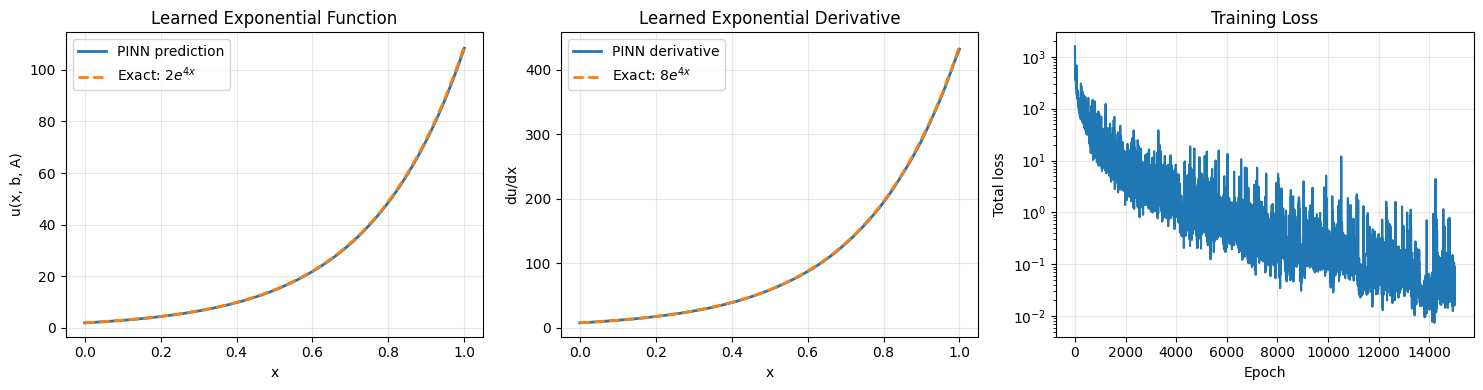


Test function:                   2 * exp(4 * x)
Test coefficient:                2
Test exponential rate:                      4

Results at x = 1
Predicted function value:        1.0844141671e+02
True function value:             1.0919630007e+02
Predicted derivative:            4.3216540612e+02
True derivative:                 4.3678520027e+02

Function mean absolute error:    2.220188e-01
Derivative mean absolute error:  6.980963e-01


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization             │ (None, 256)            │           512 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley (Valley)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_1           │ (None, 128)            │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_1 (Valley)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_2           │ (None, 96)             │           192 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_2 (Valley)               │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_3           │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ valley_3 (Valley)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,465 (394.26 KB)

 Trainable params: 50,465 (394.26 KB)

 Non-trainable params: 0 (0.00 B)

Saved model to exponential_pinn.keras


In [24]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

tf.keras.backend.clear_session()
tf.keras.backend.set_floatx("float64")

DTYPE = tf.float64

tf.random.set_seed(42)
np.random.seed(42)

MIN_RATE = 1.0
MAX_RATE = 4.1

MIN_COEFFICIENT = 0.01
MAX_COEFFICIENT = 2.10

X_MIN = 0.0
X_MAX = 1.0

BATCH_SIZE = 10000
EPOCHS = 15000

@tf.keras.utils.register_keras_serializable(package="Valley")
class Valley(tf.keras.layers.Layer):
    """The original activation: x**3 * tanh(x) * sech(x)."""

    def call(self, inputs):
        x = tf.convert_to_tensor(inputs)
        # sech(x) = exp(log(2) + x - softplus(2*x)).
        # Algebraically identical to 1/cosh(x), avoiding cosh overflow
        # for large finite inputs encountered in ordinary training.
        two = tf.constant(2.0, dtype=x.dtype)
        sech_x = tf.exp(tf.math.log(two) + x - tf.nn.softplus(two * x))
        return 5 * (x**3 * tf.tanh(x) * sech_x)

    def get_config(self):
        return super().get_config()

# ------------------------------------------------------------
# 2. Build the neural network
#
# Input:
#   [x, rate, coefficient]
#
# Output:
#   u(x, rate, coefficient) = coefficient * exp(rate*x)
# ------------------------------------------------------------

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(3,), dtype=DTYPE),

        tf.keras.layers.Dense(
            256,
            activation=None,
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-1, maxval=1
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE,
        ),

        Valley(dtype=DTYPE),

        tf.keras.layers.Dense(
            128,
            activation=None,
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-1, maxval=1
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE,
        ),

        Valley(dtype=DTYPE),

        tf.keras.layers.Dense(
            96,
            activation=None,
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-1, maxval=1
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE),

        tf.keras.layers.Dense(
            32,
            activation=None,
            kernel_initializer="glorot_uniform",
                bias_initializer=tf.keras.initializers.RandomUniform(
                    minval=-1, maxval=1
            ),
            dtype=DTYPE
        ),

        tf.keras.layers.LayerNormalization(
                axis=-1,
                epsilon=1e-5,
                center=True,
                scale=True,
                dtype=DTYPE
        ),

        Valley(dtype=DTYPE),

        tf.keras.layers.Dense(
            1,
            dtype=DTYPE
        )
    ])


model = build_model()

# -----------------------------------------------------------
#   Helper function to learn algebraic consistency
# -----------------------------------------------------------

def predict_u(
    x,
    rate,
    coefficient,
    training=True
):
    """
    Predict u(x, rate, coefficient) using the neural network.

    The network is intended to learn:

        u(x, rate, coefficient)
            = coefficient * exp(rate*x)
    """

    x = tf.cast(x, DTYPE)
    rate = tf.cast(rate, DTYPE)
    coefficient = tf.cast(
        coefficient,
        DTYPE
    )

    model_input = tf.concat(
        [
            x,
            rate,
            coefficient
        ],
        axis=1
    )

    u = model(
        model_input,
        training=training
    )

    return u

# ------------------------------------------------------------
# 3. Generate randomized training points
# ------------------------------------------------------------

def generate_training_batch(batch_size):
    # Random x values
    x = tf.random.uniform(
        shape=(batch_size, 1),
        minval=X_MIN,
        maxval=X_MAX,
        dtype=DTYPE
    )

    # Random continuous exponential rates
    rate = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_RATE,
        maxval=MAX_RATE,
        dtype=DTYPE
    )

    # Random scales
    coefficient = tf.random.uniform(
        shape=(batch_size, 1),
        minval=MIN_COEFFICIENT,
        maxval=MAX_COEFFICIENT,
        dtype=DTYPE
    )


    return x, rate, coefficient


# ------------------------------------------------------------
# 4. Calculate u and partial derivative du/dx
# ------------------------------------------------------------

def calculate_du_dx(x, rate, coefficient, training=True):
    x = tf.cast(x, DTYPE)
    rate = tf.cast(rate, DTYPE)
    coefficient = tf.cast(coefficient, DTYPE)

    with tf.GradientTape() as tape:
        tape.watch(x)

        model_input = tf.concat(
            [x, rate, coefficient],
            axis=1
        )

        u = model(
            model_input,
            training=training
        )

    # Partial derivative with respect to x only
    du_dx = tape.gradient(u, x)

    return u, du_dx


# ------------------------------------------------------------
# 5. Physics-informed loss
# ------------------------------------------------------------

def calculate_loss():
    # Generate a new randomized batch each step
    x_physics, rate_physics, coefficient_physics = generate_training_batch(
        BATCH_SIZE
    )

    _, du_dx = calculate_du_dx(
        x_physics,
        rate_physics,
        coefficient_physics,
        training=True
    )

    # d/dx [A*exp(b*x)] = A*b*exp(b*x)
    exact_derivative = (
        coefficient_physics
        * rate_physics
        * tf.exp(rate_physics * x_physics)
    )

    physics_residual = (
        du_dx - exact_derivative
    )

    physics_loss = tf.reduce_mean(
        tf.square(physics_residual)
    )

    # --------------------------------------------------------
    # Boundary condition:
    #
    # u(0, b, A) = A because exp(0) = 1
    # --------------------------------------------------------

    boundary_rate = tf.random.uniform(
        shape=(BATCH_SIZE, 1),
        minval=MIN_RATE,
        maxval=MAX_RATE,
        dtype=DTYPE
    )

    boundary_coefficient = tf.random.uniform(
        shape = (BATCH_SIZE, 1),
        minval = MIN_COEFFICIENT,
        maxval = MAX_COEFFICIENT,
        dtype=DTYPE
    )

    x_boundary = tf.zeros(
        shape=(BATCH_SIZE, 1),
        dtype=DTYPE
    )

    boundary_input = tf.concat(
        [x_boundary, boundary_rate, boundary_coefficient],
        axis=1
    )

    u_pred_boundary = model(
        boundary_input,
        training=True
    )

    boundary_loss = tf.reduce_mean(
        tf.square(u_pred_boundary - boundary_coefficient)
    )

    # --------------------------------------
    #  Coefficient sign consistency
    # --------------------------------------

    u_positive_a = predict_u(
      x_physics,
      rate_physics,
      coefficient_physics,
      training=True
    )

    u_negative_a = predict_u(
        x_physics,
        rate_physics,
        -coefficient_physics,
        training=True
    )

    # Enforce u(x, b, A) + u(x, b, -A) = 0
    algebraic_residual = (
        u_positive_a + u_negative_a
    )

    algebraic_loss = tf.reduce_mean(
        tf.square(algebraic_residual)
    )

    # --------------------------------------------------------
    # Neighbor-rate consistency:
    # u(x, b + 1, A) = exp(x) * u(x, b, A)
    # Keep both queried rates inside [MIN_RATE, MAX_RATE].
    # The configured interval has width >= 2, so this selection
    # covers the full interval without leaving its bounds.
    # --------------------------------------------------------

    max_rate_tensor = tf.cast(
        MAX_RATE,
        DTYPE
    )

    one = tf.constant(
        1.0,
        dtype=DTYPE
    )

    lower_rate = tf.where(
        rate_physics <= (max_rate_tensor - one),

        # Test b -> b + 1
        rate_physics,

        # Test b - 1 -> b
        rate_physics - one
    )

    upper_rate = lower_rate + one

    u_lower_rate = predict_u(
        x_physics,
        lower_rate,
        coefficient_physics,
        training=True
    )

    u_upper_rate = predict_u(
        x_physics,
        upper_rate,
        coefficient_physics,
        training=True
    )

    expected_upper_rate = (
        tf.exp(x_physics) * u_lower_rate
    )

    neighbor_rate_residual = (
        u_upper_rate - expected_upper_rate
    )

    neighbor_rate_loss = tf.reduce_mean(
        tf.square(neighbor_rate_residual)
    )


    total_loss = physics_loss + boundary_loss + (0.125 * algebraic_loss) + (0.07 * neighbor_rate_loss)

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss


# ------------------------------------------------------------
# 6. Optimizer and training step
# ------------------------------------------------------------

learning_rate_schedule = (
    tf.keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=EPOCHS,
        decay_rate=0.1,
        staircase=False
    )
)

optimizer = tf.keras.optimizers.Adam(
    learning_rate=learning_rate_schedule,
    clipnorm = 1.0
)


@tf.function
def train_step():
    with tf.GradientTape() as tape:
        total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss = (
            calculate_loss()
        )

    gradients = tape.gradient(
        total_loss,
        model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss


# ------------------------------------------------------------
# 7. Train the PINN
# ------------------------------------------------------------

loss_history = []

for epoch in range(1, EPOCHS + 1):
    total_loss, physics_loss, boundary_loss, algebraic_loss, neighbor_rate_loss = train_step()

    loss_history.append(
        total_loss.numpy()
    )

    if epoch == 1 or epoch % 500 == 0:
        print(
            f"Epoch: {epoch:5d} | "
            f"Total: {total_loss.numpy():.6e} | "
            f"Physics: {physics_loss.numpy():.6e} | "
            f"Boundary: {boundary_loss.numpy():.6e} | "
            f"Algebra: {algebraic_loss.numpy():.6e} | "
            f"Neighbor Rates: {neighbor_rate_loss.numpy():.6e}"
        )


# ------------------------------------------------------------
# 8. Test on an arbitrary rate
# ------------------------------------------------------------

test_rate = 4
test_a = 2

x_test = tf.linspace(
    tf.constant(0.0, dtype=DTYPE),
    tf.constant(1.0, dtype=DTYPE),
    1000
)

x_test = tf.reshape(
    x_test,
    (-1, 1)
)

rate_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_rate, DTYPE)
)

a_test = tf.fill(
    tf.shape(x_test),
    tf.cast(test_a, DTYPE)
)

u_pred, du_dx_pred = calculate_du_dx(
    x_test,
    rate_test,
    a_test,
    training=False
)

x_numpy = x_test.numpy().flatten()
u_numpy = u_pred.numpy().flatten()
du_dx_numpy = du_dx_pred.numpy().flatten()

# Exact exponential results
u_exact = test_a * np.exp(test_rate * x_numpy)
du_dx_exact = test_a * test_rate * np.exp(test_rate * x_numpy)


# ------------------------------------------------------------
# 9. Plot results
# ------------------------------------------------------------

plt.figure(figsize=(15, 4))

# Function
plt.subplot(1, 3, 1)

plt.plot(
    x_numpy,
    u_numpy,
    linewidth=2,
    label="PINN prediction"
)

plt.plot(
    x_numpy,
    u_exact,
    "--",
    linewidth=2,
    label=fr"Exact: ${test_a:g}e^{{{test_rate:g}x}}$"
)

plt.xlabel("x")
plt.ylabel("u(x, b, A)")
plt.title("Learned Exponential Function")
plt.grid(alpha=0.3)
plt.legend()


# Derivative
plt.subplot(1, 3, 2)

plt.plot(
    x_numpy,
    du_dx_numpy,
    linewidth=2,
    label="PINN derivative"
)

plt.plot(
    x_numpy,
    du_dx_exact,
    "--",
    linewidth=2,
    label=(
      fr"Exact: ${test_a * test_rate}"
      fr"e^{{{test_rate:g}x}}$"
    )
)

plt.xlabel("x")
plt.ylabel("du/dx")
plt.title("Learned Exponential Derivative")
plt.grid(alpha=0.3)
plt.legend()


# Loss
plt.subplot(1, 3, 3)

plt.semilogy(np.arange(1, len(loss_history) + 1), loss_history)

plt.xlabel("Epoch")
plt.ylabel("Total loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Accuracy
# ------------------------------------------------------------

function_mae = np.mean(
    np.abs(u_numpy - u_exact)
)

derivative_mae = np.mean(
    np.abs(du_dx_numpy - du_dx_exact)
)
# Results at x = 1
predicted_function_at_one = u_numpy[-1]
true_function_at_one = u_exact[-1]

predicted_derivative_at_one = du_dx_numpy[-1]
true_derivative_at_one = du_dx_exact[-1]
print()
print(f"Test function:                   {test_a} * exp({test_rate} * x)")
print(f"Test coefficient:                {test_a}")
print(f"Test exponential rate:                      {test_rate}")
print()
print("Results at x = 1")
print(
    f"Predicted function value:        "
    f"{predicted_function_at_one:.10e}"
)
print(
    f"True function value:             "
    f"{true_function_at_one:.10e}"
)
print(
    f"Predicted derivative:            "
    f"{predicted_derivative_at_one:.10e}"
)
print(
    f"True derivative:                 "
    f"{true_derivative_at_one:.10e}"
)
print()
print(
    f"Function mean absolute error:    "
    f"{function_mae:.6e}"
)
print(
    f"Derivative mean absolute error:  "
    f"{derivative_mae:.6e}"
)

model.summary()
model.save("exponential_valley_pinn.keras")
print("Saved model to exponential_pinn.keras")


Evaluating 441 weight settings on 256 fixed samples each...
Completed row 1/21
Completed row 2/21
Completed row 3/21
Completed row 4/21
Completed row 5/21
Completed row 6/21
Completed row 7/21
Completed row 8/21
Completed row 9/21
Completed row 10/21
Completed row 11/21
Completed row 12/21
Completed row 13/21
Completed row 14/21
Completed row 15/21
Completed row 16/21
Completed row 17/21
Completed row 18/21
Completed row 19/21
Completed row 20/21
Completed row 21/21

Loss at trained weights on the fixed batch:
  total           3.03489094e-02
  physics         2.94746300e-02
  boundary        4.99182182e-04
  algebraic       2.59211880e-03
  neighbor_rate   7.29748198e-04


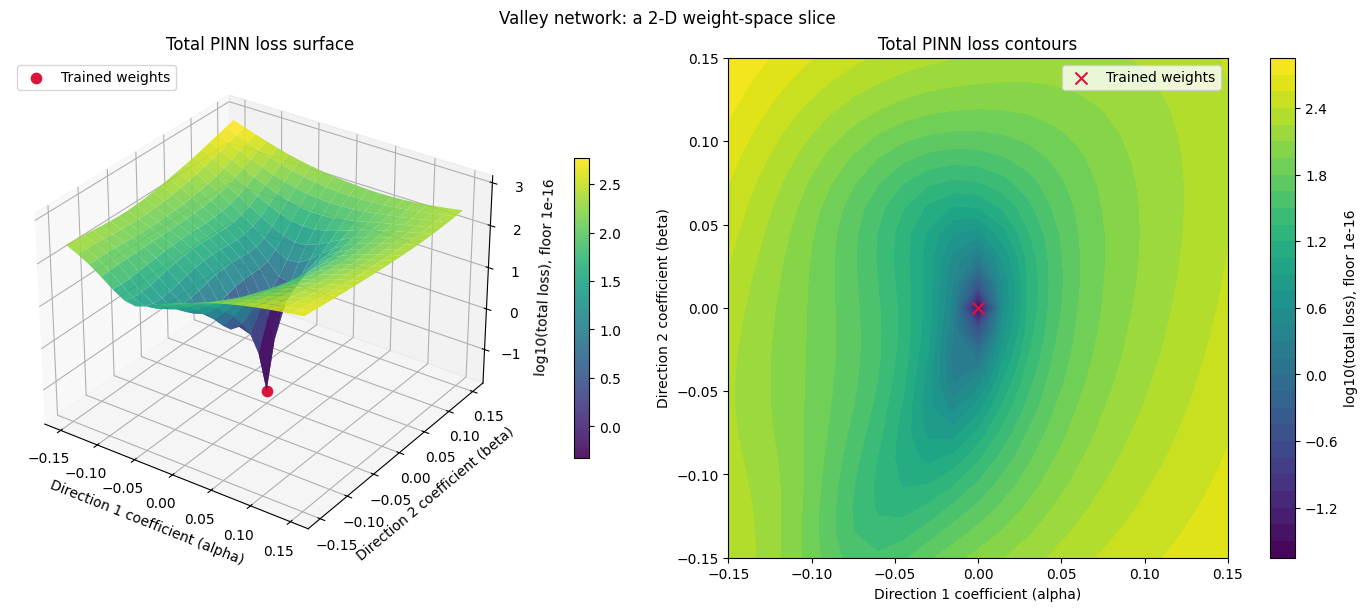

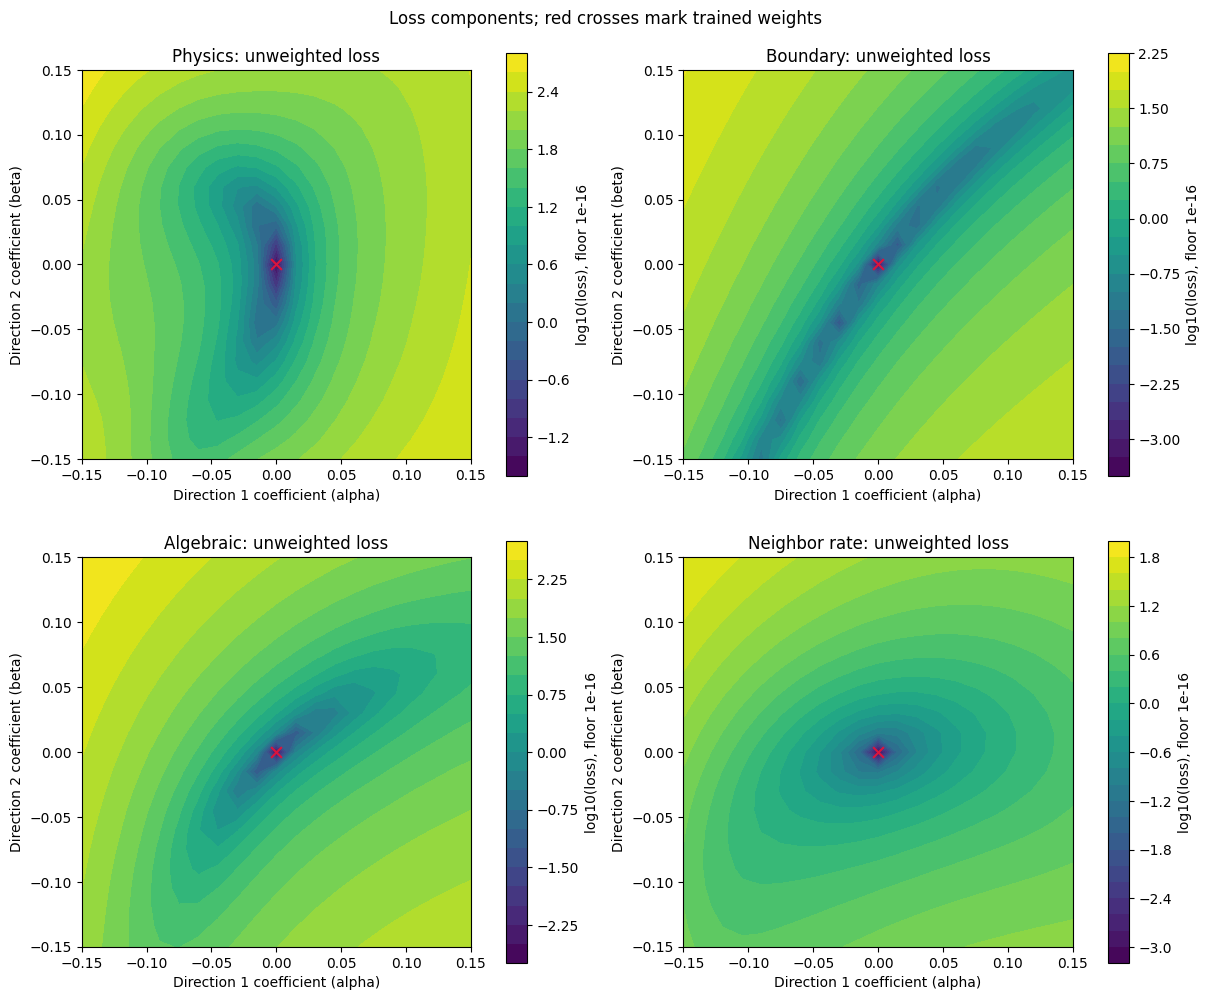

In [13]:
"""Run after the attached Valley exponential PINN training cell.

Plots a two-dimensional slice of the network's loss in weight space,
centered on the current trained weights. This is not an activation surface
or the full high-dimensional loss landscape.

Requires model, Valley, X_MIN, X_MAX, MIN_RATE, MAX_RATE,
MIN_COEFFICIENT, and MAX_COEFFICIENT from the training cell.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def _valley_kernel_directions(weights, rng):
    """Independent directions, scaled to each Dense output filter's norm.

    Only 2-D kernel matrices move. Biases and LayerNormalization parameters
    remain at their trained values. Each kernel column is an output filter.
    """
    directions = []
    for weight in weights:
        if weight.ndim == 2:
            noise = rng.standard_normal(weight.shape)
            column_norm = np.linalg.norm(weight, axis=0, keepdims=True)
            noise_norm = np.linalg.norm(noise, axis=0, keepdims=True)
            noise *= column_norm / np.maximum(noise_norm, 1e-30)
            directions.append(noise.astype(weight.dtype))
        else:
            directions.append(np.zeros_like(weight))
    return directions


def plot_valley_loss_surface(
    trained_model,
    grid_size=21,
    radius=0.15,
    n_samples=256,
    seed=12345,
    log_scale=True,
):
    """Plot the supplied PINN objective around the trained model.

    At (alpha, beta), kernels are W0 + alpha*D1 + beta*D2.
    The center (0, 0) is the trained network. Directions are normalized
    per output filter; radius is a relative kernel perturbation scale.
    Every point uses the same fixed physics and boundary samples.

    The loss exactly follows the supplied objective:
      physics + boundary + 0.125*algebraic + 0.07*neighbor_rate.
    Its sampled values can differ from the final stochastic training loss.

    Returns coordinates, raw loss arrays, center losses, and both figures.
    """
    if (not isinstance(grid_size, (int, np.integer))
            or grid_size < 3 or grid_size % 2 == 0):
        raise ValueError("grid_size must be an odd integer of at least 3.")
    if not np.isscalar(radius) or not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("n_samples must be a positive integer.")
    if MAX_RATE - MIN_RATE < 2:
        raise ValueError(
            "This reproduces the attached neighbor-rate rule, which requires "
            "a rate interval of width at least 2 to keep all rate pairs in bounds."
        )

    # Work on a separate model: the trained model and optimizer are untouched.
    probe_model = tf.keras.models.clone_model(trained_model)
    base_weights = trained_model.get_weights()
    probe_model.set_weights(base_weights)
    dtype = tf.as_dtype(probe_model.compute_dtype)
    numpy_dtype = dtype.as_numpy_dtype
    rng = np.random.default_rng(seed)

    # Fixed evaluation inputs eliminate resampling noise between grid points.
    def uniform(low, high):
        values = rng.uniform(low, high, (n_samples, 1)).astype(numpy_dtype)
        return tf.convert_to_tensor(values, dtype=dtype)

    x = uniform(X_MIN, X_MAX)
    rate = uniform(MIN_RATE, MAX_RATE)
    coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    boundary_rate = uniform(MIN_RATE, MAX_RATE)
    boundary_coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    x_boundary = tf.zeros_like(x)
    exact_derivative = coefficient * rate * tf.exp(rate * x)

    # Reproduce the supplied training code, including negative-A evaluations.
    one = tf.constant(1.0, dtype=dtype)
    max_rate = tf.constant(MAX_RATE, dtype=dtype)
    lower_rate = tf.where(rate <= max_rate - one, rate, rate - one)
    upper_rate = lower_rate + one

    @tf.function
    def evaluate_fixed_loss():
        def predict(x_value, rate_value, a_value):
            return probe_model(
                tf.concat([x_value, rate_value, a_value], axis=1),
                training=False,
            )

        with tf.GradientTape(watch_accessed_variables=False) as tape:
            tape.watch(x)
            u = predict(x, rate, coefficient)
        du_dx = tape.gradient(u, x)
        if du_dx is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        physics = tf.reduce_mean(tf.square(du_dx - exact_derivative))

        u_boundary = predict(x_boundary, boundary_rate, boundary_coefficient)
        boundary = tf.reduce_mean(tf.square(u_boundary - boundary_coefficient))

        u_negative = predict(x, rate, -coefficient)
        algebraic = tf.reduce_mean(tf.square(u + u_negative))

        u_lower = predict(x, lower_rate, coefficient)
        u_upper = predict(x, upper_rate, coefficient)
        neighbor = tf.reduce_mean(tf.square(u_upper - tf.exp(x) * u_lower))

        total = physics + boundary + 0.125 * algebraic + 0.07 * neighbor
        return tf.stack([total, physics, boundary, algebraic, neighbor])

    direction_1 = _valley_kernel_directions(base_weights, rng)
    direction_2 = _valley_kernel_directions(base_weights, rng)
    center_losses = evaluate_fixed_loss().numpy()
    if not np.all(np.isfinite(center_losses)):
        raise FloatingPointError("The trained model has nonfinite loss on the fixed batch.")

    coordinates = np.linspace(-radius, radius, grid_size)
    # Ensure the center is represented exactly.
    coordinates[grid_size // 2] = 0.0
    alpha_grid, beta_grid = np.meshgrid(coordinates, coordinates)
    loss_values = np.empty((5, grid_size, grid_size), dtype=np.float64)

    print(f"Evaluating {grid_size**2:,} weight settings on "
          f"{n_samples:,} fixed samples each...", flush=True)
    try:
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                if row == grid_size // 2 and column == grid_size // 2:
                    values = center_losses
                else:
                    probe_model.set_weights([
                        weight + alpha * d1 + beta * d2
                        for weight, d1, d2 in zip(
                            base_weights, direction_1, direction_2
                        )
                    ])
                    values = evaluate_fixed_loss().numpy()
                loss_values[:, row, column] = values
            print(f"Completed row {row + 1}/{grid_size}", flush=True)
    finally:
        probe_model.set_weights(base_weights)

    invalid = ~np.isfinite(loss_values)
    if np.any(invalid):
        print("Some perturbed settings had nonfinite losses; "
              "they will appear as gaps in the plots.")
    loss_values[invalid] = np.nan
    floor = 1e-16

    def display_values(values):
        if log_scale:
            return np.log10(np.maximum(values, floor))
        return values

    height_label = "log10(total loss), floor 1e-16" if log_scale else "Total loss"
    total_height = display_values(loss_values[0])
    center_height = float(display_values(center_losses[0]))

    # Figure 1: total objective, viewed as a 3-D surface and a contour map.
    fig_total = plt.figure(figsize=(14, 6), layout="constrained")
    ax_surface = fig_total.add_subplot(1, 2, 1, projection="3d")
    surface = ax_surface.plot_surface(
        alpha_grid, beta_grid, total_height, cmap="viridis",
        edgecolor="none", alpha=0.9,
    )
    ax_surface.scatter(0, 0, center_height, color="crimson", s=55,
                       depthshade=False, label="Trained weights")
    ax_surface.set(xlabel="Direction 1 coefficient (alpha)",
                   ylabel="Direction 2 coefficient (beta)",
                   zlabel=height_label, title="Total PINN loss surface")
    ax_surface.view_init(elev=30, azim=-55)
    ax_surface.legend(loc="upper left")
    fig_total.colorbar(surface, ax=ax_surface, shrink=0.6, pad=0.12)

    ax_contour = fig_total.add_subplot(1, 2, 2)
    contour = ax_contour.contourf(
        alpha_grid, beta_grid, np.ma.masked_invalid(total_height),
        levels=30, cmap="viridis",
    )
    ax_contour.scatter(0, 0, color="crimson", marker="x", s=75,
                       label="Trained weights")
    ax_contour.set(xlabel="Direction 1 coefficient (alpha)",
                   ylabel="Direction 2 coefficient (beta)",
                   title="Total PINN loss contours", aspect="equal")
    ax_contour.legend()
    fig_total.colorbar(contour, ax=ax_contour, label=height_label)
    fig_total.suptitle("Valley network: a 2-D weight-space slice")

    # Figure 2: unweighted components, each with its own color scale.
    component_names = ["Physics", "Boundary", "Algebraic", "Neighbor rate"]
    fig_components, axes = plt.subplots(
        2, 2, figsize=(12, 10), layout="constrained"
    )
    for index, (ax, name) in enumerate(zip(axes.ravel(), component_names), start=1):
        plotted = display_values(loss_values[index])
        contour = ax.contourf(
            alpha_grid, beta_grid, np.ma.masked_invalid(plotted),
            levels=25, cmap="viridis",
        )
        ax.scatter(0, 0, color="crimson", marker="x", s=60)
        ax.set(xlabel="Direction 1 coefficient (alpha)",
               ylabel="Direction 2 coefficient (beta)",
               title=f"{name}: unweighted loss", aspect="equal")
        label = "log10(loss), floor 1e-16" if log_scale else "Loss"
        fig_components.colorbar(contour, ax=ax, label=label)
    fig_components.suptitle("Loss components; red crosses mark trained weights")

    names = ["total", "physics", "boundary", "algebraic", "neighbor_rate"]
    print("\nLoss at trained weights on the fixed batch:")
    for name, value in zip(names, center_losses):
        print(f"  {name:<15} {value:.8e}")
    plt.show()

    return {
        "alpha": alpha_grid,
        "beta": beta_grid,
        "losses": {name: loss_values[i] for i, name in enumerate(names)},
        "center_losses": dict(zip(names, center_losses)),
        "seed": seed,
        "n_samples": n_samples,
        "figure_total": fig_total,
        "figure_components": fig_components,
    }


# Run this cell/file AFTER training your Valley model.
loss_surface_results = plot_valley_loss_surface(
    model,
    grid_size=21,      # Odd; use 11 for a quicker preview or 31 for more detail.
    radius=0.15,       # Decrease for a closer view around the trained weights.
    n_samples=256,    # Increase for a more representative sampled objective.
    seed=12345,        # Change to inspect a different batch and direction plane.
    log_scale=True,    # False shows the raw loss heights/colors.
)


Evaluating 441 weight settings on 256 fixed samples each...
Completed row 1/21
Completed row 2/21
Completed row 3/21
Completed row 4/21
Completed row 5/21
Completed row 6/21
Completed row 7/21
Completed row 8/21
Completed row 9/21
Completed row 10/21
Completed row 11/21
Completed row 12/21
Completed row 13/21
Completed row 14/21
Completed row 15/21
Completed row 16/21
Completed row 17/21
Completed row 18/21
Completed row 19/21
Completed row 20/21
Completed row 21/21

Loss at trained weights on the fixed batch:
  total           9.63298639e-02
  physics         9.14625335e-02
  boundary        1.24705920e-03
  algebraic       2.79166003e-02
  neighbor_rate   1.86708898e-03
Base quantity: log10(loss), floored at 1e-16.
Display centering/scaling is specified in each plot caption.


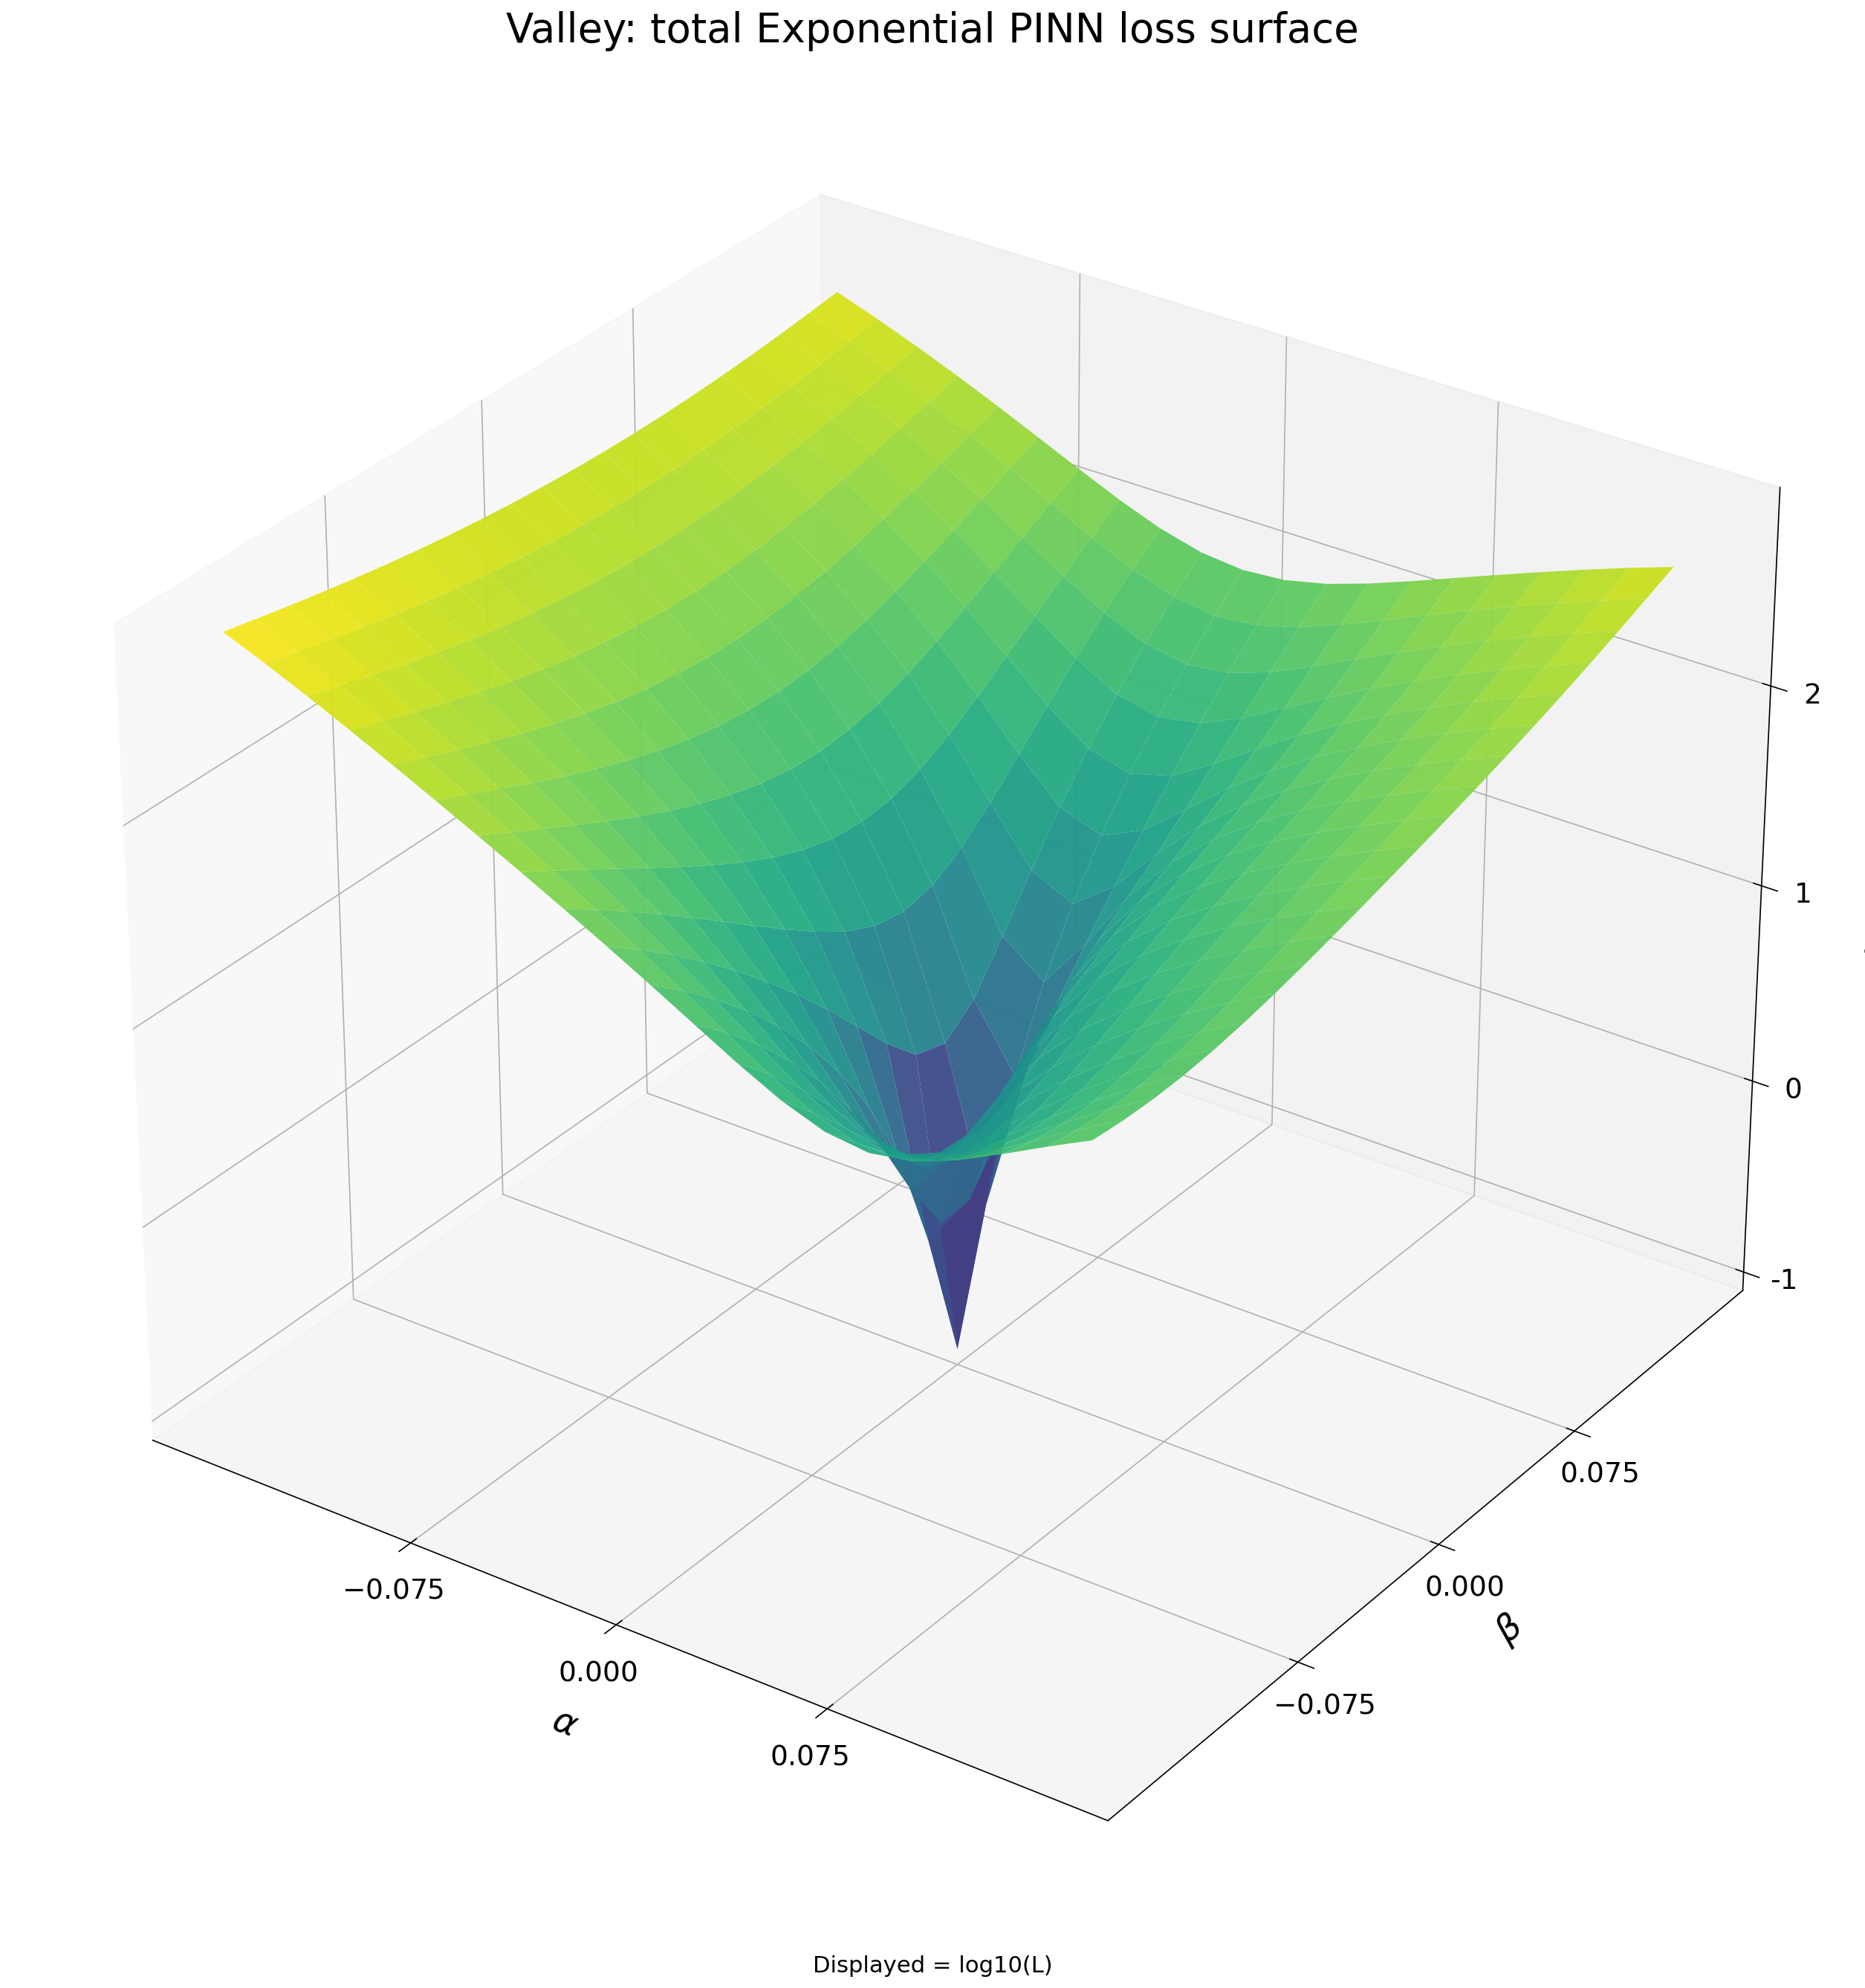

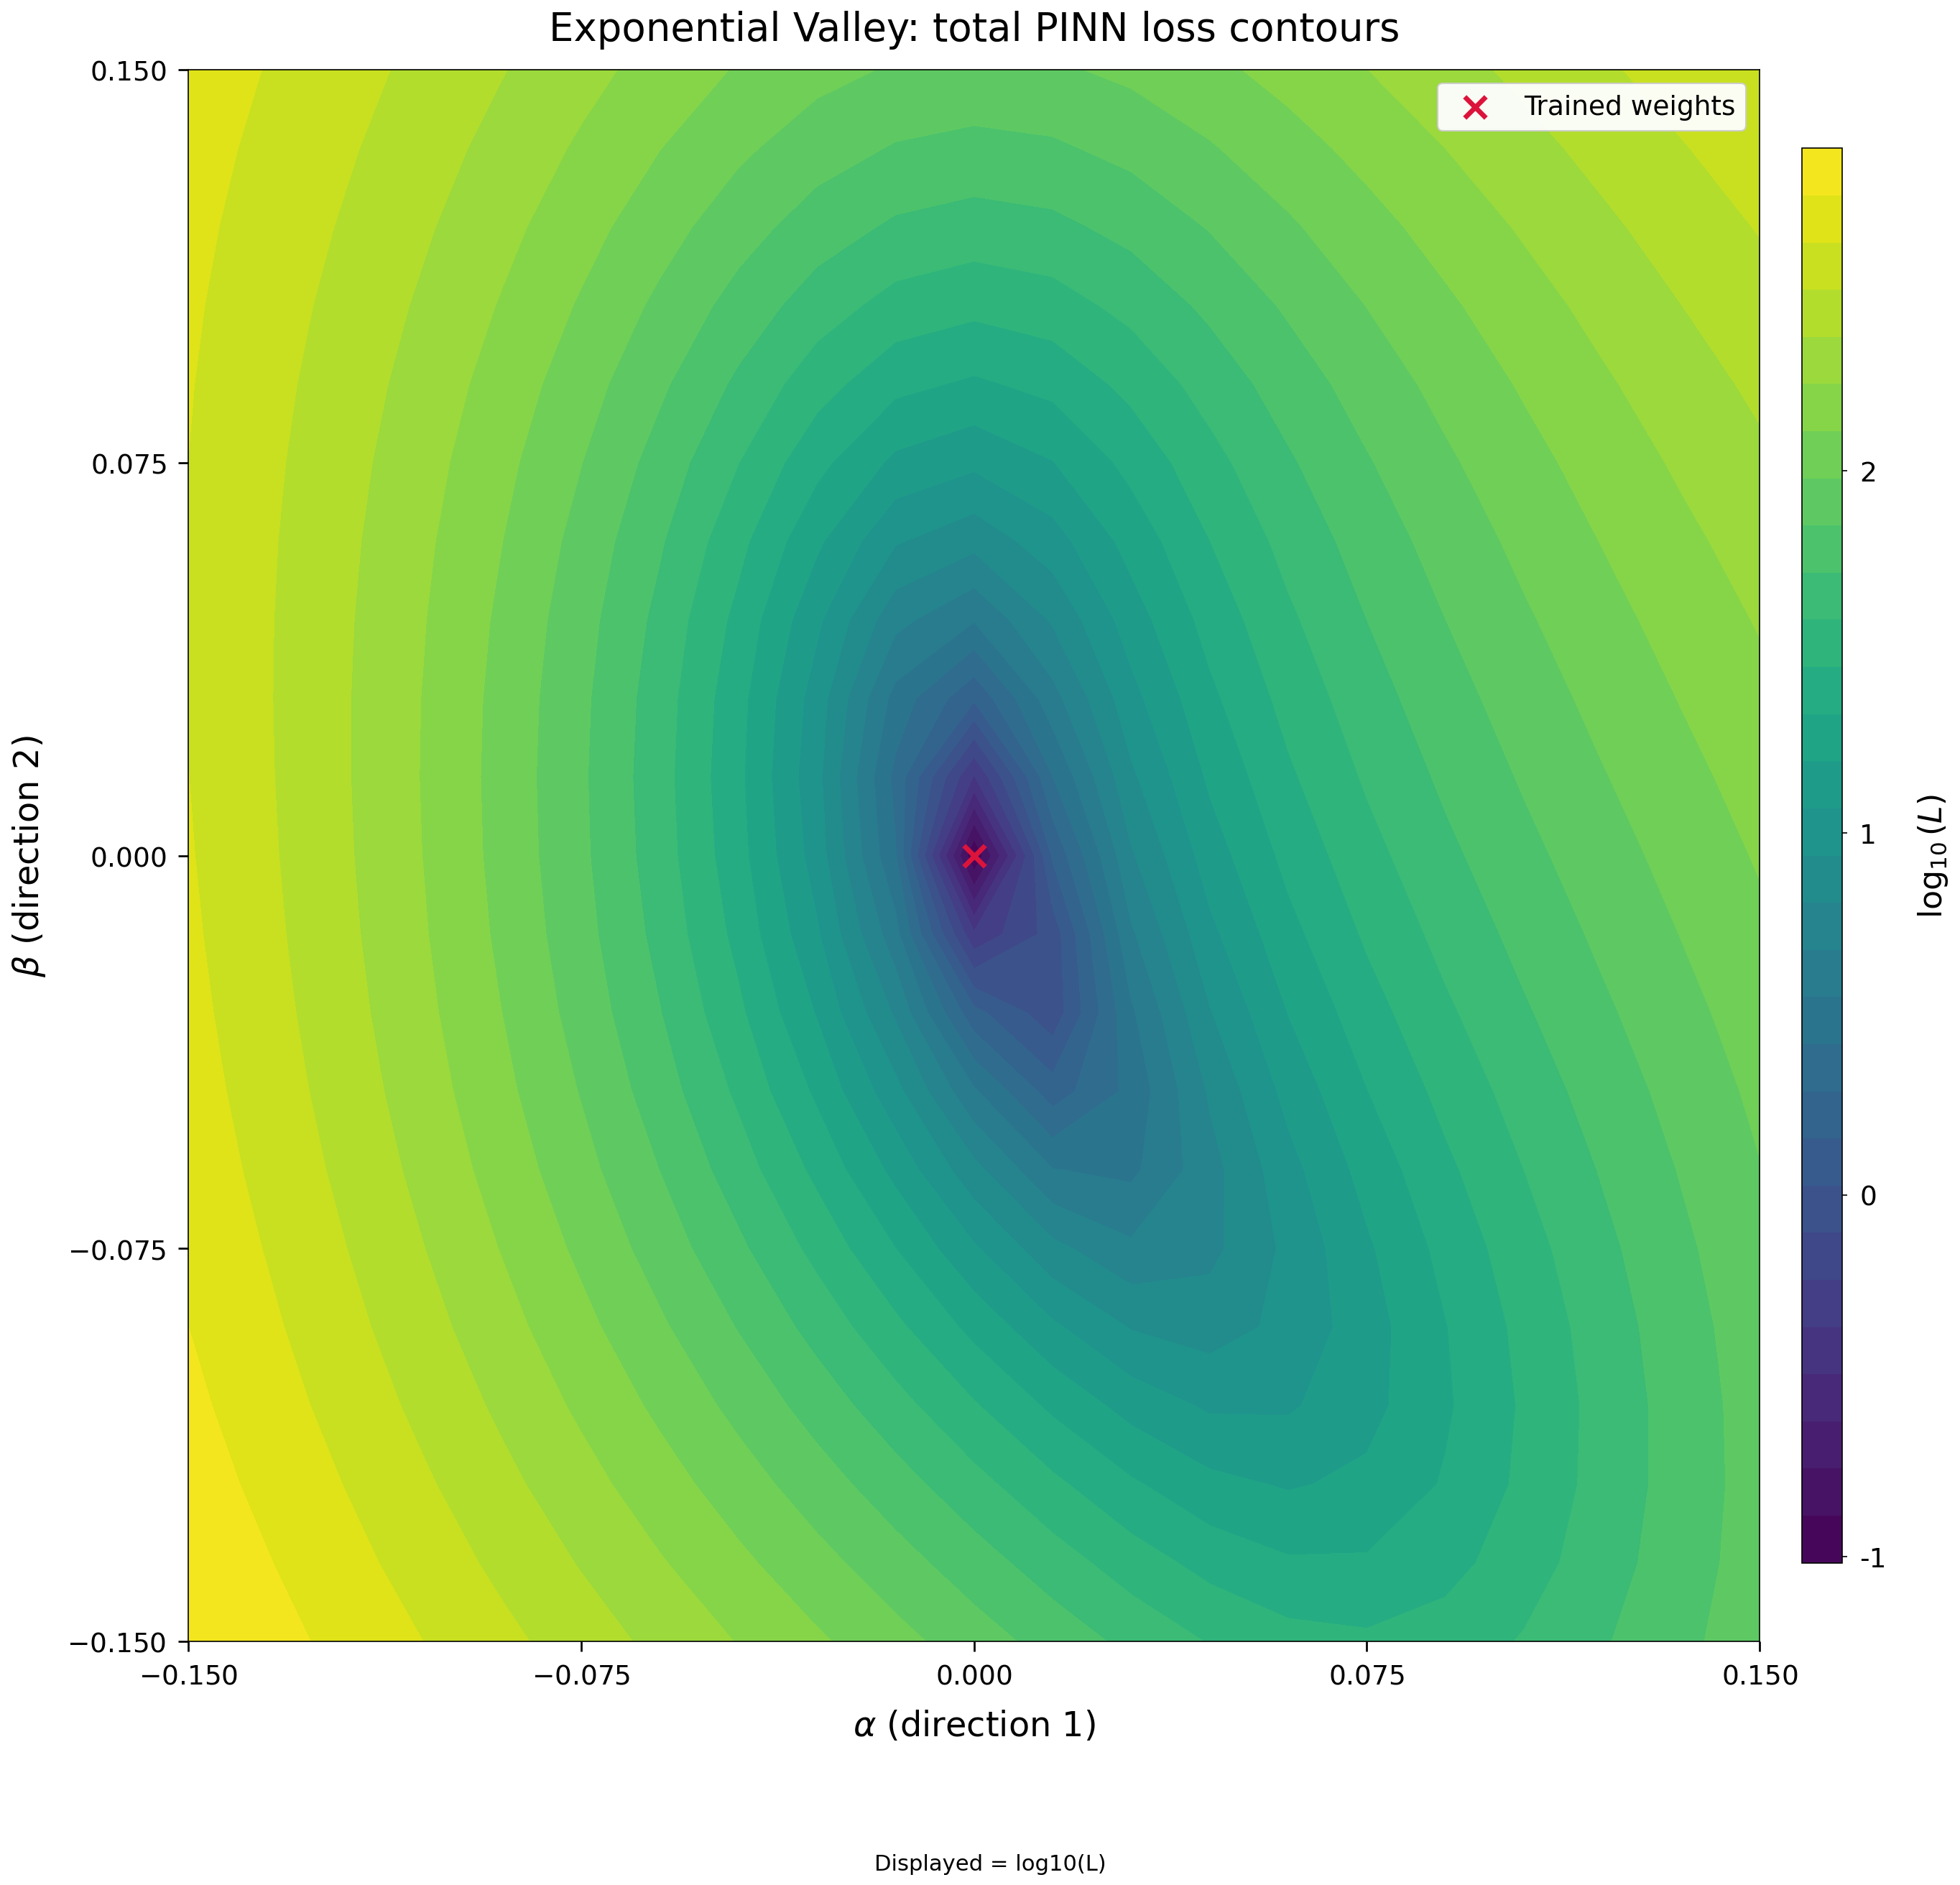

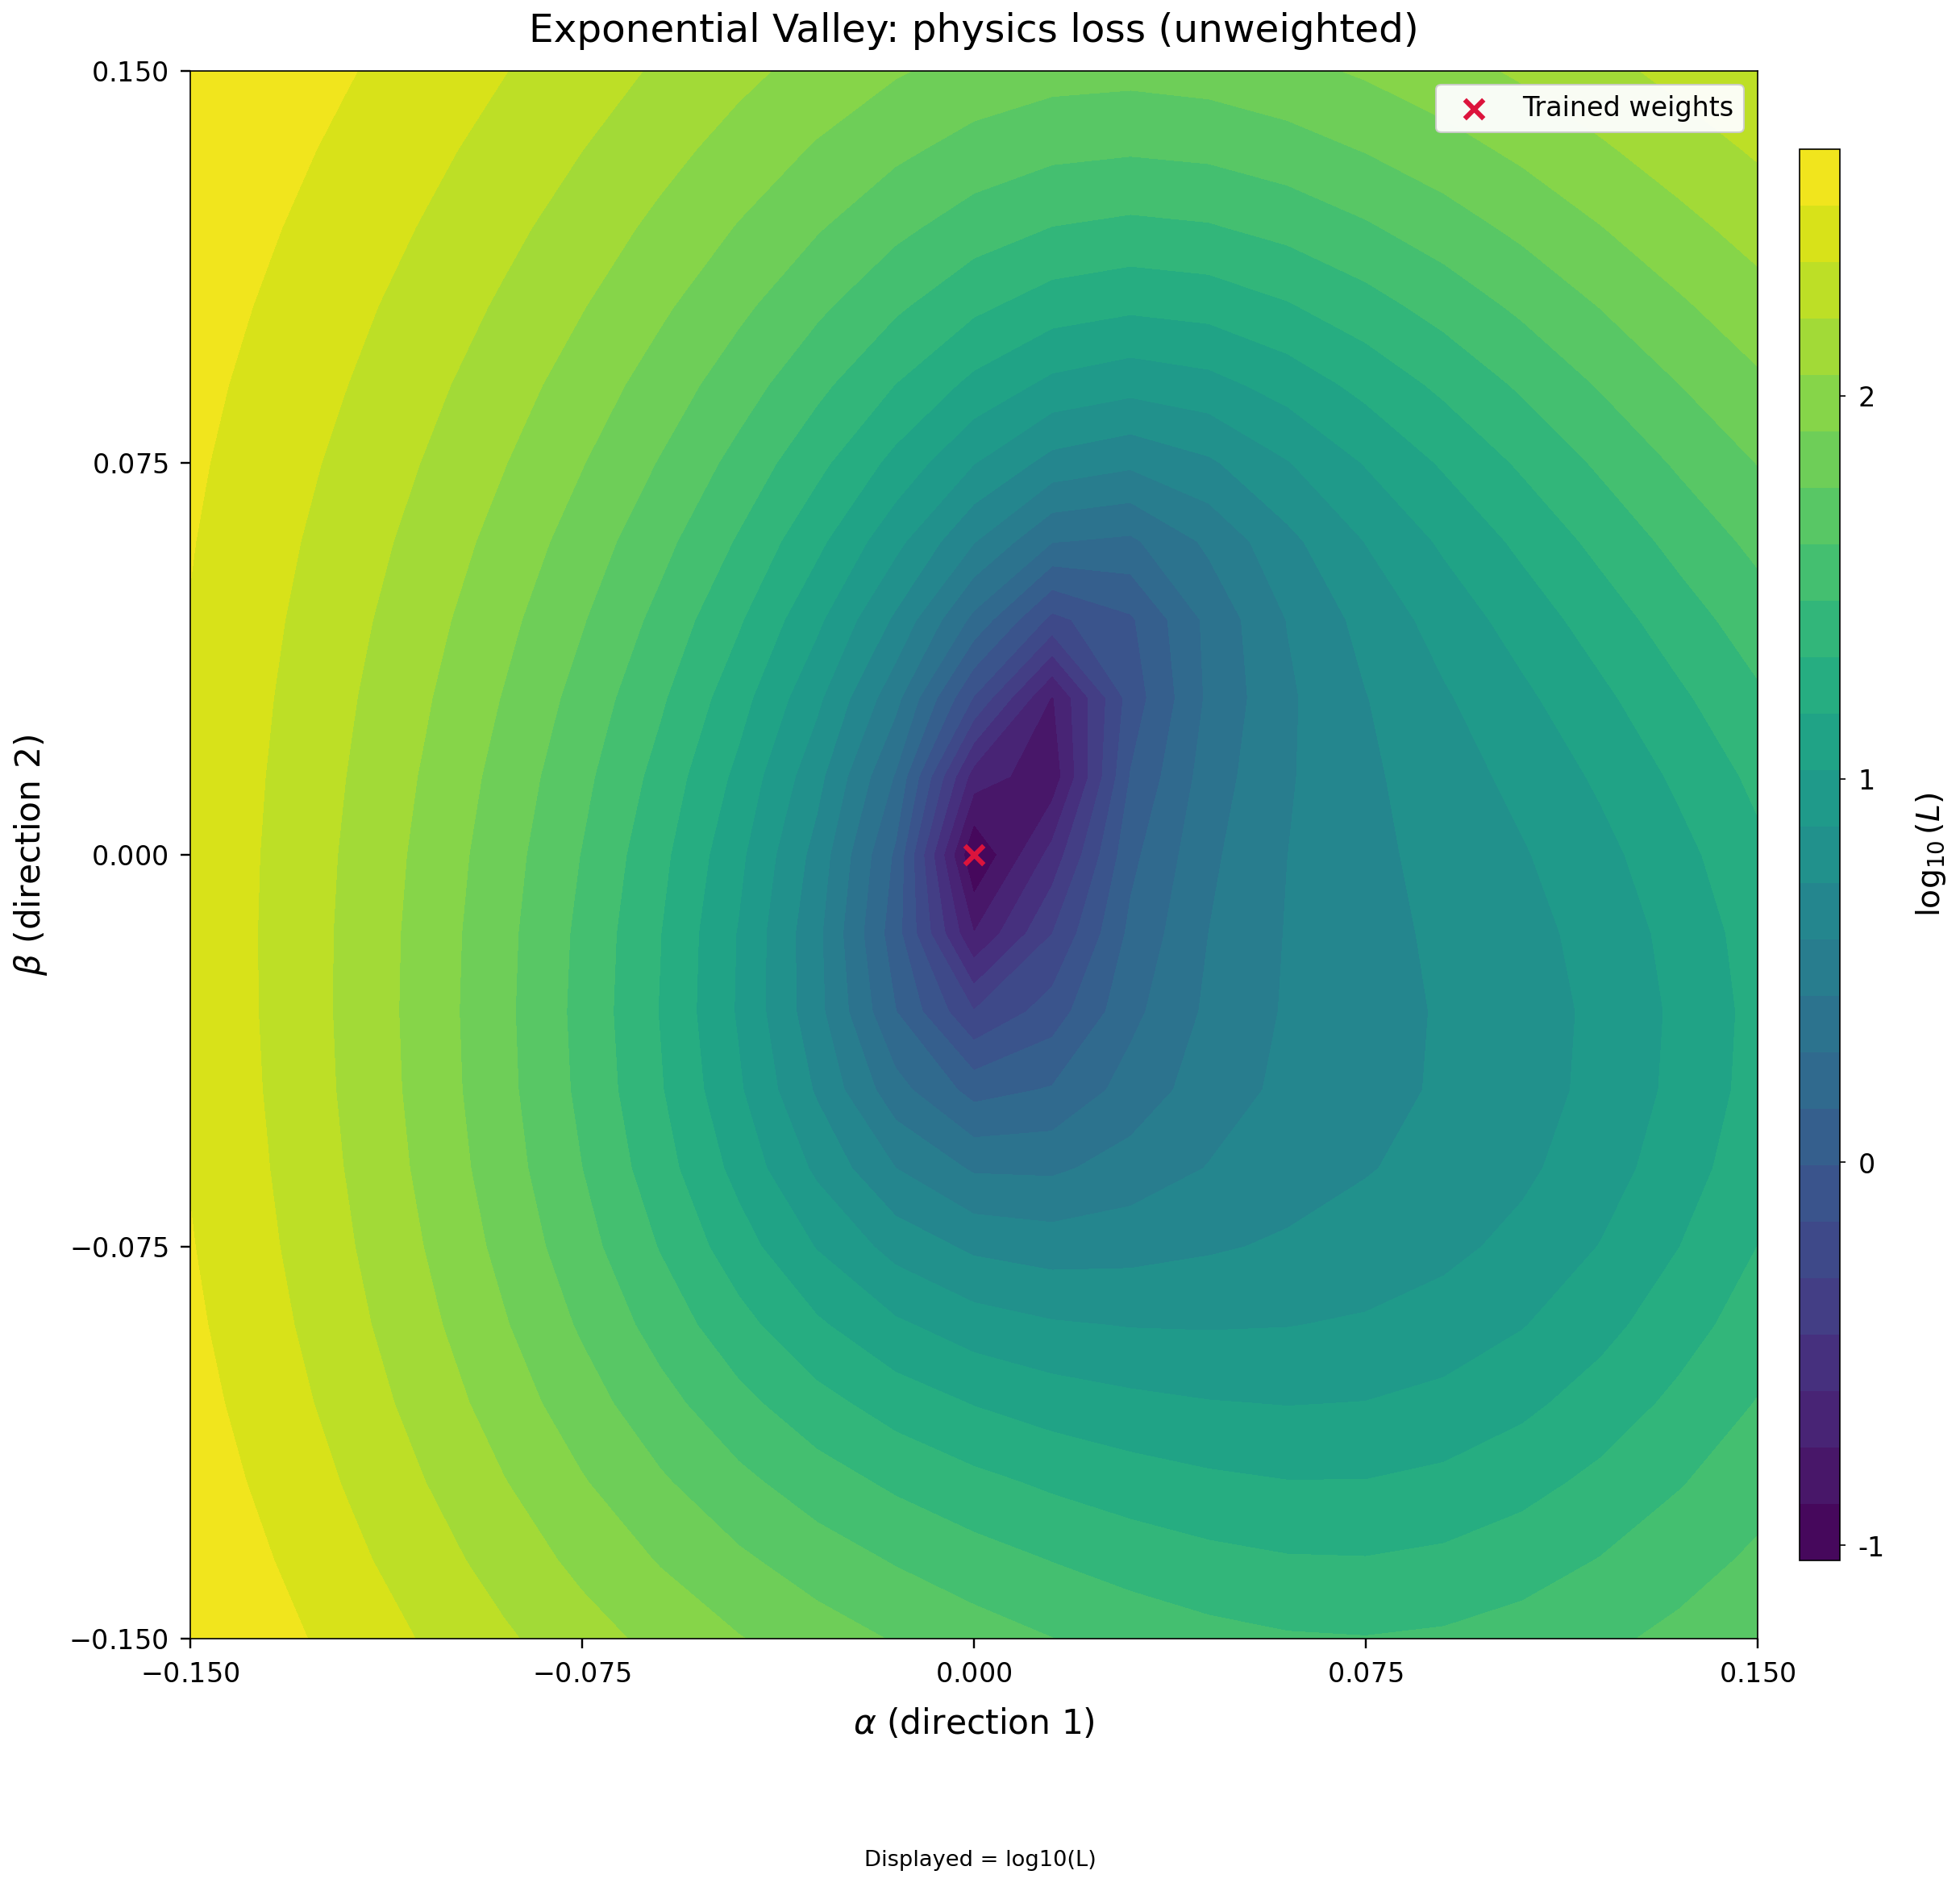

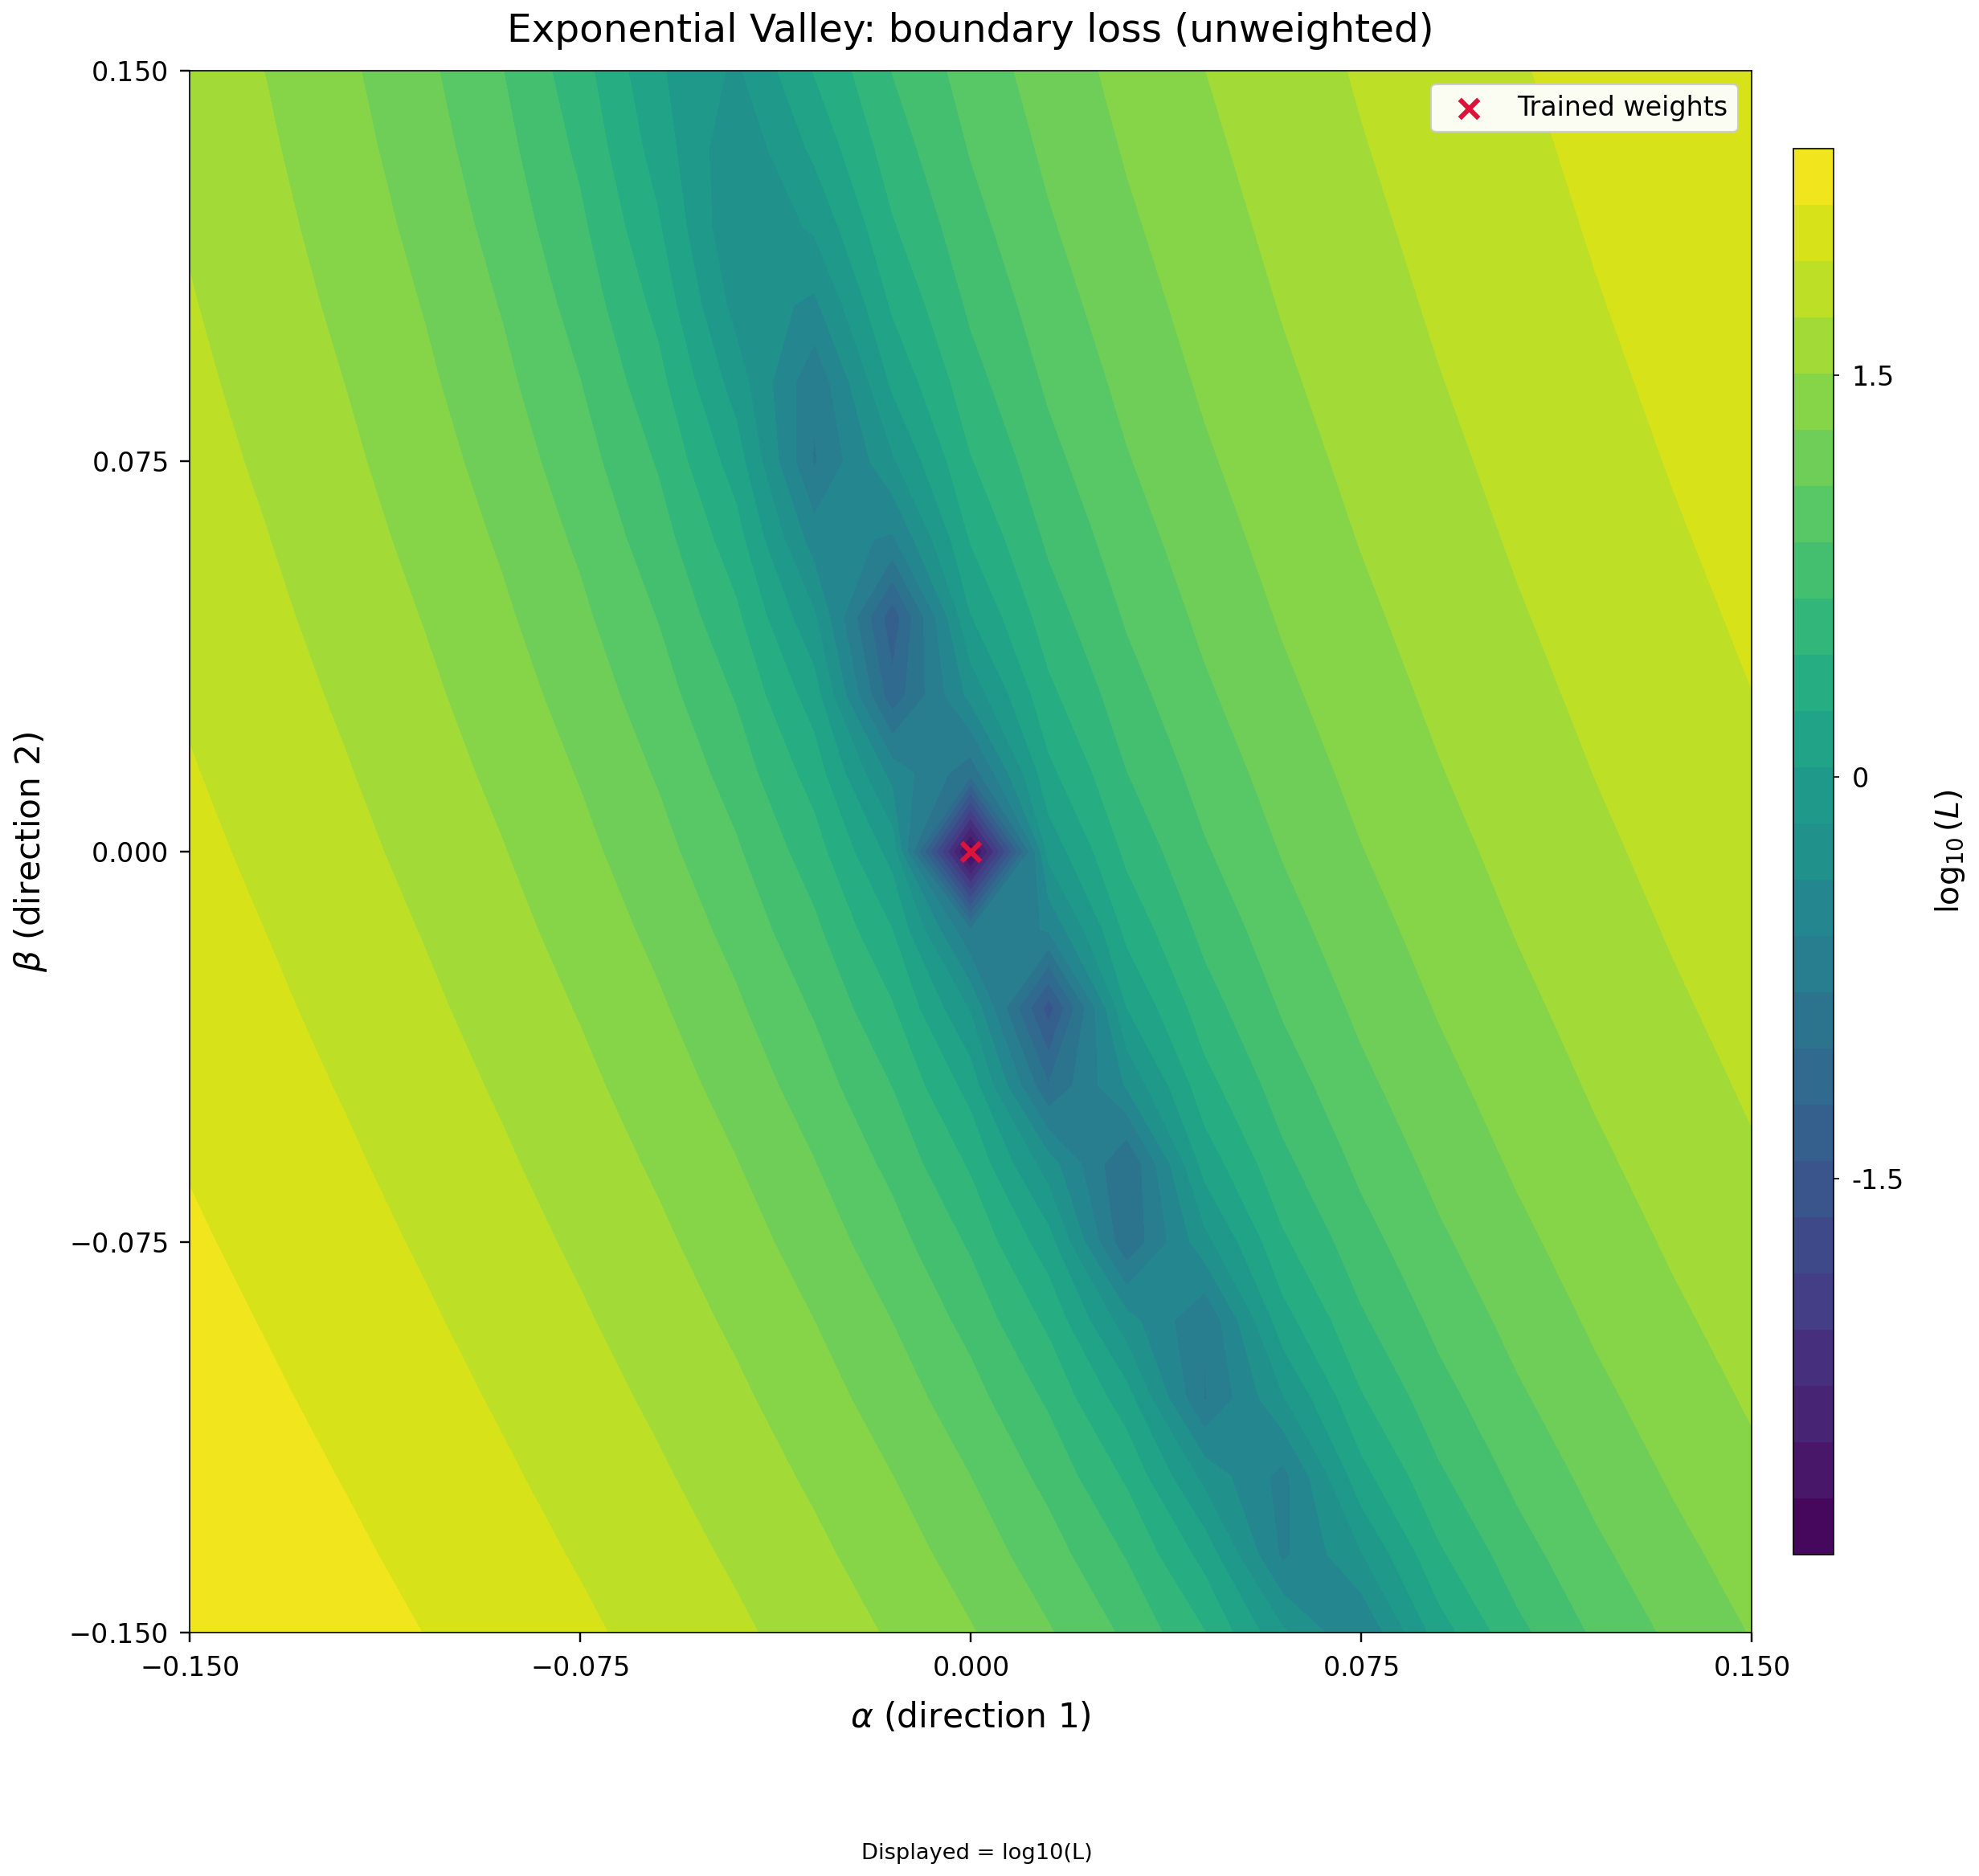

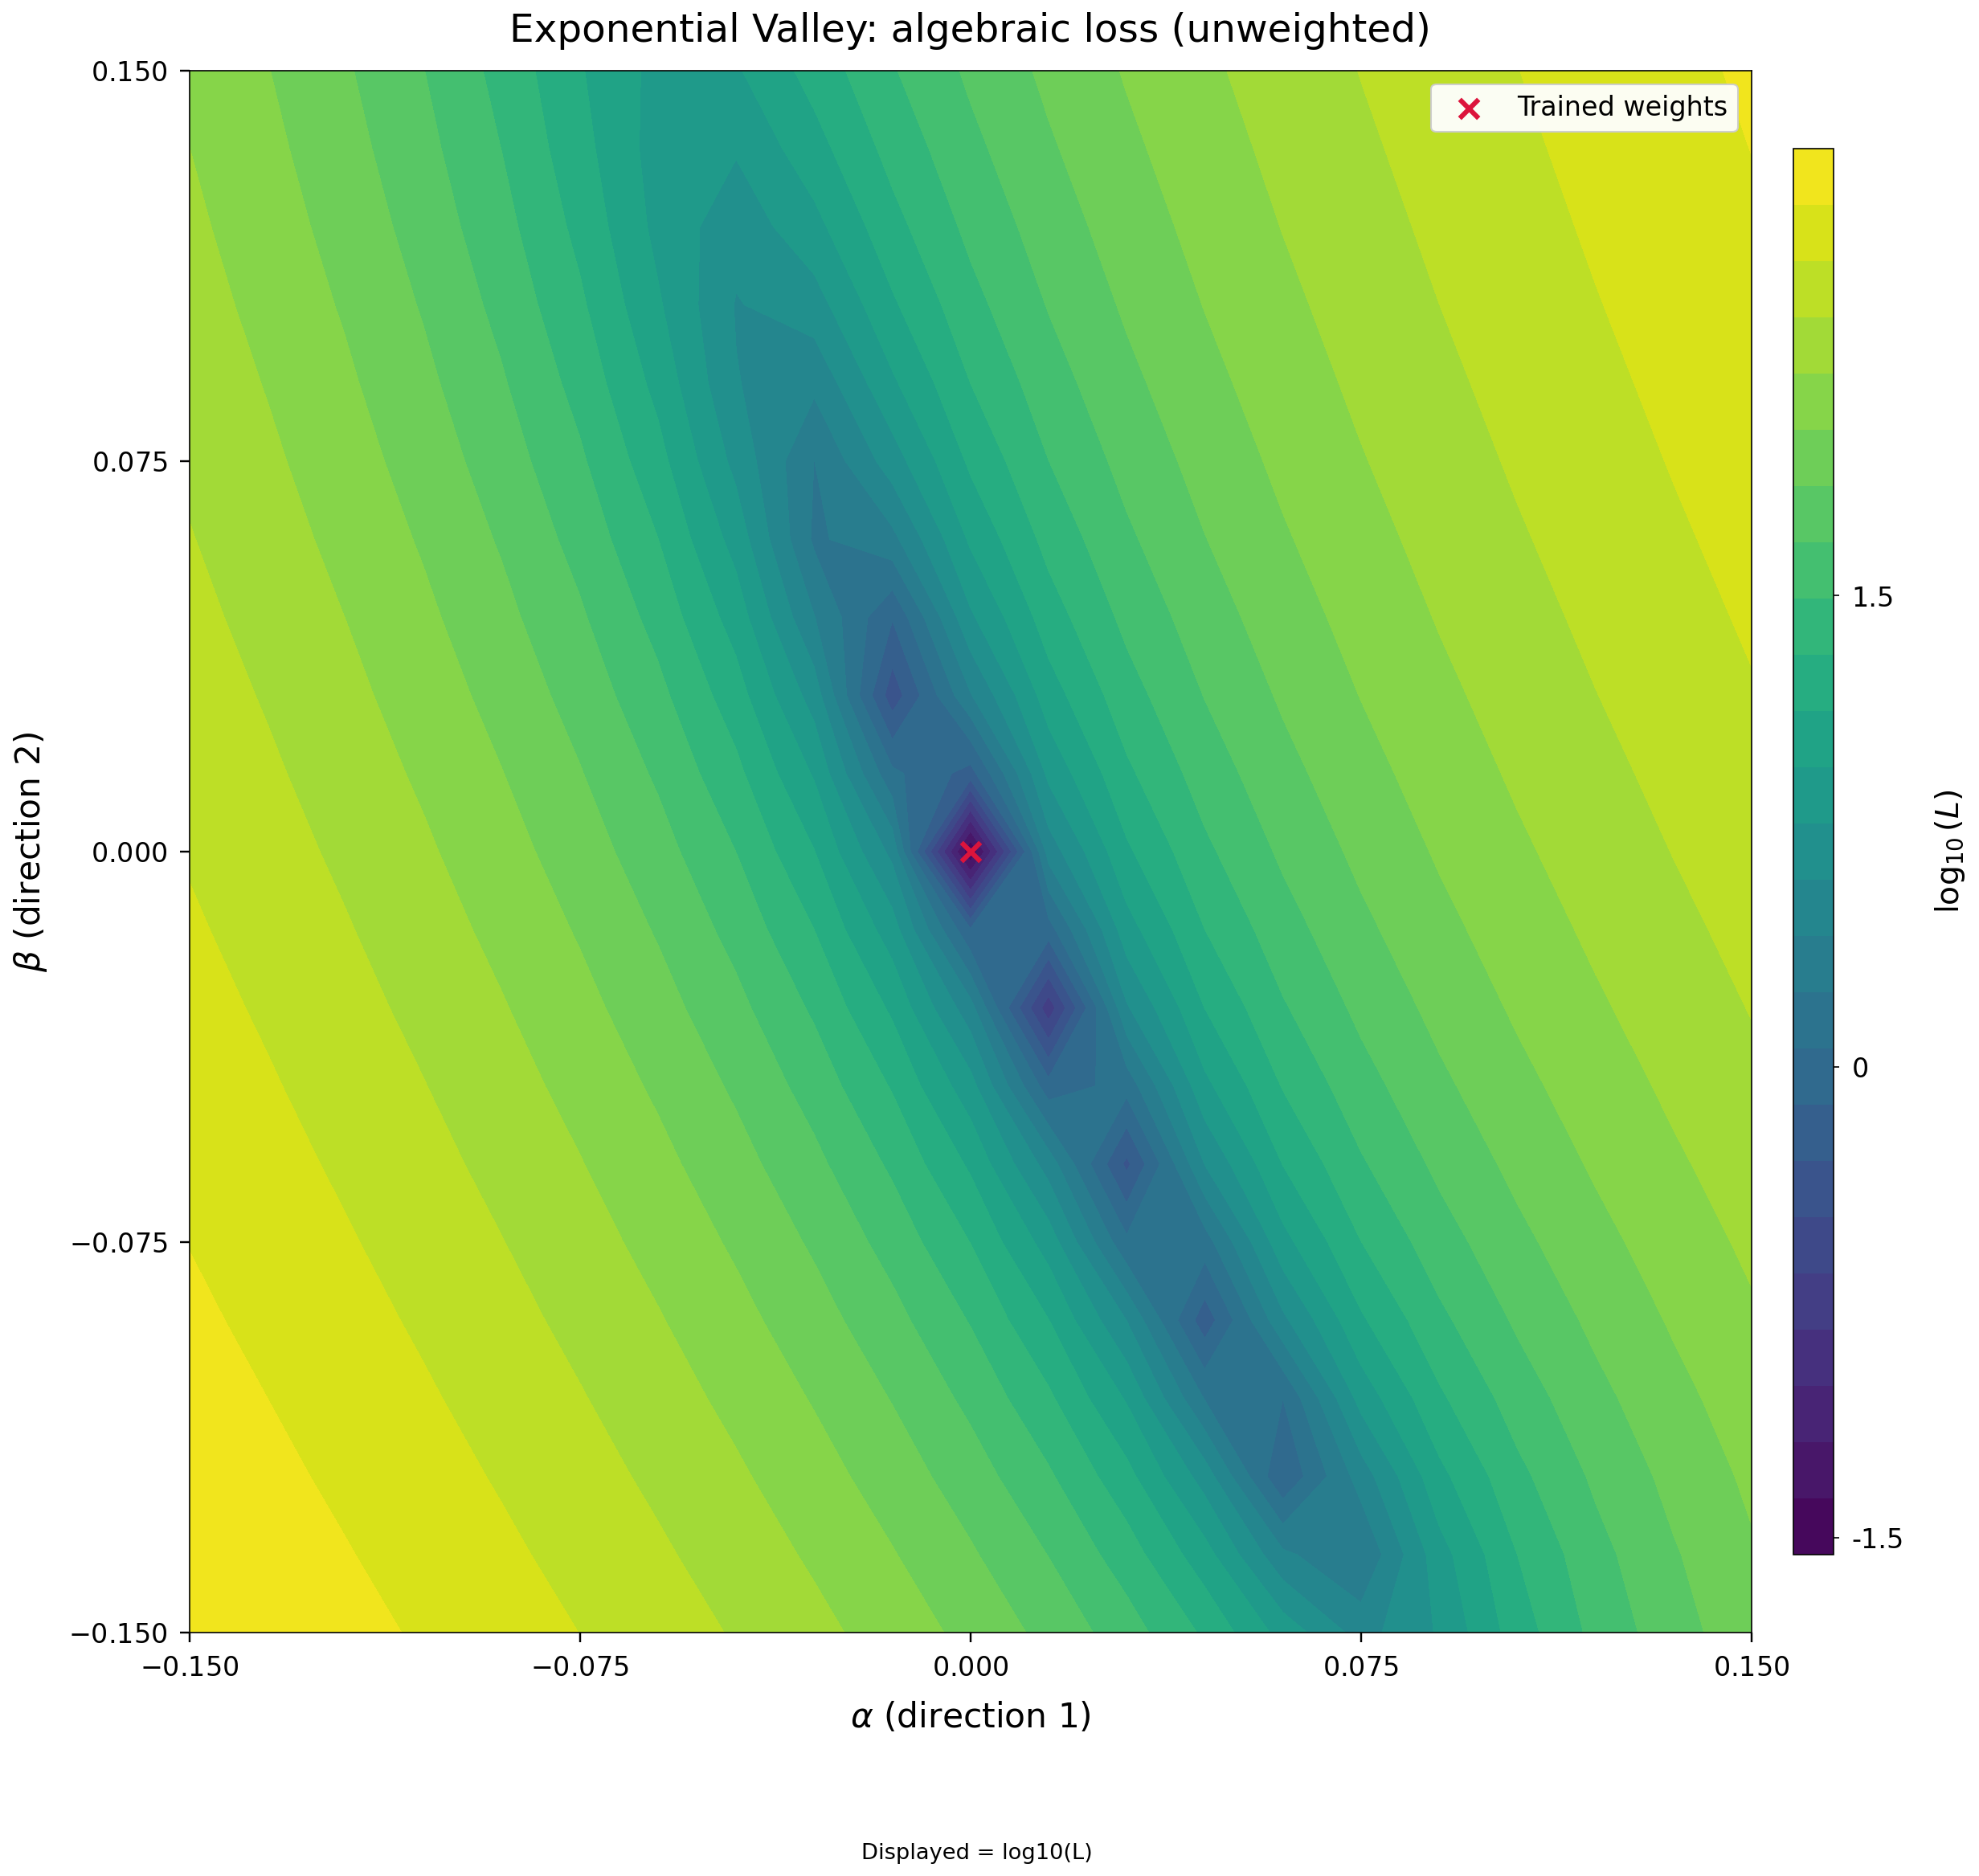

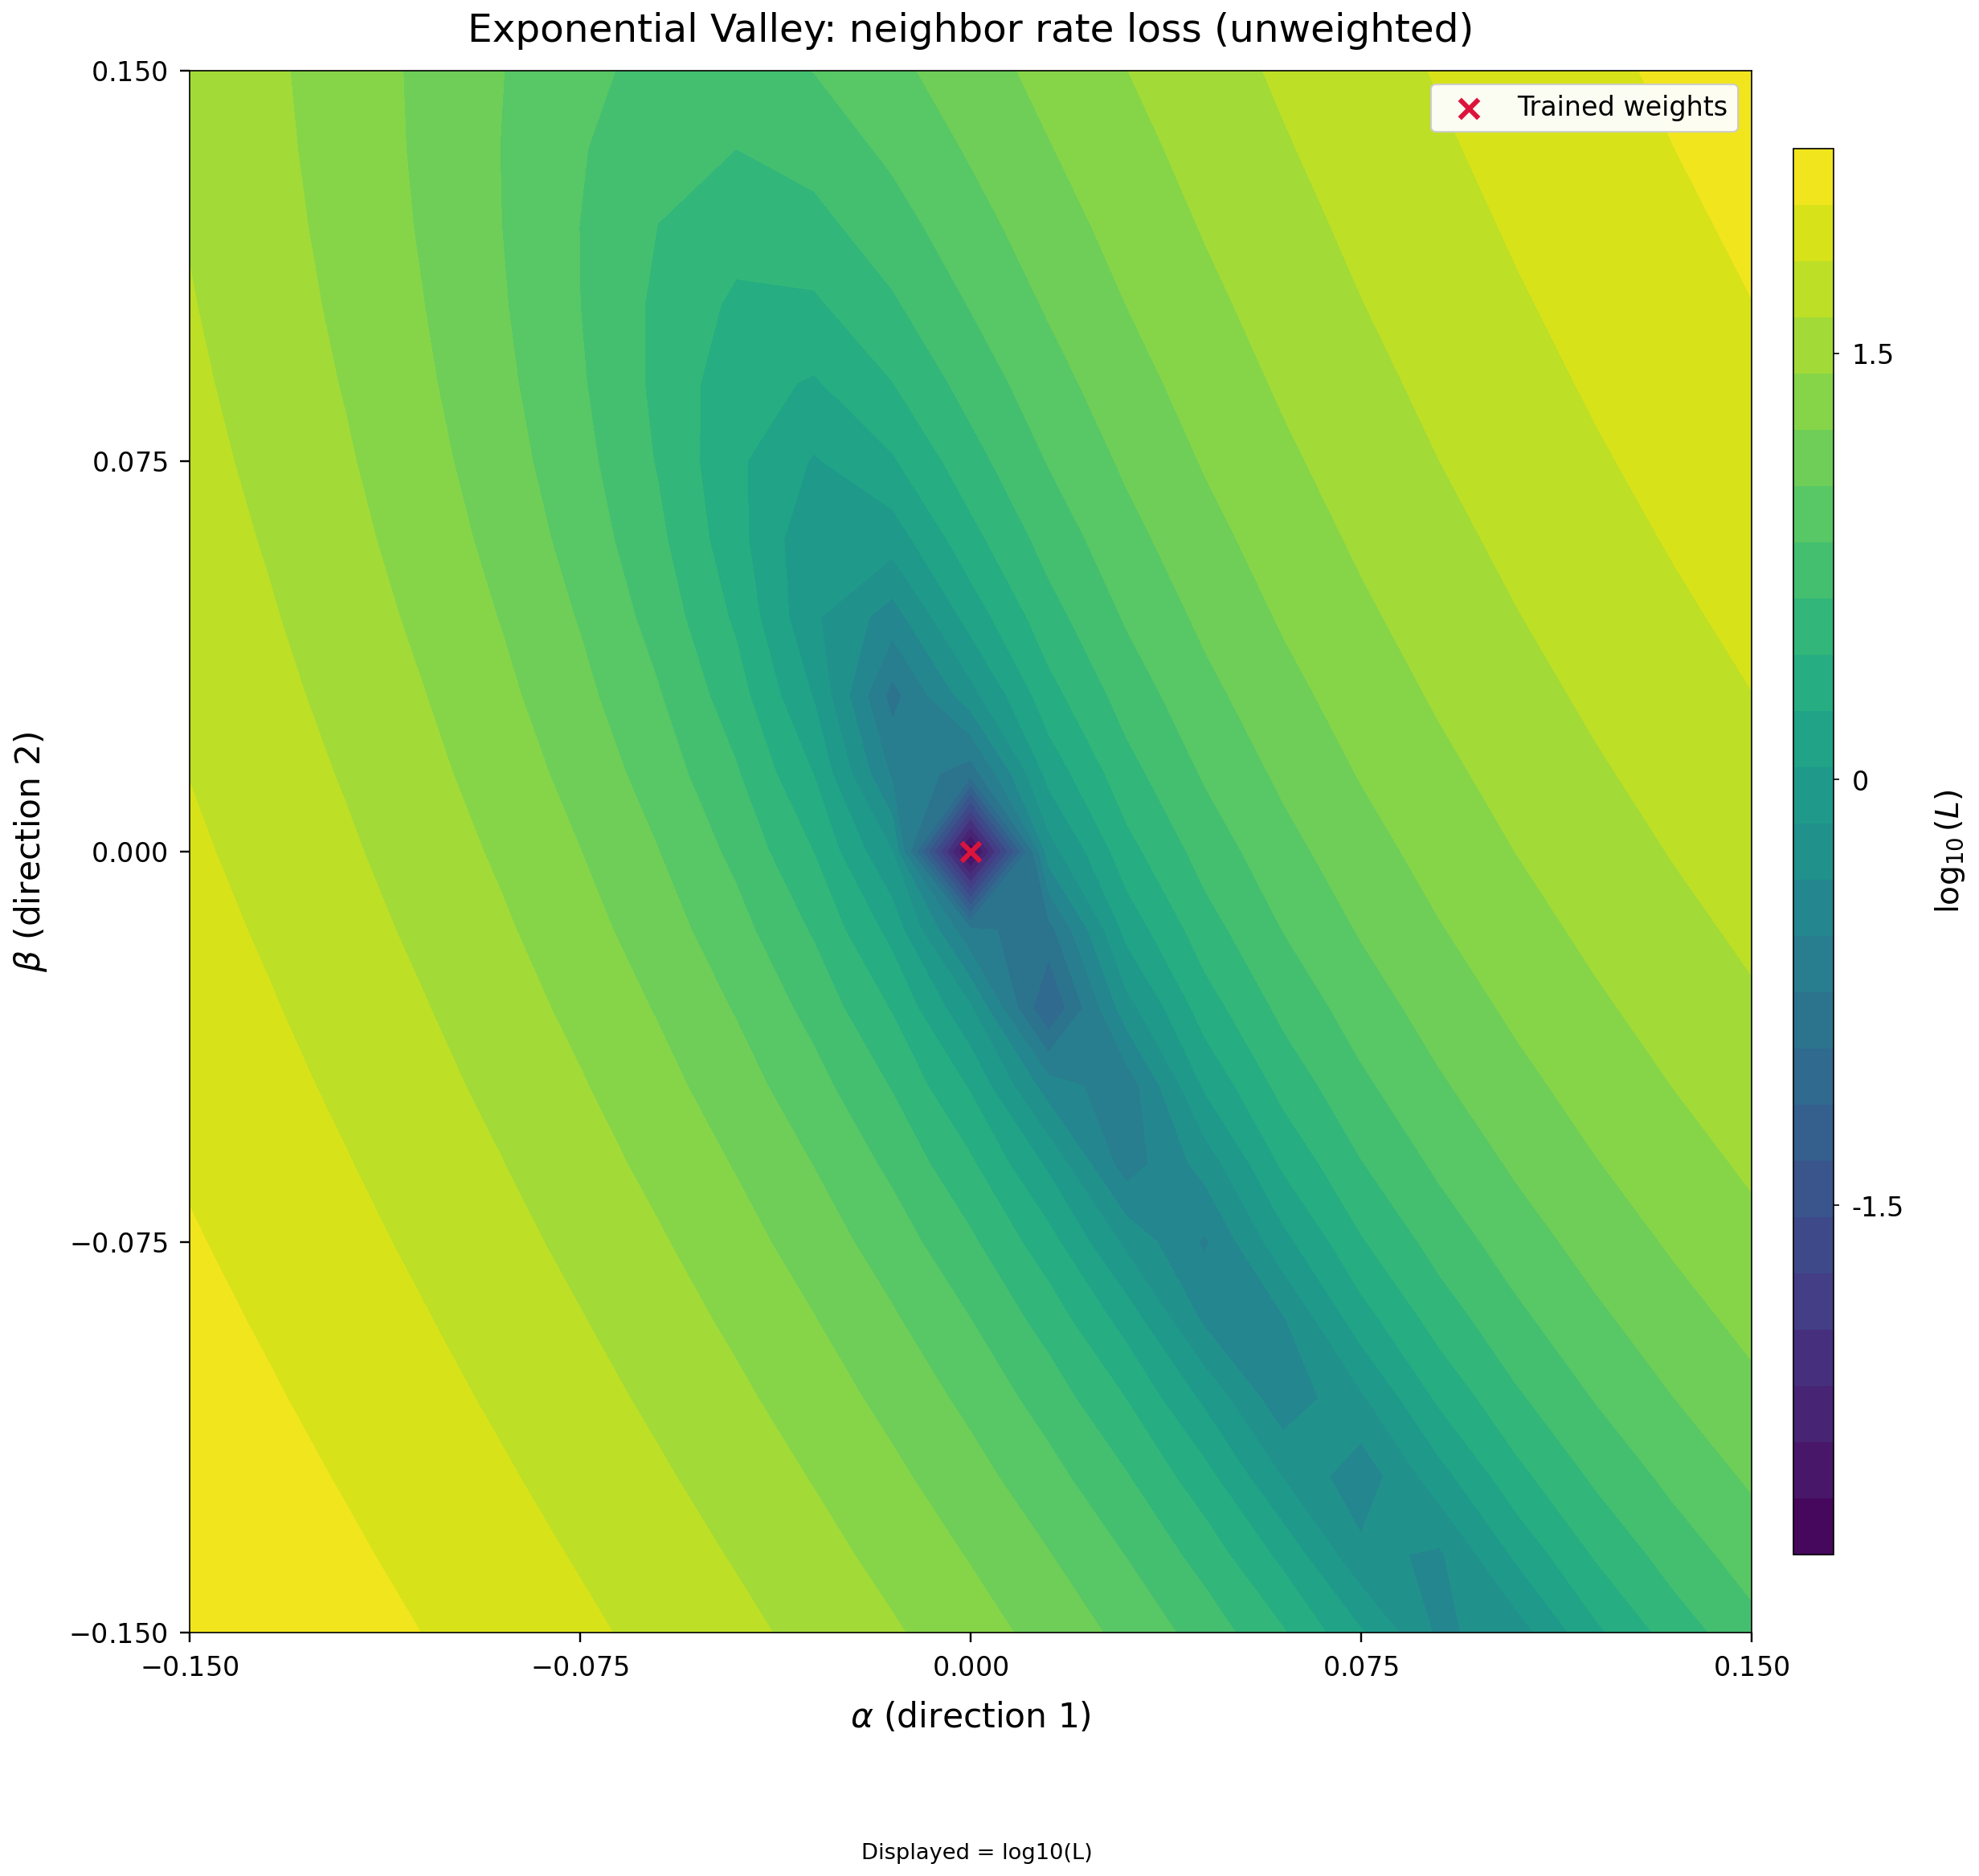

In [25]:
"""Run after training your exponential PINN: u(x, b, A) = A*exp(b*x).

Plots a two-dimensional slice of the network's loss in weight space,
centered on the current trained weights. This is not an activation surface
or the full high-dimensional loss landscape.

Requires model, X_MIN, X_MAX, MIN_RATE, MAX_RATE, MIN_COEFFICIENT,
and MAX_COEFFICIENT from the exponential training cell. Keep any custom
activation class (such as Valley) registered when cloning its model.
"""

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


def _valley_kernel_directions(weights, rng):
    """Independent directions, scaled to each Dense output filter's norm.

    Only 2-D kernel matrices move. Biases and LayerNormalization parameters
    remain at their trained values. Each kernel column is an output filter.
    """
    directions = []
    for weight in weights:
        if weight.ndim == 2:
            noise = rng.standard_normal(weight.shape)
            column_norm = np.linalg.norm(weight, axis=0, keepdims=True)
            noise_norm = np.linalg.norm(noise, axis=0, keepdims=True)
            noise *= column_norm / np.maximum(noise_norm, 1e-30)
            directions.append(noise.astype(weight.dtype))
        else:
            directions.append(np.zeros_like(weight))
    return directions


def plot_exponential_loss_surface(
    trained_model,
    grid_size=21,
    radius=0.15,
    n_samples=256,
    seed=12345,
    log_scale=True,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
):
    """Plot the supplied PINN objective around the trained model.

    At (alpha, beta), kernels are W0 + alpha*D1 + beta*D2.
    The center (0, 0) is the trained network. Directions are normalized
    per output filter; radius is a relative kernel perturbation scale.
    Every point uses the same fixed physics and boundary samples.

    The loss exactly follows the supplied objective:
      physics + boundary + 0.125*algebraic + 0.07*neighbor_rate.
    Its sampled values can differ from the final stochastic training loss.

    Returns coordinates, raw loss arrays, center losses, and figure handles.
    """
    if (not isinstance(grid_size, (int, np.integer))
            or grid_size < 3 or grid_size % 2 == 0):
        raise ValueError("grid_size must be an odd integer of at least 3.")
    if not np.isscalar(radius) or not np.isfinite(radius) or radius <= 0:
        raise ValueError("radius must be a positive finite number.")
    if not isinstance(n_samples, (int, np.integer)) or n_samples <= 0:
        raise ValueError("n_samples must be a positive integer.")

    # Work on a separate model: the trained model and optimizer are untouched.
    probe_model = tf.keras.models.clone_model(trained_model)
    base_weights = trained_model.get_weights()
    probe_model.set_weights(base_weights)
    dtype = tf.as_dtype(probe_model.compute_dtype)
    numpy_dtype = dtype.as_numpy_dtype
    rng = np.random.default_rng(seed)

    # Fixed evaluation inputs eliminate resampling noise between grid points.
    def uniform(low, high):
        values = rng.uniform(low, high, (n_samples, 1)).astype(numpy_dtype)
        return tf.convert_to_tensor(values, dtype=dtype)

    x = uniform(X_MIN, X_MAX)
    rate = uniform(MIN_RATE, MAX_RATE)
    coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    boundary_rate = uniform(MIN_RATE, MAX_RATE)
    boundary_coefficient = uniform(MIN_COEFFICIENT, MAX_COEFFICIENT)
    x_boundary = tf.zeros_like(x)
    exact_derivative = coefficient * rate * tf.exp(rate * x)

    # Reproduce the exponential training objective, including negative-A queries.
    # For rate intervals narrower than 2, the original neighbor rule may
    # query below MIN_RATE; retain this behavior to match the trained loss.
    one = tf.constant(1.0, dtype=dtype)
    max_rate = tf.constant(MAX_RATE, dtype=dtype)
    lower_rate = tf.where(rate <= max_rate - one, rate, rate - one)
    upper_rate = lower_rate + one

    @tf.function
    def evaluate_fixed_loss():
        def predict(x_value, rate_value, a_value):
            return probe_model(
                tf.concat([x_value, rate_value, a_value], axis=1),
                training=False,
            )

        with tf.GradientTape(watch_accessed_variables=False) as tape:
            tape.watch(x)
            u = predict(x, rate, coefficient)
        du_dx = tape.gradient(u, x)
        if du_dx is None:
            raise RuntimeError("The model derivative with respect to x is unavailable.")
        physics = tf.reduce_mean(tf.square(du_dx - exact_derivative))

        u_boundary = predict(x_boundary, boundary_rate, boundary_coefficient)
        boundary = tf.reduce_mean(tf.square(u_boundary - boundary_coefficient))

        u_negative = predict(x, rate, -coefficient)
        algebraic = tf.reduce_mean(tf.square(u + u_negative))

        u_lower = predict(x, lower_rate, coefficient)
        u_upper = predict(x, upper_rate, coefficient)
        neighbor = tf.reduce_mean(tf.square(u_upper - tf.exp(x) * u_lower))

        total = physics + boundary + 0.125 * algebraic + 0.07 * neighbor
        return tf.stack([total, physics, boundary, algebraic, neighbor])

    direction_1 = _valley_kernel_directions(base_weights, rng)
    direction_2 = _valley_kernel_directions(base_weights, rng)
    center_losses = evaluate_fixed_loss().numpy()
    if not np.all(np.isfinite(center_losses)):
        raise FloatingPointError("The trained model has nonfinite loss on the fixed batch.")

    coordinates = np.linspace(-radius, radius, grid_size)
    # Ensure the center is represented exactly.
    coordinates[grid_size // 2] = 0.0
    alpha_grid, beta_grid = np.meshgrid(coordinates, coordinates)
    loss_values = np.empty((5, grid_size, grid_size), dtype=np.float64)

    print(f"Evaluating {grid_size**2:,} weight settings on "
          f"{n_samples:,} fixed samples each...", flush=True)
    try:
        for row, beta in enumerate(coordinates):
            for column, alpha in enumerate(coordinates):
                if row == grid_size // 2 and column == grid_size // 2:
                    values = center_losses
                else:
                    probe_model.set_weights([
                        weight + alpha * d1 + beta * d2
                        for weight, d1, d2 in zip(
                            base_weights, direction_1, direction_2
                        )
                    ])
                    values = evaluate_fixed_loss().numpy()
                loss_values[:, row, column] = values
            print(f"Completed row {row + 1}/{grid_size}", flush=True)
    finally:
        probe_model.set_weights(base_weights)

    invalid = ~np.isfinite(loss_values)
    if np.any(invalid):
        print("Some perturbed settings had nonfinite losses; "
              "they will appear as gaps in the plots.")
    loss_values[invalid] = np.nan
    names = ["total", "physics", "boundary", "algebraic", "neighbor_rate"]
    print("\nLoss at trained weights on the fixed batch:")
    for name, value in zip(names, center_losses):
        print(f"  {name:<15} {value:.8e}")

    results = {
        "target": "exponential",
        "alpha": alpha_grid,
        "beta": beta_grid,
        "losses": {name: loss_values[i] for i, name in enumerate(names)},
        "center_losses": dict(zip(names, center_losses)),
        "seed": seed,
        "n_samples": n_samples,
    }
    return replot_exponential_loss_surface(
        results, total_figsize=total_figsize, component_figsize=component_figsize,
        font_scale=font_scale, dpi=dpi, log_scale=log_scale,
    )


def replot_exponential_loss_surface(
    results,
    total_figsize=(20, 18),
    component_figsize=(18, 16),
    font_scale=None,
    dpi=150,
    log_scale=True,
):
    """Redraw cached loss values without evaluating the model again.

    Each landscape gets its own full-size figure: one surface, one total
    contour, and four individual component contours. Figure sizes apply
    to EACH plot, rather than to a multi-panel canvas.
    font_scale optionally overrides the automatic scale (e.g. 2.5).
    Figures and colorbars use at most five major ticks per axis.
    This helper only needs NumPy and Matplotlib; no trained model is needed.
    Nearly constant losses are centered and scaled for readable ticks.
    The reference and scale are stated explicitly; raw data is unchanged.
    """
    from matplotlib.colors import Normalize
    from matplotlib.ticker import MaxNLocator, ScalarFormatter, FuncFormatter

    for size in (total_figsize, component_figsize):
        if len(size) != 2 or not np.all(np.isfinite(size)) or min(size) <= 0:
            raise ValueError("Figure sizes must contain two positive finite numbers.")
    if font_scale is not None and (not np.isfinite(font_scale) or font_scale <= 0):
        raise ValueError("font_scale must be a positive finite number.")
    if not np.isfinite(dpi) or dpi <= 0:
        raise ValueError("dpi must be a positive finite number.")

    alpha_grid = np.asarray(results["alpha"])
    beta_grid = np.asarray(results["beta"])
    floor = 1e-16

    def display_values(values):
        values = np.asarray(values, dtype=float)
        values = np.where(np.isfinite(values), values, np.nan)
        return np.log10(np.maximum(values, floor)) if log_scale else values

    def scale_for(figsize, rows):
        if font_scale is not None:
            return float(font_scale)
        # Keep text moderate so the landscape, rather than labels, fills
        # the single-panel figure. Larger canvases mostly enlarge the data.
        return max(0.8, min(2.0, min(figsize) / 11.0))

    def format_loss_tick(value, position):
        # Explicit formatting prevents Matplotlib from generating offset text.
        if abs(value) < 1e-12:
            value = 0.0
        return f"{value:.5g}"

    def prepare_display(raw_values, raw_reference):
        values = display_values(raw_values)
        reference = float(display_values(raw_reference))
        finite_values = values[np.isfinite(values)]
        if finite_values.size == 0 or not np.isfinite(reference):
            raise FloatingPointError("No finite loss values/reference are available.")
        span = float(np.ptp(finite_values))
        quantity = r"\log_{10}(L)" if log_scale else "L"
        quantity_text = "log10(L)" if log_scale else "L"
        # Center only when loss variations are tiny compared with the reference.
        # This changes displayed units, preserving all sampled heights and order.
        centered = span < 1e-3 * max(abs(reference), 1e-16)
        offset = reference if centered else 0.0
        spread = span if centered else float(np.max(np.abs(finite_values)))
        if spread > 0 and (centered or spread >= 1e4 or spread < 1e-3):
            exponent = int(np.clip(np.floor(np.log10(spread)), -300, 300))
        else:
            exponent = 0
        unit = 10.0 ** exponent
        plotted = (values - offset) / unit
        plotted_reference = (reference - offset) / unit
        label = (r"\Delta " if centered else "") + quantity
        if exponent:
            label += rf"\,/\,10^{{{exponent}}}"
        label = "$" + label + "$"
        if centered:
            note = (f"Displayed = [{quantity_text} - {reference:.12g}]"
                    + (f" / 10^{exponent}" if exponent else "")
                    + "; reference is the trained model")
        else:
            note = (f"Displayed = {quantity_text}"
                    + (f" / 10^{exponent}" if exponent else ""))
        metadata = {"offset": offset, "scale": unit,
                    "quantity": quantity_text, "centered": centered}
        return plotted, plotted_reference, label, note, metadata

    def style_axis(ax, scale, is_3d=False):
        ax.tick_params(axis="both", labelsize=11 * scale,
                       pad=5 * scale, length=4 * scale, width=0.8 * scale)
        for axis, values in ((ax.xaxis, alpha_grid), (ax.yaxis, beta_grid)):
            ticks = np.linspace(np.nanmin(values), np.nanmax(values), 5)
            # Interior 3-D ticks avoid collisions at the front cube corner.
            axis.set_ticks(ticks[1:-1] if is_3d else ticks)
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((-3, 4))
            formatter.set_useOffset(False)
            axis.set_major_formatter(formatter)
            axis.label.set_fontsize(14 * scale)
            axis.labelpad = (15 if is_3d else 8) * scale
            axis.get_offset_text().set_fontsize(10 * scale)
        if is_3d:
            ax.tick_params(axis="z", labelsize=11 * scale, pad=5 * scale)
            ax.zaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.zaxis.set_major_formatter(FuncFormatter(format_loss_tick))
            ax.zaxis.get_offset_text().set_visible(False)
            ax.zaxis.label.set_fontsize(14 * scale)
            ax.zaxis.labelpad = 17 * scale
            ax.zaxis.get_offset_text().set_fontsize(10 * scale)
            ax.set_box_aspect((1, 1, 0.8))
        ax.title.set_fontsize(16 * scale)

    def style_colorbar(fig, artist, ax, scale, label):
        colorbar = fig.colorbar(
            artist, ax=ax, shrink=0.90, fraction=0.03,
            pad=0.025, aspect=35,
        )
        colorbar.locator = MaxNLocator(nbins=4)
        colorbar.formatter = FuncFormatter(format_loss_tick)
        colorbar.update_ticks()
        colorbar.ax.yaxis.get_offset_text().set_visible(False)
        colorbar.ax.tick_params(labelsize=11 * scale, pad=5 * scale)
        colorbar.set_label(label, fontsize=13 * scale, labelpad=12 * scale)
        colorbar.ax.yaxis.get_offset_text().set_fontsize(10 * scale)
        return colorbar

    total, center, color_label, total_note, total_metadata = prepare_display(
        results["losses"]["total"], results["center_losses"]["total"]
    )
    finite = total[np.isfinite(total)]
    if finite.size == 0:
        raise FloatingPointError("No finite total loss values are available to plot.")
    vmin, vmax = float(finite.min()), float(finite.max())
    if vmin == vmax:
        margin = max(abs(vmin) * 0.01, 1e-6)
        vmin, vmax = vmin - margin, vmax + margin
    # A shared normalization makes the surface and contour colors comparable.
    norm = Normalize(vmin=vmin, vmax=vmax)
    levels = np.linspace(vmin, vmax, 31)
    scale = scale_for(total_figsize, rows=1)

    # Each main view gets the entire canvas, rather than half a wide figure.
    fig_surface = plt.figure(figsize=total_figsize, dpi=dpi, layout="constrained")
    fig_surface.get_layout_engine().set(w_pad=0.45, h_pad=0.18)
    ax_surface = fig_surface.add_subplot(111, projection="3d", computed_zorder=False)
    surface = ax_surface.plot_surface(
        alpha_grid, beta_grid, total, cmap="viridis", norm=norm,
        edgecolor="none", alpha=0.95, antialiased=True, zorder=1,
        rcount=alpha_grid.shape[0], ccount=alpha_grid.shape[1],
    )
    ax_surface.set(xlabel=r"$\alpha$", ylabel=r"$\beta$", zlabel=color_label)
    ax_surface.set_title("Valley: total Exponential PINN loss surface", pad=12 * scale)
    ax_surface.view_init(elev=30, azim=-55)
    style_axis(ax_surface, scale, is_3d=True)
    fig_surface.supxlabel(total_note, fontsize=9 * scale)

    fig_contour, ax_contour = plt.subplots(
        figsize=total_figsize, dpi=dpi, layout="constrained"
    )
    # Explicit margins avoid colorbar/aspect layout clipping of the y label.
    fig_contour.set_layout_engine(None)
    fig_contour.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
    contour = ax_contour.contourf(
        alpha_grid, beta_grid, np.ma.masked_invalid(total),
        levels=levels, cmap="viridis", norm=norm,
    )
    ax_contour.scatter(0, 0, color="crimson", marker="x", s=75 * scale**2,
                       linewidths=2 * scale, label="Trained weights")
    ax_contour.set(xlabel=r"$\alpha$ (direction 1)",
                   ylabel=r"$\beta$ (direction 2)", aspect="equal")
    ax_contour.set_title("Exponential Valley: total PINN loss contours", pad=12 * scale)
    style_axis(ax_contour, scale)
    ax_contour.legend(fontsize=11 * scale, framealpha=0.95)
    style_colorbar(fig_contour, contour, ax_contour, scale, color_label)
    fig_contour.supxlabel(total_note, fontsize=9 * scale)

    component_keys = ["physics", "boundary", "algebraic", "neighbor_rate"]
    component_names = ["Physics", "Boundary", "Algebraic", "Neighbor rate"]
    component_scale = scale_for(component_figsize, rows=1)
    component_figures = {}
    display_metadata = {"total": total_metadata}
    for key, name in zip(component_keys, component_names):
        plotted, _, component_label, component_note, metadata = prepare_display(
            results["losses"][key], results["center_losses"][key]
        )
        display_metadata[key] = metadata
        finite_component = plotted[np.isfinite(plotted)]
        low, high = float(finite_component.min()), float(finite_component.max())
        if low == high:
            margin = max(abs(low) * 0.01, 1e-6)
            low, high = low - margin, high + margin
        fig_component, ax = plt.subplots(
            figsize=component_figsize, dpi=dpi, layout="constrained"
        )
        fig_component.set_layout_engine(None)
        fig_component.subplots_adjust(left=0.12, right=0.90, bottom=0.13, top=0.94)
        contour = ax.contourf(
            alpha_grid, beta_grid, np.ma.masked_invalid(plotted),
            levels=np.linspace(low, high, 26), cmap="viridis",
        )
        ax.scatter(0, 0, color="crimson", marker="x",
                   s=60 * component_scale**2, linewidths=2 * component_scale,
                   label="Trained weights")
        ax.set(xlabel=r"$\alpha$ (direction 1)",
               ylabel=r"$\beta$ (direction 2)", aspect="equal")
        ax.set_title(f"Exponential Valley: {name.lower()} loss (unweighted)",
                     pad=12 * component_scale)
        style_axis(ax, component_scale)
        ax.legend(fontsize=11 * component_scale, framealpha=0.95)
        style_colorbar(fig_component, contour, ax, component_scale, component_label)
        fig_component.supxlabel(component_note, fontsize=9 * component_scale)
        component_figures[key] = fig_component

    print("Base quantity: log10(loss), floored at 1e-16."
          if log_scale else "Base quantity: raw loss.")
    print("Display centering/scaling is specified in each plot caption.")
    # New figure handles replace the old handles; raw sampled data is unchanged.
    # figure_total remains an alias for compatibility; the views are separate.
    results["figure_total"] = fig_surface
    results["figure_surface"] = fig_surface
    results["figure_contour"] = fig_contour
    results["figure_components"] = component_figures
    results["figures"] = [fig_surface, fig_contour, *component_figures.values()]
    results["plot_display"] = display_metadata
    plt.show()
    return results


# Reuse cached data when available; otherwise compute the surface once.
# Run AFTER the exponential PINN training cell, with its model in `model`.
# A separate cache prevents reuse of a previously plotted cosine surface.

if "exponential_loss_surface_results" in globals():
    exponential_loss_surface_results = replot_exponential_loss_surface(
        exponential_loss_surface_results,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        font_scale=None,  # Moderate text; most of each figure is the landscape.
        dpi=150,
        log_scale=True,
    )
else:
    exponential_loss_surface_results = plot_exponential_loss_surface(
        model,
        grid_size=21,
        radius=0.15,
        n_samples=256,
        seed=12345,
        log_scale=True,
        total_figsize=(20, 18),
        component_figsize=(18, 16),
        dpi=150,
    )


In [3]:
import numpy as np
import tensorflow as tf


def test_random_exponential_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
):
    """Evaluate the trained exponential PINN on random input triples.

    Requires the training cell's:
        DTYPE, X_MIN, X_MAX,
        MIN_COEFFICIENT, MAX_COEFFICIENT,
        MIN_RATE, MAX_RATE,
        calculate_du_dx(x, rate, coefficient, training=False)

    Returns:
        metrics: Average, median, and maximum absolute errors.
        samples: Inputs, predictions, exact values, and errors.

    Median and maximum metrics summarize pointwise absolute errors.
    """
    if not isinstance(n_points, (int, np.integer)) or n_points <= 0:
        raise ValueError("n_points must be a positive integer.")

    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size must be a positive integer.")

    # 1. Generate random (x, rate, coefficient) triples.
    rng = np.random.default_rng(seed)
    dtype = tf.as_dtype(DTYPE).as_numpy_dtype

    x = rng.uniform(X_MIN, X_MAX, (n_points, 1)).astype(dtype)
    rate = rng.uniform(MIN_RATE, MAX_RATE, (n_points, 1)).astype(dtype)
    coefficient = rng.uniform(
        MIN_COEFFICIENT, MAX_COEFFICIENT, (n_points, 1)
    ).astype(dtype)

    u_pred = np.empty_like(x)
    du_dx_pred = np.empty_like(x)

    # 2. Evaluate predictions and automatic derivatives.
    for start in range(0, n_points, batch_size):
        stop = min(start + batch_size, n_points)

        # Match the exponential training function's argument order.
        u_batch, du_batch = calculate_du_dx(
            x[start:stop],
            rate[start:stop],
            coefficient[start:stop],
            training=False,
        )

        if du_batch is None:
            raise RuntimeError(
                "The model derivative with respect to x is unavailable."
            )

        u_pred[start:stop] = u_batch.numpy()
        du_dx_pred[start:stop] = du_batch.numpy()

    # 3. Exact function and derivative:
    #    u(x, b, A) = A * exp(b*x)
    #    du/dx      = A * b * exp(b*x)
    u_exact = coefficient * np.exp(rate * x)
    du_dx_exact = coefficient * rate * np.exp(rate * x)

    function_error = np.abs(u_pred - u_exact)
    derivative_error = np.abs(du_dx_pred - du_dx_exact)

    if not (
        np.isfinite(function_error).all()
        and np.isfinite(derivative_error).all()
    ):
        raise FloatingPointError(
            "Nonfinite predictions or errors encountered."
        )

    # 4. Error metrics. Original labels retained; median and maximum
    #    summarize pointwise absolute errors rather than mean errors.
    metrics = {
        "Average function MAE": float(np.mean(function_error)),
        "Average derivative MAE": float(np.mean(derivative_error)),
        "Median function MAE": float(np.median(function_error)),
        "Median derivative MAE": float(np.median(derivative_error)),
        "Maximum function MAE": float(np.max(function_error)),
        "Maximum derivative MAE": float(np.max(derivative_error)),
    }

    print(
        f"Random exponential inference points: {n_points:,} | "
        f"Seed: {seed}"
    )

    for index, (name, value) in enumerate(metrics.items()):
        if index % 2 == 0:
            print()
        print(f"{name:<30} {value:.10e}")

    # 5. Return all sampled inputs and results.
    samples = {
        "x": x.ravel(),
        "rate": rate.ravel(),
        "coefficient": coefficient.ravel(),
        "function_prediction": u_pred.ravel(),
        "function_exact": u_exact.ravel(),
        "derivative_prediction": du_dx_pred.ravel(),
        "derivative_exact": du_dx_exact.ravel(),
        "function_absolute_error": function_error.ravel(),
        "derivative_absolute_error": derivative_error.ravel(),
    }

    return metrics, samples


# Run after your exponential model has finished training.
metrics, samples = test_random_exponential_inference(
    n_points=100_000,
    batch_size=1_000,
    seed=12345,
)


Random exponential inference points: 100,000 | Seed: 12345

Average function MAE           1.9622675547e-02
Average derivative MAE         7.1218275050e-02

Median function MAE            1.1580040261e-02
Median derivative MAE          2.6742522817e-02

Maximum function MAE           4.1518425555e+00
Maximum derivative MAE         1.0026394799e+02


In [33]:
import numpy as np
import tensorflow as tf


class JacobianPINNEngine:

    # --------------------------------------------------------
    # 1. Initialize engine and load models
    # --------------------------------------------------------

    def __init__(
        self,
        sine_model_path,
        cosine_model_path,
        power_model_path,
        exponential_model_path,
        dtype=tf.float64
    ):

        self.DTYPE = dtype

        self.sine_model = tf.keras.models.load_model(
            sine_model_path,
            compile=False
        )

        self.power_model = tf.keras.models.load_model(
            power_model_path,
            compile=False
        )

        self.exponential_model = tf.keras.models.load_model(
            exponential_model_path,
            compile=False
        )

        self.cosine_model = tf.keras.models.load_model(
            cosine_model_path,
            compile=False
        )

        # ----------------------------------------------------
        # Function-family registry
        #
        # This avoids a long if/elif chain later.
        # ----------------------------------------------------

        self.derivative_registry = {
            "sine": self._sine_derivative,
            "sin": self._sine_derivative,
            "power": self._power_derivative,
            "exp": self._exponential_derivative,
            "exponential": self._exponential_derivative,
            "cos": self._cosine_derivative,
            "cosine": self._cosine_derivative
        }


    # --------------------------------------------------------
    # 2. Power PINN inference
    # --------------------------------------------------------

    def _power_derivative(
        self,
        variable_value,
        coefficient,
        parameter
    ):
        """
        Evaluate derivative of:

            coefficient * x^parameter

        using the trained Power PINN.
        """

        x = tf.constant(
            [[float(variable_value)]],
            dtype=self.DTYPE
        )

        power = tf.constant(
            [[float(parameter)]],
            dtype=self.DTYPE
        )

        coefficient = tf.constant(
            [[float(coefficient)]],
            dtype=self.DTYPE
        )

        with tf.GradientTape() as tape:

            tape.watch(x)

            model_input = tf.concat(
                [
                    x,
                    power,
                    coefficient
                ],
                axis=1
            )

            prediction = self.power_model(
                model_input,
                training=False
            )

        derivative = tape.gradient(
            prediction,
            x
        )

        return float(
            derivative.numpy()[0, 0]
        )

    # --------------------------------------------------------
    #  Exponential inference
    # --------------------------------------------------------
    def _exponential_derivative(
          self,
          variable_value,
          coefficient,
          parameter,
      ):
          """Differentiate coefficient * exp(parameter * x)."""
          x = tf.constant(
              [[float(variable_value)]], dtype=self.DTYPE
          )
          rate = tf.constant(
              [[float(parameter)]], dtype=self.DTYPE
          )
          amplitude = tf.constant(
              [[float(coefficient)]], dtype=self.DTYPE
          )

          with tf.GradientTape() as tape:
              tape.watch(x)

              # Exponential model input order: [x, rate, coefficient]
              prediction = self.exponential_model(
                  tf.concat([x, rate, amplitude], axis=1),
                  training=False,
              )

          derivative = tape.gradient(prediction, x)

          if derivative is None:
              raise RuntimeError(
                  "Exponential model derivative is unavailable."
              )

          return float(derivative.numpy()[0, 0])


    # --------------------------------------------------------
    # 3. Sine PINN inference
    # --------------------------------------------------------

    def _sine_derivative(
        self,
        variable_value,
        coefficient,
        parameter
    ):
        """
        Evaluate derivative of:

            coefficient * sin(parameter * x)

        using the trained Sine PINN.

        Here:
            coefficient = amplitude
            parameter   = frequency
        """

        x = tf.constant(
            [[float(variable_value)]],
            dtype=self.DTYPE
        )

        amplitude = tf.constant(
            [[float(coefficient)]],
            dtype=self.DTYPE
        )

        frequency = tf.constant(
            [[float(parameter)]],
            dtype=self.DTYPE
        )

        with tf.GradientTape() as tape:

            tape.watch(x)

            model_input = tf.concat(
                [
                    x,
                    amplitude,
                    frequency
                ],
                axis=1
            )

            prediction = self.sine_model(
                model_input,
                training=False
            )

        derivative = tape.gradient(
            prediction,
            x
        )

        return float(
            derivative.numpy()[0, 0]
        )

    def _cosine_derivative(
        self,
        variable_value,
        coefficient,
        parameter
    ):
        """
        Evaluate derivative of:

            coefficient * sin(parameter * x)

        using the trained Sine PINN.

        Here:
            coefficient = amplitude
            parameter   = frequency
        """

        x = tf.constant(
            [[float(variable_value)]],
            dtype=self.DTYPE
        )

        amplitude = tf.constant(
            [[float(coefficient)]],
            dtype=self.DTYPE
        )

        frequency = tf.constant(
            [[float(parameter)]],
            dtype=self.DTYPE
        )

        with tf.GradientTape() as tape:

            tape.watch(x)

            model_input = tf.concat(
                [
                    x,
                    amplitude,
                    frequency
                ],
                axis=1
            )

            prediction = self.cosine_model(
                model_input,
                training=False
            )

        derivative = tape.gradient(
            prediction,
            x
        )

        return float(
            derivative.numpy()[0, 0]
        )


    # --------------------------------------------------------
    # 4. Route one term to the appropriate PINN
    # --------------------------------------------------------

    def _route_derivative(
        self,
        term,
        variable_value
    ):

        function_type = (
            term["function"]
            .strip()
            .lower()
        )

        coefficient = float(
            term["coefficient"]
        )

        parameter = float(
            term["parameter"]
        )

        # ----------------------------------------------------
        # Make sure the requested function family exists
        # ----------------------------------------------------

        if function_type not in self.derivative_registry:

            raise ValueError(
                f"Unsupported function type: "
                f"{function_type}"
            )

        # ----------------------------------------------------
        # Look up the appropriate derivative function
        # ----------------------------------------------------

        derivative_function = (
            self.derivative_registry[
                function_type
            ]
        )

        return derivative_function(
            variable_value=variable_value,
            coefficient=coefficient,
            parameter=parameter
        )


    # --------------------------------------------------------
    # 5. Calculate one partial derivative
    # --------------------------------------------------------

    def _calculate_partial(
        self,
        equation,
        target_variable,
        variable_values
    ):

        target_variable = (
            target_variable
            .strip()
            .lower()
        )

        derivative_total = 0.0

        for term in equation["terms"]:

            term_variable = (
                term["variable"]
                .strip()
                .lower()
            )

            # ------------------------------------------------
            # Term does not depend on requested variable
            # ------------------------------------------------

            if term_variable != target_variable:
                continue

            # ------------------------------------------------
            # Get value of x, y, z, etc.
            # ------------------------------------------------

            variable_value = (
                variable_values[
                    target_variable
                ]
            )

            # ------------------------------------------------
            # Route this term to the correct PINN
            # ------------------------------------------------

            term_derivative = (
                self._route_derivative(
                    term=term,
                    variable_value=variable_value
                )
            )

            derivative_total += (
                term_derivative
            )

        return derivative_total


    # --------------------------------------------------------
    # 6. Public Jacobian method
    # --------------------------------------------------------

    def jacobian(
        self,
        system,
        variable_values,
        variables=None
    ):
        """
        Construct the Jacobian matrix.

        Example:

            F(x,y) = [f1(x,y), f2(x,y)]

                  | df1/dx   df1/dy |
            J  =  |                 |
                  | df2/dx   df2/dy |
        """

        # ----------------------------------------------------
        # If variables are not explicitly supplied,
        # use the keys from variable_values.
        # ----------------------------------------------------

        if variables is None:

            variables = tuple(
                variable_values.keys()
            )

        jacobian_rows = []

        # ----------------------------------------------------
        # Each equation becomes one row
        # ----------------------------------------------------

        for equation in system:

            row = []

            # ------------------------------------------------
            # Each independent variable becomes one column
            # ------------------------------------------------

            for variable in variables:

                partial = (
                    self._calculate_partial(
                        equation=equation,
                        target_variable=variable,
                        variable_values=variable_values
                    )
                )

                row.append(
                    partial
                )

            jacobian_rows.append(
                row
            )

        return np.array(
            jacobian_rows,
            dtype=np.float64
        )


    # --------------------------------------------------------
    # 7. Optional method for registering future models
    # --------------------------------------------------------

    def register_function_family(
        self,
        name,
        derivative_function
    ):
        """
        Add another supported function family.

        Example:

            engine.register_function_family(
                "cosine",
                cosine_derivative_function
            )
        """

        name = (
            name
            .strip()
            .lower()
        )

        self.derivative_registry[
            name
        ] = derivative_function
    # ------------------------------------------------------------
    #  8.  Public Help Function
    # ------------------------------------------------------------
    def help(self):
      """
      Display usage information for the Jacobian PINN engine.
      """

      help_text = """
      ============================================================
      JacobianPINNEngine Help
      ============================================================

      PURPOSE
      -------
      Build Jacobian matrices from mixed mathematical function
      families using trained PINN models.

      Currently supported function types:
          - power
          - sine


      BASIC SETUP
      -----------
      Create the engine:

          engine = JacobianPINNEngine(
              sine_model_path="sine_model.keras",
              power_model_path="power_model.keras"
          )


      SYSTEM FORMAT
      -------------
      Each equation is represented as a dictionary containing
      a list of terms.

      Example:

          system = [
              {
                  "name": "f1",
                  "terms": [
                      {
                          "variable": "x",
                          "function": "power",
                          "coefficient": 2.0,
                          "parameter": 3.0
                      },
                      {
                          "variable": "y",
                          "function": "sine",
                          "coefficient": 4.0,
                          "parameter": 2.0
                      }
                  ]
              }
          ]

      This represents:

          f1(x,y) = 2x^3 + 4sin(2y)


      TERM FORMAT
      -----------
      Each term requires:

          variable
              Independent variable used by the term.

          function
              Function family.

              Supported values:
                  "power"
                  "sine" or "sin"
                  "cosine" or "cos"
                  "exp" or "exponential"

          coefficient
              Leading coefficient or amplitude.

          parameter
              Meaning depends on function family.

              power:
                  coefficient * x^parameter

              sine:
                  coefficient * sin(parameter * x)


      EVALUATION POINT
      ----------------
      Provide variable values as a dictionary:

          point = {
              "x": 1.0,
              "y": 2.0
          }

      DOMAINS
      ----------------
      Each function is defined on slightly different domains.
      Trig functions (sine/cosine) are defined from -π to π with amplitudes from 0.5 to 3.0
      Trig functions have a minimum and maximum amplitude of -5.0 to 5.0
      The Power and Exponential functions are supported over the interval (0,1)
      The Exponential function supports exponential growth rates of 1 to 4, and coefficients of 0.01 to 2.0
      The Power function supports powers of 1 to 5.0, and coefficients of -5.0 to 5.0

      BUILDING THE JACOBIAN
      ---------------------
      Call:

          J = engine.jacobian(
              system=system,
              variable_values=point
          )

      Then:

          print(J)


      EXAMPLE
      -------
      For:

          f1(x,y) = 2x^3 + 4sin(2y)
          f2(x,y) = 3sin(x) + y^4

      use:

          system = [
              {
                  "name": "f1",
                  "terms": [
                      {
                          "variable": "x",
                          "function": "power",
                          "coefficient": 2.0,
                          "parameter": 3.0
                      },
                      {
                          "variable": "y",
                          "function": "sine",
                          "coefficient": 4.0,
                          "parameter": 2.0
                      }
                  ]
              },

              {
                  "name": "f2",
                  "terms": [
                      {
                          "variable": "x",
                          "function": "sine",
                          "coefficient": 3.0,
                          "parameter": 1.0
                      },
                      {
                          "variable": "y",
                          "function": "power",
                          "coefficient": 1.0,
                          "parameter": 4.0
                      }
                  ]
              }
          ]

          point = {
              "x": 1.0,
              "y": 2.0
          }

          J = engine.jacobian(
              system,
              point
          )

          print(J)


      JACOBIAN STRUCTURE
      ------------------
      For:

          F(x,y) = [f1(x,y), f2(x,y)]

      the output is:

              | df1/dx   df1/dy |
          J = |                 |
              | df2/dx   df2/dy |


      ADDING FUNCTION FAMILIES
      ------------------------
      Additional derivative handlers can be registered using:

          engine.register_function_family(
              "cosine",
              cosine_derivative_function
          )


      MODEL LIMITATIONS
      -----------------
      The numerical accuracy and supported input domain depend on
      the training ranges of the underlying PINN models.

      Inputs outside those ranges may produce extrapolation error.

      ============================================================
      """

      print(help_text)


In [35]:
# Import the Jacobian engine from engine.py into a different file

engine = JacobianPINNEngine(
    sine_model_path="/content/sine_valley_pinn.keras",
    power_model_path="/content/exponential_pinn.keras",
    exponential_model_path="/content/exponential_valley_pinn.keras",
    cosine_model_path="/content/cosine_valley_normalized.keras"
)
print(engine.help())

system = [

    {
        "name": "f1",

        "terms": [

            {
                "variable": "x",
                "function": "exp",
                "coefficient": 2.0,
                "parameter": 3.0
            },

            {
                "variable": "y",
                "function": "cosine",
                "coefficient": 4.0,
                "parameter": 2.0
            }
        ]
    },

    {
        "name": "f2",

        "terms": [

            {
                "variable": "x",
                "function": "sine",
                "coefficient": 3.0,
                "parameter": 1.0
            },

            {
                "variable": "y",
                "function": "power",
                "coefficient": 1.0,
                "parameter": 2.0
            }
        ]
    }
]

point = {
    "x": 1.0,
    "y": 0.5
}

J = engine.jacobian(
    system=system,
    variable_values=point
)

print(J)


      JacobianPINNEngine Help

      PURPOSE
      -------
      Build Jacobian matrices from mixed mathematical function
      families using trained PINN models.

      Currently supported function types:
          - power
          - sine


      BASIC SETUP
      -----------
      Create the engine:

          engine = JacobianPINNEngine(
              sine_model_path="sine_model.keras",
              power_model_path="power_model.keras"
          )


      SYSTEM FORMAT
      -------------
      Each equation is represented as a dictionary containing
      a list of terms.

      Example:

          system = [
              {
                  "name": "f1",
                  "terms": [
                      {
                          "variable": "x",
                          "function": "power",
                          "coefficient": 2.0,
                          "parameter": 3.0
                      },
                      {
                          "variable": "y",
    